In [1]:
import scanpy as sc

# =========================================================
# STEP 1: LOAD PRIMARY HUMAN FIBROBLAST DATASET
# =========================================================

adata = sc.read_h5ad("GSM6940122.h5ad")

print("\n" + "=" * 50)
print("STEP 1: INITIAL DATASET LOAD COMPLETED")
print("=" * 50)

print("Total sequenced cells:", adata.n_obs)
print("Total transcriptomic genes:", adata.n_vars)

print("\n--- Cell Population Distribution Across Experimental Milestones ---")
print(adata.obs["sample"].value_counts())


STEP 1: INITIAL DATASET LOAD COMPLETED
Total sequenced cells: 17178
Total transcriptomic genes: 19443

--- Cell Population Distribution Across Experimental Milestones ---
sample
Sen D2      2778
Quiesc      2268
Sen D1      2241
Sen 4hrs    2233
Sen D4      2177
Nutlin      1563
Sen D3      1506
Sen D7      1407
control     1005
Name: count, dtype: int64


In [2]:
import scanpy as sc

# =========================================================
# STEP 2: EXTRACT SENESCENCE TIME-COURSE COHORT
# =========================================================

target_groups = [
    "control",
    "Sen 4hrs",
    "Sen D1",
    "Sen D2",
    "Sen D3",
    "Sen D4",
    "Sen D7"
]

adata_filtered = adata[adata.obs["sample"].isin(target_groups)].copy()

print("\n" + "=" * 50)
print("STEP 2: CHRONOLOGICAL COHORT EXTRACTION COMPLETE")
print("=" * 50)

print("Cells remaining in study timeline:", adata_filtered.n_obs)
print("Genes preserved before preprocessing:", adata_filtered.n_vars)

print("\n--- Filtered Group Distribution ---")
print(adata_filtered.obs["sample"].value_counts())


STEP 2: CHRONOLOGICAL COHORT EXTRACTION COMPLETE
Cells remaining in study timeline: 13347
Genes preserved before preprocessing: 19443

--- Filtered Group Distribution ---
sample
Sen D2      2778
Sen D1      2241
Sen 4hrs    2233
Sen D4      2177
Sen D3      1506
Sen D7      1407
control     1005
Name: count, dtype: int64


In [3]:
import scanpy as sc
import numpy as np

print("--- Step 3: Leakage-Safe Preprocessing Before OT ---")

# =========================================================
# 1. SEPARATE PRE-OT COHORT FROM HELD-OUT DAY 7
#
# NO 80/20 DAY-0 SPLIT YET
# =========================================================

day7_mask = adata_filtered.obs["sample"] == "Sen D7"

adata_processed = adata_filtered[~day7_mask].copy()
adata_day7 = adata_filtered[day7_mask].copy()

print("Pre-OT cells:", adata_processed.n_obs)
print("Held-out Day-7 cells:", adata_day7.n_obs)
print("Genes before filtering:", adata_processed.n_vars)

# =========================================================
# 2. FILTER GENES USING CONTROL -> D4 ONLY
# =========================================================

print("Filtering genes using control through Day 4 only...")

sc.pp.filter_genes(adata_processed, min_cells=3)
kept_genes = adata_processed.var_names.copy()

# Apply exactly the same retained genes to D7
adata_day7 = adata_day7[:, kept_genes].copy()

print("Genes after filtering:", adata_processed.n_vars)

# =========================================================
# 3. NORMALIZE + LOG1P
#
# Normalization is performed independently.
# D7 does not affect preprocessing parameters.
# =========================================================

print("Applying normalize_total + log1p...")

sc.pp.normalize_total(adata_processed, target_sum=1e4)
sc.pp.log1p(adata_processed)

sc.pp.normalize_total(adata_day7, target_sum=1e4)
sc.pp.log1p(adata_day7)

# Save log-normalized biological expression before HVG subsetting/scaling
adata_processed.raw = adata_processed.copy()
adata_day7.raw = adata_day7.copy()

# =========================================================
# 4. SELECT TOP 2000 HVGs USING CONTROL -> D4 ONLY
# =========================================================

print("Selecting top 2000 HVGs using control through Day 4 only...")

sc.pp.highly_variable_genes(
    adata_processed,
    n_top_genes=2000,
    flavor="seurat",
    subset=False
)

hvg_genes = adata_processed.var_names[adata_processed.var["highly_variable"]].copy()

adata_processed = adata_processed[:, hvg_genes].copy()
adata_day7 = adata_day7[:, hvg_genes].copy()

# =========================================================
# 5. Z-SCORE PARAMETERS USING CONTROL -> D4 ONLY
# =========================================================

print("Fitting z-score statistics using control through Day 4 only...")

X_train = adata_processed.X.toarray() if hasattr(adata_processed.X, "toarray") else np.asarray(adata_processed.X)
X_day7 = adata_day7.X.toarray() if hasattr(adata_day7.X, "toarray") else np.asarray(adata_day7.X)

train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)
train_std[train_std == 0] = 1e-8

adata_processed.X = np.clip((X_train - train_mean) / train_std, -10, 10)
adata_day7.X = np.clip((X_day7 - train_mean) / train_std, -10, 10)

# =========================================================
# 6. SUMMARY
# =========================================================

print("\n" + "=" * 65)
print("STEP 3 COMPLETE")
print("=" * 65)

print("Pre-OT cells:", adata_processed.n_obs)
print("Held-out Day-7 cells:", adata_day7.n_obs)
print("HVGs:", adata_processed.n_vars)

print("\nGroups available for OT:")
print(adata_processed.obs["sample"].value_counts())

print("\nHeld-out endpoint:")
print(adata_day7.obs["sample"].value_counts())

print("\nControl cells available before OT:",
      np.sum(adata_processed.obs["sample"] == "control"))

print("\nGene alignment:")
print("Processed / D7 genes identical:",
      np.array_equal(adata_processed.var_names, adata_day7.var_names))

print("\n✔ No 80/20 Day-0 split performed yet")
print("✔ All Day-0 cells remain available for OT")
print("✔ OT cohort contains control through Day 4 only")
print("✔ Day 7 excluded from gene filtering")
print("✔ Day 7 excluded from HVG selection")
print("✔ Day 7 excluded from z-score fitting")
print("✔ Day 7 normalized independently")
print("✔ Day 7 transformed using control-through-D4 statistics")

--- Step 3: Leakage-Safe Preprocessing Before OT ---
Pre-OT cells: 11940
Held-out Day-7 cells: 1407
Genes before filtering: 19443
Filtering genes using control through Day 4 only...
Genes after filtering: 19439
Applying normalize_total + log1p...
Selecting top 2000 HVGs using control through Day 4 only...
Fitting z-score statistics using control through Day 4 only...

STEP 3 COMPLETE
Pre-OT cells: 11940
Held-out Day-7 cells: 1407
HVGs: 2000

Groups available for OT:
sample
Sen D2      2778
Sen D1      2241
Sen 4hrs    2233
Sen D4      2177
Sen D3      1506
control     1005
Name: count, dtype: int64

Held-out endpoint:
sample
Sen D7    1407
Name: count, dtype: int64

Control cells available before OT: 1005

Gene alignment:
Processed / D7 genes identical: True

✔ No 80/20 Day-0 split performed yet
✔ All Day-0 cells remain available for OT
✔ OT cohort contains control through Day 4 only
✔ Day 7 excluded from gene filtering
✔ Day 7 excluded from HVG selection
✔ Day 7 excluded from z-score 

In [4]:
print("\n--- Step 3 Sanity Checks ---")

# =========================================================
# 1. BASIC SIZES
# =========================================================

print("Processed pre-OT cells:", adata_processed.n_obs)
print("Held-out Day-7 cells:", adata_day7.n_obs)
print("HVGs:", adata_processed.n_vars)

# =========================================================
# 2. EXPECTED PRE-OT GROUPS
# =========================================================

expected_pre_ot_groups = {
    "control",
    "Sen 4hrs",
    "Sen D1",
    "Sen D2",
    "Sen D3",
    "Sen D4"
}

actual_pre_ot_groups = set(adata_processed.obs["sample"].unique())

print(
    "Expected pre-OT groups present:",
    expected_pre_ot_groups == actual_pre_ot_groups
)

# =========================================================
# 3. DAY-0 PRESERVATION
# =========================================================

control_count = np.sum(adata_processed.obs["sample"] == "control")

print("Control cells available before OT:", control_count)
print("Expected original control count preserved:", control_count == 1005)

# =========================================================
# 4. DAY-7 SEPARATION
# =========================================================

print(
    "Day 7 absent from pre-OT cohort:",
    "Sen D7" not in set(adata_processed.obs["sample"].unique())
)

print(
    "Held-out object contains only Day 7:",
    set(adata_day7.obs["sample"].unique()) == {"Sen D7"}
)

print("Held-out Day-7 count:", adata_day7.n_obs)
print("Expected Day-7 count preserved:", adata_day7.n_obs == 1407)

# =========================================================
# 5. GENE ALIGNMENT
# =========================================================

print(
    "Processed / Day-7 genes identical:",
    np.array_equal(
        adata_processed.var_names,
        adata_day7.var_names
    )
)

print("Exactly 2000 HVGs:", adata_processed.n_vars == 2000)

# =========================================================
# 6. NUMERIC CHECKS
# =========================================================

X_processed_check = (
    adata_processed.X.toarray()
    if hasattr(adata_processed.X, "toarray")
    else np.asarray(adata_processed.X)
)

X_day7_check = (
    adata_day7.X.toarray()
    if hasattr(adata_day7.X, "toarray")
    else np.asarray(adata_day7.X)
)

print("Pre-OT standardized values finite:", np.isfinite(X_processed_check).all())
print("Day-7 transformed values finite:", np.isfinite(X_day7_check).all())

# =========================================================
# 7. FINAL STATUS
# =========================================================

print("\n✔ No Day-0 split has occurred")
print("✔ All 1005 Day-0 cells remain available for OT")
print("✔ Pre-OT cohort contains control through Day 4 only")
print("✔ Day 7 is completely separated before OT")
print("✔ Day 7 did not affect HVG or scaling-statistic fitting")
print("✔ Processed and Day-7 gene spaces are aligned")


--- Step 3 Sanity Checks ---
Processed pre-OT cells: 11940
Held-out Day-7 cells: 1407
HVGs: 2000
Expected pre-OT groups present: True
Control cells available before OT: 1005
Expected original control count preserved: True
Day 7 absent from pre-OT cohort: True
Held-out object contains only Day 7: True
Held-out Day-7 count: 1407
Expected Day-7 count preserved: True
Processed / Day-7 genes identical: True
Exactly 2000 HVGs: True
Pre-OT standardized values finite: True
Day-7 transformed values finite: True

✔ No Day-0 split has occurred
✔ All 1005 Day-0 cells remain available for OT
✔ Pre-OT cohort contains control through Day 4 only
✔ Day 7 is completely separated before OT
✔ Day 7 did not affect HVG or scaling-statistic fitting
✔ Processed and Day-7 gene spaces are aligned


In [5]:
import numpy as np
from sklearn.decomposition import PCA

print("--- Step 4: Leakage-Safe PCA Mapping Before OT ---")

# =========================================================
# 1. MODEL-SPECIFIC PCA SETTINGS
# Selected using held-out Day-4 validation only
# =========================================================

model_pca_dims = {
    "Ridge Regression": 750,
    "Absolute MLP": 500,
    "XGBoost Regressor": 10,
    "Random Forest": 10,
    "Neural ODE": 250,
    "Temporal-Token Transformer": 100
}

ridge_pc_count = model_pca_dims["Ridge Regression"]
mlp_pc_count = model_pca_dims["Absolute MLP"]
xgb_pc_count = model_pca_dims["XGBoost Regressor"]
rf_pc_count = model_pca_dims["Random Forest"]
ode_pc_count = model_pca_dims["Neural ODE"]
transformer_pc_count = model_pca_dims["Temporal-Token Transformer"]

# Fit one common PCA basis large enough for every model.
max_pc_count = max(model_pca_dims.values())

# Keep this alias temporarily for downstream code that still expects it.
optimal_pc_count = max_pc_count

print("Model-specific PCA dimensions:")
for model_name, pc_count in model_pca_dims.items():
    print(f"{model_name}: {pc_count} PCs")

print("\nMaximum PCA dimensionality:", max_pc_count)


# =========================================================
# 2. PCA INPUTS
# =========================================================

X_processed_scaled = adata_processed.X.toarray() if hasattr(adata_processed.X, "toarray") else np.asarray(adata_processed.X)
X_day7_scaled = adata_day7.X.toarray() if hasattr(adata_day7.X, "toarray") else np.asarray(adata_day7.X)


# =========================================================
# 3. FIT ONE COMMON PCA BASIS ON CONTROL -> D4 ONLY
# =========================================================

pca_model = PCA(n_components=max_pc_count, random_state=42)

X_processed_pca = pca_model.fit_transform(X_processed_scaled)

# Day 7 remains transform-only.
X_day7_pca = pca_model.transform(X_day7_scaled)

adata_processed.obsm["X_pca_clean"] = X_processed_pca
adata_day7.obsm["X_pca_clean"] = X_day7_pca

global_pca_components = pca_model.components_


# =========================================================
# 4. MODEL-SPECIFIC PCA VIEWS
#
# These are prefixes of the SAME PCA coordinate system.
# No additional PCA fitting occurs.
# =========================================================

X_processed_pca_by_model = {
    model_name: X_processed_pca[:, :pc_count]
    for model_name, pc_count in model_pca_dims.items()
}

X_day7_pca_by_model = {
    model_name: X_day7_pca[:, :pc_count]
    for model_name, pc_count in model_pca_dims.items()
}


# =========================================================
# 5. REPORT
# =========================================================

print("\n" + "=" * 75)
print("STEP 4: MODEL-SPECIFIC PCA MAPPING COMPLETE")
print("=" * 75)

print("Full pre-OT PCA shape:", X_processed_pca.shape)
print("Full held-out Day-7 PCA shape:", X_day7_pca.shape)
print("PCA components shape:", pca_model.components_.shape)
print("PCA mean shape:", pca_model.mean_.shape)
print("Explained variance captured by 750 PCs:", round(float(pca_model.explained_variance_ratio_.sum()), 4))

print("\nModel-specific PCA shapes:")

for model_name in model_pca_dims:
    print(
        f"{model_name}: "
        f"training={X_processed_pca_by_model[model_name].shape}, "
        f"Day7={X_day7_pca_by_model[model_name].shape}"
    )


# =========================================================
# 6. SANITY CHECKS
# =========================================================

print("\n--- Step 4 Sanity Checks ---")

print("Full pre-OT PCA finite:", np.isfinite(X_processed_pca).all())
print("Full Day-7 PCA finite:", np.isfinite(X_day7_pca).all())

print("Full pre-OT PCA dimensions:", X_processed_pca.shape)
print("Full Day-7 PCA dimensions:", X_day7_pca.shape)

print("PCA fitted components:", pca_model.components_.shape[0])
print("Maximum required PCA dimensions:", max_pc_count)

print(
    "PCA gene dimension matches:",
    pca_model.components_.shape[1] == adata_processed.n_vars
)

print(
    "Processed / Day-7 gene order identical:",
    np.array_equal(adata_processed.var_names, adata_day7.var_names)
)

print(
    "All 1005 Day-0 cells still present:",
    np.sum(adata_processed.obs["sample"] == "control") == 1005
)

print(
    "Day 7 absent from PCA-fitting cohort:",
    "Sen D7" not in set(adata_processed.obs["sample"].unique())
)

print(
    "Held-out object contains all 1407 Day-7 cells:",
    adata_day7.n_obs == 1407
)


# =========================================================
# 7. MODEL-SPECIFIC ASSERTIONS
# =========================================================

assert X_processed_pca.shape[1] == max_pc_count
assert X_day7_pca.shape[1] == max_pc_count
assert pca_model.components_.shape[0] == max_pc_count

for model_name, pc_count in model_pca_dims.items():
    assert X_processed_pca_by_model[model_name].shape == (adata_processed.n_obs, pc_count)
    assert X_day7_pca_by_model[model_name].shape == (adata_day7.n_obs, pc_count)
    assert np.isfinite(X_processed_pca_by_model[model_name]).all()
    assert np.isfinite(X_day7_pca_by_model[model_name]).all()

assert "Sen D7" not in set(adata_processed.obs["sample"].unique())
assert adata_day7.n_obs == 1407
assert np.array_equal(adata_processed.var_names, adata_day7.var_names)


# =========================================================
# 8. FINAL STATUS
# =========================================================

print("\n✔ One common 750-PC basis fitted using control through Day 4 only")
print("✔ Day 7 remains transform-only")
print("✔ PCA completed before Day-0 train/test split")
print("✔ Full Day-0 population remains available for OT")
print("✔ Day 7 did not influence PCA components")
print("✔ Ridge receives first 750 PCs")
print("✔ MLP receives first 500 PCs")
print("✔ XGBoost receives first 10 PCs")
print("✔ Random Forest receives first 10 PCs")
print("✔ Neural ODE receives first 250 PCs")
print("✔ Temporal-Token Transformer receives first 100 PCs")
print("✔ All models use prefixes of the same PCA basis")

pca_model.explained_variance_ratio_.sum()

--- Step 4: Leakage-Safe PCA Mapping Before OT ---
Model-specific PCA dimensions:
Ridge Regression: 750 PCs
Absolute MLP: 500 PCs
XGBoost Regressor: 10 PCs
Random Forest: 10 PCs
Neural ODE: 250 PCs
Temporal-Token Transformer: 100 PCs

Maximum PCA dimensionality: 750

STEP 4: MODEL-SPECIFIC PCA MAPPING COMPLETE
Full pre-OT PCA shape: (11940, 750)
Full held-out Day-7 PCA shape: (1407, 750)
PCA components shape: (750, 2000)
PCA mean shape: (2000,)
Explained variance captured by 750 PCs: 0.639

Model-specific PCA shapes:
Ridge Regression: training=(11940, 750), Day7=(1407, 750)
Absolute MLP: training=(11940, 500), Day7=(1407, 500)
XGBoost Regressor: training=(11940, 10), Day7=(1407, 10)
Random Forest: training=(11940, 10), Day7=(1407, 10)
Neural ODE: training=(11940, 250), Day7=(1407, 250)
Temporal-Token Transformer: training=(11940, 100), Day7=(1407, 100)

--- Step 4 Sanity Checks ---
Full pre-OT PCA finite: True
Full Day-7 PCA finite: True
Full pre-OT PCA dimensions: (11940, 750)
Full Da

np.float32(0.6389656)

In [21]:
print("\n--- Step 4 Sanity Checks ---")

print("Pre-OT PCA finite:", np.isfinite(X_processed_pca).all())
print("Day-7 PCA finite:", np.isfinite(X_day7_pca).all())

print("\nPCA dimensions:")
print("  Pre-OT cohort:", X_processed_pca.shape)
print("  Held-out Day 7:", X_day7_pca.shape)

print("PCA fitted components:", pca_model.components_.shape[0])

print(
    "Gene dimension matches:",
    pca_model.components_.shape[1] == adata_processed.n_vars
)

print(
    "Day-0 cells preserved:",
    np.sum(adata_processed.obs["sample"] == "control")
)

print(
    "Day 7 absent from PCA-fitting cohort:",
    np.sum(adata_processed.obs["sample"] == "Sen D7") == 0
)

print(
    "Held-out Day-7 cells preserved:",
    adata_day7.n_obs
)

print(
    "Expected 500-PC shape:",
    X_processed_pca.shape[1] == 500
    and X_day7_pca.shape[1] == 500
)

print(
    "Processed / Day-7 genes identical:",
    np.array_equal(adata_processed.var_names, adata_day7.var_names)
)

print("\n✔ PCA fit on control through Day 4 only")
print("✔ Day 7 was transform-only")
print("✔ All Day-0 cells remain available for OT")
print("✔ Day 7 did not influence PCA fitting")


--- Step 4 Sanity Checks ---
Pre-OT PCA finite: True
Day-7 PCA finite: True

PCA dimensions:
  Pre-OT cohort: (11940, 750)
  Held-out Day 7: (1407, 750)
PCA fitted components: 750
Gene dimension matches: True
Day-0 cells preserved: 1005
Day 7 absent from PCA-fitting cohort: True
Held-out Day-7 cells preserved: 1407
Expected 500-PC shape: False
Processed / Day-7 genes identical: True

✔ PCA fit on control through Day 4 only
✔ Day 7 was transform-only
✔ All Day-0 cells remain available for OT
✔ Day 7 did not influence PCA fitting


In [6]:
import ot
import numpy as np

print("--- Step 5: Day-0 Anchored Sinkhorn OT with Deterministic Capped Pairing ---")

# =========================================================
# 1. FIXED DAY-0 SOURCE + TRAINING FUTURE TARGETS
# D7 REMAINS COMPLETELY HELD OUT
# =========================================================

t0_stage = "control"

future_stages = [
    "Sen 4hrs",
    "Sen D1",
    "Sen D2",
    "Sen D3",
    "Sen D4"
]

time_mapping = {
    "control": 0.0,
    "Sen 4hrs": 4 / 24,
    "Sen D1": 1.0,
    "Sen D2": 2.0,
    "Sen D3": 3.0,
    "Sen D4": 4.0,
    "Sen D7": 7.0
}

target_cap = 3
ot_reg = 0.0001
ot_pc_count = max_pc_count

print("Fixed OT source:", t0_stage)
print("OT training targets:", future_stages)
print("Held-out endpoint: Sen D7")
print("OT PCA dimensions:", ot_pc_count)
print("Sinkhorn regularization:", ot_reg)
print("Maximum sources per target cell:", target_cap)


# =========================================================
# 2. EXTRACT FULL DAY-0 SOURCE POPULATION
#
# OT is computed once in the common 750-PC basis.
# Model-specific dimensionality is applied AFTER pairing.
# =========================================================

source_mask = (adata_processed.obs["sample"] == t0_stage).values

L_t0 = np.asarray(
    adata_processed.obsm["X_pca_clean"][source_mask, :ot_pc_count],
    dtype=np.float64
)

t0_obs_names = np.asarray(
    adata_processed.obs_names[source_mask]
)

print("Full Day-0 OT source shape:", L_t0.shape)

assert L_t0.shape == (1005, ot_pc_count)


# =========================================================
# 3. DETERMINISTIC CAPPED PAIRING FROM GAMMA
#
# Each source gets one real observed target cell.
# No barycentric / averaged synthetic targets.
# =========================================================

def deterministic_capped_pairing(gamma, target_cap=3):
    gamma = np.asarray(gamma, dtype=np.float64)
    n_source, n_target = gamma.shape

    if n_target * target_cap < n_source:
        raise ValueError(
            f"Target capacity too small: "
            f"{n_target} targets × cap {target_cap} "
            f"< {n_source} source cells."
        )

    assigned_targets = np.full(n_source, -1, dtype=int)
    target_usage = np.zeros(n_target, dtype=int)

    source_confidence = gamma.max(axis=1)
    source_order = np.argsort(source_confidence)[::-1]

    for src_idx in source_order:
        ranked_targets = np.argsort(gamma[src_idx])[::-1]

        for tgt_idx in ranked_targets:
            if target_usage[tgt_idx] < target_cap:
                assigned_targets[src_idx] = tgt_idx
                target_usage[tgt_idx] += 1
                break

    if np.any(assigned_targets < 0):
        raise RuntimeError("At least one Day-0 source could not be paired.")

    return assigned_targets, target_usage


# =========================================================
# 4. STORAGE
# =========================================================

ot_transition_info = {}


# =========================================================
# 5. RUN DAY-0 -> EACH TRAINING TIMEPOINT OT
# =========================================================

for target_stage in future_stages:

    target_mask = (adata_processed.obs["sample"] == target_stage).values

    L_target = np.asarray(
        adata_processed.obsm["X_pca_clean"][target_mask, :ot_pc_count],
        dtype=np.float64
    )

    target_obs_names = np.asarray(
        adata_processed.obs_names[target_mask]
    )

    if len(L_target) == 0:
        raise ValueError(f"No cells found for target stage: {target_stage}")

    assert L_target.shape[1] == ot_pc_count

    # =====================================================
    # 6. SQUARED EUCLIDEAN COST
    # =====================================================

    M = ot.dist(
        L_t0,
        L_target,
        metric="sqeuclidean"
    )

    if M.max() > 0:
        M = M / M.max()


    # =====================================================
    # 7. BALANCED UNIFORM MARGINALS
    # =====================================================

    a = np.ones(len(L_t0), dtype=np.float64) / len(L_t0)
    b = np.ones(len(L_target), dtype=np.float64) / len(L_target)


    # =====================================================
    # 8. BALANCED ENTROPIC SINKHORN OT
    # =====================================================

    gamma = ot.sinkhorn(
        a,
        b,
        M,
        reg=ot_reg,
        numItermax=5000,
        stopThr=1e-9
    )


    # =====================================================
    # 9. VERIFY SINKHORN MARGINALS
    # =====================================================

    source_error = np.max(np.abs(gamma.sum(axis=1) - a))
    target_error = np.max(np.abs(gamma.sum(axis=0) - b))


    # =====================================================
    # 10. CONVERT GAMMA TO REAL-CELL PAIRINGS
    # =====================================================

    paired_target_indices, target_usage = deterministic_capped_pairing(
        gamma,
        target_cap=target_cap
    )

    paired_targets = L_target[paired_target_indices]
    paired_target_obs_names = target_obs_names[paired_target_indices]

    dt = time_mapping[target_stage] - time_mapping[t0_stage]
    transition_label = f"{t0_stage}->{target_stage}"


    # =====================================================
    # 11. STORE COMMON OT RESULTS
    #
    # Full 750-PC coordinates are retained here.
    # Every model will later use [:, :model_pc_count].
    # =====================================================

    ot_transition_info[transition_label] = {
        "source_stage": t0_stage,
        "target_stage": target_stage,

        "source": L_t0,
        "target_population": L_target,

        "source_obs_names": t0_obs_names,
        "target_obs_names": target_obs_names,

        "gamma": gamma,

        "paired_target_indices": paired_target_indices,
        "paired_targets": paired_targets,
        "paired_target_obs_names": paired_target_obs_names,

        "target_usage": target_usage,

        "dt": dt,

        "source_error": source_error,
        "target_error": target_error,

        "ot_pc_count": ot_pc_count
    }


    # =====================================================
    # 12. TRANSITION REPORT
    # =====================================================

    used_targets = np.sum(target_usage > 0)
    max_target_usage = target_usage.max()

    print(
        f"{t0_stage:10s} -> {target_stage:10s} | "
        f"dT={dt:.3f} | "
        f"Source={L_t0.shape} | "
        f"Target={L_target.shape} | "
        f"UsedTargets={used_targets} | "
        f"MaxUse={max_target_usage} | "
        f"SrcErr={source_error:.2e} | "
        f"TgtErr={target_error:.2e}"
    )


# =========================================================
# 13. GLOBAL SANITY CHECKS
# =========================================================

print("\n" + "=" * 75)
print("DAY-0 ANCHORED OT PAIRING COMPLETE")
print("=" * 75)

print("Day-0 cells:", len(L_t0))
print("Common OT PCA dimensions:", ot_pc_count)
print("Sinkhorn regularization:", ot_reg)
print("OT future training timepoints:", len(future_stages))
print("Target-use cap:", target_cap)

print("\nStored OT mappings:")

for transition_label, info in ot_transition_info.items():
    print(
        f"  {transition_label}: "
        f"{len(info['paired_target_indices'])} real-cell pairs | "
        f"max target reuse = {info['target_usage'].max()} | "
        f"PCs = {info['paired_targets'].shape[1]}"
    )


# =========================================================
# 14. CONSISTENCY CHECKS
# =========================================================

source_id_reference = None

for transition_label, info in ot_transition_info.items():

    assert len(info["paired_targets"]) == len(L_t0)
    assert info["source"].shape == (1005, ot_pc_count)
    assert info["paired_targets"].shape == (1005, ot_pc_count)

    assert np.all(info["target_usage"] <= target_cap)
    assert np.all(info["paired_target_indices"] >= 0)

    assert np.isfinite(info["source"]).all()
    assert np.isfinite(info["paired_targets"]).all()
    assert np.isfinite(info["gamma"]).all()

    if source_id_reference is None:
        source_id_reference = info["source_obs_names"]
    else:
        assert np.array_equal(
            source_id_reference,
            info["source_obs_names"]
        )


# =========================================================
# 15. VERIFY SAME REAL-CELL PAIRINGS CAN BE USED BY
# EVERY MODEL-SPECIFIC PCA REPRESENTATION
# =========================================================

print("\nModel-specific paired-target dimensions:")

for model_name, pc_count in model_pca_dims.items():

    print(f"{model_name}: {pc_count} PCs")

    for transition_label, info in ot_transition_info.items():

        model_sources = info["source"][:, :pc_count]
        model_targets = info["paired_targets"][:, :pc_count]

        assert model_sources.shape == (1005, pc_count)
        assert model_targets.shape == (1005, pc_count)


# =========================================================
# 16. CONFIRM D7 IS NOT USED IN OT
# =========================================================

d7_used_in_ot = any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

print("\nD7 used in OT:", d7_used_in_ot)

assert not d7_used_in_ot


# =========================================================
# 17. FINAL STATUS
# =========================================================

print("\n✔ Day 0 used as source for every OT mapping")
print("✔ OT training targets stop at Day 4")
print("✔ Day 7 remains completely outside OT")
print("✔ One common OT geometry uses the full 750-PC PCA basis")
print("✔ Sinkhorn regularization remains fixed at 1e-4")
print("✔ No barycentric synthetic cells created")
print("✔ Every OT target is an actual observed future cell")
print("✔ Target-use cap remains fixed at 3")
print("✔ Same real-cell OT correspondences will be used by every model")
print("✔ Model-specific PCA dimensionality will be applied after pairing")
print("✔ Same 1005 Day-0 source cells retained across all mappings")
print("✔ 80/20 Day-0 split has NOT happened yet")

--- Step 5: Day-0 Anchored Sinkhorn OT with Deterministic Capped Pairing ---
Fixed OT source: control
OT training targets: ['Sen 4hrs', 'Sen D1', 'Sen D2', 'Sen D3', 'Sen D4']
Held-out endpoint: Sen D7
OT PCA dimensions: 750
Sinkhorn regularization: 0.0001
Maximum sources per target cell: 3
Full Day-0 OT source shape: (1005, 750)


c:\Users\adars\Downloads\comp_bio_project\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
c:\Users\adars\Downloads\comp_bio_project\venv\Lib\site-packages\ot\backend.py:1295: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
c:\Users\adars\Downloads\comp_bio_project\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


control    -> Sen 4hrs   | dT=0.167 | Source=(1005, 750) | Target=(2233, 750) | UsedTargets=335 | MaxUse=3 | SrcErr=9.95e-04 | TgtErr=4.48e-04
control    -> Sen D1     | dT=1.000 | Source=(1005, 750) | Target=(2241, 750) | UsedTargets=335 | MaxUse=3 | SrcErr=9.95e-04 | TgtErr=4.46e-04
control    -> Sen D2     | dT=2.000 | Source=(1005, 750) | Target=(2778, 750) | UsedTargets=335 | MaxUse=3 | SrcErr=9.95e-04 | TgtErr=3.60e-04
control    -> Sen D3     | dT=3.000 | Source=(1005, 750) | Target=(1506, 750) | UsedTargets=335 | MaxUse=3 | SrcErr=9.95e-04 | TgtErr=6.64e-04
control    -> Sen D4     | dT=4.000 | Source=(1005, 750) | Target=(2177, 750) | UsedTargets=335 | MaxUse=3 | SrcErr=9.95e-04 | TgtErr=4.59e-04

DAY-0 ANCHORED OT PAIRING COMPLETE
Day-0 cells: 1005
Common OT PCA dimensions: 750
Sinkhorn regularization: 0.0001
OT future training timepoints: 5
Target-use cap: 3

Stored OT mappings:
  control->Sen 4hrs: 1005 real-cell pairs | max target reuse = 3 | PCs = 750
  control->Sen D1: 1

In [7]:
import numpy as np

print("--- Step 5B: Day-0 Anchored Capped Random Pairing Control ---")

# =========================================================
# 1. SETTINGS
#
# Random pairing uses the SAME common 750-PC representation
# as OT. Model-specific dimensionality is applied only
# after the real-cell pairings have been established.
# =========================================================

rng = np.random.default_rng(42)
random_target_cap = 3
random_pc_count = max_pc_count

print("Fixed random source:", t0_stage)
print("Random training targets:", future_stages)
print("Held-out endpoint: Sen D7")
print("Random pairing PCA dimensions:", random_pc_count)
print("Maximum sources per random target cell:", random_target_cap)


# =========================================================
# 2. USE THE SAME FULL DAY-0 SOURCE POPULATION AS OT
# NO 80/20 SPLIT YET
# =========================================================

random_source_all = L_t0.copy()
random_source_obs_names = t0_obs_names.copy()

print("Full Day-0 random source shape:", random_source_all.shape)

assert random_source_all.shape == (1005, random_pc_count)


# =========================================================
# 3. STORAGE
# =========================================================

random_pairing_info = {}


# =========================================================
# 4. BUILD RANDOM CAPPED PAIRINGS FOR EACH FUTURE TIMEPOINT
# =========================================================

for target_stage in future_stages:

    transition_label = f"{t0_stage}->{target_stage}"

    target_mask = (adata_processed.obs["sample"] == target_stage).values

    target_population = np.asarray(
        adata_processed.obsm["X_pca_clean"][target_mask, :random_pc_count],
        dtype=np.float64
    )

    target_obs_names = np.asarray(
        adata_processed.obs_names[target_mask]
    )

    if len(target_population) == 0:
        raise ValueError(f"No cells found for target stage: {target_stage}")

    assert target_population.shape[1] == random_pc_count


    # =====================================================
    # 5. CAPPED RANDOM ASSIGNMENT
    # =====================================================

    n_source = len(random_source_all)
    n_target = len(target_population)

    if n_target * random_target_cap < n_source:
        raise ValueError(
            f"Random target capacity too small: "
            f"{n_target} targets × cap {random_target_cap} "
            f"< {n_source} source cells."
        )

    random_target_usage = np.zeros(n_target, dtype=int)
    random_target_indices = np.full(n_source, -1, dtype=int)

    for src_idx in range(n_source):

        available_targets = np.where(
            random_target_usage < random_target_cap
        )[0]

        if len(available_targets) == 0:
            raise RuntimeError(
                f"No random targets remain under cap={random_target_cap} "
                f"for transition {transition_label}"
            )

        tgt_idx = rng.choice(available_targets)

        random_target_indices[src_idx] = tgt_idx
        random_target_usage[tgt_idx] += 1

    if np.any(random_target_indices < 0):
        raise RuntimeError(
            f"At least one Day-0 source was not randomly paired for "
            f"{transition_label}"
        )


    # =====================================================
    # 6. EXTRACT REAL OBSERVED TARGET CELLS
    # =====================================================

    random_paired_targets = target_population[
        random_target_indices
    ]

    random_paired_target_obs_names = target_obs_names[
        random_target_indices
    ]

    dt = time_mapping[target_stage] - time_mapping[t0_stage]


    # =====================================================
    # 7. STORE FULL 750-PC RANDOM MAPPING
    #
    # The actual cell correspondence is fixed here.
    # Each model will later use only its selected PCs.
    # =====================================================

    random_pairing_info[transition_label] = {
        "source_stage": t0_stage,
        "target_stage": target_stage,

        "source": random_source_all,
        "target_population": target_population,

        "source_obs_names": random_source_obs_names,
        "target_obs_names": target_obs_names,

        "paired_target_indices": random_target_indices,
        "paired_targets": random_paired_targets,
        "paired_target_obs_names": random_paired_target_obs_names,

        "target_usage": random_target_usage,
        "dt": dt,

        "random_pc_count": random_pc_count
    }


    # =====================================================
    # 8. TRANSITION REPORT
    # =====================================================

    used_targets = np.sum(random_target_usage > 0)
    max_target_usage = random_target_usage.max()

    print(
        f"{t0_stage:10s} -> {target_stage:10s} | "
        f"dT={dt:.3f} | "
        f"Source={random_source_all.shape} | "
        f"Target={target_population.shape} | "
        f"UsedTargets={used_targets} | "
        f"MaxUse={max_target_usage}"
    )


# =========================================================
# 9. GLOBAL SANITY CHECKS
# =========================================================

print("\n" + "=" * 75)
print("DAY-0 ANCHORED RANDOM PAIRING COMPLETE")
print("=" * 75)

print("Day-0 cells:", len(random_source_all))
print("Common random PCA dimensions:", random_pc_count)
print("Random future training timepoints:", len(future_stages))
print("Random target-use cap:", random_target_cap)

print("\nStored random mappings:")

for transition_label, info in random_pairing_info.items():
    print(
        f"  {transition_label}: "
        f"{len(info['paired_target_indices'])} real-cell pairs | "
        f"max target reuse = {info['target_usage'].max()} | "
        f"PCs = {info['paired_targets'].shape[1]}"
    )


# =========================================================
# 10. CONSISTENCY CHECKS
# =========================================================

source_id_reference = None

for transition_label, info in random_pairing_info.items():

    assert len(info["paired_targets"]) == len(random_source_all)

    assert info["source"].shape == (
        1005,
        random_pc_count
    )

    assert info["paired_targets"].shape == (
        1005,
        random_pc_count
    )

    assert np.all(
        info["target_usage"] <= random_target_cap
    )

    assert np.all(
        info["paired_target_indices"] >= 0
    )

    assert np.isfinite(info["source"]).all()
    assert np.isfinite(info["paired_targets"]).all()

    if source_id_reference is None:
        source_id_reference = info["source_obs_names"]
    else:
        assert np.array_equal(
            source_id_reference,
            info["source_obs_names"]
        )


# =========================================================
# 11. MATCH OT SOURCE POPULATION
# =========================================================

first_transition = f"{t0_stage}->{future_stages[0]}"

print("\nSource alignment with OT:")

print(
    "Same full Day-0 latent sources:",
    np.allclose(
        random_source_all,
        ot_transition_info[first_transition]["source"]
    )
)

print(
    "Same Day-0 source IDs:",
    np.array_equal(
        random_source_obs_names,
        ot_transition_info[first_transition]["source_obs_names"]
    )
)

print(
    "OT and random use same PCA basis width:",
    random_pc_count == ot_pc_count
)

print(
    "OT and random use same cap:",
    random_target_cap == target_cap
)

assert np.allclose(
    random_source_all,
    ot_transition_info[first_transition]["source"]
)

assert np.array_equal(
    random_source_obs_names,
    ot_transition_info[first_transition]["source_obs_names"]
)

assert random_pc_count == ot_pc_count
assert random_target_cap == target_cap


# =========================================================
# 12. VERIFY MODEL-SPECIFIC REPRESENTATIONS
#
# Every model receives the same source cells.
# Only the number of retained PCs changes.
# =========================================================

print("\nModel-specific random-pairing dimensions:")

for model_name, pc_count in model_pca_dims.items():

    print(f"{model_name}: {pc_count} PCs")

    for transition_label, info in random_pairing_info.items():

        model_sources = info["source"][:, :pc_count]
        model_targets = info["paired_targets"][:, :pc_count]

        assert model_sources.shape == (
            1005,
            pc_count
        )

        assert model_targets.shape == (
            1005,
            pc_count
        )


# =========================================================
# 13. VERIFY OT AND RANDOM TARGET POPULATIONS ARE IDENTICAL
#
# Pair assignments should differ, but both controls must
# draw from exactly the same observed target populations.
# =========================================================

print("\nOT/random target-population alignment:")

for transition_label in ot_transition_info:

    ot_info = ot_transition_info[transition_label]
    random_info = random_pairing_info[transition_label]

    same_target_ids = np.array_equal(
        ot_info["target_obs_names"],
        random_info["target_obs_names"]
    )

    same_target_population = np.allclose(
        ot_info["target_population"],
        random_info["target_population"]
    )

    print(
        f"{transition_label}: "
        f"same target IDs={same_target_ids} | "
        f"same target population={same_target_population}"
    )

    assert same_target_ids
    assert same_target_population


# =========================================================
# 14. D7 LEAKAGE CHECKS
# =========================================================

d7_used_in_random = any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)

print("\nD7 used in random pairing:", d7_used_in_random)

assert "Sen D7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not d7_used_in_random


# =========================================================
# 15. FINAL STATUS
# =========================================================

print("\n✔ Random pairing built on all 1005 Day-0 cells")
print("✔ Random pairing constructed BEFORE the 80/20 split")
print("✔ Random pairing uses the same common 750-PC basis as OT")
print("✔ Same Day-0 source population as OT")
print("✔ Same five observed future target populations as OT")
print("✔ Same target-use cap as OT")
print("✔ Every random target is a real observed future cell")
print("✔ Model-specific PCA dimensionality will be applied after pairing")
print("✔ OT/random differ in pairing strategy, not source or target populations")
print("✔ Day 7 completely excluded")
print("✔ 80/20 Day-0 split has NOT happened yet")

--- Step 5B: Day-0 Anchored Capped Random Pairing Control ---
Fixed random source: control
Random training targets: ['Sen 4hrs', 'Sen D1', 'Sen D2', 'Sen D3', 'Sen D4']
Held-out endpoint: Sen D7
Random pairing PCA dimensions: 750
Maximum sources per random target cell: 3
Full Day-0 random source shape: (1005, 750)
control    -> Sen 4hrs   | dT=0.167 | Source=(1005, 750) | Target=(2233, 750) | UsedTargets=798 | MaxUse=3
control    -> Sen D1     | dT=1.000 | Source=(1005, 750) | Target=(2241, 750) | UsedTargets=827 | MaxUse=3
control    -> Sen D2     | dT=2.000 | Source=(1005, 750) | Target=(2778, 750) | UsedTargets=858 | MaxUse=3
control    -> Sen D3     | dT=3.000 | Source=(1005, 750) | Target=(1506, 750) | UsedTargets=741 | MaxUse=3
control    -> Sen D4     | dT=4.000 | Source=(1005, 750) | Target=(2177, 750) | UsedTargets=814 | MaxUse=3

DAY-0 ANCHORED RANDOM PAIRING COMPLETE
Day-0 cells: 1005
Common random PCA dimensions: 750
Random future training timepoints: 5
Random target-use ca

In [8]:
import numpy as np
from sklearn.model_selection import train_test_split

print("--- Step 6: Post-Pairing Day-0 80/20 Split + Model-Specific Training Arrays ---")

# =========================================================
# 1. VERIFY HELD-OUT DAY-7 OBJECT
# =========================================================

assert adata_day7.n_obs == 1407, f"Expected 1407 Day-7 cells, found {adata_day7.n_obs}"
assert set(adata_day7.obs["sample"].unique()) == {"Sen D7"}

print("Held-out Day-7 object verified:", adata_day7.shape)


# =========================================================
# 2. SPLIT DAY-0 SOURCE CELLS AFTER OT + RANDOM PAIRING
#
# ONE shared split is used by:
#   - every model
#   - OT pairing
#   - random pairing
# =========================================================

all_source_indices = np.arange(len(L_t0))

train_source_idx, test_source_idx = train_test_split(
    all_source_indices,
    test_size=0.20,
    random_state=42
)

train_source_idx = np.sort(train_source_idx)
test_source_idx = np.sort(test_source_idx)

print("Total Day-0 source cells:", len(all_source_indices))
print("Training Day-0 source cells:", len(train_source_idx))
print("Held-out Day-0 source cells:", len(test_source_idx))


# =========================================================
# 3. SAVE FULL 750-PC DAY-0 STATES
# =========================================================

X_control_train_latent_full = L_t0[train_source_idx]
X_control_test_latent_full = L_t0[test_source_idx]

control_train_obs_names = t0_obs_names[train_source_idx]
control_test_obs_names = t0_obs_names[test_source_idx]

assert X_control_train_latent_full.shape == (804, max_pc_count)
assert X_control_test_latent_full.shape == (201, max_pc_count)


# =========================================================
# 4. BUILD FULL 750-PC MATCHED OT + RANDOM ARRAYS
# =========================================================

X_train_ot_list = []
Y_train_ot_list = []

X_train_random_list = []
Y_train_random_list = []

dT_train_list = []
transition_train_list = []

for target_stage in future_stages:

    transition_label = f"{t0_stage}->{target_stage}"

    ot_info = ot_transition_info[transition_label]
    random_info = random_pairing_info[transition_label]

    source_ot = ot_info["source"][train_source_idx]
    source_random = random_info["source"][train_source_idx]

    target_ot = ot_info["paired_targets"][train_source_idx]
    target_random = random_info["paired_targets"][train_source_idx]

    dt = ot_info["dt"]

    assert source_ot.shape == (804, max_pc_count)
    assert source_random.shape == (804, max_pc_count)
    assert target_ot.shape == (804, max_pc_count)
    assert target_random.shape == (804, max_pc_count)

    assert np.allclose(source_ot, source_random)
    assert np.array_equal(
        ot_info["source_obs_names"][train_source_idx],
        random_info["source_obs_names"][train_source_idx]
    )
    assert np.isclose(dt, random_info["dt"])

    X_train_ot_list.append(source_ot)
    Y_train_ot_list.append(target_ot)

    X_train_random_list.append(source_random)
    Y_train_random_list.append(target_random)

    dT_train_list.append(np.full((len(train_source_idx), 1), dt))
    transition_train_list.append(np.full(len(train_source_idx), transition_label, dtype=object))


# =========================================================
# 5. ASSEMBLE FULL 750-PC REFERENCE MATRICES
# =========================================================

X_train_ot_sources_full = np.vstack(X_train_ot_list)
Y_train_ot_full = np.vstack(Y_train_ot_list)

X_train_random_sources_full = np.vstack(X_train_random_list)
Y_train_random_full = np.vstack(Y_train_random_list)

dT_train = np.vstack(dT_train_list)
transition_labels = np.concatenate(transition_train_list)
random_transition_labels = transition_labels.copy()

assert X_train_ot_sources_full.shape == (4020, max_pc_count)
assert Y_train_ot_full.shape == (4020, max_pc_count)
assert X_train_random_sources_full.shape == (4020, max_pc_count)
assert Y_train_random_full.shape == (4020, max_pc_count)
assert dT_train.shape == (4020, 1)


# =========================================================
# 6. HELD-OUT DAY-0 -> DAY-7 TIME INTERVAL
# =========================================================

dT_test_value = time_mapping["Sen D7"] - time_mapping["control"]

print("Held-out D0 -> D7 dT:", dT_test_value)


# =========================================================
# 7. BUILD MODEL-SPECIFIC MATRICES
#
# X = selected PCs + dT
# Y = selected PCs
#
# OT and random inputs remain identical.
# Only their paired targets differ.
# =========================================================

model_training_data = {}

for model_name, pc_count in model_pca_dims.items():

    X_train_ot_sources_model = X_train_ot_sources_full[:, :pc_count]
    Y_train_ot_model = Y_train_ot_full[:, :pc_count]

    X_train_random_sources_model = X_train_random_sources_full[:, :pc_count]
    Y_train_random_model = Y_train_random_full[:, :pc_count]

    X_train_ot_model = np.hstack([
        X_train_ot_sources_model,
        dT_train
    ])

    X_train_random_model = np.hstack([
        X_train_random_sources_model,
        dT_train
    ])

    X_control_train_model = X_control_train_latent_full[:, :pc_count]
    X_control_test_model = X_control_test_latent_full[:, :pc_count]

    X_test_model = np.hstack([
        X_control_test_model,
        np.full((len(test_source_idx), 1), dT_test_value)
    ])

    model_training_data[model_name] = {
        "pc_count": pc_count,

        "X_train_ot": X_train_ot_model,
        "Y_train_ot": Y_train_ot_model,

        "X_train_random": X_train_random_model,
        "Y_train_random": Y_train_random_model,

        "X_control_train_latent": X_control_train_model,
        "X_control_test_latent": X_control_test_model,

        "X_test": X_test_model
    }


# =========================================================
# 8. CONVENIENT MODEL-SPECIFIC ALIASES
#
# These make the later model cells easier to read.
# =========================================================

ridge_data = model_training_data["Ridge Regression"]
mlp_data = model_training_data["Absolute MLP"]
xgb_data = model_training_data["XGBoost Regressor"]
rf_data = model_training_data["Random Forest"]
ode_data = model_training_data["Neural ODE"]
transformer_data = model_training_data["Temporal-Token Transformer"]


# =========================================================
# 9. TRUE COMPLETELY HELD-OUT DAY-7 ENDPOINT
#
# This stays in biological 2000-HVG gene space.
# =========================================================

Y_test_true_biological = adata_day7.raw[:, hvg_genes].X
Y_test_true_biological = Y_test_true_biological.toarray() if hasattr(Y_test_true_biological, "toarray") else np.asarray(Y_test_true_biological)

assert Y_test_true_biological.shape == (1407, 2000)


# =========================================================
# 10. SOURCE SPLIT CHECKS
# =========================================================

train_source_ids = set(control_train_obs_names)
test_source_ids = set(control_test_obs_names)
source_overlap = len(train_source_ids.intersection(test_source_ids))

assert len(train_source_idx) == 804
assert len(test_source_idx) == 201
assert source_overlap == 0


# =========================================================
# 11. MODEL-SPECIFIC SHAPE + ALIGNMENT CHECKS
# =========================================================

for model_name, data in model_training_data.items():

    pc_count = data["pc_count"]

    assert data["X_train_ot"].shape == (4020, pc_count + 1)
    assert data["Y_train_ot"].shape == (4020, pc_count)

    assert data["X_train_random"].shape == (4020, pc_count + 1)
    assert data["Y_train_random"].shape == (4020, pc_count)

    assert data["X_control_train_latent"].shape == (804, pc_count)
    assert data["X_control_test_latent"].shape == (201, pc_count)

    assert data["X_test"].shape == (201, pc_count + 1)

    assert np.allclose(
        data["X_train_ot"],
        data["X_train_random"]
    )

    assert np.allclose(
        data["X_train_ot"][:, -1],
        data["X_train_random"][:, -1]
    )

    assert np.allclose(
        data["X_train_ot"][:, :-1],
        data["X_train_random"][:, :-1]
    )

    assert np.isfinite(data["X_train_ot"]).all()
    assert np.isfinite(data["Y_train_ot"]).all()
    assert np.isfinite(data["X_train_random"]).all()
    assert np.isfinite(data["Y_train_random"]).all()
    assert np.isfinite(data["X_test"]).all()


# =========================================================
# 12. VERIFY MODEL MATRICES ARE EXACT PREFIXES OF
# THE COMMON 750-PC REPRESENTATION
# =========================================================

for model_name, data in model_training_data.items():

    pc_count = data["pc_count"]

    assert np.allclose(
        data["X_train_ot"][:, :-1],
        X_train_ot_sources_full[:, :pc_count]
    )

    assert np.allclose(
        data["Y_train_ot"],
        Y_train_ot_full[:, :pc_count]
    )

    assert np.allclose(
        data["Y_train_random"],
        Y_train_random_full[:, :pc_count]
    )

    assert np.allclose(
        data["X_test"][:, :-1],
        X_control_test_latent_full[:, :pc_count]
    )


# =========================================================
# 13. FINAL REPORT
# =========================================================

print("\n" + "=" * 85)
print("STEP 6 COMPLETE")
print("=" * 85)

print("\nShared Day-0 split:")
print("Total Day-0 cells:", len(all_source_indices))
print("Training Day-0 cells:", len(train_source_idx))
print("Held-out Day-0 cells:", len(test_source_idx))
print("Train/test overlap:", source_overlap)

print("\nFull common PCA representation:")
print("Training source matrix:", X_train_ot_sources_full.shape)
print("OT target matrix:", Y_train_ot_full.shape)
print("Random target matrix:", Y_train_random_full.shape)

print("\nModel-specific training/evaluation matrices:")

for model_name, data in model_training_data.items():

    print(
        f"{model_name:28s} | "
        f"PCs={data['pc_count']:3d} | "
        f"X_OT={data['X_train_ot'].shape} | "
        f"Y_OT={data['Y_train_ot'].shape} | "
        f"X_Random={data['X_train_random'].shape} | "
        f"Y_Random={data['Y_train_random'].shape} | "
        f"X_Test={data['X_test'].shape}"
    )

print("\nTiming:")
print("Unique training dT values:", np.unique(dT_train.ravel()))
print("Held-out D7 dT:", dT_test_value)

print("\nTraining examples by transition:")

for transition in np.unique(transition_labels):
    count = np.sum(transition_labels == transition)
    print(f"  {transition}: {count} rows")


# =========================================================
# 14. OT VS RANDOM ALIGNMENT CHECKS
# =========================================================

print("\n--- OT / Random Alignment ---")

for model_name, data in model_training_data.items():

    print(
        f"{model_name}: inputs identical = "
        f"{np.allclose(data['X_train_ot'], data['X_train_random'])}"
    )

print(
    "Transition labels identical:",
    np.array_equal(
        transition_labels,
        random_transition_labels
    )
)


# =========================================================
# 15. ENDPOINT / LEAKAGE CHECKS
# =========================================================

print("\n--- Endpoint Checks ---")

print("Held-out Day-7 cells:", adata_day7.n_obs)

print(
    "Day 7 absent from preprocessing/OT cohort:",
    "Sen D7" not in set(adata_processed.obs["sample"].unique())
)

print(
    "D7 used in OT:",
    any("D7" in transition for transition in ot_transition_info.keys())
)

print(
    "D7 used in random pairing:",
    any("D7" in transition for transition in random_pairing_info.keys())
)

print(
    "Processed / Day-7 genes aligned:",
    np.array_equal(
        adata_processed.var_names,
        adata_day7.var_names
    )
)


# =========================================================
# 16. FINAL GLOBAL ASSERTIONS
# =========================================================

assert np.array_equal(transition_labels, random_transition_labels)
assert Y_test_true_biological.shape == (1407, 2000)

assert np.isfinite(X_train_ot_sources_full).all()
assert np.isfinite(Y_train_ot_full).all()
assert np.isfinite(X_train_random_sources_full).all()
assert np.isfinite(Y_train_random_full).all()
assert np.isfinite(Y_test_true_biological).all()

assert "Sen D7" not in set(adata_processed.obs["sample"].unique())
assert not any("D7" in transition for transition in ot_transition_info.keys())
assert not any("D7" in transition for transition in random_pairing_info.keys())


# =========================================================
# 17. FINAL STATUS
# =========================================================

print("\n✔ OT and random pairings constructed BEFORE the Day-0 split")
print("✔ One shared 804/201 Day-0 split used by every model")
print("✔ Same 804 Day-0 training sources used by OT and random")
print("✔ Same five future timepoints used by OT and random")
print("✔ Same dT values used by OT and random")
print("✔ OT and random model inputs are identical")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ Ridge uses 750 PCs")
print("✔ MLP uses 500 PCs")
print("✔ XGBoost uses 10 PCs")
print("✔ Random Forest uses 10 PCs")
print("✔ Neural ODE uses 250 PCs")
print("✔ Transformer uses 100 PCs")
print("✔ Held-out 201 Day-0 cells excluded from model training")
print("✔ Day 7 remains outside preprocessing fitting, pairing, PCA selection, and model training")
print("✔ Model-specific OT, random, and evaluation arrays passed all sanity checks")

--- Step 6: Post-Pairing Day-0 80/20 Split + Model-Specific Training Arrays ---
Held-out Day-7 object verified: (1407, 2000)
Total Day-0 source cells: 1005
Training Day-0 source cells: 804
Held-out Day-0 source cells: 201
Held-out D0 -> D7 dT: 7.0

STEP 6 COMPLETE

Shared Day-0 split:
Total Day-0 cells: 1005
Training Day-0 cells: 804
Held-out Day-0 cells: 201
Train/test overlap: 0

Full common PCA representation:
Training source matrix: (4020, 750)
OT target matrix: (4020, 750)
Random target matrix: (4020, 750)

Model-specific training/evaluation matrices:
Ridge Regression             | PCs=750 | X_OT=(4020, 751) | Y_OT=(4020, 750) | X_Random=(4020, 751) | Y_Random=(4020, 750) | X_Test=(201, 751)
Absolute MLP                 | PCs=500 | X_OT=(4020, 501) | Y_OT=(4020, 500) | X_Random=(4020, 501) | Y_Random=(4020, 500) | X_Test=(201, 501)
XGBoost Regressor            | PCs= 10 | X_OT=(4020, 11) | Y_OT=(4020, 10) | X_Random=(4020, 11) | Y_Random=(4020, 10) | X_Test=(201, 11)
Random Forest

In [61]:
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

import ot



from scipy.stats import pearsonr

from sklearn.metrics import r2_score



print("--- Step 7: Leakage-Safe Direct Held-Out Day-0 -> Day-7 Evaluation Engine ---")





# =========================================================

# 1. VERIFY DAY-7 ENDPOINT IS COMPLETELY SEALED

# =========================================================



assert adata_day7.n_obs == 1407, f"Expected 1407 Day-7 cells, found {adata_day7.n_obs}"

assert set(adata_day7.obs["sample"].unique()) == {"Sen D7"}

assert "Sen D7" not in set(adata_processed.obs["sample"].unique())

assert np.array_equal(adata_processed.var_names, adata_day7.var_names)



print("Held-out Day-7 object verified:", adata_day7.shape)

print("Day 7 absent from preprocessing/PCA cohort: True")





# =========================================================

# 2. RECONSTRUCT HELD-OUT DAY-0 OBJECT

# =========================================================



adata_control_test = adata_processed[control_test_obs_names].copy()



assert adata_control_test.n_obs == 201

assert set(adata_control_test.obs["sample"].unique()) == {"control"}



print("Held-out Day-0 cells:", adata_control_test.n_obs)





# =========================================================

# 3. VERIFY MODEL-SPECIFIC DIRECT DAY-7 INPUTS

# =========================================================



print("\nModel-specific direct Day-7 inputs:")



for model_name, data in model_training_data.items():

    pc_count = data["pc_count"]

    expected_shape = (201, pc_count + 1)



    print(f"{model_name:28s} | PCs={pc_count:3d} | X_test={data['X_test'].shape}")



    assert data["X_test"].shape == expected_shape

    assert np.allclose(data["X_test"][:, -1], 7.0)

    assert np.isfinite(data["X_test"]).all()





# =========================================================

# 4. TRUE COMPLETELY HELD-OUT DAY-7 ENDPOINT

# =========================================================



hvg_gene_names = list(adata_processed.var_names)



Y_test_true_biological = adata_day7.raw[:, hvg_gene_names].X

Y_test_true_biological = Y_test_true_biological.toarray() if hasattr(Y_test_true_biological, "toarray") else np.asarray(Y_test_true_biological)



assert Y_test_true_biological.shape == (1407, 2000)

assert np.isfinite(Y_test_true_biological).all()



print("True Day-7 biological matrix:", Y_test_true_biological.shape)





# =========================================================

# 5. TOP 100 MOST HIGHLY VARIABLE GENES

#

# SELECTED USING TRAINING CELLS ONLY

# DAY 7 NEVER USED

# =========================================================



training_mask = ~adata_processed.obs_names.isin(control_test_obs_names)



X_training_bio = adata_processed.raw[training_mask, hvg_gene_names].X

X_training_bio = X_training_bio.toarray() if hasattr(X_training_bio, "toarray") else np.asarray(X_training_bio)



training_gene_variance = np.var(X_training_bio, axis=0)



top_100_hvg_indices = np.argsort(training_gene_variance)[-100:]

top_5_hvg_indices = np.argsort(training_gene_variance)[-5:][::-1]



print("\nTop 5 most highly variable training genes:")



for rank, idx in enumerate(top_5_hvg_indices, start=1):

    print(f"{rank}. {hvg_gene_names[idx]} | Variance = {training_gene_variance[idx]:.4f}")





# =========================================================

# 6. MODEL-SPECIFIC INVERSE PCA

#

# Models predict different numbers of PCs:

#   Ridge       = 750

#   MLP         = 500

#   XGBoost     = 10

#   RF          = 10

#   Neural ODE  = 250

#   Transformer = 100

#

# Because all models use prefixes of the same 750-PC PCA

# basis, lower-dimensional predictions are padded with zero

# coefficients for omitted PCs before inverse_transform.

# =========================================================



def to_true_biological_gene_space(latent_pred, pc_count=None):

    latent_pred = np.asarray(latent_pred, dtype=np.float64)



    if latent_pred.ndim != 2:

        raise ValueError(f"Expected a 2D latent prediction matrix, got shape {latent_pred.shape}")



    if pc_count is None:

        pc_count = latent_pred.shape[1]



    if latent_pred.shape[1] != pc_count:

        raise ValueError(

            f"Prediction has {latent_pred.shape[1]} PCs, "

            f"but pc_count={pc_count}."

        )



    if pc_count > max_pc_count:

        raise ValueError(

            f"Prediction uses {pc_count} PCs, but common PCA basis "

            f"contains only {max_pc_count} PCs."

        )



    latent_full = np.zeros(

        (latent_pred.shape[0], max_pc_count),

        dtype=np.float64

    )



    latent_full[:, :pc_count] = latent_pred



    X_scaled = pca_model.inverse_transform(latent_full)

    X_log = X_scaled * train_std + train_mean



    return np.clip(X_log, 0, None)





# =========================================================

# 7. VERIFY INVERSE-PCA FUNCTION FOR EVERY MODEL WIDTH

# =========================================================



print("\nInverse-PCA compatibility checks:")



for model_name, pc_count in model_pca_dims.items():

    dummy_latent = np.zeros((2, pc_count), dtype=np.float64)

    dummy_gene = to_true_biological_gene_space(dummy_latent, pc_count)



    print(

        f"{model_name:28s} | "

        f"{pc_count:3d} PCs -> {dummy_gene.shape[1]} genes"

    )



    assert dummy_gene.shape == (2, 2000)

    assert np.isfinite(dummy_gene).all()





# =========================================================

# 8. PEARSON r²

# PRIMARY PERFORMANCE METRIC

# =========================================================



def pearson_r2(x, y):

    r = pearsonr(np.asarray(x), np.asarray(y))[0]

    return r ** 2





# =========================================================

# 9. STANDARD ENDPOINT R²

# SECONDARY METRIC

# =========================================================



def endpoint_r2(y_true, y_pred):

    true_profile = np.mean(y_true, axis=0)

    pred_profile = np.mean(y_pred, axis=0)

    return r2_score(true_profile, pred_profile)





# =========================================================

# 10. DISTRIBUTION-LEVEL WASSERSTEIN-2

# LOWER = BETTER

# =========================================================



def wasserstein2_gene_space(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=np.float64)

    y_pred = np.asarray(y_pred, dtype=np.float64)



    a = np.ones(len(y_true)) / len(y_true)

    b = np.ones(len(y_pred)) / len(y_pred)



    M = ot.dist(y_true, y_pred, metric="sqeuclidean")

    w2_squared = ot.emd2(a, b, M)



    return np.sqrt(max(float(w2_squared), 0.0))





# =========================================================

# 11. CELL-DIVERSITY DIAGNOSTICS

# =========================================================



def cell_diversity_metrics(X):

    X = np.asarray(X, dtype=np.float64)

    center = np.mean(X, axis=0)



    return {

        "Mean_Gene_Variance": np.mean(np.var(X, axis=0)),

        "Mean_Distance_From_Center": np.mean(np.linalg.norm(X - center, axis=1))

    }





# =========================================================
# 12. COMBINED PUBLICATION SCATTERPLOTS
# =========================================================

save_models = {"Ridge Regression", "Random Forest"}
top_5_colors = ["darkorange", "forestgreen", "darkviolet", "goldenrod", "darkcyan"]


def make_scatter(x, y, title, ylabel, plot_max, filename=None, figure_label=None):
    fig, ax = plt.subplots(figsize=(8, 6.5))
    top_100_mask = np.zeros(len(hvg_gene_names), dtype=bool)
    top_100_mask[top_100_hvg_indices] = True
    top_5_mask = np.zeros(len(hvg_gene_names), dtype=bool)
    top_5_mask[top_5_hvg_indices] = True
    other_mask = ~top_100_mask
    top_100_regular_mask = top_100_mask & ~top_5_mask

    ax.scatter(x[other_mask], y[other_mask], color="tab:blue", alpha=0.4, s=30, edgecolor="none", label="Other HVGs", zorder=2)
    ax.scatter(x[top_100_regular_mask], y[top_100_regular_mask], color="red", alpha=0.65, s=30, edgecolor="none", label="Top 100 HVGs", zorder=3)
    ax.plot([0, plot_max], [0, plot_max], "k--", alpha=0.6, linewidth=1.8, zorder=1)

    for idx, color in zip(top_5_hvg_indices, top_5_colors):
        ax.scatter(x[idx], y[idx], color=color, s=110, edgecolor="black", linewidth=1.2, label=hvg_gene_names[idx], zorder=5)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        loc="lower left",
        bbox_to_anchor=(0.01, 1.02),
        ncol=3,
        title="Highly Variable Genes",
        fontsize=15,
        title_fontsize=16,
        markerscale=1.2,
        frameon=True,
        columnspacing=0.8,
        labelspacing=0.3,
        handletextpad=0.4,
        borderpad=0.5
    )
    ax.set_xlim(-0.05, plot_max)
    ax.set_ylim(-0.05, plot_max)
    ax.set_xlabel("Observed Day-7 Mean Expression", fontsize=22)
    ax.set_ylabel(ylabel, fontsize=22)
    ax.tick_params(axis="both", which="major", labelsize=20)
    ax.set_title(
        title,
        fontweight="bold",
        fontsize=18,
        loc="left",
        pad=120
    )
    ax.grid(True, linestyle=":", alpha=0.5)

    if figure_label is not None:
        fig.text(
            -0.005, 1.025, figure_label,
            fontsize=18,
            fontweight="bold",
            ha="left",
            va="top",
            clip_on=False
        )

    sns.despine()
    fig.subplots_adjust(
        left=0.18,
        right=0.97,
        bottom=0.15,
        top=0.68
    )
    if filename is not None:
        fig.savefig(filename, dpi=300, bbox_inches="tight", pad_inches=0.05)
        print("Saved:", filename)
    plt.show()


# =========================================================
# 13. COMBINED PEARSON FIGURES + TOP-FIVE GENE ERRORS
# =========================================================


def plot_endpoint_pearson_results(y_true, y_pred, y_random, name, hvg_indices=None):
    if hvg_indices is None:
        hvg_indices = top_100_hvg_indices

    sns.set_theme(style="ticks")
    plt.rcParams["font.sans-serif"] = "Arial"
    plt.rcParams["font.family"] = "sans-serif"

    true_profile = np.mean(y_true, axis=0)
    pred_profile = np.mean(y_pred, axis=0)
    random_profile = np.mean(y_random, axis=0)
    pearson_all_model = pearson_r2(true_profile, pred_profile)
    pearson_all_random = pearson_r2(true_profile, random_profile)
    pearson_hvg_model = pearson_r2(true_profile[hvg_indices], pred_profile[hvg_indices])
    pearson_hvg_random = pearson_r2(true_profile[hvg_indices], random_profile[hvg_indices])
    plot_max = max(np.max(true_profile), np.max(pred_profile), np.max(random_profile)) * 1.05
    safe_name = name.lower().replace(" ", "_").replace("-", "_")
    save = name in save_models

    # Figure A: OT pairing, with both All-HVG and Top-100 Pearson r² values.
    make_scatter(true_profile, pred_profile, f"{name}: OT Pairing\nAll-HVG Pearson r² = {pearson_all_model:.3f} | Top-100 Pearson r² = {pearson_hvg_model:.3f}", "Predicted Day-7 Mean Expression", plot_max, f"{safe_name}_OT_combined_HVGs.png" if save else None, figure_label="B")

    # Figure B: capped-random pairing, using the same color conventions.
    make_scatter(true_profile, random_profile, f"{name}: Random Pairing\nAll-HVG Pearson r² = {pearson_all_random:.3f} | Top-100 Pearson r² = {pearson_hvg_random:.3f}", "Random-Control Predicted Mean Expression", plot_max, f"{safe_name}_random_combined_HVGs.png" if save else None, figure_label="A")

    # Vertical distance to the y=x identity line = absolute mean-expression error.
    ot_top5_errors = np.abs(pred_profile[top_5_hvg_indices] - true_profile[top_5_hvg_indices])
    random_top5_errors = np.abs(random_profile[top_5_hvg_indices] - true_profile[top_5_hvg_indices])
    print(f"\nTop-five HVG absolute mean-expression errors — {name}")
    print(f"{'Gene':<16} {'OT Error':>14} {'Random Error':>16}")
    for idx, ot_error, random_error in zip(top_5_hvg_indices, ot_top5_errors, random_top5_errors):
        print(f"{hvg_gene_names[idx]:<16} {ot_error:>14.6f} {random_error:>16.6f}")
    print(f"{'Average':<16} {np.mean(ot_top5_errors):>14.6f} {np.mean(random_top5_errors):>16.6f}")

    return {
        "Pearson_r2_All": pearson_all_model,
        "Pearson_r2_Top100": pearson_hvg_model,
        "Random_Pearson_r2_All": pearson_all_random,
        "Random_Pearson_r2_Top100": pearson_hvg_random,
        "Top5_Mean_Absolute_Error": float(np.mean(ot_top5_errors)),
        "Random_Top5_Mean_Absolute_Error": float(np.mean(random_top5_errors))
    }


# =========================================================

# 14. MODEL EVALUATION

# =========================================================



if "model_results" not in globals():
    model_results = {}



def evaluate_endpoint_model(y_pred, y_random, model_name):

    y_pred = np.asarray(y_pred, dtype=np.float64)

    y_random = np.asarray(y_random, dtype=np.float64)



    assert y_pred.shape == (201, 2000)

    assert y_random.shape == (201, 2000)

    assert np.isfinite(y_pred).all()

    assert np.isfinite(y_random).all()



    pearson_results = plot_endpoint_pearson_results(

        Y_test_true_biological,

        y_pred,

        y_random,

        model_name,

        top_100_hvg_indices

    )



    endpoint_r2_model = endpoint_r2(

        Y_test_true_biological,

        y_pred

    )



    endpoint_r2_random = endpoint_r2(

        Y_test_true_biological,

        y_random

    )



    w2_model = wasserstein2_gene_space(

        Y_test_true_biological,

        y_pred

    )



    w2_random = wasserstein2_gene_space(

        Y_test_true_biological,

        y_random

    )



    diversity_true = cell_diversity_metrics(

        Y_test_true_biological

    )



    diversity_model = cell_diversity_metrics(y_pred)

    diversity_random = cell_diversity_metrics(y_random)



    print("\n" + "=" * 75)

    print(f"DAY-7 FORECAST REPORT: {model_name.upper()}")

    print("=" * 75)



    print("\nPrimary metric:")

    print("Pearson r² — All HVGs | Model:", round(pearson_results["Pearson_r2_All"], 4))

    print("Pearson r² — All HVGs | Random:", round(pearson_results["Random_Pearson_r2_All"], 4))

    print("Pearson r² — Top 100 HVGs | Model:", round(pearson_results["Pearson_r2_Top100"], 4))

    print("Pearson r² — Top 100 HVGs | Random:", round(pearson_results["Random_Pearson_r2_Top100"], 4))



    print("\nSecondary metrics:")

    print("Endpoint R² | Model:", round(endpoint_r2_model, 4))

    print("Endpoint R² | Random:", round(endpoint_r2_random, 4))

    print("Wasserstein-2 | Model:", round(w2_model, 4))

    print("Wasserstein-2 | Random:", round(w2_random, 4))



    print("\nCell-diversity diagnostics:")

    print("True Day-7 mean gene variance:", diversity_true["Mean_Gene_Variance"])

    print("Model mean gene variance:", diversity_model["Mean_Gene_Variance"])

    print("Random mean gene variance:", diversity_random["Mean_Gene_Variance"])

    print("True Day-7 mean distance from center:", diversity_true["Mean_Distance_From_Center"])

    print("Model mean distance from center:", diversity_model["Mean_Distance_From_Center"])

    print("Random mean distance from center:", diversity_random["Mean_Distance_From_Center"])



    model_results[model_name] = {

        **pearson_results,



        "Endpoint_R2": endpoint_r2_model,

        "Random_Endpoint_R2": endpoint_r2_random,



        "W2": w2_model,

        "Random_W2": w2_random,



        "Mean_Gene_Variance": diversity_model["Mean_Gene_Variance"],

        "Random_Mean_Gene_Variance": diversity_random["Mean_Gene_Variance"],



        "Mean_Distance_From_Center": diversity_model["Mean_Distance_From_Center"],

        "Random_Mean_Distance_From_Center": diversity_random["Mean_Distance_From_Center"]

    }





# =========================================================

# 15. DAY-0 PERSISTENCE BASELINE

# =========================================================



control_test_bio = adata_control_test.raw[:, hvg_gene_names].X

control_test_bio = control_test_bio.toarray() if hasattr(control_test_bio, "toarray") else np.asarray(control_test_bio)



true_day7_mean = np.mean(Y_test_true_biological, axis=0)

control_test_mean = np.mean(control_test_bio, axis=0)



baseline_pearson_r2 = pearson_r2(

    true_day7_mean,

    control_test_mean

)



baseline_top100_pearson_r2 = pearson_r2(

    true_day7_mean[top_100_hvg_indices],

    control_test_mean[top_100_hvg_indices]

)



baseline_r2 = endpoint_r2(

    Y_test_true_biological,

    control_test_bio

)



baseline_w2 = wasserstein2_gene_space(

    Y_test_true_biological,

    control_test_bio

)



print("\n" + "=" * 75)

print("DAY-0 PERSISTENCE BASELINE")

print("=" * 75)



print("Pearson r² — All HVGs:", round(baseline_pearson_r2, 4))

print("Pearson r² — Top 100 HVGs:", round(baseline_top100_pearson_r2, 4))

print("Endpoint R²:", round(baseline_r2, 4))

print("Wasserstein-2:", round(baseline_w2, 4))





# =========================================================

# 16. FINAL SANITY CHECKS

# =========================================================



print("\n" + "=" * 75)

print("STEP 7 EVALUATION SETUP COMPLETE")

print("=" * 75)



print("Held-out Day-0 cells:", len(control_test_obs_names))

print("True Day-7 biological matrix:", Y_test_true_biological.shape)



print("\nModel-specific direct test inputs:")



for model_name, data in model_training_data.items():

    print(

        f"{model_name:28s} | "

        f"latent={(201, data['pc_count'])} | "

        f"X_test={data['X_test'].shape} | "

        f"dT={np.unique(data['X_test'][:, -1])}"

    )



print("\nLeakage checks:")



print(

    "Day-7 present in preprocessing/PCA cohort:",

    "Sen D7" in set(adata_processed.obs["sample"].unique())

)



print(

    "Day-7 used in OT:",

    any("D7" in transition for transition in ot_transition_info.keys())

)



print(

    "Day-7 used in random pairing:",

    any("D7" in transition for transition in random_pairing_info.keys())

)



print("Day-7 used for Top-100 HVG selection:", False)



print(

    "Held-out Day-0 cells used in model training:",

    len(

        set(control_test_obs_names).intersection(

            set(control_train_obs_names)

        )

    ) > 0

)





# =========================================================

# 17. FINAL ASSERTIONS

# =========================================================



assert adata_day7.n_obs == 1407

assert Y_test_true_biological.shape == (1407, 2000)



for model_name, data in model_training_data.items():

    pc_count = data["pc_count"]



    assert data["X_control_test_latent"].shape == (201, pc_count)

    assert data["X_test"].shape == (201, pc_count + 1)

    assert np.allclose(data["X_test"][:, -1], 7.0)



assert "Sen D7" not in set(adata_processed.obs["sample"].unique())

assert not any("D7" in transition for transition in ot_transition_info.keys())

assert not any("D7" in transition for transition in random_pairing_info.keys())

assert len(set(control_test_obs_names).intersection(set(control_train_obs_names))) == 0





# =========================================================

# 18. FINAL STATUS

# =========================================================



print("\n✔ Direct Day-0 → Day-7 evaluation configured")

print("✔ No recursive rollout is used")

print("✔ Pearson r² is the primary model metric")

print("✔ Top 100 HVGs selected by training-only gene variance")

print("✔ Model-specific PCA dimensions supported")

print("✔ Lower-dimensional predictions zero-padded only for inverse PCA")

print("✔ Omitted PCs contribute zero deviation during reconstruction")

print("✔ Every model reconstructs into the same 2000-HVG biological space")

print("✔ Two combined prediction plots generated per evaluated model (A = OT, B = random)")

print("✔ Only Ridge Regression and Random Forest figures save automatically")

print("✔ Top-five absolute mean-expression errors and averages printed for OT and random pairing")
print("✔ Day 7 excluded from preprocessing and PCA fitting")

print("✔ Day 7 excluded from OT pairing")

print("✔ Day 7 excluded from random pairing")

print("✔ Day 7 excluded from model training")

print("✔ Day 7 excluded from Top-100 HVG selection")

print("✔ Day 7 used only as the final evaluation endpoint")

print("✔ Diversity diagnostics retained to detect prediction collapse")

--- Step 7: Leakage-Safe Direct Held-Out Day-0 -> Day-7 Evaluation Engine ---
Held-out Day-7 object verified: (1407, 2000)
Day 7 absent from preprocessing/PCA cohort: True
Held-out Day-0 cells: 201

Model-specific direct Day-7 inputs:
Ridge Regression             | PCs=750 | X_test=(201, 751)
Absolute MLP                 | PCs=500 | X_test=(201, 501)
XGBoost Regressor            | PCs= 10 | X_test=(201, 11)
Random Forest                | PCs= 10 | X_test=(201, 11)
Neural ODE                   | PCs=250 | X_test=(201, 251)
Temporal-Token Transformer   | PCs=100 | X_test=(201, 101)
True Day-7 biological matrix: (1407, 2000)

Top 5 most highly variable training genes:
1. ROBO2 | Variance = 1.8851
2. FMN1 | Variance = 1.8673
3. SERPINE1 | Variance = 1.8104
4. MIR31HG | Variance = 1.7710
5. SLC7A11 | Variance = 1.6318

Inverse-PCA compatibility checks:
Ridge Regression             | 750 PCs -> 2000 genes
Absolute MLP                 | 500 PCs -> 2000 genes
XGBoost Regressor            |  10

-> Checking matched capped OT vs capped random pairing: control->Sen 4hrs
Training source shape: (804, 750)
Target population shape: (2233, 750)
OT pair count: 804
Random pair count: 804
OT/random target populations identical: True


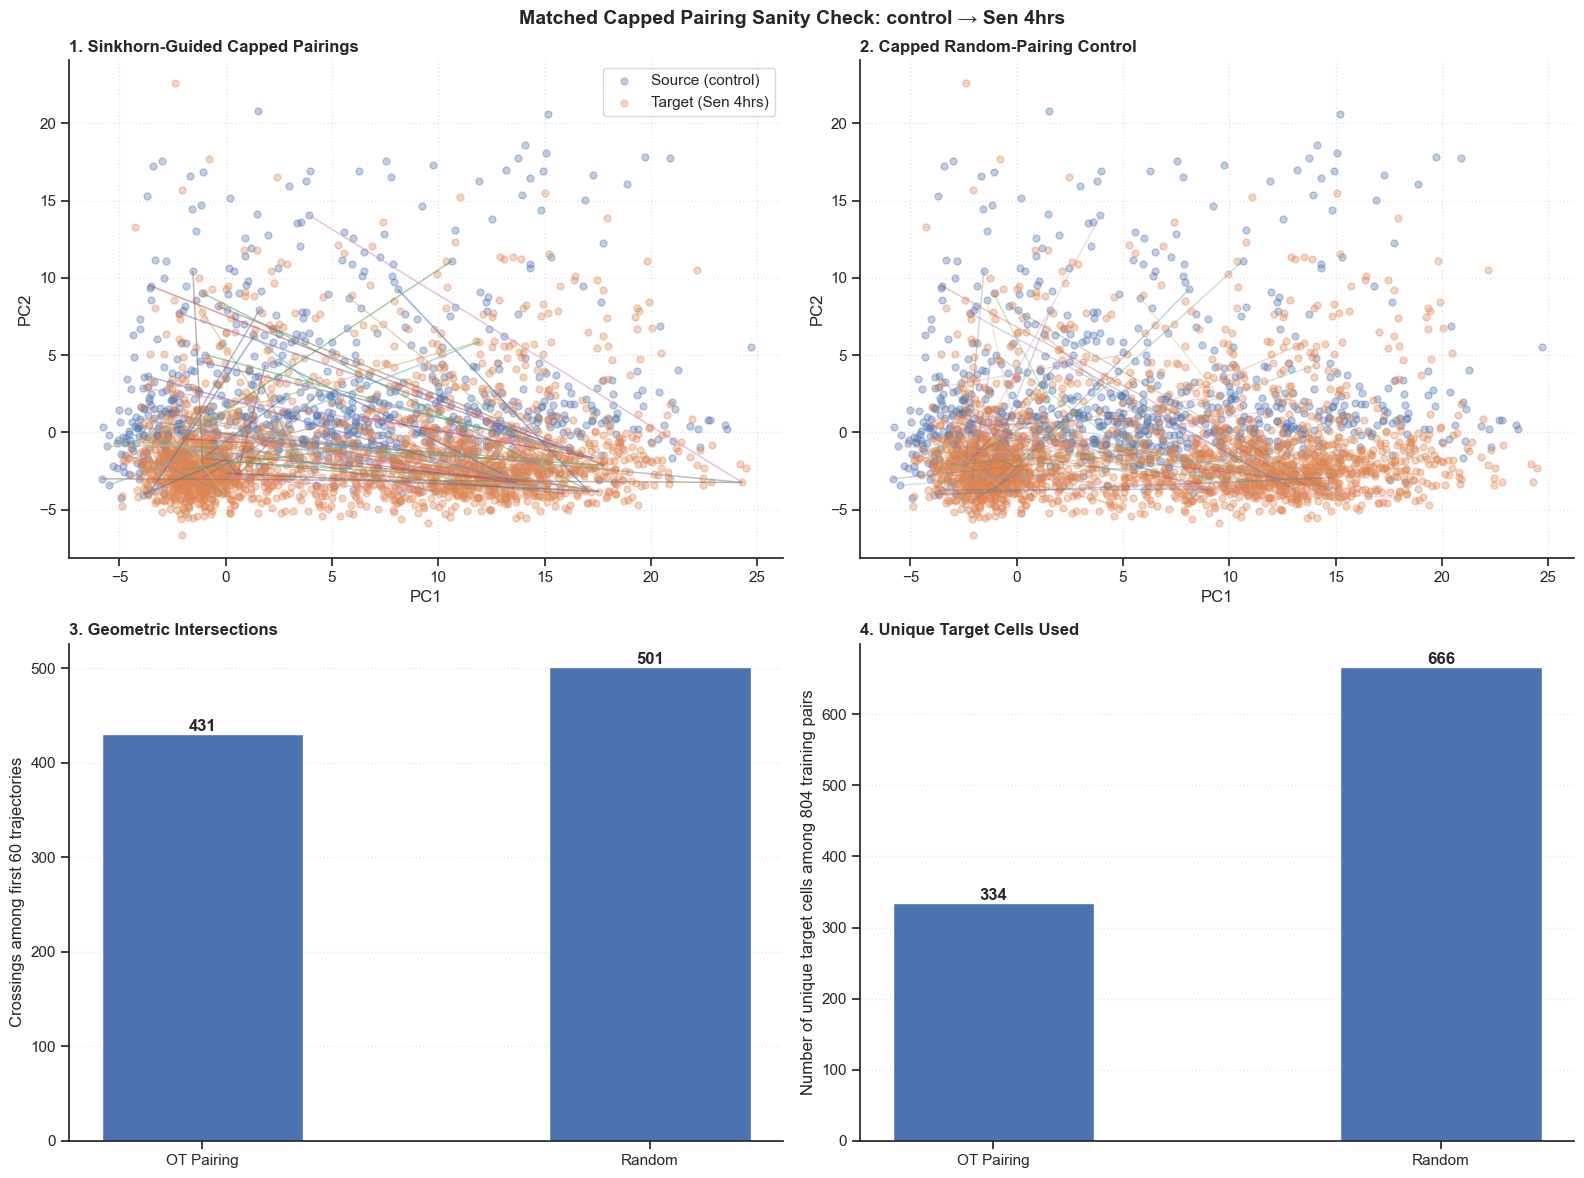


MATCHED CAPPED OT VS RANDOM SANITY REPORT
Transition: control->Sen 4hrs
Common OT PCA dimensions: 750
Training source cells: 804
Target cells: 2233

Pair-count alignment:
OT pair count: 804
Random pair count: 804

Source alignment:
OT and random training source PCs identical: True
OT and random training source IDs identical: True
OT and random target populations identical: True

Sinkhorn marginal convergence:
Source marginal error: 0.0009950248756218905
Target marginal error: 0.0004478280340349306

2D line diagnostic:
OT crossing count: 431
Random crossing count: 501

Target usage among retained 804 training pairs:
OT unique targets used: 334
Random unique targets used: 666
OT maximum target reuse: 3
Random maximum target reuse: 3
OT unused target cells: 1899
Random unused target cells: 1567

Cap checks:
OT original cap: 3
Random original cap: 3
OT retained training-pair max reuse: 3
Random retained training-pair max reuse: 3
OT retained pairings respect cap: True
Random retained pair

In [13]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.clf()
plt.close("all")

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"


# =========================================================
# 1. CHOOSE TRANSITION
# =========================================================

stage_0 = "control"
stage_1 = "Sen 4hrs"
transition_key = f"{stage_0}->{stage_1}"

print(f"-> Checking matched capped OT vs capped random pairing: {transition_key}")

# Full target population in the SAME common PCA space
# used to construct the OT pairing.
target_mask = (adata_processed.obs["sample"] == stage_1).values
L_t1 = np.asarray(
    adata_processed.obsm["X_pca_clean"][target_mask, :ot_pc_count],
    dtype=np.float64
)


# =========================================================
# 2. LOAD EXACT OT PAIRING RETAINED FOR MODEL TRAINING
# =========================================================

ot_info = ot_transition_info[transition_key]

# Same 804 Day-0 training cells used by every model
L_t0_train = np.asarray(
    ot_info["source"][train_source_idx],
    dtype=np.float64
)

# Exact OT targets for those same 804 cells
ot_pair_indices = np.asarray(
    ot_info["paired_target_indices"][train_source_idx],
    dtype=int
)

gamma = np.asarray(ot_info["gamma"], dtype=np.float64)
source_error = ot_info["source_error"]
target_error = ot_info["target_error"]

# Target usage among ONLY the retained 804 training pairs
ot_target_usage = np.bincount(
    ot_pair_indices,
    minlength=len(L_t1)
)


# =========================================================
# 3. LOAD EXACT RANDOM PAIRING RETAINED FOR MODEL TRAINING
# =========================================================

random_info = random_pairing_info[transition_key]

rand_pair_indices = np.asarray(
    random_info["paired_target_indices"][train_source_idx],
    dtype=int
)

# Target usage among ONLY the retained 804 training pairs
rand_target_usage = np.bincount(
    rand_pair_indices,
    minlength=len(L_t1)
)

print("Training source shape:", L_t0_train.shape)
print("Target population shape:", L_t1.shape)
print("OT pair count:", len(ot_pair_indices))
print("Random pair count:", len(rand_pair_indices))

assert len(ot_pair_indices) == len(train_source_idx)
assert len(rand_pair_indices) == len(train_source_idx)
assert len(ot_pair_indices) == 804
assert len(rand_pair_indices) == 804

# Verify diagnostic is using the actual common OT geometry
assert L_t0_train.shape[1] == ot_pc_count
assert L_t1.shape[1] == ot_pc_count
assert ot_pc_count == 750


# =========================================================
# 4. VERIFY SOURCE ALIGNMENT
# =========================================================

random_source_train = np.asarray(
    random_info["source"][train_source_idx],
    dtype=np.float64
)

assert np.allclose(L_t0_train, random_source_train)

ot_train_ids = ot_info["source_obs_names"][train_source_idx]
random_train_ids = random_info["source_obs_names"][train_source_idx]

assert np.array_equal(ot_train_ids, random_train_ids)


# =========================================================
# 5. VERIFY TARGET-POPULATION ALIGNMENT
# =========================================================

random_target_population = np.asarray(
    random_info["target_population"],
    dtype=np.float64
)

assert np.array_equal(
    ot_info["target_obs_names"],
    random_info["target_obs_names"]
)

assert np.allclose(
    L_t1,
    random_target_population
)

print("OT/random target populations identical: True")


# =========================================================
# 6. PC1 / PC2 FOR VISUALIZATION ONLY
# =========================================================

L_t0_pc = L_t0_train[:, :2]
L_t1_pc = L_t1[:, :2]


# =========================================================
# 7. LINE-CROSSING FUNCTIONS
# =========================================================

def ccw(A, B, C):
    return (C[1] - A[1]) * (B[0] - A[0]) > (B[1] - A[1]) * (C[0] - A[0])


def do_lines_intersect(p1, q1, p2, q2):
    return (
        ccw(p1, p2, q2) != ccw(q1, p2, q2)
        and
        ccw(p1, q1, p2) != ccw(p1, q1, q2)
    )


def calculate_total_intersections(src_coords, tgt_coords, matching_indices, max_check=60):
    n_lines = min(len(src_coords), max_check)
    intersections = 0

    for i in range(n_lines):
        p1 = src_coords[i]
        q1 = tgt_coords[matching_indices[i]]

        for j in range(i + 1, n_lines):
            p2 = src_coords[j]
            q2 = tgt_coords[matching_indices[j]]

            if do_lines_intersect(p1, q1, p2, q2):
                intersections += 1

    return intersections


max_sample = 60

ot_crossings = calculate_total_intersections(
    L_t0_pc,
    L_t1_pc,
    ot_pair_indices,
    max_check=max_sample
)

rand_crossings = calculate_total_intersections(
    L_t0_pc,
    L_t1_pc,
    rand_pair_indices,
    max_check=max_sample
)


# =========================================================
# 8. TARGET-USAGE DIAGNOSTICS
# =========================================================

ot_unique_targets = np.sum(ot_target_usage > 0)
rand_unique_targets = np.sum(rand_target_usage > 0)

ot_max_reuse = ot_target_usage.max()
rand_max_reuse = rand_target_usage.max()

ot_unused_targets = np.sum(ot_target_usage == 0)
rand_unused_targets = np.sum(rand_target_usage == 0)


# =========================================================
# 9. FOUR-PANEL DASHBOARD
# =========================================================

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
ax1, ax2, ax3, ax4 = axs.flatten()


# ---------------------------------------------------------
# PANEL 1 — CAPPED OT PAIRINGS
# ---------------------------------------------------------

ax1.scatter(
    L_t0_pc[:, 0],
    L_t0_pc[:, 1],
    alpha=0.35,
    s=25,
    label=f"Source ({stage_0})"
)

ax1.scatter(
    L_t1_pc[:, 0],
    L_t1_pc[:, 1],
    alpha=0.35,
    s=25,
    label=f"Target ({stage_1})"
)

for i in range(min(max_sample, len(L_t0_pc))):
    src = L_t0_pc[i]
    tgt = L_t1_pc[ot_pair_indices[i]]

    ax1.plot(
        [src[0], tgt[0]],
        [src[1], tgt[1]],
        alpha=0.55,
        linewidth=1.1
    )

ax1.set_title(
    "1. Sinkhorn-Guided Capped Pairings",
    loc="left",
    fontweight="bold"
)

ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend()


# ---------------------------------------------------------
# PANEL 2 — CAPPED RANDOM PAIRING
# ---------------------------------------------------------

ax2.scatter(
    L_t0_pc[:, 0],
    L_t0_pc[:, 1],
    alpha=0.35,
    s=25
)

ax2.scatter(
    L_t1_pc[:, 0],
    L_t1_pc[:, 1],
    alpha=0.35,
    s=25
)

for i in range(min(max_sample, len(L_t0_pc))):
    src = L_t0_pc[i]
    tgt = L_t1_pc[rand_pair_indices[i]]

    ax2.plot(
        [src[0], tgt[0]],
        [src[1], tgt[1]],
        alpha=0.35,
        linewidth=1.0
    )

ax2.set_title(
    "2. Capped Random-Pairing Control",
    loc="left",
    fontweight="bold"
)

ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.grid(True, linestyle=":", alpha=0.5)


# ---------------------------------------------------------
# PANEL 3 — GEOMETRIC INTERSECTIONS
# ---------------------------------------------------------

bars_cross = ax3.bar(
    ["OT Pairing", "Random"],
    [ot_crossings, rand_crossings],
    width=0.45
)

ax3.set_title(
    "3. Geometric Intersections",
    loc="left",
    fontweight="bold"
)

ax3.set_ylabel(
    f"Crossings among first {max_sample} trajectories"
)

ax3.grid(axis="y", linestyle=":", alpha=0.5)

for bar, value in zip(
    bars_cross,
    [ot_crossings, rand_crossings]
):
    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        str(value),
        ha="center",
        va="bottom",
        fontweight="bold"
    )


# ---------------------------------------------------------
# PANEL 4 — UNIQUE TARGET CELLS USED
# ---------------------------------------------------------

bars_unique = ax4.bar(
    ["OT Pairing", "Random"],
    [ot_unique_targets, rand_unique_targets],
    width=0.45
)

ax4.set_title(
    "4. Unique Target Cells Used",
    loc="left",
    fontweight="bold"
)

ax4.set_ylabel(
    "Number of unique target cells among 804 training pairs"
)

ax4.grid(axis="y", linestyle=":", alpha=0.5)

for bar, value in zip(
    bars_unique,
    [ot_unique_targets, rand_unique_targets]
):
    ax4.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        str(value),
        ha="center",
        va="bottom",
        fontweight="bold"
    )


# =========================================================
# 10. FINAL FIGURE
# =========================================================

plt.suptitle(
    f"Matched Capped Pairing Sanity Check: {stage_0} → {stage_1}",
    fontweight="bold",
    fontsize=14
)

sns.despine(trim=False)
plt.tight_layout()

plt.savefig(
    "ot_pairing_sanity_check.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# 11. NUMERIC REPORT
# =========================================================

print("\n" + "=" * 75)
print("MATCHED CAPPED OT VS RANDOM SANITY REPORT")
print("=" * 75)

print("Transition:", transition_key)
print("Common OT PCA dimensions:", ot_pc_count)
print("Training source cells:", len(L_t0_train))
print("Target cells:", len(L_t1))

print("\nPair-count alignment:")
print("OT pair count:", len(ot_pair_indices))
print("Random pair count:", len(rand_pair_indices))

print("\nSource alignment:")
print(
    "OT and random training source PCs identical:",
    np.allclose(L_t0_train, random_source_train)
)

print(
    "OT and random training source IDs identical:",
    np.array_equal(ot_train_ids, random_train_ids)
)

print(
    "OT and random target populations identical:",
    np.allclose(L_t1, random_target_population)
)

print("\nSinkhorn marginal convergence:")
print("Source marginal error:", source_error)
print("Target marginal error:", target_error)

print("\n2D line diagnostic:")
print("OT crossing count:", ot_crossings)
print("Random crossing count:", rand_crossings)

print("\nTarget usage among retained 804 training pairs:")
print("OT unique targets used:", ot_unique_targets)
print("Random unique targets used:", rand_unique_targets)

print("OT maximum target reuse:", ot_max_reuse)
print("Random maximum target reuse:", rand_max_reuse)

print("OT unused target cells:", ot_unused_targets)
print("Random unused target cells:", rand_unused_targets)

print("\nCap checks:")
print("OT original cap:", target_cap)
print("Random original cap:", random_target_cap)
print("OT retained training-pair max reuse:", ot_max_reuse)
print("Random retained training-pair max reuse:", rand_max_reuse)

print(
    "OT retained pairings respect cap:",
    ot_max_reuse <= target_cap
)

print(
    "Random retained pairings respect cap:",
    rand_max_reuse <= random_target_cap
)


# =========================================================
# 12. LEAKAGE CHECKS
# =========================================================

print("\nLeakage checks:")

print(
    "Day 7 present in preprocessing/PCA cohort:",
    "Sen D7" in set(adata_processed.obs["sample"].unique())
)

print(
    "Day 7 used in OT:",
    any(
        "D7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "Day 7 used in random pairing:",
    any(
        "D7" in transition
        for transition in random_pairing_info.keys()
    )
)


# =========================================================
# 13. FINAL ASSERTIONS
# =========================================================

assert len(L_t0_train) == 804
assert len(ot_pair_indices) == 804
assert len(rand_pair_indices) == 804

assert L_t0_train.shape == (804, ot_pc_count)
assert L_t1.shape[1] == ot_pc_count
assert ot_pc_count == 750

assert np.allclose(
    L_t0_train,
    random_source_train
)

assert np.array_equal(
    ot_train_ids,
    random_train_ids
)

assert np.array_equal(
    ot_info["target_obs_names"],
    random_info["target_obs_names"]
)

assert np.allclose(
    L_t1,
    random_target_population
)

assert ot_max_reuse <= target_cap
assert rand_max_reuse <= random_target_cap

assert "Sen D7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)


# =========================================================
# 14. FINAL STATUS
# =========================================================

print("\n✔ OT and random pairings were both constructed on all 1005 Day-0 cells before the split")
print("✔ This figure compares the same retained 804 Day-0 training cells")
print("✔ OT and random use the same target population")
print("✔ OT and random use the same target-use cap")
print("✔ OT and random training source PCs are identical")
print("✔ OT and random training source IDs are identical")
print(f"✔ Sinkhorn OT was computed in the full common {ot_pc_count}-PC space")
print("✔ PC1/PC2 are used only for visualization")
print("✔ OT lines show actual capped real-cell pairings retained for training")
print("✔ Random lines show actual capped random pairings retained for training")
print("✔ No barycentric synthetic targets are used")
print("✔ Day 7 remains completely excluded")
print("✔ These plots validate pairing structure, not forecasting performance")

-> Training Ridge Regression: OT vs Capped Random Pairing...
Ridge PCA dimensions: 750
OT training input: (4020, 751)
OT training target: (4020, 750)
Random training input: (4020, 751)
Random training target: (4020, 750)
Held-out test input: (201, 751)
OT latent prediction shape: (201, 750)
Random latent prediction shape: (201, 750)
OT biological prediction shape: (201, 2000)
Random biological prediction shape: (201, 2000)
Saved: ridge_regression_OT_combined_HVGs.png


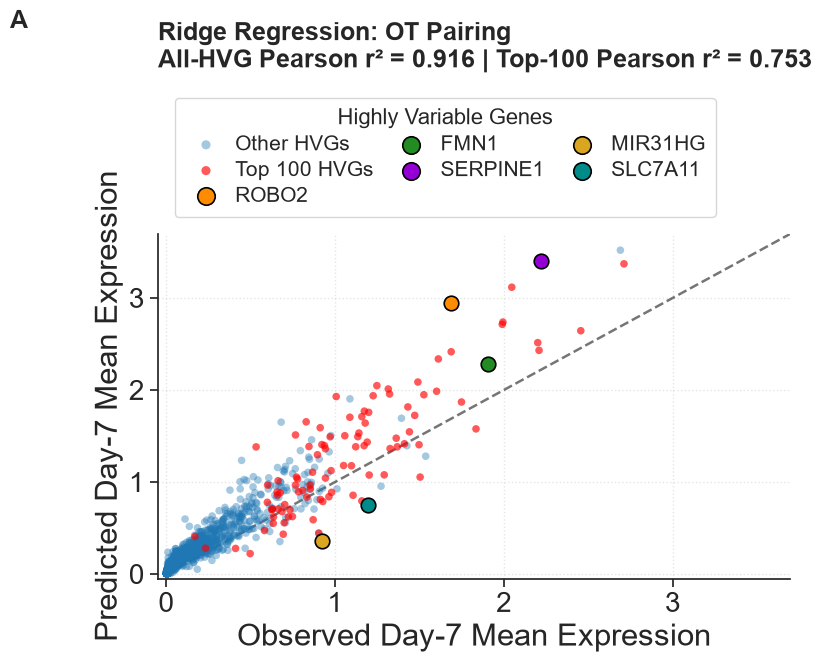

Saved: ridge_regression_random_combined_HVGs.png


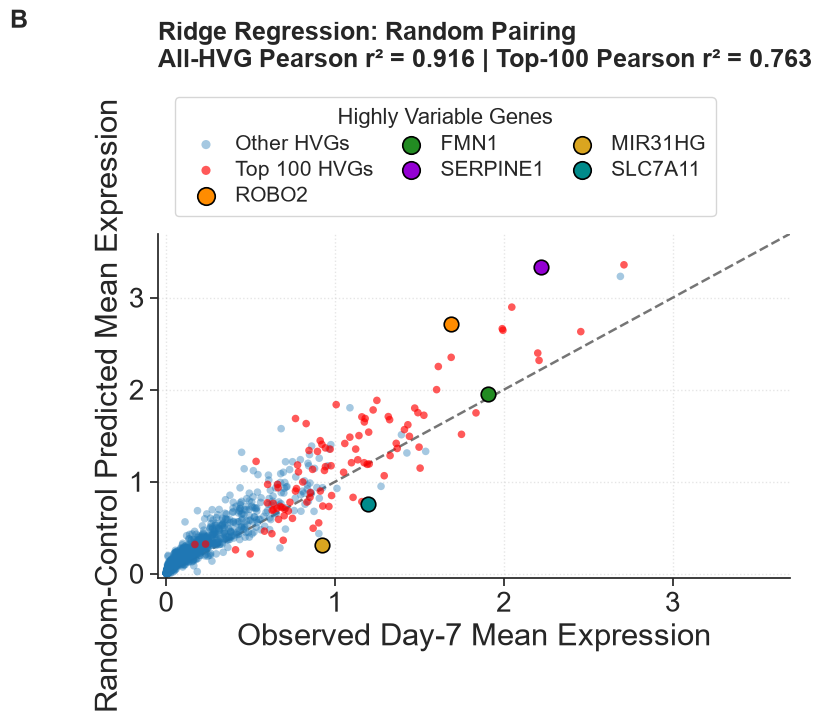


Top-five HVG absolute mean-expression errors — Ridge Regression
Gene                   OT Error     Random Error
ROBO2                  1.252828         1.024246
FMN1                   0.376602         0.049297
SERPINE1               1.187931         1.119008
MIR31HG                0.561653         0.607019
SLC7A11                0.450582         0.437281
Average                0.765919         0.647370

DAY-7 FORECAST REPORT: RIDGE REGRESSION

Primary metric:
Pearson r² — All HVGs | Model: 0.9161
Pearson r² — All HVGs | Random: 0.9159
Pearson r² — Top 100 HVGs | Model: 0.7533
Pearson r² — Top 100 HVGs | Random: 0.7629

Secondary metrics:
Endpoint R² | Model: 0.7689
Endpoint R² | Random: 0.802
Wasserstein-2 | Model: 21.382
Wasserstein-2 | Random: 21.278

Cell-diversity diagnostics:
True Day-7 mean gene variance: 0.1462855725390462
Model mean gene variance: 0.10833053214180176
Random mean gene variance: 0.10844013497719528
True Day-7 mean distance from center: 16.944261081848158
Model 

In [60]:
from sklearn.linear_model import Ridge
import numpy as np

print("-> Training Ridge Regression: OT vs Capped Random Pairing...")

# =========================================================
# 1. LOAD RIDGE-SPECIFIC DATA
# =========================================================

ridge_pc_count = ridge_data["pc_count"]

X_ridge_ot = ridge_data["X_train_ot"]
Y_ridge_ot = ridge_data["Y_train_ot"]

X_ridge_random = ridge_data["X_train_random"]
Y_ridge_random = ridge_data["Y_train_random"]

X_ridge_test = ridge_data["X_test"]
X_ridge_control_test = ridge_data["X_control_test_latent"]

assert ridge_pc_count == 750

print("Ridge PCA dimensions:", ridge_pc_count)
print("OT training input:", X_ridge_ot.shape)
print("OT training target:", Y_ridge_ot.shape)
print("Random training input:", X_ridge_random.shape)
print("Random training target:", Y_ridge_random.shape)
print("Held-out test input:", X_ridge_test.shape)


# =========================================================
# 2. TRAIN OT-PAIRED RIDGE
# =========================================================

ridge_ot = Ridge(alpha=10.0)
ridge_ot.fit(X_ridge_ot, Y_ridge_ot)


# =========================================================
# 3. TRAIN CAPPED RANDOM-PAIRED RIDGE
# =========================================================

ridge_random = Ridge(alpha=10.0)
ridge_random.fit(X_ridge_random, Y_ridge_random)


# =========================================================
# 4. DIRECT HELD-OUT DAY-0 -> DAY-7 PREDICTION
# =========================================================

pred_latent_ridge_ot = ridge_ot.predict(X_ridge_test)
pred_latent_ridge_random = ridge_random.predict(X_ridge_test)

print("OT latent prediction shape:", pred_latent_ridge_ot.shape)
print("Random latent prediction shape:", pred_latent_ridge_random.shape)


# =========================================================
# 5. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# Ridge uses all 750 PCs, so no omitted PCs need to
# contribute during reconstruction.
# =========================================================

pred_genes_ridge_ot = to_true_biological_gene_space(
    pred_latent_ridge_ot,
    ridge_pc_count
)

pred_genes_ridge_random = to_true_biological_gene_space(
    pred_latent_ridge_random,
    ridge_pc_count
)

print("OT biological prediction shape:", pred_genes_ridge_ot.shape)
print("Random biological prediction shape:", pred_genes_ridge_random.shape)


# =========================================================
# 6. FINAL ENDPOINT EVALUATION
#
# Primary:
#   - Pearson r² across all 2000 HVGs
#   - Pearson r² across top 100 HVGs
#
# Secondary:
#   - endpoint R²
#   - Wasserstein-2
#   - cell-diversity diagnostics
# =========================================================

evaluate_endpoint_model(
    pred_genes_ridge_ot,
    pred_genes_ridge_random,
    "Ridge Regression"
)


# =========================================================
# 7. QUICK SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("RIDGE REGRESSION FINAL SUMMARY")
print("=" * 75)

print("Forecast task: held-out Day 0 -> held-out Day 7")
print("Starting held-out Day-0 cells:", len(X_ridge_control_test))
print("PCA dimensions:", ridge_pc_count)
print("Total model input features:", X_ridge_ot.shape[1])
print("Direct forecast dT:", np.unique(X_ridge_test[:, -1]))
print("Ridge alpha:", ridge_ot.alpha)

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_ridge_ot.shape[0])
print("Random training rows:", X_ridge_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(X_ridge_ot, X_ridge_random)
)

print(
    "OT and random target matrices differ:",
    not np.allclose(Y_ridge_ot, Y_ridge_random)
)

print("\nNo-change Day-0 baseline:")
print("Pearson r² — All HVGs:", round(baseline_pearson_r2, 4))
print("Pearson r² — Top 100 HVGs:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))

print("\nLeakage checks:")

print(
    "Held-out Day-0 used for model training:",
    len(
        set(control_test_obs_names).intersection(
            set(control_train_obs_names)
        )
    ) > 0
)

print(
    "Day 7 present in preprocessing/PCA cohort:",
    "Sen D7" in set(adata_processed.obs["sample"].unique())
)

print(
    "Day 7 used for OT:",
    any(
        "D7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "Day 7 used for random pairing:",
    any(
        "D7" in transition
        for transition in random_pairing_info.keys()
    )
)

print("Day 7 used for Top-100 HVG selection:", False)


# =========================================================
# 8. FINAL ASSERTIONS
# =========================================================

assert ridge_pc_count == 750
assert ridge_pc_count == model_pca_dims["Ridge Regression"]

assert X_ridge_ot.shape == (4020, ridge_pc_count + 1)
assert Y_ridge_ot.shape == (4020, ridge_pc_count)

assert X_ridge_random.shape == (4020, ridge_pc_count + 1)
assert Y_ridge_random.shape == (4020, ridge_pc_count)

assert X_ridge_test.shape == (201, ridge_pc_count + 1)
assert X_ridge_control_test.shape == (201, ridge_pc_count)

assert pred_latent_ridge_ot.shape == (201, ridge_pc_count)
assert pred_latent_ridge_random.shape == (201, ridge_pc_count)

assert pred_genes_ridge_ot.shape == (201, 2000)
assert pred_genes_ridge_random.shape == (201, 2000)

assert np.allclose(X_ridge_ot, X_ridge_random)
assert not np.allclose(Y_ridge_ot, Y_ridge_random)

assert np.allclose(X_ridge_test[:, -1], 7.0)

assert np.isfinite(pred_latent_ridge_ot).all()
assert np.isfinite(pred_latent_ridge_random).all()
assert np.isfinite(pred_genes_ridge_ot).all()
assert np.isfinite(pred_genes_ridge_random).all()

assert "Sen D7" not in set(adata_processed.obs["sample"].unique())

assert not any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)

assert len(
    set(control_test_obs_names).intersection(
        set(control_train_obs_names)
    )
) == 0


# =========================================================
# 9. FINAL STATUS
# =========================================================

print("\n✔ Ridge uses its Day-4-selected 750-PC representation")
print("✔ Direct Day-0 -> Day-7 prediction")
print("✔ OT and random use identical Ridge training inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same target-use cap")
print("✔ Same 804 Day-0 training sources used by both Ridge models")
print("✔ Same 201 held-out Day-0 cells used for both predictions")
print("✔ Ridge predictions reconstructed from 750 PCs into 2000-HVG biological space")
print("✔ Top-100 evaluation uses training-only gene variance")
print("✔ No recursive rollout")
print("✔ Day 7 excluded from preprocessing and PCA fitting")
print("✔ Day 7 excluded from PCA-dimension selection")
print("✔ Day 7 excluded from Top-100 HVG selection")
print("✔ Day 7 excluded from OT and random pairing")
print("✔ Day 7 excluded from model training")
print("✔ Day 7 used only for final evaluation")

-> Training Dynamic MLP: OT vs Capped Random Pairing
Selected PCA dimensions: 500
Input width: 501 | Output width: 500
OT training input: (4020, 501)
OT training target: (4020, 500)
Random training input: (4020, 501)
Random training target: (4020, 500)
Held-out test input: (201, 501)

Training OT MLP...
Epoch  20/120 | MSE = 1.320354
Epoch  40/120 | MSE = 1.266328
Epoch  60/120 | MSE = 1.229433
Epoch  80/120 | MSE = 1.200037
Epoch 100/120 | MSE = 1.177101
Epoch 120/120 | MSE = 1.163580

Training capped-random MLP...
Epoch  20/120 | MSE = 1.382064
Epoch  40/120 | MSE = 1.340306
Epoch  60/120 | MSE = 1.313223
Epoch  80/120 | MSE = 1.288575
Epoch 100/120 | MSE = 1.268412
Epoch 120/120 | MSE = 1.254406

Final OT training MSE: 1.163580
Final random training MSE: 1.254406
OT latent prediction shape: (201, 500)
Random latent prediction shape: (201, 500)
OT biological prediction shape: (201, 2000)
Random biological prediction shape: (201, 2000)


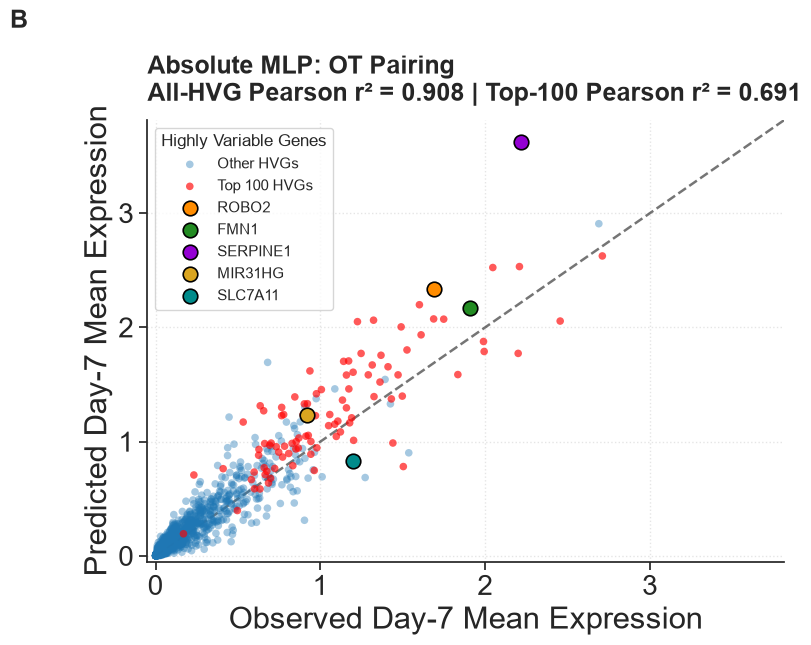

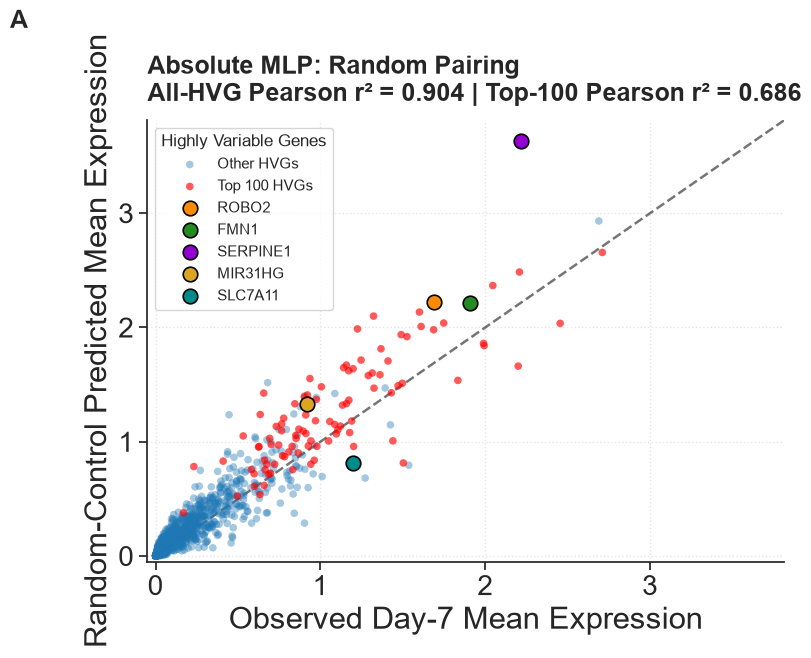


Top-five HVG absolute mean-expression errors — Absolute MLP
Gene                   OT Error     Random Error
ROBO2                  0.650703         0.531139
FMN1                   0.262179         0.313515
SERPINE1               1.409283         1.414130
MIR31HG                0.316439         0.414558
SLC7A11                0.370068         0.378769
Average                0.601734         0.610422

DAY-7 FORECAST REPORT: ABSOLUTE MLP

Primary metric:
Pearson r² — All HVGs | Model: 0.9083
Pearson r² — All HVGs | Random: 0.9038
Pearson r² — Top 100 HVGs | Model: 0.6907
Pearson r² — Top 100 HVGs | Random: 0.686

Secondary metrics:
Endpoint R² | Model: 0.86
Endpoint R² | Random: 0.856
Wasserstein-2 | Model: 17.2254
Wasserstein-2 | Random: 17.2237

Cell-diversity diagnostics:
True Day-7 mean gene variance: 0.1462855725390462
Model mean gene variance: 0.01023259714337888
Random mean gene variance: 0.008245837037812963
True Day-7 mean distance from center: 16.944261081848158
Model mean dis

In [11]:
import torch
import torch.nn as nn
import numpy as np

print("-> Training Dynamic MLP: OT vs Capped Random Pairing")


# =========================================================
# 1. LOAD MLP-SPECIFIC DATA
# =========================================================

mlp_pc_count = mlp_data["pc_count"]

X_mlp_ot = mlp_data["X_train_ot"]
Y_mlp_ot = mlp_data["Y_train_ot"]

X_mlp_random = mlp_data["X_train_random"]
Y_mlp_random = mlp_data["Y_train_random"]

X_mlp_test = mlp_data["X_test"]
X_mlp_control_test = mlp_data["X_control_test_latent"]

latent_pc_dim = mlp_pc_count
input_feature_dim = X_mlp_ot.shape[1]

assert mlp_pc_count == 500
assert input_feature_dim == mlp_pc_count + 1

print(f"Selected PCA dimensions: {mlp_pc_count}")
print(f"Input width: {input_feature_dim} | Output width: {latent_pc_dim}")
print("OT training input:", X_mlp_ot.shape)
print("OT training target:", Y_mlp_ot.shape)
print("Random training input:", X_mlp_random.shape)
print("Random training target:", Y_mlp_random.shape)
print("Held-out test input:", X_mlp_test.shape)


# =========================================================
# 2. MODEL
# =========================================================

class AbsoluteMLP(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.GELU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, out_dim)
        )

    def forward(self, x):
        return self.net(x)


# =========================================================
# 3. TENSORS
# =========================================================

X_tr_mlp_ot = torch.tensor(np.asarray(X_mlp_ot), dtype=torch.float32)
Y_tr_mlp_ot = torch.tensor(np.asarray(Y_mlp_ot), dtype=torch.float32)

X_tr_mlp_random = torch.tensor(np.asarray(X_mlp_random), dtype=torch.float32)
Y_tr_mlp_random = torch.tensor(np.asarray(Y_mlp_random), dtype=torch.float32)

X_te_mlp = torch.tensor(np.asarray(X_mlp_test), dtype=torch.float32)


# =========================================================
# 4. TRAINING FUNCTION
# =========================================================

def train_mlp(X_train, Y_train, seed=42):
    torch.manual_seed(seed)

    model = AbsoluteMLP(input_feature_dim, latent_pc_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

    model.train()
    final_loss = None

    for epoch in range(120):
        optimizer.zero_grad()

        pred = model(X_train)
        loss = nn.functional.mse_loss(pred, Y_train)

        loss.backward()
        optimizer.step()

        final_loss = float(loss.detach().cpu())

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch + 1:3d}/120 | MSE = {final_loss:.6f}")

    return model, final_loss


# =========================================================
# 5. TRAIN OT + RANDOM MODELS
# =========================================================

print("\nTraining OT MLP...")

mlp_ot, final_loss_ot = train_mlp(
    X_tr_mlp_ot,
    Y_tr_mlp_ot,
    seed=42
)

print("\nTraining capped-random MLP...")

mlp_random, final_loss_random = train_mlp(
    X_tr_mlp_random,
    Y_tr_mlp_random,
    seed=42
)

print(f"\nFinal OT training MSE: {final_loss_ot:.6f}")
print(f"Final random training MSE: {final_loss_random:.6f}")


# =========================================================
# 6. DIRECT HELD-OUT DAY-0 -> DAY-7 PREDICTION
# =========================================================

mlp_ot.eval()
mlp_random.eval()

with torch.no_grad():
    pred_latent_mlp_ot = mlp_ot(X_te_mlp).cpu().numpy()
    pred_latent_mlp_random = mlp_random(X_te_mlp).cpu().numpy()

print("OT latent prediction shape:", pred_latent_mlp_ot.shape)
print("Random latent prediction shape:", pred_latent_mlp_random.shape)


# =========================================================
# 7. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# MLP predicts PCs 1-500.
# PCs 501-750 are zero-padded only for inverse PCA.
# =========================================================

pred_genes_mlp_ot = to_true_biological_gene_space(
    pred_latent_mlp_ot,
    mlp_pc_count
)

pred_genes_mlp_random = to_true_biological_gene_space(
    pred_latent_mlp_random,
    mlp_pc_count
)

print("OT biological prediction shape:", pred_genes_mlp_ot.shape)
print("Random biological prediction shape:", pred_genes_mlp_random.shape)


# =========================================================
# 8. FINAL ENDPOINT EVALUATION
# =========================================================

evaluate_endpoint_model(
    pred_genes_mlp_ot,
    pred_genes_mlp_random,
    "Absolute MLP"
)


# =========================================================
# 9. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("ABSOLUTE MLP FINAL SUMMARY")
print("=" * 75)

print("Forecast task: held-out Day 0 -> held-out Day 7")
print("Starting held-out Day-0 cells:", len(X_mlp_control_test))
print("PCA dimensions:", mlp_pc_count)
print("Total model input features:", input_feature_dim)
print("Direct forecast dT:", np.unique(X_mlp_test[:, -1]))
print("Hidden width: 128")
print("Hidden layers: 2")
print("Activation: GELU")
print("Dropout: 0.2")
print("Learning rate: 0.003")
print("Epochs: 120")
print("Seed: 42")

print("\nFinal training MSE:")
print("OT:", round(final_loss_ot, 6))
print("Random:", round(final_loss_random, 6))

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_mlp_ot.shape[0])
print("Random training rows:", X_mlp_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(
        X_mlp_ot,
        X_mlp_random
    )
)

print(
    "OT and random target matrices differ:",
    not np.allclose(
        Y_mlp_ot,
        Y_mlp_random
    )
)

print("\nNo-change Day-0 baseline:")
print("Pearson r² — All HVGs:", round(baseline_pearson_r2, 4))
print("Pearson r² — Top 100 HVGs:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))

print("\nLeakage checks:")

print(
    "Held-out Day-0 used for model training:",
    len(
        set(control_test_obs_names).intersection(
            set(control_train_obs_names)
        )
    ) > 0
)

print(
    "Day 7 present in preprocessing/PCA cohort:",
    "Sen D7" in set(
        adata_processed.obs["sample"].unique()
    )
)

print(
    "Day 7 used for OT:",
    any(
        "D7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "Day 7 used for random pairing:",
    any(
        "D7" in transition
        for transition in random_pairing_info.keys()
    )
)

print("Day 7 used for Top-100 HVG selection:", False)


# =========================================================
# 10. FINAL ASSERTIONS
# =========================================================

assert mlp_pc_count == 500
assert mlp_pc_count == model_pca_dims["Absolute MLP"]

assert X_mlp_ot.shape == (4020, mlp_pc_count + 1)
assert Y_mlp_ot.shape == (4020, mlp_pc_count)

assert X_mlp_random.shape == (4020, mlp_pc_count + 1)
assert Y_mlp_random.shape == (4020, mlp_pc_count)

assert X_mlp_test.shape == (201, mlp_pc_count + 1)
assert X_mlp_control_test.shape == (201, mlp_pc_count)

assert pred_latent_mlp_ot.shape == (201, mlp_pc_count)
assert pred_latent_mlp_random.shape == (201, mlp_pc_count)

assert pred_genes_mlp_ot.shape == (201, 2000)
assert pred_genes_mlp_random.shape == (201, 2000)

assert np.allclose(
    X_mlp_ot,
    X_mlp_random
)

assert not np.allclose(
    Y_mlp_ot,
    Y_mlp_random
)

assert np.allclose(X_mlp_test[:, -1], 7.0)

assert np.isfinite(pred_latent_mlp_ot).all()
assert np.isfinite(pred_latent_mlp_random).all()

assert np.isfinite(pred_genes_mlp_ot).all()
assert np.isfinite(pred_genes_mlp_random).all()

assert "Sen D7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)

assert len(
    set(control_test_obs_names).intersection(
        set(control_train_obs_names)
    )
) == 0


# =========================================================
# 11. FINAL STATUS
# =========================================================

print("\n✔ MLP uses its Day-4-selected 500-PC representation")
print("✔ Direct Day-0 -> Day-7 prediction")
print("✔ OT and random use identical MLP training inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same target-use cap")
print("✔ Same 804 Day-0 training sources used by both MLP models")
print("✔ Same 201 held-out Day-0 cells used for both predictions")
print("✔ MLP predicts 500 PCs")
print("✔ PCs 501-750 are zero only during inverse-PCA reconstruction")
print("✔ MLP predictions reconstructed into 2000-HVG biological space")
print("✔ Top-100 evaluation uses training-only gene variance")
print("✔ No recursive rollout")
print("✔ Day 7 excluded from preprocessing and PCA fitting")
print("✔ Day 7 excluded from PCA-dimension selection")
print("✔ Day 7 excluded from Top-100 HVG selection")
print("✔ Day 7 excluded from OT and random pairing")
print("✔ Day 7 excluded from model training")
print("✔ Day 7 used only for final evaluation")

-> Training XGBoost: OT vs Capped Random Pairing...
Selected PCA dimensions: 10
Total model input features: 11
Predicted PCA dimensions: 10
OT training input: (4020, 11)
OT training target: (4020, 10)
Random training input: (4020, 11)
Random training target: (4020, 10)
Held-out test input: (201, 11)
OT latent prediction shape: (201, 10)
Random latent prediction shape: (201, 10)
OT biological prediction shape: (201, 2000)
Random biological prediction shape: (201, 2000)


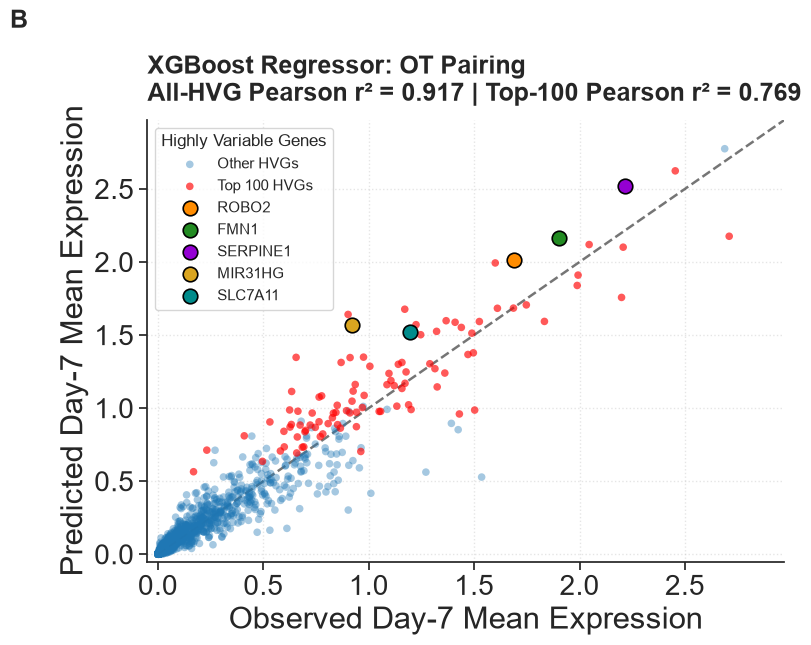

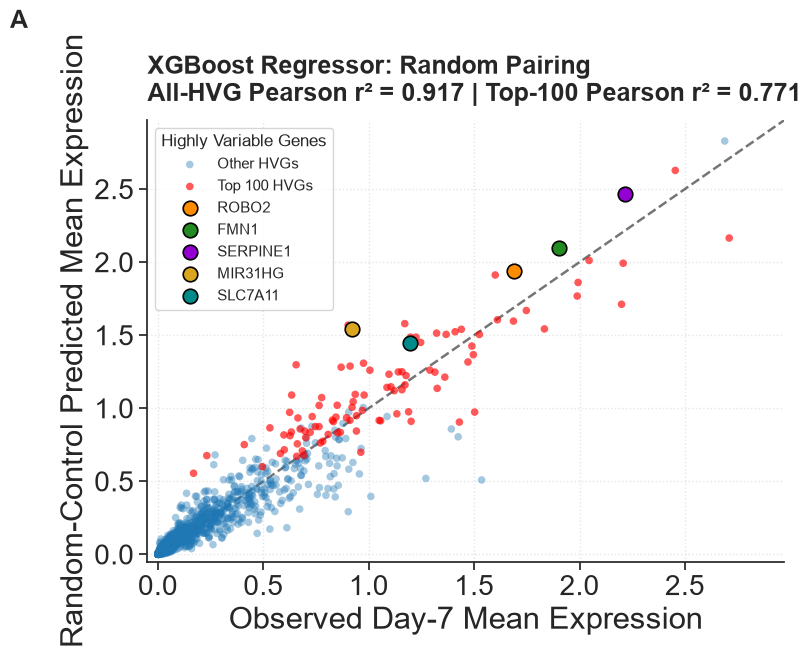


Top-five HVG absolute mean-expression errors — XGBoost Regressor
Gene                   OT Error     Random Error
ROBO2                  0.324890         0.250939
FMN1                   0.256604         0.195349
SERPINE1               0.305696         0.250238
MIR31HG                0.646451         0.623853
SLC7A11                0.325932         0.251169
Average                0.371915         0.314309

DAY-7 FORECAST REPORT: XGBOOST REGRESSOR

Primary metric:
Pearson r² — All HVGs | Model: 0.917
Pearson r² — All HVGs | Random: 0.9173
Pearson r² — Top 100 HVGs | Model: 0.7686
Pearson r² — Top 100 HVGs | Random: 0.7713

Secondary metrics:
Endpoint R² | Model: 0.913
Endpoint R² | Random: 0.9163
Wasserstein-2 | Model: 17.4786
Wasserstein-2 | Random: 17.451

Cell-diversity diagnostics:
True Day-7 mean gene variance: 0.1462855725390462
Model mean gene variance: 7.076085785662675e-05
Random mean gene variance: 8.434764143513504e-05
True Day-7 mean distance from center: 16.944261081848158


In [12]:
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
import numpy as np

print("-> Training XGBoost: OT vs Capped Random Pairing...")


# =========================================================
# 1. LOAD XGBOOST-SPECIFIC DATA
# =========================================================

xgb_pc_count = xgb_data["pc_count"]

X_xgb_ot = xgb_data["X_train_ot"]
Y_xgb_ot = xgb_data["Y_train_ot"]

X_xgb_random = xgb_data["X_train_random"]
Y_xgb_random = xgb_data["Y_train_random"]

X_xgb_test = xgb_data["X_test"]
X_xgb_control_test = xgb_data["X_control_test_latent"]

latent_pc_dim = xgb_pc_count
xgb_output_pcs = xgb_pc_count
input_feature_dim = X_xgb_ot.shape[1]

assert xgb_pc_count == 10
assert input_feature_dim == xgb_pc_count + 1

print("Selected PCA dimensions:", xgb_pc_count)
print("Total model input features:", input_feature_dim)
print("Predicted PCA dimensions:", xgb_output_pcs)
print("OT training input:", X_xgb_ot.shape)
print("OT training target:", Y_xgb_ot.shape)
print("Random training input:", X_xgb_random.shape)
print("Random training target:", Y_xgb_random.shape)
print("Held-out test input:", X_xgb_test.shape)


# =========================================================
# 2. OT-PAIRED XGBOOST
# =========================================================

base_xgb_ot = XGBRegressor(
    n_estimators=30,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=1,
    tree_method="hist"
)

xgb_ot = MultiOutputRegressor(
    base_xgb_ot,
    n_jobs=4
)

xgb_ot.fit(
    X_xgb_ot,
    Y_xgb_ot
)


# =========================================================
# 3. CAPPED RANDOM-PAIRING XGBOOST
# =========================================================

base_xgb_random = XGBRegressor(
    n_estimators=30,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=1,
    tree_method="hist"
)

xgb_random = MultiOutputRegressor(
    base_xgb_random,
    n_jobs=4
)

xgb_random.fit(
    X_xgb_random,
    Y_xgb_random
)


# =========================================================
# 4. DIRECT HELD-OUT DAY-0 -> DAY-7 PREDICTION
# =========================================================

pred_latent_xgb_ot = xgb_ot.predict(X_xgb_test)
pred_latent_xgb_random = xgb_random.predict(X_xgb_test)

print("OT latent prediction shape:", pred_latent_xgb_ot.shape)
print("Random latent prediction shape:", pred_latent_xgb_random.shape)


# =========================================================
# 5. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# XGBoost predicts PCs 1-10.
# PCs 11-750 are zero-padded only for inverse PCA.
# =========================================================

pred_genes_xgb_ot = to_true_biological_gene_space(
    pred_latent_xgb_ot,
    xgb_pc_count
)

pred_genes_xgb_random = to_true_biological_gene_space(
    pred_latent_xgb_random,
    xgb_pc_count
)

print("OT biological prediction shape:", pred_genes_xgb_ot.shape)
print("Random biological prediction shape:", pred_genes_xgb_random.shape)


# =========================================================
# 6. FINAL ENDPOINT EVALUATION
# =========================================================

evaluate_endpoint_model(
    pred_genes_xgb_ot,
    pred_genes_xgb_random,
    "XGBoost Regressor"
)


# =========================================================
# 7. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("XGBOOST FINAL SUMMARY")
print("=" * 75)

print("Forecast task: held-out Day 0 -> held-out Day 7")
print("Starting held-out Day-0 cells:", len(X_xgb_control_test))
print("Input PCA dimensions:", xgb_pc_count)
print("Total model input features:", input_feature_dim)
print("Predicted PCA dimensions:", xgb_output_pcs)
print("Direct forecast dT:", np.unique(X_xgb_test[:, -1]))
print("Estimators:", 30)
print("Max depth:", 3)
print("Learning rate:", 0.05)
print("Subsample:", 0.8)
print("Column subsample:", 0.8)
print("Seed:", 42)

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_xgb_ot.shape[0])
print("Random training rows:", X_xgb_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(
        X_xgb_ot,
        X_xgb_random
    )
)

print(
    "OT and random target matrices differ:",
    not np.allclose(
        Y_xgb_ot,
        Y_xgb_random
    )
)

print("\nNo-change Day-0 baseline:")
print("Pearson r² — All HVGs:", round(baseline_pearson_r2, 4))
print("Pearson r² — Top 100 HVGs:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))

print("\nLeakage checks:")

print(
    "Held-out Day-0 used for model training:",
    len(
        set(control_test_obs_names).intersection(
            set(control_train_obs_names)
        )
    ) > 0
)

print(
    "Day 7 present in preprocessing/PCA cohort:",
    "Sen D7" in set(
        adata_processed.obs["sample"].unique()
    )
)

print(
    "Day 7 used for OT:",
    any(
        "D7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "Day 7 used for random pairing:",
    any(
        "D7" in transition
        for transition in random_pairing_info.keys()
    )
)

print("Day 7 used for Top-100 HVG selection:", False)


# =========================================================
# 8. FINAL ASSERTIONS
# =========================================================

assert xgb_pc_count == 10
assert xgb_pc_count == model_pca_dims["XGBoost Regressor"]

assert X_xgb_ot.shape == (4020, xgb_pc_count + 1)
assert Y_xgb_ot.shape == (4020, xgb_pc_count)

assert X_xgb_random.shape == (4020, xgb_pc_count + 1)
assert Y_xgb_random.shape == (4020, xgb_pc_count)

assert X_xgb_test.shape == (201, xgb_pc_count + 1)
assert X_xgb_control_test.shape == (201, xgb_pc_count)

assert pred_latent_xgb_ot.shape == (201, xgb_pc_count)
assert pred_latent_xgb_random.shape == (201, xgb_pc_count)

assert pred_genes_xgb_ot.shape == (201, 2000)
assert pred_genes_xgb_random.shape == (201, 2000)

assert np.allclose(
    X_xgb_ot,
    X_xgb_random
)

assert not np.allclose(
    Y_xgb_ot,
    Y_xgb_random
)

assert np.allclose(X_xgb_test[:, -1], 7.0)

assert np.isfinite(pred_latent_xgb_ot).all()
assert np.isfinite(pred_latent_xgb_random).all()

assert np.isfinite(pred_genes_xgb_ot).all()
assert np.isfinite(pred_genes_xgb_random).all()

assert "Sen D7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)

assert len(
    set(control_test_obs_names).intersection(
        set(control_train_obs_names)
    )
) == 0


# =========================================================
# 9. FINAL STATUS
# =========================================================

print("\n✔ XGBoost uses its Day-4-selected 10-PC representation")
print("✔ Direct Day-0 -> Day-7 prediction")
print("✔ OT and random use identical XGBoost training inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same target-use cap")
print("✔ Same 804 Day-0 training sources used by both XGBoost models")
print("✔ Same 201 held-out Day-0 cells used for both predictions")
print("✔ XGBoost predicts 10 PCs")
print("✔ PCs 11-750 are zero only during inverse-PCA reconstruction")
print("✔ XGBoost predictions reconstructed into 2000-HVG biological space")
print("✔ Top-100 evaluation uses training-only gene variance")
print("✔ No recursive rollout")
print("✔ Day 7 excluded from preprocessing and PCA fitting")
print("✔ Day 7 excluded from PCA-dimension selection")
print("✔ Day 7 excluded from Top-100 HVG selection")
print("✔ Day 7 excluded from OT and random pairing")
print("✔ Day 7 excluded from model training")
print("✔ Day 7 used only for final evaluation")

-> Training Random Forest: OT vs Capped Random Pairing...
Selected PCA dimensions: 10
Total model input features: 11
Predicted PCA dimensions: 10
OT training input: (4020, 11)
OT training target: (4020, 10)
Random training input: (4020, 11)
Random training target: (4020, 10)
Held-out test input: (201, 11)
OT latent prediction shape: (201, 10)
Random latent prediction shape: (201, 10)
OT biological prediction shape: (201, 2000)
Random biological prediction shape: (201, 2000)
Saved: random_forest_OT_combined_HVGs.png


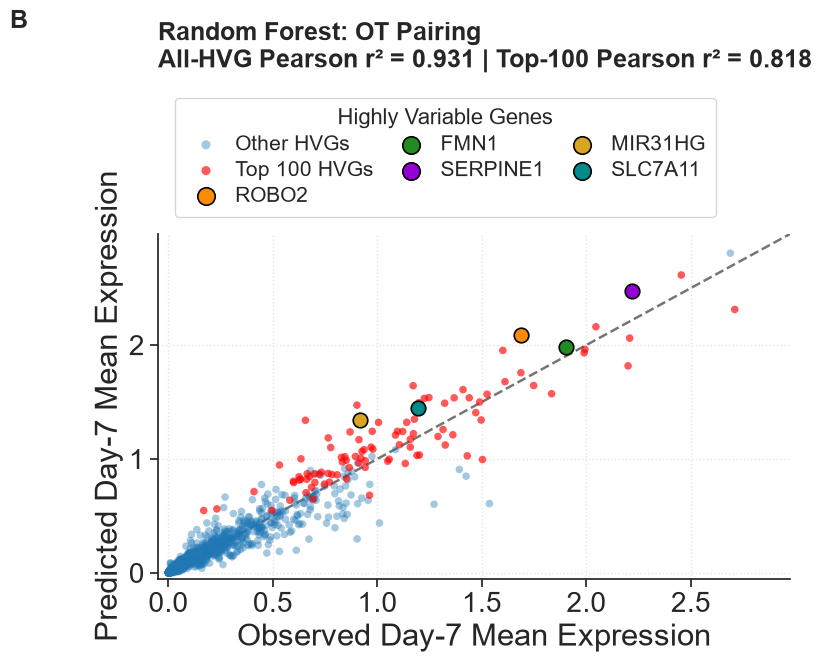

Saved: random_forest_random_combined_HVGs.png


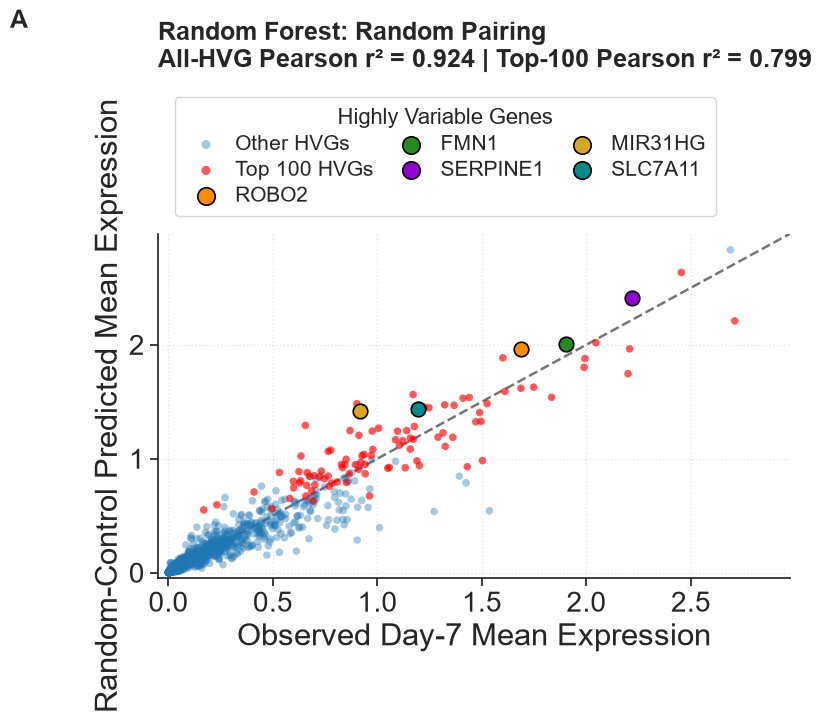


Top-five HVG absolute mean-expression errors — Random Forest
Gene                   OT Error     Random Error
ROBO2                  0.403540         0.272378
FMN1                   0.074170         0.099765
SERPINE1               0.259898         0.193084
MIR31HG                0.420949         0.502664
SLC7A11                0.251907         0.240040
Average                0.282093         0.261586

DAY-7 FORECAST REPORT: RANDOM FOREST

Primary metric:
Pearson r² — All HVGs | Model: 0.9314
Pearson r² — All HVGs | Random: 0.9244
Pearson r² — Top 100 HVGs | Model: 0.8181
Pearson r² — Top 100 HVGs | Random: 0.7989

Secondary metrics:
Endpoint R² | Model: 0.929
Endpoint R² | Random: 0.924
Wasserstein-2 | Model: 17.4412
Wasserstein-2 | Random: 17.4759

Cell-diversity diagnostics:
True Day-7 mean gene variance: 0.1462855725390462
Model mean gene variance: 2.1263498164519872e-05
Random mean gene variance: 1.752196683491029e-05
True Day-7 mean distance from center: 16.944261081848158
Model 

In [62]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np

print("-> Training Random Forest: OT vs Capped Random Pairing...")


# =========================================================
# 1. LOAD RANDOM-FOREST-SPECIFIC DATA
# =========================================================

rf_pc_count = rf_data["pc_count"]

X_rf_ot = rf_data["X_train_ot"]
Y_rf_ot = rf_data["Y_train_ot"]

X_rf_random = rf_data["X_train_random"]
Y_rf_random = rf_data["Y_train_random"]

X_rf_test = rf_data["X_test"]
X_rf_control_test = rf_data["X_control_test_latent"]

latent_pc_dim = rf_pc_count
rf_output_pcs = rf_pc_count
input_feature_dim = X_rf_ot.shape[1]

assert rf_pc_count == 10
assert input_feature_dim == rf_pc_count + 1

print("Selected PCA dimensions:", rf_pc_count)
print("Total model input features:", input_feature_dim)
print("Predicted PCA dimensions:", rf_output_pcs)
print("OT training input:", X_rf_ot.shape)
print("OT training target:", Y_rf_ot.shape)
print("Random training input:", X_rf_random.shape)
print("Random training target:", Y_rf_random.shape)
print("Held-out test input:", X_rf_test.shape)


# =========================================================
# 2. OT-PAIRED RANDOM FOREST
# =========================================================

rf_ot = RandomForestRegressor(
    n_estimators=20,
    max_depth=4,
    max_features=0.5,
    random_state=42,
    n_jobs=2
)

rf_ot.fit(
    X_rf_ot,
    Y_rf_ot
)


# =========================================================
# 3. CAPPED RANDOM-PAIRING RANDOM FOREST
# =========================================================

rf_random = RandomForestRegressor(
    n_estimators=20,
    max_depth=4,
    max_features=0.5,
    random_state=42,
    n_jobs=2
)

rf_random.fit(
    X_rf_random,
    Y_rf_random
)


# =========================================================
# 4. DIRECT HELD-OUT DAY-0 -> DAY-7 PREDICTION
# =========================================================

pred_latent_rf_ot = rf_ot.predict(X_rf_test)
pred_latent_rf_random = rf_random.predict(X_rf_test)

print("OT latent prediction shape:", pred_latent_rf_ot.shape)
print("Random latent prediction shape:", pred_latent_rf_random.shape)


# =========================================================
# 5. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# RF predicts PCs 1-10.
# PCs 11-750 are zero-padded only for inverse PCA.
# =========================================================

pred_genes_rf_ot = to_true_biological_gene_space(
    pred_latent_rf_ot,
    rf_pc_count
)

pred_genes_rf_random = to_true_biological_gene_space(
    pred_latent_rf_random,
    rf_pc_count
)

print("OT biological prediction shape:", pred_genes_rf_ot.shape)
print("Random biological prediction shape:", pred_genes_rf_random.shape)


# =========================================================
# 6. FINAL ENDPOINT EVALUATION
# =========================================================

evaluate_endpoint_model(
    pred_genes_rf_ot,
    pred_genes_rf_random,
    "Random Forest"
)


# =========================================================
# 7. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("RANDOM FOREST FINAL SUMMARY")
print("=" * 75)

print("Forecast task: held-out Day 0 -> held-out Day 7")
print("Starting held-out Day-0 cells:", len(X_rf_control_test))
print("PCA dimensions:", rf_pc_count)
print("Total model input features:", input_feature_dim)
print("Predicted PCA dimensions:", rf_output_pcs)
print("Direct forecast dT:", np.unique(X_rf_test[:, -1]))
print("Trees:", 20)
print("Max depth:", 4)
print("Max features:", 0.5)
print("Seed:", 42)

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_rf_ot.shape[0])
print("Random training rows:", X_rf_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(
        X_rf_ot,
        X_rf_random
    )
)

print(
    "OT and random target matrices differ:",
    not np.allclose(
        Y_rf_ot,
        Y_rf_random
    )
)

print("\nNo-change Day-0 baseline:")
print("Pearson r² — All HVGs:", round(baseline_pearson_r2, 4))
print("Pearson r² — Top 100 HVGs:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))

print("\nLeakage checks:")

print(
    "Held-out Day-0 used for model training:",
    len(
        set(control_test_obs_names).intersection(
            set(control_train_obs_names)
        )
    ) > 0
)

print(
    "Day 7 present in preprocessing/PCA cohort:",
    "Sen D7" in set(
        adata_processed.obs["sample"].unique()
    )
)

print(
    "Day 7 used for OT:",
    any(
        "D7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "Day 7 used for random pairing:",
    any(
        "D7" in transition
        for transition in random_pairing_info.keys()
    )
)

print("Day 7 used for Top-100 HVG selection:", False)


# =========================================================
# 8. FINAL ASSERTIONS
# =========================================================

assert rf_pc_count == 10
assert rf_pc_count == model_pca_dims["Random Forest"]

assert X_rf_ot.shape == (4020, rf_pc_count + 1)
assert Y_rf_ot.shape == (4020, rf_pc_count)

assert X_rf_random.shape == (4020, rf_pc_count + 1)
assert Y_rf_random.shape == (4020, rf_pc_count)

assert X_rf_test.shape == (201, rf_pc_count + 1)
assert X_rf_control_test.shape == (201, rf_pc_count)

assert pred_latent_rf_ot.shape == (201, rf_pc_count)
assert pred_latent_rf_random.shape == (201, rf_pc_count)

assert pred_genes_rf_ot.shape == (201, 2000)
assert pred_genes_rf_random.shape == (201, 2000)

assert np.allclose(
    X_rf_ot,
    X_rf_random
)

assert not np.allclose(
    Y_rf_ot,
    Y_rf_random
)

assert np.allclose(X_rf_test[:, -1], 7.0)

assert np.isfinite(pred_latent_rf_ot).all()
assert np.isfinite(pred_latent_rf_random).all()

assert np.isfinite(pred_genes_rf_ot).all()
assert np.isfinite(pred_genes_rf_random).all()

assert "Sen D7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)

assert len(
    set(control_test_obs_names).intersection(
        set(control_train_obs_names)
    )
) == 0


# =========================================================
# 9. FINAL STATUS
# =========================================================

print("\n✔ Random Forest uses its Day-4-selected 10-PC representation")
print("✔ Direct Day-0 -> Day-7 prediction")
print("✔ OT and random use identical Random Forest training inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same target-use cap")
print("✔ Same 804 Day-0 training sources used by both Random Forest models")
print("✔ Same 201 held-out Day-0 cells used for both predictions")
print("✔ Random Forest predicts 10 PCs")
print("✔ PCs 11-750 are zero only during inverse-PCA reconstruction")
print("✔ Random Forest predictions reconstructed into 2000-HVG biological space")
print("✔ Top-100 evaluation uses training-only gene variance")
print("✔ No recursive rollout")
print("✔ Day 7 excluded from preprocessing and PCA fitting")
print("✔ Day 7 excluded from PCA-dimension selection")
print("✔ Day 7 excluded from Top-100 HVG selection")
print("✔ Day 7 excluded from OT and random pairing")
print("✔ Day 7 excluded from model training")
print("✔ Day 7 used only for final evaluation")

-> Training FAST Neural ODE: OT vs Capped Random Pairing...
Selected PCA dimensions: 250
Total model input features: 251
ODE predicted PCs: 250
OT training input: (4020, 251)
OT training target: (4020, 250)
Random training input: (4020, 251)
Random training target: (4020, 250)
Held-out test input: (201, 251)
Euler steps: 6
Epochs: 60

Training OT Neural ODE...
Epoch 10/60 | MSE = 3.366582
Epoch 20/60 | MSE = 3.041300
Epoch 30/60 | MSE = 2.923720
Epoch 40/60 | MSE = 2.870518
Epoch 50/60 | MSE = 2.830519
Epoch 60/60 | MSE = 2.807744

Training capped-random Neural ODE...
Epoch 10/60 | MSE = 3.410901
Epoch 20/60 | MSE = 3.086921
Epoch 30/60 | MSE = 2.981681
Epoch 40/60 | MSE = 2.925632
Epoch 50/60 | MSE = 2.890153
Epoch 60/60 | MSE = 2.862980
OT latent prediction shape: (201, 250)
Random latent prediction shape: (201, 250)
OT biological prediction shape: (201, 2000)
Random biological prediction shape: (201, 2000)


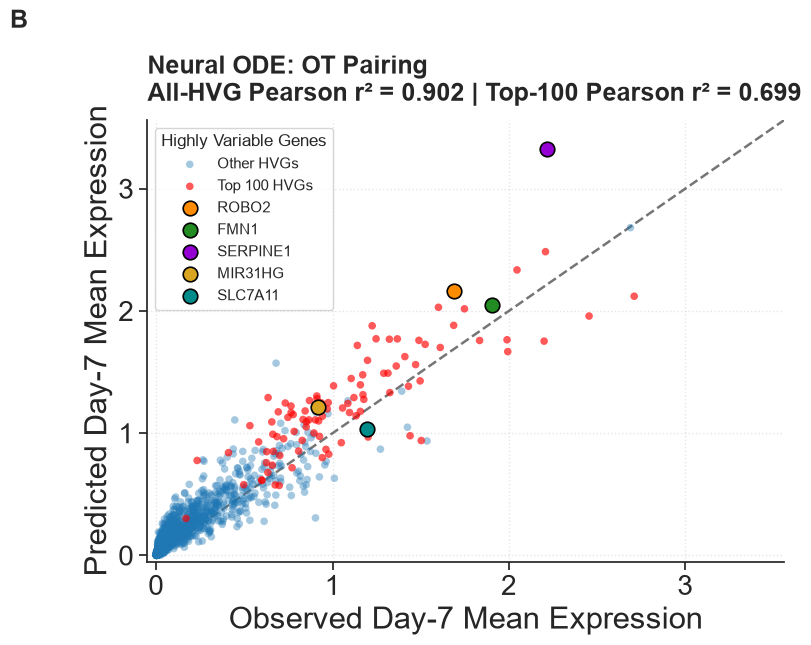

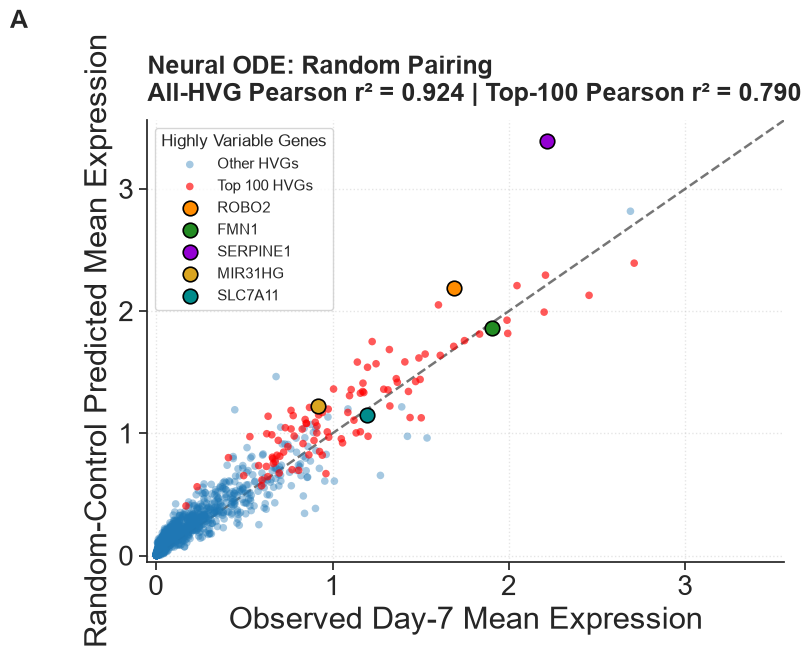


Top-five HVG absolute mean-expression errors — Neural ODE
Gene                   OT Error     Random Error
ROBO2                  0.474079         0.497587
FMN1                   0.142500         0.040974
SERPINE1               1.106776         1.173432
MIR31HG                0.292171         0.302830
SLC7A11                0.157890         0.045432
Average                0.434683         0.412051

DAY-7 FORECAST REPORT: NEURAL ODE

Primary metric:
Pearson r² — All HVGs | Model: 0.9016
Pearson r² — All HVGs | Random: 0.9238
Pearson r² — Top 100 HVGs | Model: 0.6995
Pearson r² — Top 100 HVGs | Random: 0.7905

Secondary metrics:
Endpoint R² | Model: 0.857
Endpoint R² | Random: 0.9017
Wasserstein-2 | Model: 18.3612
Wasserstein-2 | Random: 18.0935

Cell-diversity diagnostics:
True Day-7 mean gene variance: 0.1462855725390462
Model mean gene variance: 0.03563855669725937
Random mean gene variance: 0.03568446791766023
True Day-7 mean distance from center: 16.944261081848158
Model mean dista

In [14]:
import torch
import torch.nn as nn
import numpy as np

print("-> Training FAST Neural ODE: OT vs Capped Random Pairing...")


# =========================================================
# 1. LOAD NEURAL-ODE-SPECIFIC DATA + SETTINGS
# =========================================================

ode_pc_count = ode_data["pc_count"]

X_ode_ot = ode_data["X_train_ot"]
Y_ode_ot = ode_data["Y_train_ot"]

X_ode_random = ode_data["X_train_random"]
Y_ode_random = ode_data["Y_train_random"]

X_ode_test = ode_data["X_test"]
X_ode_control_test = ode_data["X_control_test_latent"]

latent_pc_dim = ode_pc_count
ode_output_pcs = ode_pc_count
input_feature_dim = X_ode_ot.shape[1]

seed = 42
epochs = 60
steps = 6
batch_size = 512
learning_rate = 0.002
weight_decay = 1e-3

assert ode_pc_count == 250
assert input_feature_dim == ode_pc_count + 1

print("Selected PCA dimensions:", ode_pc_count)
print("Total model input features:", input_feature_dim)
print("ODE predicted PCs:", ode_output_pcs)
print("OT training input:", X_ode_ot.shape)
print("OT training target:", Y_ode_ot.shape)
print("Random training input:", X_ode_random.shape)
print("Random training target:", Y_ode_random.shape)
print("Held-out test input:", X_ode_test.shape)
print("Euler steps:", steps)
print("Epochs:", epochs)


# =========================================================
# 2. VELOCITY NETWORK
# =========================================================

class FastVelocityODE(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(ode_output_pcs + 1, 128),
            nn.GELU(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128, ode_output_pcs),
            nn.Tanh()
        )

    def forward(self, z, t_scalar):
        t_batch = torch.full(
            (z.shape[0], 1),
            float(t_scalar),
            dtype=z.dtype,
            device=z.device
        )

        return self.net(
            torch.cat([z, t_batch], dim=1)
        ) * 2.0


# =========================================================
# 3. EULER SOLVER
# =========================================================

def integrate_fast_ode(model, z0, dt_total):
    z = z0
    dt_sub = dt_total / steps

    for step in range(steps):
        t_current = step / steps
        z = z + model(z, t_current) * dt_sub

    return z


# =========================================================
# 4. TRAINING FUNCTION
# =========================================================

def train_fast_ode(X_train, Y_train, seed=42):
    torch.manual_seed(seed)

    model = FastVelocityODE()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    X_np = np.asarray(X_train, dtype=np.float32)
    Y_np = np.asarray(Y_train, dtype=np.float32)

    rng = np.random.default_rng(seed)
    n = len(X_np)
    final_loss = None

    for epoch in range(epochs):
        order = rng.permutation(n)
        epoch_loss = 0.0
        model.train()

        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]

            X_batch = torch.tensor(
                X_np[idx],
                dtype=torch.float32
            )

            Y_batch = torch.tensor(
                Y_np[idx],
                dtype=torch.float32
            )

            z0 = X_batch[:, :ode_output_pcs]
            dt = X_batch[:, latent_pc_dim:latent_pc_dim + 1]

            optimizer.zero_grad()

            z_pred = integrate_fast_ode(
                model,
                z0,
                dt
            )

            loss = nn.functional.mse_loss(
                z_pred,
                Y_batch
            )

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(idx)

        final_loss = epoch_loss / n

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1:2d}/{epochs} | "
                f"MSE = {final_loss:.6f}"
            )

    return model, final_loss


# =========================================================
# 5. TRAIN OT + RANDOM MODELS
# =========================================================

print("\nTraining OT Neural ODE...")

ode_ot, ode_loss_ot = train_fast_ode(
    X_ode_ot,
    Y_ode_ot,
    seed=seed
)

print("\nTraining capped-random Neural ODE...")

ode_random, ode_loss_random = train_fast_ode(
    X_ode_random,
    Y_ode_random,
    seed=seed
)


# =========================================================
# 6. DIRECT HELD-OUT DAY-0 -> DAY-7 PREDICTION
# =========================================================

ode_ot.eval()
ode_random.eval()

X_test_np = np.asarray(
    X_ode_test,
    dtype=np.float32
)

z_test = torch.tensor(
    X_test_np[:, :latent_pc_dim],
    dtype=torch.float32
)

dt_test = torch.tensor(
    X_test_np[:, latent_pc_dim:latent_pc_dim + 1],
    dtype=torch.float32
)

with torch.no_grad():

    pred_latent_ode_ot = integrate_fast_ode(
        ode_ot,
        z_test,
        dt_test
    ).cpu().numpy()

    pred_latent_ode_random = integrate_fast_ode(
        ode_random,
        z_test,
        dt_test
    ).cpu().numpy()

print(
    "OT latent prediction shape:",
    pred_latent_ode_ot.shape
)

print(
    "Random latent prediction shape:",
    pred_latent_ode_random.shape
)


# =========================================================
# 7. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# Neural ODE predicts PCs 1-250.
# PCs 251-750 are zero-padded only for inverse PCA.
# =========================================================

pred_genes_ode_ot = to_true_biological_gene_space(
    pred_latent_ode_ot,
    ode_pc_count
)

pred_genes_ode_random = to_true_biological_gene_space(
    pred_latent_ode_random,
    ode_pc_count
)

print("OT biological prediction shape:", pred_genes_ode_ot.shape)
print("Random biological prediction shape:", pred_genes_ode_random.shape)


# =========================================================
# 8. FINAL ENDPOINT EVALUATION
# =========================================================

evaluate_endpoint_model(
    pred_genes_ode_ot,
    pred_genes_ode_random,
    "Neural ODE"
)


# =========================================================
# 9. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("NEURAL ODE FINAL SUMMARY")
print("=" * 75)

print("Forecast task: held-out Day 0 -> held-out Day 7")
print("Starting held-out Day-0 cells:", len(X_ode_control_test))
print("PCA dimensions:", ode_pc_count)
print("Total model input features:", input_feature_dim)
print("Predicted PCA dimensions:", ode_output_pcs)
print("Direct forecast dT:", np.unique(X_ode_test[:, -1]))
print("Hidden width: 128")
print("Euler steps:", steps)
print("Epochs:", epochs)
print("Batch size:", batch_size)
print("Learning rate:", learning_rate)
print("Weight decay:", weight_decay)
print("Seed:", seed)

print("\nFinal training MSE:")
print("OT:", round(ode_loss_ot, 6))
print("Random:", round(ode_loss_random, 6))

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_ode_ot.shape[0])
print("Random training rows:", X_ode_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(
        X_ode_ot,
        X_ode_random
    )
)

print(
    "OT and random target matrices differ:",
    not np.allclose(
        Y_ode_ot,
        Y_ode_random
    )
)

print("\nNo-change Day-0 baseline:")
print("Pearson r² — All HVGs:", round(baseline_pearson_r2, 4))
print("Pearson r² — Top 100 HVGs:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))

print("\nLeakage checks:")

print(
    "Held-out Day-0 used for model training:",
    len(
        set(control_test_obs_names).intersection(
            set(control_train_obs_names)
        )
    ) > 0
)

print(
    "Day 7 present in preprocessing/PCA cohort:",
    "Sen D7" in set(
        adata_processed.obs["sample"].unique()
    )
)

print(
    "Day 7 used for OT:",
    any(
        "D7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "Day 7 used for random pairing:",
    any(
        "D7" in transition
        for transition in random_pairing_info.keys()
    )
)

print("Day 7 used for Top-100 HVG selection:", False)


# =========================================================
# 10. FINAL ASSERTIONS
# =========================================================

assert ode_pc_count == 250
assert ode_pc_count == model_pca_dims["Neural ODE"]

assert X_ode_ot.shape == (4020, ode_pc_count + 1)
assert Y_ode_ot.shape == (4020, ode_pc_count)

assert X_ode_random.shape == (4020, ode_pc_count + 1)
assert Y_ode_random.shape == (4020, ode_pc_count)

assert X_ode_test.shape == (201, ode_pc_count + 1)
assert X_ode_control_test.shape == (201, ode_pc_count)

assert pred_latent_ode_ot.shape == (201, ode_pc_count)
assert pred_latent_ode_random.shape == (201, ode_pc_count)

assert pred_genes_ode_ot.shape == (201, 2000)
assert pred_genes_ode_random.shape == (201, 2000)

assert np.allclose(
    X_ode_ot,
    X_ode_random
)

assert not np.allclose(
    Y_ode_ot,
    Y_ode_random
)

assert np.allclose(X_ode_test[:, -1], 7.0)

assert np.isfinite(pred_latent_ode_ot).all()
assert np.isfinite(pred_latent_ode_random).all()

assert np.isfinite(pred_genes_ode_ot).all()
assert np.isfinite(pred_genes_ode_random).all()

assert "Sen D7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)

assert len(
    set(control_test_obs_names).intersection(
        set(control_train_obs_names)
    )
) == 0


# =========================================================
# 11. FINAL STATUS
# =========================================================

print("\n✔ Neural ODE uses its Day-4-selected 250-PC representation")
print("✔ Direct Day-0 -> Day-7 prediction")
print("✔ OT and random use identical Neural ODE training inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same target-use cap")
print("✔ Same 804 Day-0 training sources used by both Neural ODE models")
print("✔ Same 201 held-out Day-0 cells used for both predictions")
print("✔ Neural ODE evolves and predicts 250 PCs")
print("✔ PCs 251-750 are zero only during inverse-PCA reconstruction")
print("✔ Neural ODE predictions reconstructed into 2000-HVG biological space")
print("✔ Top-100 evaluation uses training-only gene variance")
print("✔ No recursive rollout")
print("✔ Day 7 excluded from preprocessing and PCA fitting")
print("✔ Day 7 excluded from PCA-dimension selection")
print("✔ Day 7 excluded from Top-100 HVG selection")
print("✔ Day 7 excluded from OT and random pairing")
print("✔ Day 7 excluded from model training")
print("✔ Day 7 used only for final evaluation")

-> Training Temporal-Token Transformer: OT vs Capped Random Pairing...
Selected PCA dimensions: 100
Total model input features: 101
Transformer predicted PCs: 100
OT training input: (4020, 101)
OT training target: (4020, 100)
Random training input: (4020, 101)
Random training target: (4020, 100)
Held-out test input: (201, 101)
State tokens: 20
Token size: 5
Attention width: 32

Training OT Transformer...
Epoch 10/30 | MSE = 2.549617
Epoch 20/30 | MSE = 2.452168
Epoch 30/30 | MSE = 2.405213

Training capped-random Transformer...
Epoch 10/30 | MSE = 2.600690
Epoch 20/30 | MSE = 2.502016
Epoch 30/30 | MSE = 2.454675
OT latent prediction shape: (201, 100)
Random latent prediction shape: (201, 100)
OT biological prediction shape: (201, 2000)
Random biological prediction shape: (201, 2000)


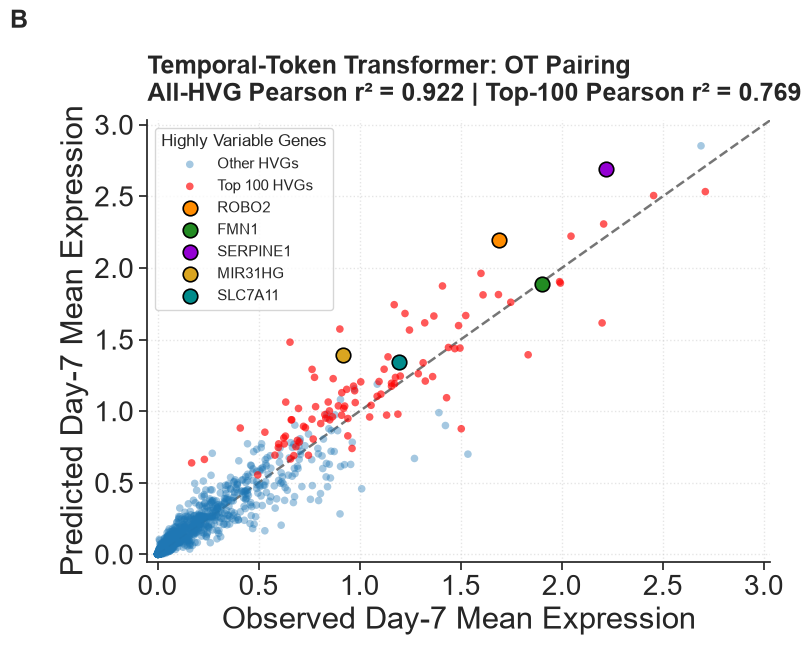

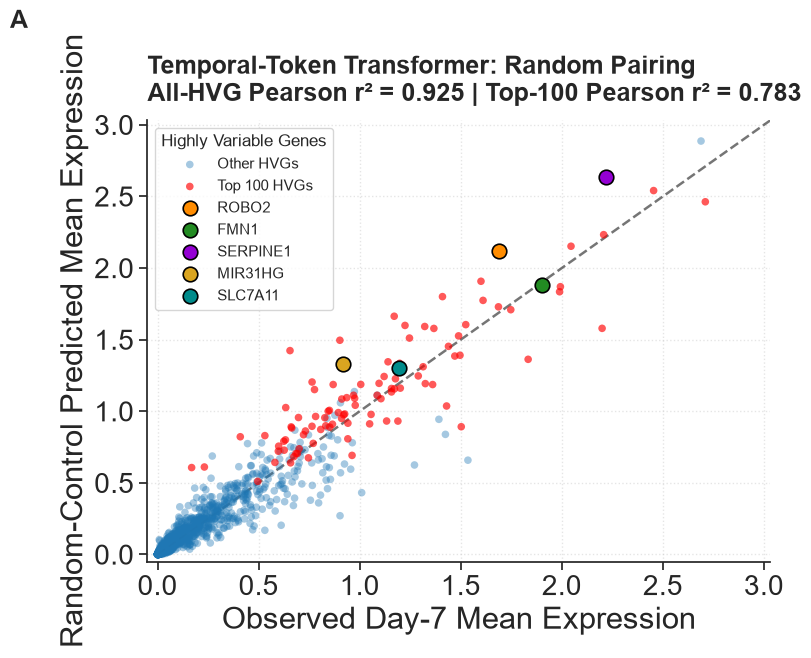


Top-five HVG absolute mean-expression errors — Temporal-Token Transformer
Gene                   OT Error     Random Error
ROBO2                  0.509171         0.428188
FMN1                   0.013666         0.023899
SERPINE1               0.476170         0.417223
MIR31HG                0.472570         0.409695
SLC7A11                0.148051         0.108991
Average                0.323925         0.277599

DAY-7 FORECAST REPORT: TEMPORAL-TOKEN TRANSFORMER

Primary metric:
Pearson r² — All HVGs | Model: 0.9225
Pearson r² — All HVGs | Random: 0.9247
Pearson r² — Top 100 HVGs | Model: 0.7685
Pearson r² — Top 100 HVGs | Random: 0.7835

Secondary metrics:
Endpoint R² | Model: 0.9147
Endpoint R² | Random: 0.9222
Wasserstein-2 | Model: 17.5389
Wasserstein-2 | Random: 17.5004

Cell-diversity diagnostics:
True Day-7 mean gene variance: 0.1462855725390462
Model mean gene variance: 2.6765874677869937e-05
Random mean gene variance: 3.8287001981876775e-05
True Day-7 mean distance from cent

In [15]:
import torch
import torch.nn as nn
import numpy as np

print("-> Training Temporal-Token Transformer: OT vs Capped Random Pairing...")


# =========================================================
# 1. LOAD TRANSFORMER-SPECIFIC DATA + SETTINGS
# =========================================================

trans_pc_count = transformer_data["pc_count"]

X_trans_ot = transformer_data["X_train_ot"]
Y_trans_ot = transformer_data["Y_train_ot"]

X_trans_random = transformer_data["X_train_random"]
Y_trans_random = transformer_data["Y_train_random"]

X_trans_test = transformer_data["X_test"]
X_trans_control_test = transformer_data["X_control_test_latent"]

latent_pc_dim = trans_pc_count
trans_output_pcs = trans_pc_count
input_feature_dim = X_trans_ot.shape[1]

token_size = 5
num_state_tokens = trans_output_pcs // token_size

d_model = 32
nhead = 4
num_layers = 1
epochs = 30
batch_size = 512
learning_rate = 0.002
seed = 42

assert trans_pc_count == 100
assert input_feature_dim == trans_pc_count + 1
assert trans_output_pcs % token_size == 0

print("Selected PCA dimensions:", trans_pc_count)
print("Total model input features:", input_feature_dim)
print("Transformer predicted PCs:", trans_output_pcs)
print("OT training input:", X_trans_ot.shape)
print("OT training target:", Y_trans_ot.shape)
print("Random training input:", X_trans_random.shape)
print("Random training target:", Y_trans_random.shape)
print("Held-out test input:", X_trans_test.shape)
print("State tokens:", num_state_tokens)
print("Token size:", token_size)
print("Attention width:", d_model)


# =========================================================
# 2. TEMPORAL-TOKEN TRANSFORMER
# =========================================================

class TemporalTokenTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.state_projection = nn.Linear(
            token_size,
            d_model
        )

        self.time_projection = nn.Linear(
            1,
            d_model
        )

        self.position_embedding = nn.Parameter(
            torch.zeros(
                1,
                num_state_tokens + 1,
                d_model
            )
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=128,
            dropout=0.1,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.output_projection = nn.Linear(
            d_model,
            token_size
        )

    def forward(self, x):
        pcs = x[:, :trans_output_pcs]
        dt = x[:, latent_pc_dim:latent_pc_dim + 1]

        state_tokens = pcs.reshape(
            pcs.shape[0],
            num_state_tokens,
            token_size
        )

        state_tokens = self.state_projection(
            state_tokens
        )

        time_token = self.time_projection(
            dt
        ).unsqueeze(1)

        tokens = torch.cat(
            [time_token, state_tokens],
            dim=1
        )

        tokens = tokens + self.position_embedding

        encoded = self.transformer(tokens)
        encoded_states = encoded[:, 1:, :]

        predicted_tokens = self.output_projection(
            encoded_states
        )

        return predicted_tokens.reshape(
            predicted_tokens.shape[0],
            trans_output_pcs
        )


# =========================================================
# 3. MINI-BATCH TRAINING
# =========================================================

def train_transformer(X_train, Y_train, seed=42):
    torch.manual_seed(seed)

    model = TemporalTokenTransformer()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-5
    )

    X_np = np.asarray(X_train, dtype=np.float32)
    Y_np = np.asarray(Y_train, dtype=np.float32)

    rng = np.random.default_rng(seed)
    n = len(X_np)
    final_loss = None

    for epoch in range(epochs):
        model.train()

        order = rng.permutation(n)
        epoch_loss = 0.0

        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]

            X_batch = torch.tensor(
                X_np[idx],
                dtype=torch.float32
            )

            Y_batch = torch.tensor(
                Y_np[idx],
                dtype=torch.float32
            )

            optimizer.zero_grad()

            prediction = model(
                X_batch
            )

            loss = nn.functional.mse_loss(
                prediction,
                Y_batch
            )

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(idx)

        final_loss = epoch_loss / n

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1:2d}/{epochs} | "
                f"MSE = {final_loss:.6f}"
            )

    return model, final_loss


# =========================================================
# 4. TRAIN OT TRANSFORMER
# =========================================================

print("\nTraining OT Transformer...")

transformer_ot, transformer_loss_ot = train_transformer(
    X_trans_ot,
    Y_trans_ot,
    seed=seed
)


# =========================================================
# 5. TRAIN CAPPED-RANDOM TRANSFORMER
# =========================================================

print("\nTraining capped-random Transformer...")

transformer_random, transformer_loss_random = train_transformer(
    X_trans_random,
    Y_trans_random,
    seed=seed
)


# =========================================================
# 6. DIRECT HELD-OUT DAY-0 -> DAY-7 PREDICTION
# =========================================================

transformer_ot.eval()
transformer_random.eval()

X_test_trans = torch.tensor(
    np.asarray(
        X_trans_test,
        dtype=np.float32
    ),
    dtype=torch.float32
)

with torch.no_grad():

    pred_latent_trans_ot = transformer_ot(
        X_test_trans
    ).cpu().numpy()

    pred_latent_trans_random = transformer_random(
        X_test_trans
    ).cpu().numpy()

print(
    "OT latent prediction shape:",
    pred_latent_trans_ot.shape
)

print(
    "Random latent prediction shape:",
    pred_latent_trans_random.shape
)


# =========================================================
# 7. INVERSE PCA + INVERSE Z-STANDARDIZATION
#
# Transformer predicts PCs 1-100.
# PCs 101-750 are zero-padded only for inverse PCA.
# =========================================================

pred_genes_trans_ot = to_true_biological_gene_space(
    pred_latent_trans_ot,
    trans_pc_count
)

pred_genes_trans_random = to_true_biological_gene_space(
    pred_latent_trans_random,
    trans_pc_count
)

print("OT biological prediction shape:", pred_genes_trans_ot.shape)
print("Random biological prediction shape:", pred_genes_trans_random.shape)


# =========================================================
# 8. FINAL ENDPOINT EVALUATION
# =========================================================

evaluate_endpoint_model(
    pred_genes_trans_ot,
    pred_genes_trans_random,
    "Temporal-Token Transformer"
)


# =========================================================
# 9. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("TEMPORAL-TOKEN TRANSFORMER FINAL SUMMARY")
print("=" * 75)

print("Forecast task: held-out Day 0 -> held-out Day 7")
print("Starting held-out Day-0 cells:", len(X_trans_control_test))
print("PCA dimensions:", trans_pc_count)
print("Total model input features:", input_feature_dim)
print("Predicted PCA dimensions:", trans_output_pcs)
print("Direct forecast dT:", np.unique(X_trans_test[:, -1]))
print("State tokens:", num_state_tokens)
print("Token size:", token_size)
print("Attention heads:", nhead)
print("Transformer layers:", num_layers)
print("d_model:", d_model)
print("Epochs:", epochs)
print("Batch size:", batch_size)
print("Learning rate:", learning_rate)
print("Seed:", seed)

print("\nFinal training MSE:")
print("OT:", round(transformer_loss_ot, 6))
print("Random:", round(transformer_loss_random, 6))

print("\nPairing setup:")
print("OT target-use cap:", target_cap)
print("Random target-use cap:", random_target_cap)
print("OT training rows:", X_trans_ot.shape[0])
print("Random training rows:", X_trans_random.shape[0])

print(
    "OT and random training inputs identical:",
    np.allclose(
        X_trans_ot,
        X_trans_random
    )
)

print(
    "OT and random target matrices differ:",
    not np.allclose(
        Y_trans_ot,
        Y_trans_random
    )
)

print("\nNo-change Day-0 baseline:")
print("Pearson r² — All HVGs:", round(baseline_pearson_r2, 4))
print("Pearson r² — Top 100 HVGs:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))

print("\nLeakage checks:")

print(
    "Held-out Day-0 used for model training:",
    len(
        set(control_test_obs_names).intersection(
            set(control_train_obs_names)
        )
    ) > 0
)

print(
    "Day 7 present in preprocessing/PCA cohort:",
    "Sen D7" in set(
        adata_processed.obs["sample"].unique()
    )
)

print(
    "Day 7 used for OT:",
    any(
        "D7" in transition
        for transition in ot_transition_info.keys()
    )
)

print(
    "Day 7 used for random pairing:",
    any(
        "D7" in transition
        for transition in random_pairing_info.keys()
    )
)

print("Day 7 used for Top-100 HVG selection:", False)


# =========================================================
# 10. FINAL ASSERTIONS
# =========================================================

assert trans_pc_count == 100
assert trans_pc_count == model_pca_dims["Temporal-Token Transformer"]

assert trans_output_pcs % token_size == 0
assert num_state_tokens == 20

assert X_trans_ot.shape == (4020, trans_pc_count + 1)
assert Y_trans_ot.shape == (4020, trans_pc_count)

assert X_trans_random.shape == (4020, trans_pc_count + 1)
assert Y_trans_random.shape == (4020, trans_pc_count)

assert X_trans_test.shape == (201, trans_pc_count + 1)
assert X_trans_control_test.shape == (201, trans_pc_count)

assert pred_latent_trans_ot.shape == (201, trans_pc_count)
assert pred_latent_trans_random.shape == (201, trans_pc_count)

assert pred_genes_trans_ot.shape == (201, 2000)
assert pred_genes_trans_random.shape == (201, 2000)

assert np.allclose(
    X_trans_ot,
    X_trans_random
)

assert not np.allclose(
    Y_trans_ot,
    Y_trans_random
)

assert np.allclose(X_trans_test[:, -1], 7.0)

assert np.isfinite(pred_latent_trans_ot).all()
assert np.isfinite(pred_latent_trans_random).all()

assert np.isfinite(pred_genes_trans_ot).all()
assert np.isfinite(pred_genes_trans_random).all()

assert "Sen D7" not in set(
    adata_processed.obs["sample"].unique()
)

assert not any(
    "D7" in transition
    for transition in ot_transition_info.keys()
)

assert not any(
    "D7" in transition
    for transition in random_pairing_info.keys()
)

assert len(
    set(control_test_obs_names).intersection(
        set(control_train_obs_names)
    )
) == 0


# =========================================================
# 11. FINAL STATUS
# =========================================================

print("\n✔ Transformer uses its Day-4-selected 100-PC representation")
print("✔ Direct Day-0 -> Day-7 prediction")
print("✔ OT and random use identical Transformer training inputs")
print("✔ OT and random differ only in target-pairing strategy")
print("✔ OT and random use the same target-use cap")
print("✔ Same 804 Day-0 training sources used by both Transformer models")
print("✔ Same 201 held-out Day-0 cells used for both predictions")
print("✔ Transformer predicts 100 PCs as 20 five-PC state tokens")
print("✔ PCs 101-750 are zero only during inverse-PCA reconstruction")
print("✔ Transformer predictions reconstructed into 2000-HVG biological space")
print("✔ Top-100 evaluation uses training-only gene variance")
print("✔ No recursive rollout")
print("✔ Day 7 excluded from preprocessing and PCA fitting")
print("✔ Day 7 excluded from PCA-dimension selection")
print("✔ Day 7 excluded from Top-100 HVG selection")
print("✔ Day 7 excluded from OT and random pairing")
print("✔ Day 7 excluded from model training")
print("✔ Day 7 used only for final evaluation")

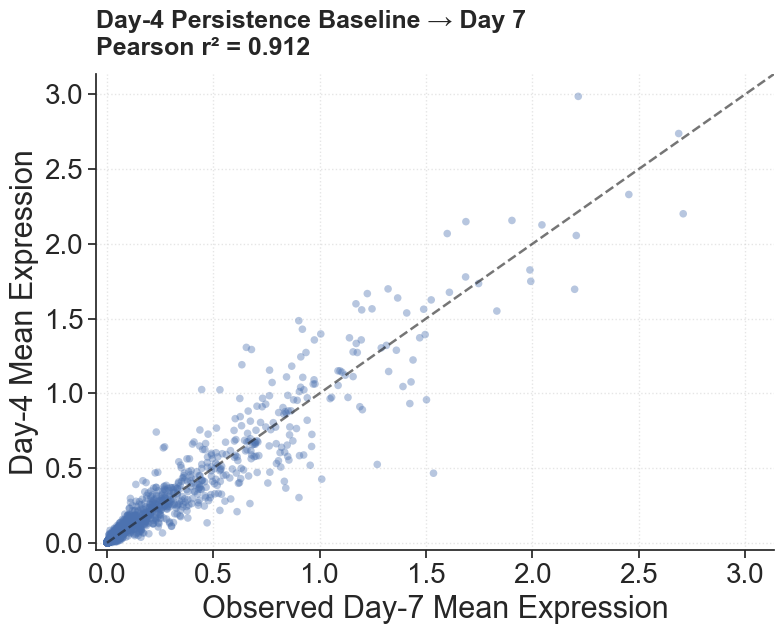

DAY-4 -> DAY-7 PERSISTENCE BASELINE
Pearson r²: 0.9124
Endpoint R²: 0.9081
Genes compared: 2000
Saved: day4_to_day7_persistence_baseline.png


In [66]:
# =========================================================
# DAY-4 -> DAY-7 PERSISTENCE BASELINE
# =========================================================

day4_profile = np.mean(X_d4_bio, axis=0)
day7_profile = np.mean(Y_test_true_biological, axis=0)

day4_day7_pearson_r2 = pearson_r2(day7_profile, day4_profile)
day4_day7_endpoint_r2 = r2_score(day7_profile, day4_profile)

plot_max = max(np.max(day4_profile), np.max(day7_profile)) * 1.05

# =========================================================
# GRAPH
# =========================================================

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(day7_profile, day4_profile, alpha=0.4, s=30, edgecolor="none")

ax.plot([0, plot_max], [0, plot_max], "k--", alpha=0.6, linewidth=1.8)

ax.set_xlim(-0.05, plot_max)
ax.set_ylim(-0.05, plot_max)

ax.set_xlabel("Observed Day-7 Mean Expression", fontsize=22)
ax.set_ylabel("Day-4 Mean Expression", fontsize=22)

ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_title(
    f"Day-4 Persistence Baseline → Day 7\nPearson r² = {day4_day7_pearson_r2:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(True, linestyle=":", alpha=0.5)

sns.despine()
plt.tight_layout()

plt.savefig("day4_to_day7_persistence_baseline.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# RESULTS
# =========================================================

print("=" * 70)
print("DAY-4 -> DAY-7 PERSISTENCE BASELINE")
print("=" * 70)
print("Pearson r²:", round(day4_day7_pearson_r2, 4))
print("Endpoint R²:", round(day4_day7_endpoint_r2, 4))
print("Genes compared:", len(day7_profile))
print("Saved: day4_to_day7_persistence_baseline.png")

--- Final Direct Day-0 -> Day-7 Model Benchmark ---
Model-specific PCA dimensions verified:
Ridge Regression            : 750 PCs
Absolute MLP                : 500 PCs
XGBoost Regressor           : 10 PCs
Random Forest               : 10 PCs
Neural ODE                  : 250 PCs
Temporal-Token Transformer  : 100 PCs
Within-model OT/random input matching verified.
Day-7 leakage checks passed.
All final model-specific prediction shapes verified.
True Day-7 mean gene variance: 0.1462855725390462
True Day-7 mean distance from center: 16.944261081848158

--- Day-0 Persistence Baselines ---
All-HVG Pearson r²: 0.6049
Top-100 HVG Pearson r²: 0.2723
Endpoint R²: 0.5971
Wasserstein-2: 27.2734

DIRECT HELD-OUT DAY-0 -> DAY-7 FORECASTING LEADERBOARD
                     Model  PCA_Dim  OT_Pearson_All  Random_Pearson_All  OT_Pearson_Top100  Random_Pearson_Top100  OT_Endpoint_R2  Random_Endpoint_R2   OT_W2  Random_W2  OT_Gene_Variance  Random_Gene_Variance  OT_Distance_From_Center  Random_Distance_

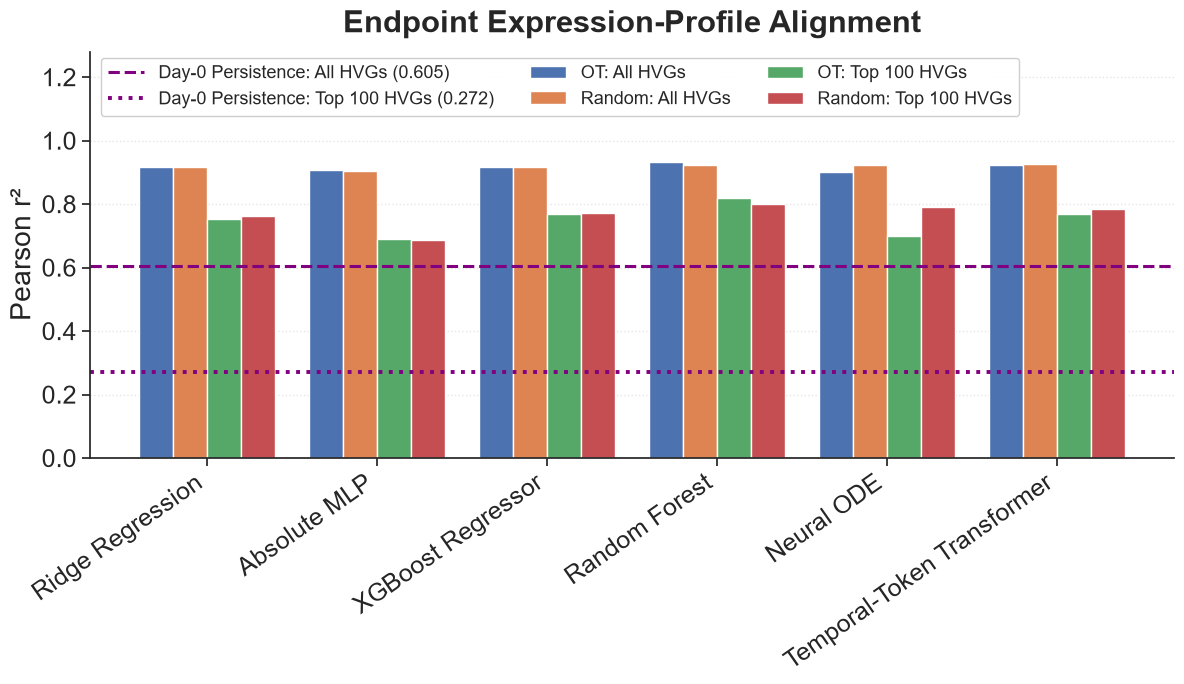

Saved: publication_model_benchmark_endpoint_r2.png


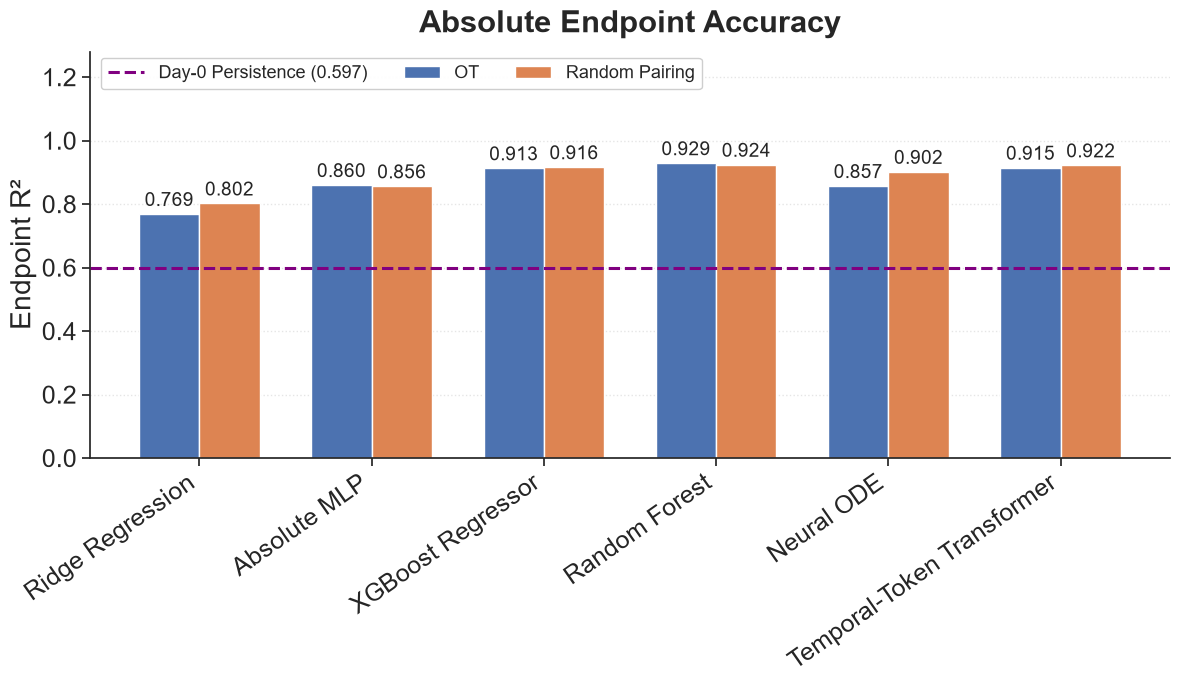

Saved: publication_model_benchmark_w2.png


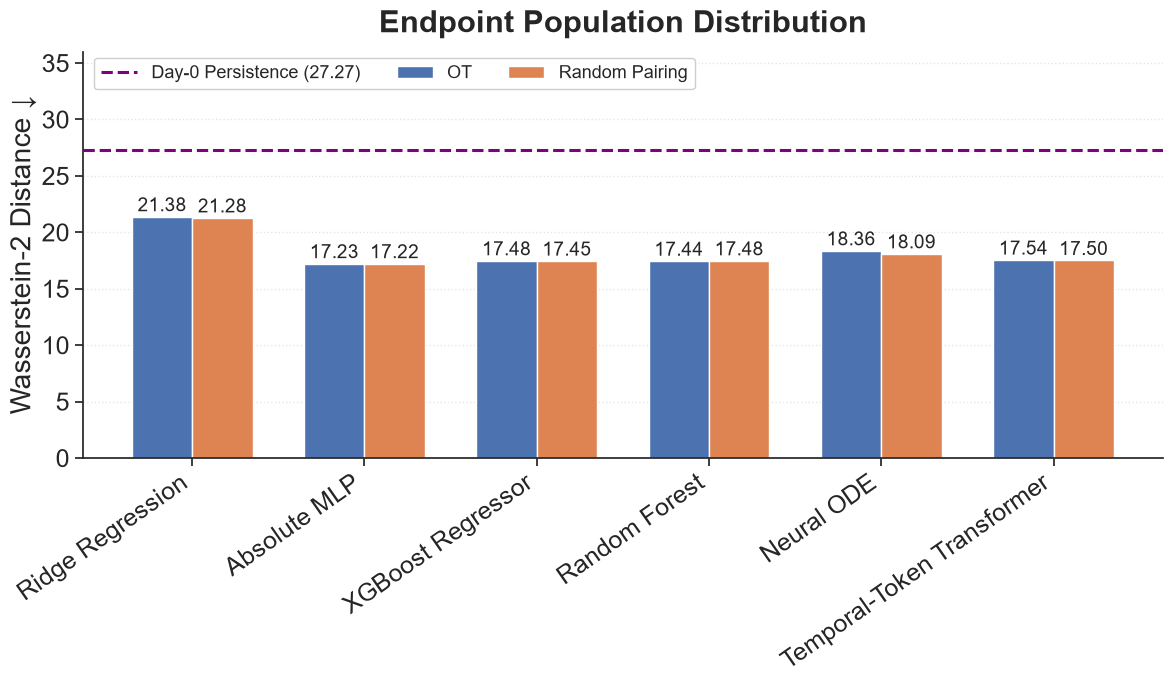

Saved: publication_model_benchmark_diversity.png


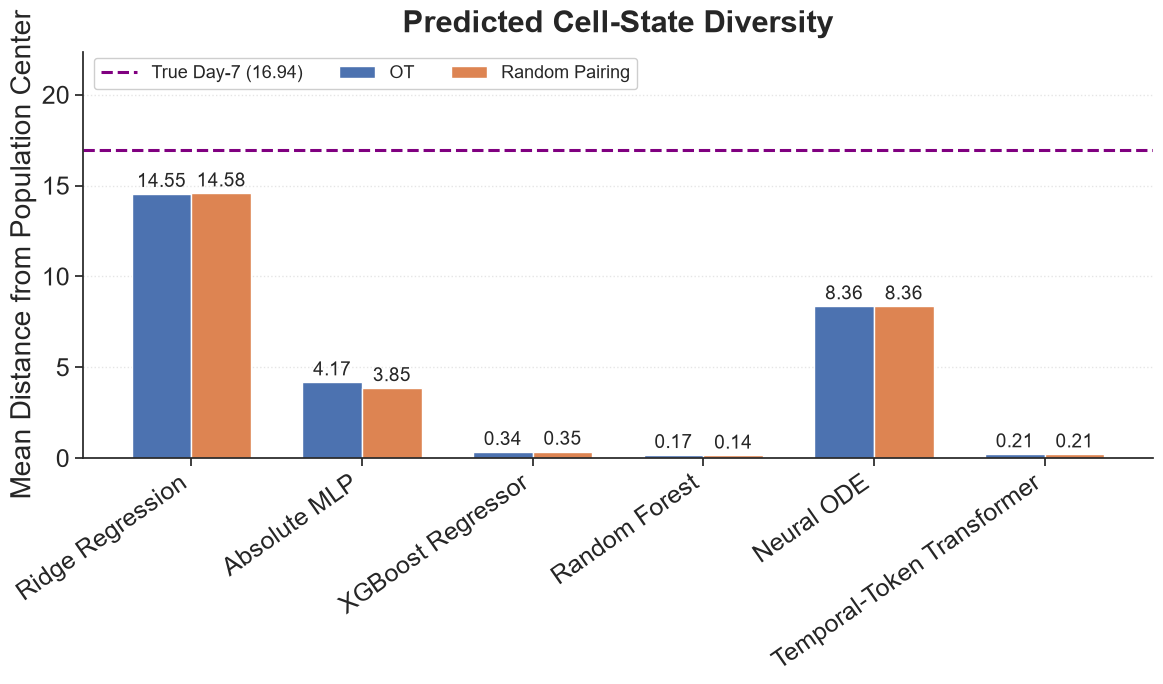


Saved publication figures:
publication_model_benchmark_pearson.png
publication_model_benchmark_endpoint_r2.png
publication_model_benchmark_w2.png
publication_model_benchmark_diversity.png

Saved numeric table:
final_direct_day0_day7_model_metrics.csv

✔ All six models use their Day-4-selected PCA dimensionality
✔ Ridge Regression: 750 PCs
✔ Absolute MLP: 500 PCs
✔ XGBoost Regressor: 10 PCs
✔ Random Forest: 10 PCs
✔ Neural ODE: 250 PCs
✔ Temporal-Token Transformer: 100 PCs
✔ Within each model, OT and random use identical model inputs
✔ Within each model, OT and random differ only in target-pairing strategy
✔ All predictions evaluated in the same 2000-HVG biological gene space
✔ All four benchmark graphs are generated and saved separately
✔ Pearson benchmark includes All-HVG and Top-100 HVG persistence baselines
✔ Top-100 evaluation uses training-only gene variance
✔ Persistence baselines shown in purple
✔ Day 7 excluded from PCA-dimension selection
✔ Day 7 remains a sealed final evalua

In [16]:
# import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Final Direct Day-0 -> Day-7 Model Benchmark ---")

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"


# =========================================================
# 1. MODEL ORDER
# =========================================================

preferred_order = [
    "Ridge Regression",
    "Absolute MLP",
    "XGBoost Regressor",
    "Random Forest",
    "Neural ODE",
    "Temporal-Token Transformer"
]


# =========================================================
# 2. REQUIRED METRICS
# =========================================================

required_keys = [
    "Pearson_r2_All",
    "Random_Pearson_r2_All",
    "Pearson_r2_Top100",
    "Random_Pearson_r2_Top100",
    "Endpoint_R2",
    "Random_Endpoint_R2",
    "W2",
    "Random_W2",
    "Mean_Gene_Variance",
    "Random_Mean_Gene_Variance",
    "Mean_Distance_From_Center",
    "Random_Mean_Distance_From_Center"
]


# =========================================================
# 3. VERIFY FINAL MODEL-SPECIFIC SETUP
# =========================================================

expected_model_dims = {
    "Ridge Regression": 750,
    "Absolute MLP": 500,
    "XGBoost Regressor": 10,
    "Random Forest": 10,
    "Neural ODE": 250,
    "Temporal-Token Transformer": 100
}

for model_name in preferred_order:
    data = model_training_data[model_name]
    pc_count = data["pc_count"]

    assert pc_count == expected_model_dims[model_name]
    assert pc_count == model_pca_dims[model_name]

    assert data["X_train_ot"].shape == (4020, pc_count + 1)
    assert data["Y_train_ot"].shape == (4020, pc_count)
    assert data["X_train_random"].shape == (4020, pc_count + 1)
    assert data["Y_train_random"].shape == (4020, pc_count)

    assert data["X_control_train_latent"].shape == (804, pc_count)
    assert data["X_control_test_latent"].shape == (201, pc_count)
    assert data["X_test"].shape == (201, pc_count + 1)

    assert np.allclose(data["X_train_ot"], data["X_train_random"])
    assert not np.allclose(data["Y_train_ot"], data["Y_train_random"])
    assert np.allclose(data["X_test"][:, -1], 7.0)

print("Model-specific PCA dimensions verified:")
for model_name in preferred_order:
    print(f"{model_name:28s}: {model_training_data[model_name]['pc_count']} PCs")

assert "Sen D7" not in set(adata_processed.obs["sample"].unique())
assert not any("D7" in transition for transition in ot_transition_info.keys())
assert not any("D7" in transition for transition in random_pairing_info.keys())
assert len(set(control_test_obs_names).intersection(set(control_train_obs_names))) == 0

print("Within-model OT/random input matching verified.")
print("Day-7 leakage checks passed.")


# =========================================================
# 4. VERIFY FINAL PREDICTION SHAPES
# =========================================================

prediction_sets = {
    "Ridge Regression": (
        pred_latent_ridge_ot,
        pred_latent_ridge_random,
        pred_genes_ridge_ot,
        pred_genes_ridge_random
    ),
    "Absolute MLP": (
        pred_latent_mlp_ot,
        pred_latent_mlp_random,
        pred_genes_mlp_ot,
        pred_genes_mlp_random
    ),
    "XGBoost Regressor": (
        pred_latent_xgb_ot,
        pred_latent_xgb_random,
        pred_genes_xgb_ot,
        pred_genes_xgb_random
    ),
    "Random Forest": (
        pred_latent_rf_ot,
        pred_latent_rf_random,
        pred_genes_rf_ot,
        pred_genes_rf_random
    ),
    "Neural ODE": (
        pred_latent_ode_ot,
        pred_latent_ode_random,
        pred_genes_ode_ot,
        pred_genes_ode_random
    ),
    "Temporal-Token Transformer": (
        pred_latent_trans_ot,
        pred_latent_trans_random,
        pred_genes_trans_ot,
        pred_genes_trans_random
    )
}

for model_name in preferred_order:
    pc_count = model_pca_dims[model_name]
    latent_ot, latent_random, genes_ot, genes_random = prediction_sets[model_name]

    assert latent_ot.shape == (201, pc_count)
    assert latent_random.shape == (201, pc_count)
    assert genes_ot.shape == (201, 2000)
    assert genes_random.shape == (201, 2000)

    assert np.isfinite(latent_ot).all()
    assert np.isfinite(latent_random).all()
    assert np.isfinite(genes_ot).all()
    assert np.isfinite(genes_random).all()

print("All final model-specific prediction shapes verified.")


# =========================================================
# 5. TRUE DAY-7 DIVERSITY
# =========================================================

true_diversity_metrics = cell_diversity_metrics(Y_test_true_biological)

true_gene_variance = true_diversity_metrics["Mean_Gene_Variance"]
true_distance_from_center = true_diversity_metrics["Mean_Distance_From_Center"]

print("True Day-7 mean gene variance:", true_gene_variance)
print("True Day-7 mean distance from center:", true_distance_from_center)


# =========================================================
# 6. PERSISTENCE BASELINES
# ALL HVGs + TOP 100 HVGs
# =========================================================

control_test_bio = adata_control_test.raw[:, hvg_gene_names].X
control_test_bio = control_test_bio.toarray() if hasattr(control_test_bio, "toarray") else np.asarray(control_test_bio)

true_day7_mean = np.mean(Y_test_true_biological, axis=0)
control_test_mean = np.mean(control_test_bio, axis=0)

baseline_pearson_r2 = pearson_r2(true_day7_mean, control_test_mean)
baseline_top100_pearson_r2 = pearson_r2(true_day7_mean[top_100_hvg_indices], control_test_mean[top_100_hvg_indices])

baseline_r2 = endpoint_r2(Y_test_true_biological, control_test_bio)
baseline_w2 = wasserstein2_gene_space(Y_test_true_biological, control_test_bio)

print("\n--- Day-0 Persistence Baselines ---")
print("All-HVG Pearson r²:", round(baseline_pearson_r2, 4))
print("Top-100 HVG Pearson r²:", round(baseline_top100_pearson_r2, 4))
print("Endpoint R²:", round(baseline_r2, 4))
print("Wasserstein-2:", round(baseline_w2, 4))


# =========================================================
# 7. BUILD LEADERBOARD
# =========================================================

records = []

for model_name in preferred_order:
    if model_name not in model_results:
        print(f"Skipping {model_name}: not found in model_results")
        continue

    results = model_results[model_name]
    missing = [key for key in required_keys if key not in results]

    if missing:
        print(f"Skipping {model_name}: missing {', '.join(missing)}")
        continue

    ot_distance_error = abs(results["Mean_Distance_From_Center"] - true_distance_from_center)
    random_distance_error = abs(results["Random_Mean_Distance_From_Center"] - true_distance_from_center)

    ot_variance_error = abs(results["Mean_Gene_Variance"] - true_gene_variance)
    random_variance_error = abs(results["Random_Mean_Gene_Variance"] - true_gene_variance)

    records.append({
        "Model": model_name,
        "PCA_Dim": model_pca_dims[model_name],

        "OT_Pearson_All": results["Pearson_r2_All"],
        "Random_Pearson_All": results["Random_Pearson_r2_All"],

        "OT_Pearson_Top100": results["Pearson_r2_Top100"],
        "Random_Pearson_Top100": results["Random_Pearson_r2_Top100"],

        "OT_Endpoint_R2": results["Endpoint_R2"],
        "Random_Endpoint_R2": results["Random_Endpoint_R2"],

        "OT_W2": results["W2"],
        "Random_W2": results["Random_W2"],

        "OT_Gene_Variance": results["Mean_Gene_Variance"],
        "Random_Gene_Variance": results["Random_Mean_Gene_Variance"],

        "OT_Distance_From_Center": results["Mean_Distance_From_Center"],
        "Random_Distance_From_Center": results["Random_Mean_Distance_From_Center"],

        "OT_Diversity_Error": ot_distance_error,
        "Random_Diversity_Error": random_distance_error,

        "OT_Variance_Error": ot_variance_error,
        "Random_Variance_Error": random_variance_error
    })

df_leaderboard = pd.DataFrame(records)

if len(df_leaderboard) == 0:
    raise ValueError(
        "No complete model results found. "
        "Rerun all model evaluation cells first."
    )


# =========================================================
# 8. PRINT LEADERBOARD
# =========================================================

print("\n" + "=" * 200)
print("DIRECT HELD-OUT DAY-0 -> DAY-7 FORECASTING LEADERBOARD")
print("=" * 200)

print(
    df_leaderboard.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("=" * 200)


# =========================================================
# 9. BEST OT MODELS
# =========================================================

best_ot_pearson_all = df_leaderboard.loc[df_leaderboard["OT_Pearson_All"].idxmax()]
best_ot_pearson_top = df_leaderboard.loc[df_leaderboard["OT_Pearson_Top100"].idxmax()]
best_ot_r2 = df_leaderboard.loc[df_leaderboard["OT_Endpoint_R2"].idxmax()]
best_ot_w2 = df_leaderboard.loc[df_leaderboard["OT_W2"].idxmin()]
best_ot_diversity = df_leaderboard.loc[df_leaderboard["OT_Diversity_Error"].idxmin()]
best_ot_variance = df_leaderboard.loc[df_leaderboard["OT_Variance_Error"].idxmin()]

print("\n--- Best OT Models ---")
print(f"Best Pearson r² All HVGs: {best_ot_pearson_all['Model']} ({best_ot_pearson_all['OT_Pearson_All']:.4f})")
print(f"Best Pearson r² Top 100 HVGs: {best_ot_pearson_top['Model']} ({best_ot_pearson_top['OT_Pearson_Top100']:.4f})")
print(f"Best Endpoint R²: {best_ot_r2['Model']} ({best_ot_r2['OT_Endpoint_R2']:.4f})")
print(f"Best Wasserstein-2: {best_ot_w2['Model']} ({best_ot_w2['OT_W2']:.4f})")
print(f"Closest cell diversity: {best_ot_diversity['Model']} (distance error={best_ot_diversity['OT_Diversity_Error']:.4f})")
print(f"Closest gene variance: {best_ot_variance['Model']} (variance error={best_ot_variance['OT_Variance_Error']:.4f})")


# =========================================================
# 10. BEST RANDOM MODELS
# =========================================================

best_random_pearson_all = df_leaderboard.loc[df_leaderboard["Random_Pearson_All"].idxmax()]
best_random_pearson_top = df_leaderboard.loc[df_leaderboard["Random_Pearson_Top100"].idxmax()]
best_random_r2 = df_leaderboard.loc[df_leaderboard["Random_Endpoint_R2"].idxmax()]
best_random_w2 = df_leaderboard.loc[df_leaderboard["Random_W2"].idxmin()]
best_random_diversity = df_leaderboard.loc[df_leaderboard["Random_Diversity_Error"].idxmin()]
best_random_variance = df_leaderboard.loc[df_leaderboard["Random_Variance_Error"].idxmin()]

print("\n--- Best Capped-Random Models ---")
print(f"Best Pearson r² All HVGs: {best_random_pearson_all['Model']} ({best_random_pearson_all['Random_Pearson_All']:.4f})")
print(f"Best Pearson r² Top 100 HVGs: {best_random_pearson_top['Model']} ({best_random_pearson_top['Random_Pearson_Top100']:.4f})")
print(f"Best Endpoint R²: {best_random_r2['Model']} ({best_random_r2['Random_Endpoint_R2']:.4f})")
print(f"Best Wasserstein-2: {best_random_w2['Model']} ({best_random_w2['Random_W2']:.4f})")
print(f"Closest cell diversity: {best_random_diversity['Model']} (distance error={best_random_diversity['Random_Diversity_Error']:.4f})")
print(f"Closest gene variance: {best_random_variance['Model']} (variance error={best_random_variance['Random_Variance_Error']:.4f})")


# =========================================================
# 11. COMMON FIGURE SETTINGS
# =========================================================

models = df_leaderboard["Model"].values
x = np.arange(len(models))


# =========================================================
# 12. FIGURE 1 — PEARSON r²
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))
bar_width = 0.20

ax.bar(x - 1.5 * bar_width, df_leaderboard["OT_Pearson_All"], width=bar_width, label="OT: All HVGs")
ax.bar(x - 0.5 * bar_width, df_leaderboard["Random_Pearson_All"], width=bar_width, label="Random: All HVGs")
ax.bar(x + 0.5 * bar_width, df_leaderboard["OT_Pearson_Top100"], width=bar_width, label="OT: Top 100 HVGs")
ax.bar(x + 1.5 * bar_width, df_leaderboard["Random_Pearson_Top100"], width=bar_width, label="Random: Top 100 HVGs")

ax.axhline(
    baseline_pearson_r2,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"Day-0 Persistence: All HVGs ({baseline_pearson_r2:.3f})"
)

ax.axhline(
    baseline_top100_pearson_r2,
    color="purple",
    linestyle=":",
    linewidth=2.8,
    label=f"Day-0 Persistence: Top 100 HVGs ({baseline_top100_pearson_r2:.3f})"
)

ax.set_title("Endpoint Expression-Profile Alignment", fontsize=22, fontweight="bold", pad=14)
ax.set_ylabel("Pearson r²", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.set_ylim(0, 1.28)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

sns.despine()
plt.tight_layout()
plt.savefig("publication_model_benchmark_pearson.png", dpi=300, bbox_inches="tight")
print("Saved: publication_model_benchmark_pearson.png")
plt.show()


# =========================================================
# 13. FIGURE 2 — ENDPOINT R²
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))
bar_width = 0.35

bars_ot = ax.bar(x - bar_width / 2, df_leaderboard["OT_Endpoint_R2"], width=bar_width, label="OT")
bars_random = ax.bar(x + bar_width / 2, df_leaderboard["Random_Endpoint_R2"], width=bar_width, label="Random Pairing")

ax.axhline(
    baseline_r2,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"Day-0 Persistence ({baseline_r2:.3f})"
)

ax.set_title("Absolute Endpoint Accuracy", fontsize=22, fontweight="bold", pad=14)
ax.set_ylabel("Endpoint R²", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.set_ylim(0, 1.28)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

for bars in [bars_ot, bars_random]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.012,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=14
        )

sns.despine()
plt.tight_layout()
plt.savefig("publication_model_benchmark_endpoint_r2.png", dpi=300, bbox_inches="tight")
print("Saved: publication_model_benchmark_endpoint_r2.png")
plt.show()


# =========================================================
# 14. FIGURE 3 — WASSERSTEIN-2
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))
bar_width = 0.35

bars_ot = ax.bar(x - bar_width / 2, df_leaderboard["OT_W2"], width=bar_width, label="OT")
bars_random = ax.bar(x + bar_width / 2, df_leaderboard["Random_W2"], width=bar_width, label="Random Pairing")

ax.axhline(
    baseline_w2,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"Day-0 Persistence ({baseline_w2:.2f})"
)

w2_max = max(
    df_leaderboard["OT_W2"].max(),
    df_leaderboard["Random_W2"].max(),
    baseline_w2
)

ax.set_ylim(0, w2_max * 1.32)
ax.set_title("Endpoint Population Distribution", fontsize=22, fontweight="bold", pad=14)
ax.set_ylabel("Wasserstein-2 Distance ↓", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

for bars in [bars_ot, bars_random]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.12,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=14
        )

sns.despine()
plt.tight_layout()
plt.savefig("publication_model_benchmark_w2.png", dpi=300, bbox_inches="tight")
print("Saved: publication_model_benchmark_w2.png")
plt.show()


# =========================================================
# 15. FIGURE 4 — CELL-STATE DIVERSITY
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))
bar_width = 0.35

bars_ot = ax.bar(x - bar_width / 2, df_leaderboard["OT_Distance_From_Center"], width=bar_width, label="OT")
bars_random = ax.bar(x + bar_width / 2, df_leaderboard["Random_Distance_From_Center"], width=bar_width, label="Random Pairing")

ax.axhline(
    true_distance_from_center,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"True Day-7 ({true_distance_from_center:.2f})"
)

diversity_max = max(
    df_leaderboard["OT_Distance_From_Center"].max(),
    df_leaderboard["Random_Distance_From_Center"].max(),
    true_distance_from_center
)

ax.set_ylim(0, diversity_max * 1.32)
ax.set_title("Predicted Cell-State Diversity", fontsize=22, fontweight="bold", pad=14)
ax.set_ylabel("Mean Distance from Population Center", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha="right", fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.tick_params(axis="x", labelsize=18)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.01, 0.985),
    fontsize=13,
    ncol=3,
    frameon=True,
    framealpha=0.95,
    borderaxespad=0.0
)

for bars in [bars_ot, bars_random]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.15,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=14
        )

sns.despine()
plt.tight_layout()
plt.savefig("publication_model_benchmark_diversity.png", dpi=300, bbox_inches="tight")
print("Saved: publication_model_benchmark_diversity.png")
plt.show()


# =========================================================
# 16. SAVE NUMERIC RESULTS
# =========================================================

df_leaderboard.to_csv(
    "final_direct_day0_day7_model_metrics.csv",
    index=False
)

print("\nSaved publication figures:")
print("publication_model_benchmark_pearson.png")
print("publication_model_benchmark_endpoint_r2.png")
print("publication_model_benchmark_w2.png")
print("publication_model_benchmark_diversity.png")

print("\nSaved numeric table:")
print("final_direct_day0_day7_model_metrics.csv")


# =========================================================
# 17. FINAL STATUS
# =========================================================

print("\n✔ All six models use their Day-4-selected PCA dimensionality")
print("✔ Ridge Regression: 750 PCs")
print("✔ Absolute MLP: 500 PCs")
print("✔ XGBoost Regressor: 10 PCs")
print("✔ Random Forest: 10 PCs")
print("✔ Neural ODE: 250 PCs")
print("✔ Temporal-Token Transformer: 100 PCs")
print("✔ Within each model, OT and random use identical model inputs")
print("✔ Within each model, OT and random differ only in target-pairing strategy")
print("✔ All predictions evaluated in the same 2000-HVG biological gene space")
print("✔ All four benchmark graphs are generated and saved separately")
print("✔ Pearson benchmark includes All-HVG and Top-100 HVG persistence baselines")
print("✔ Top-100 evaluation uses training-only gene variance")
print("✔ Persistence baselines shown in purple")
print("✔ Day 7 excluded from PCA-dimension selection")
print("✔ Day 7 remains a sealed final evaluation endpoint")

--- Publication Figures: OT Wasserstein-2 PCA-Dimension Sweep ---
Original model predictions verified; original model variables will not be modified.
Saved: Figure_A_OT_PC1_PC2_Cell_Distributions.png


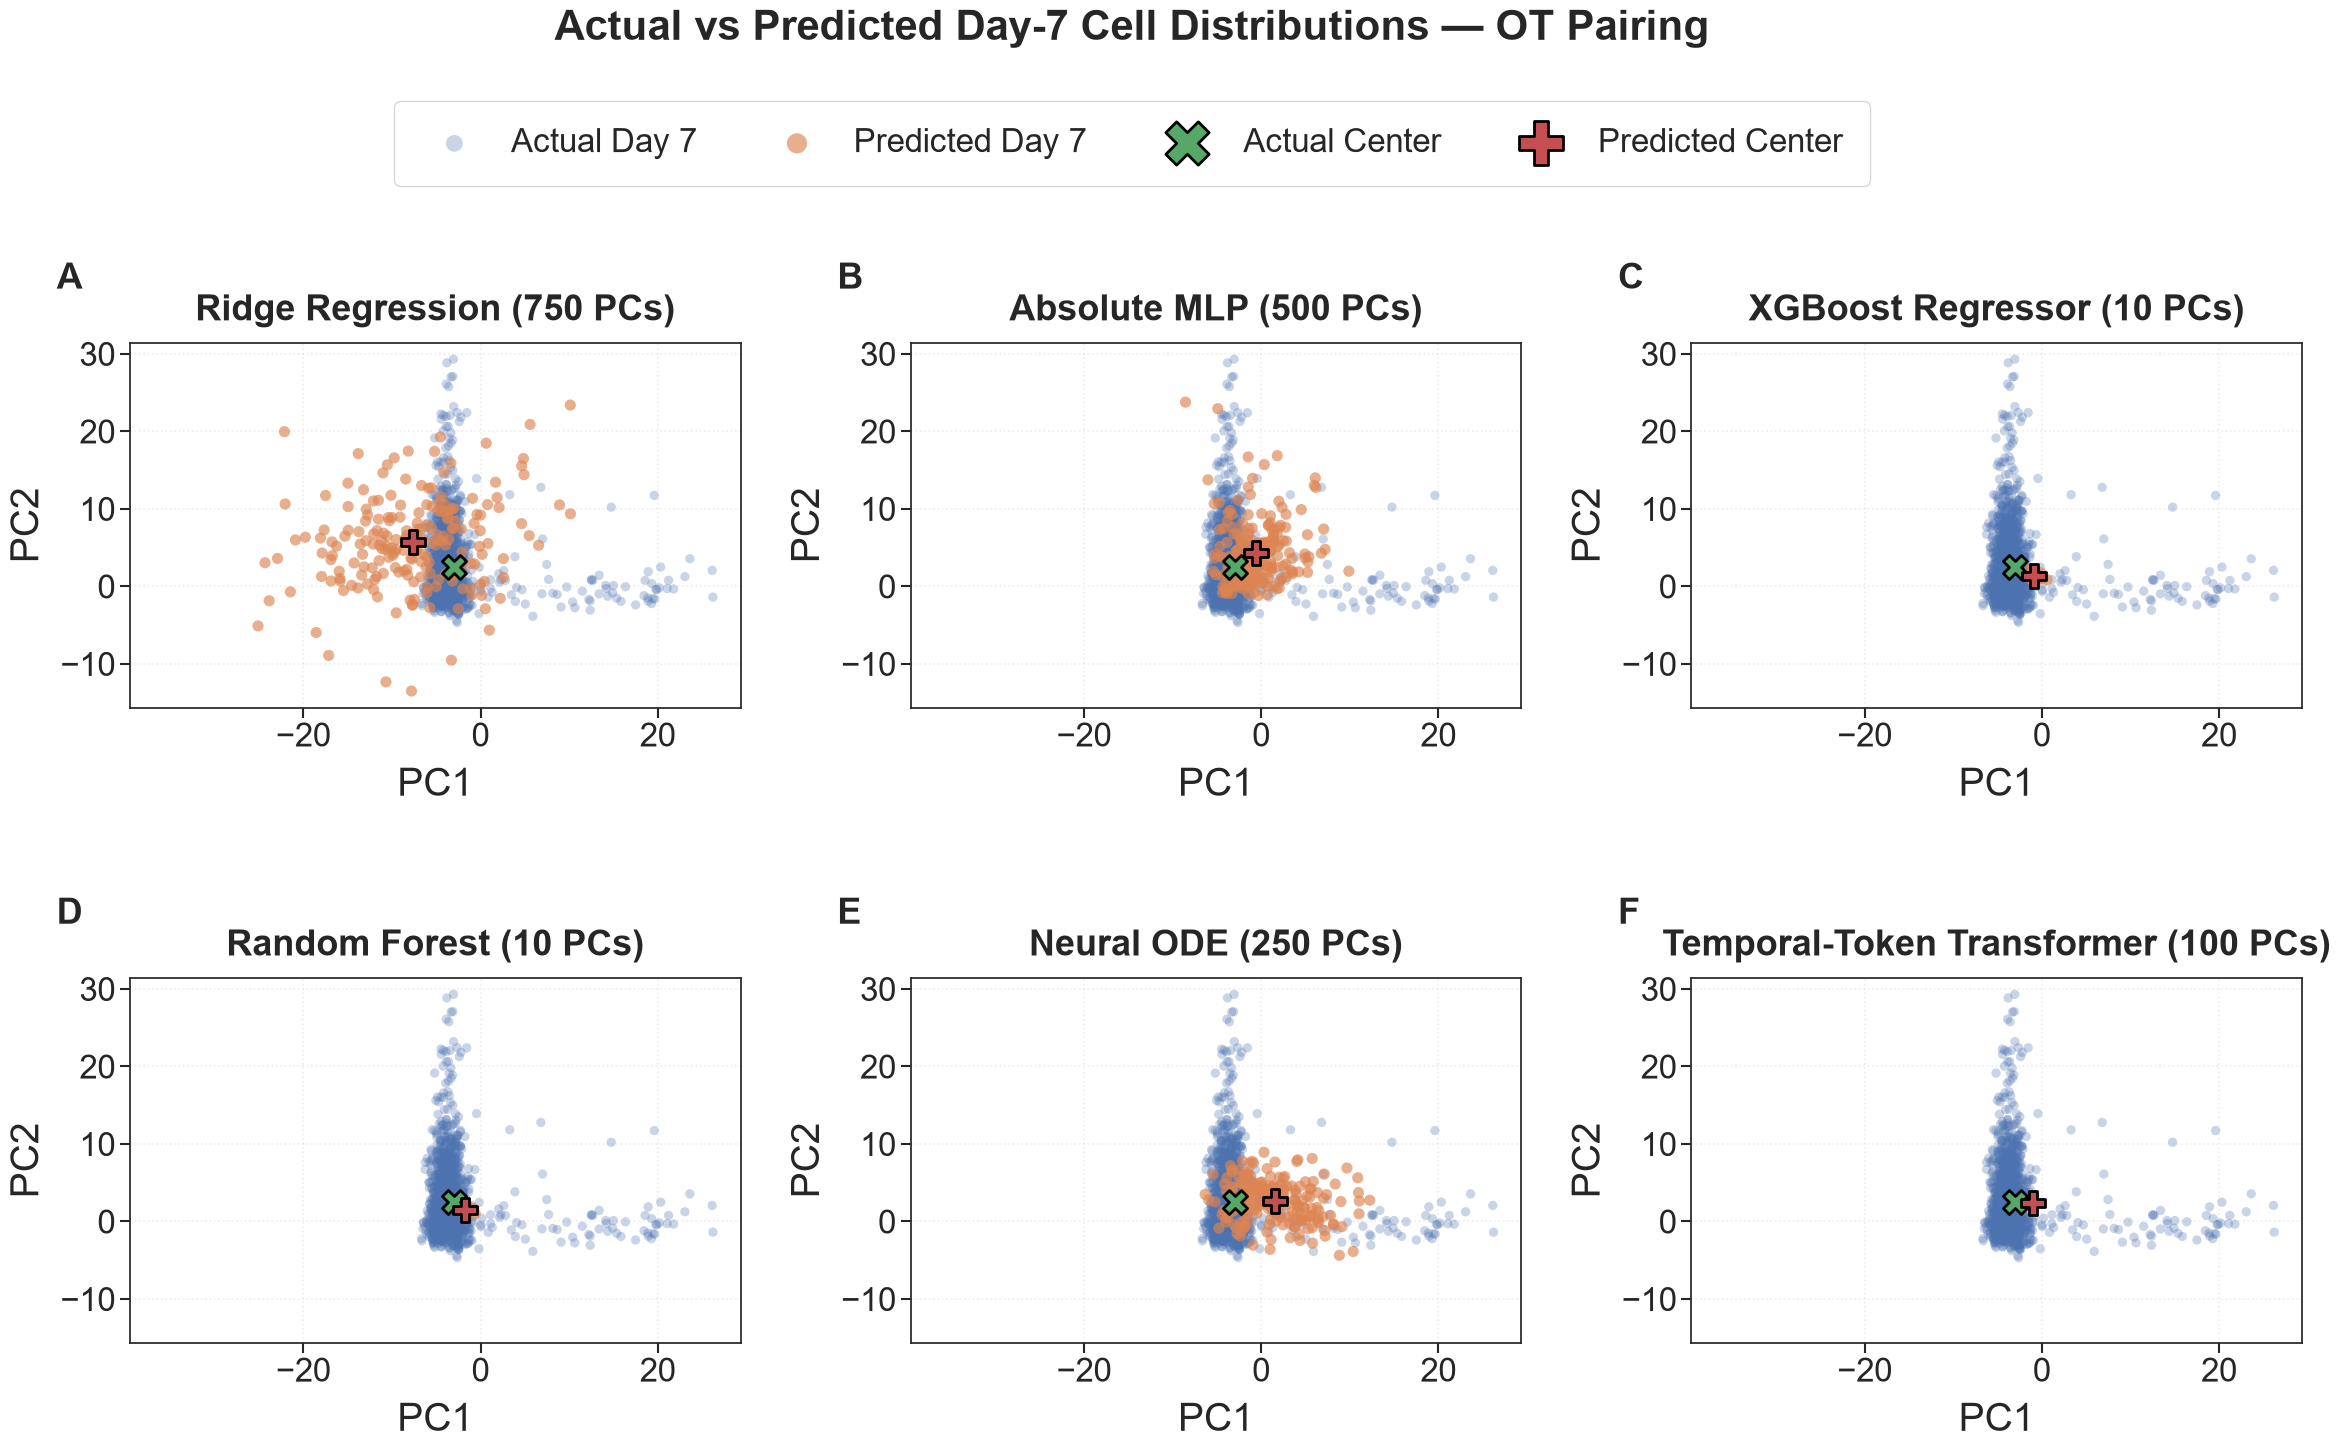

Saved: Capped_Random_PC1_PC2_Cell_Distributions.png


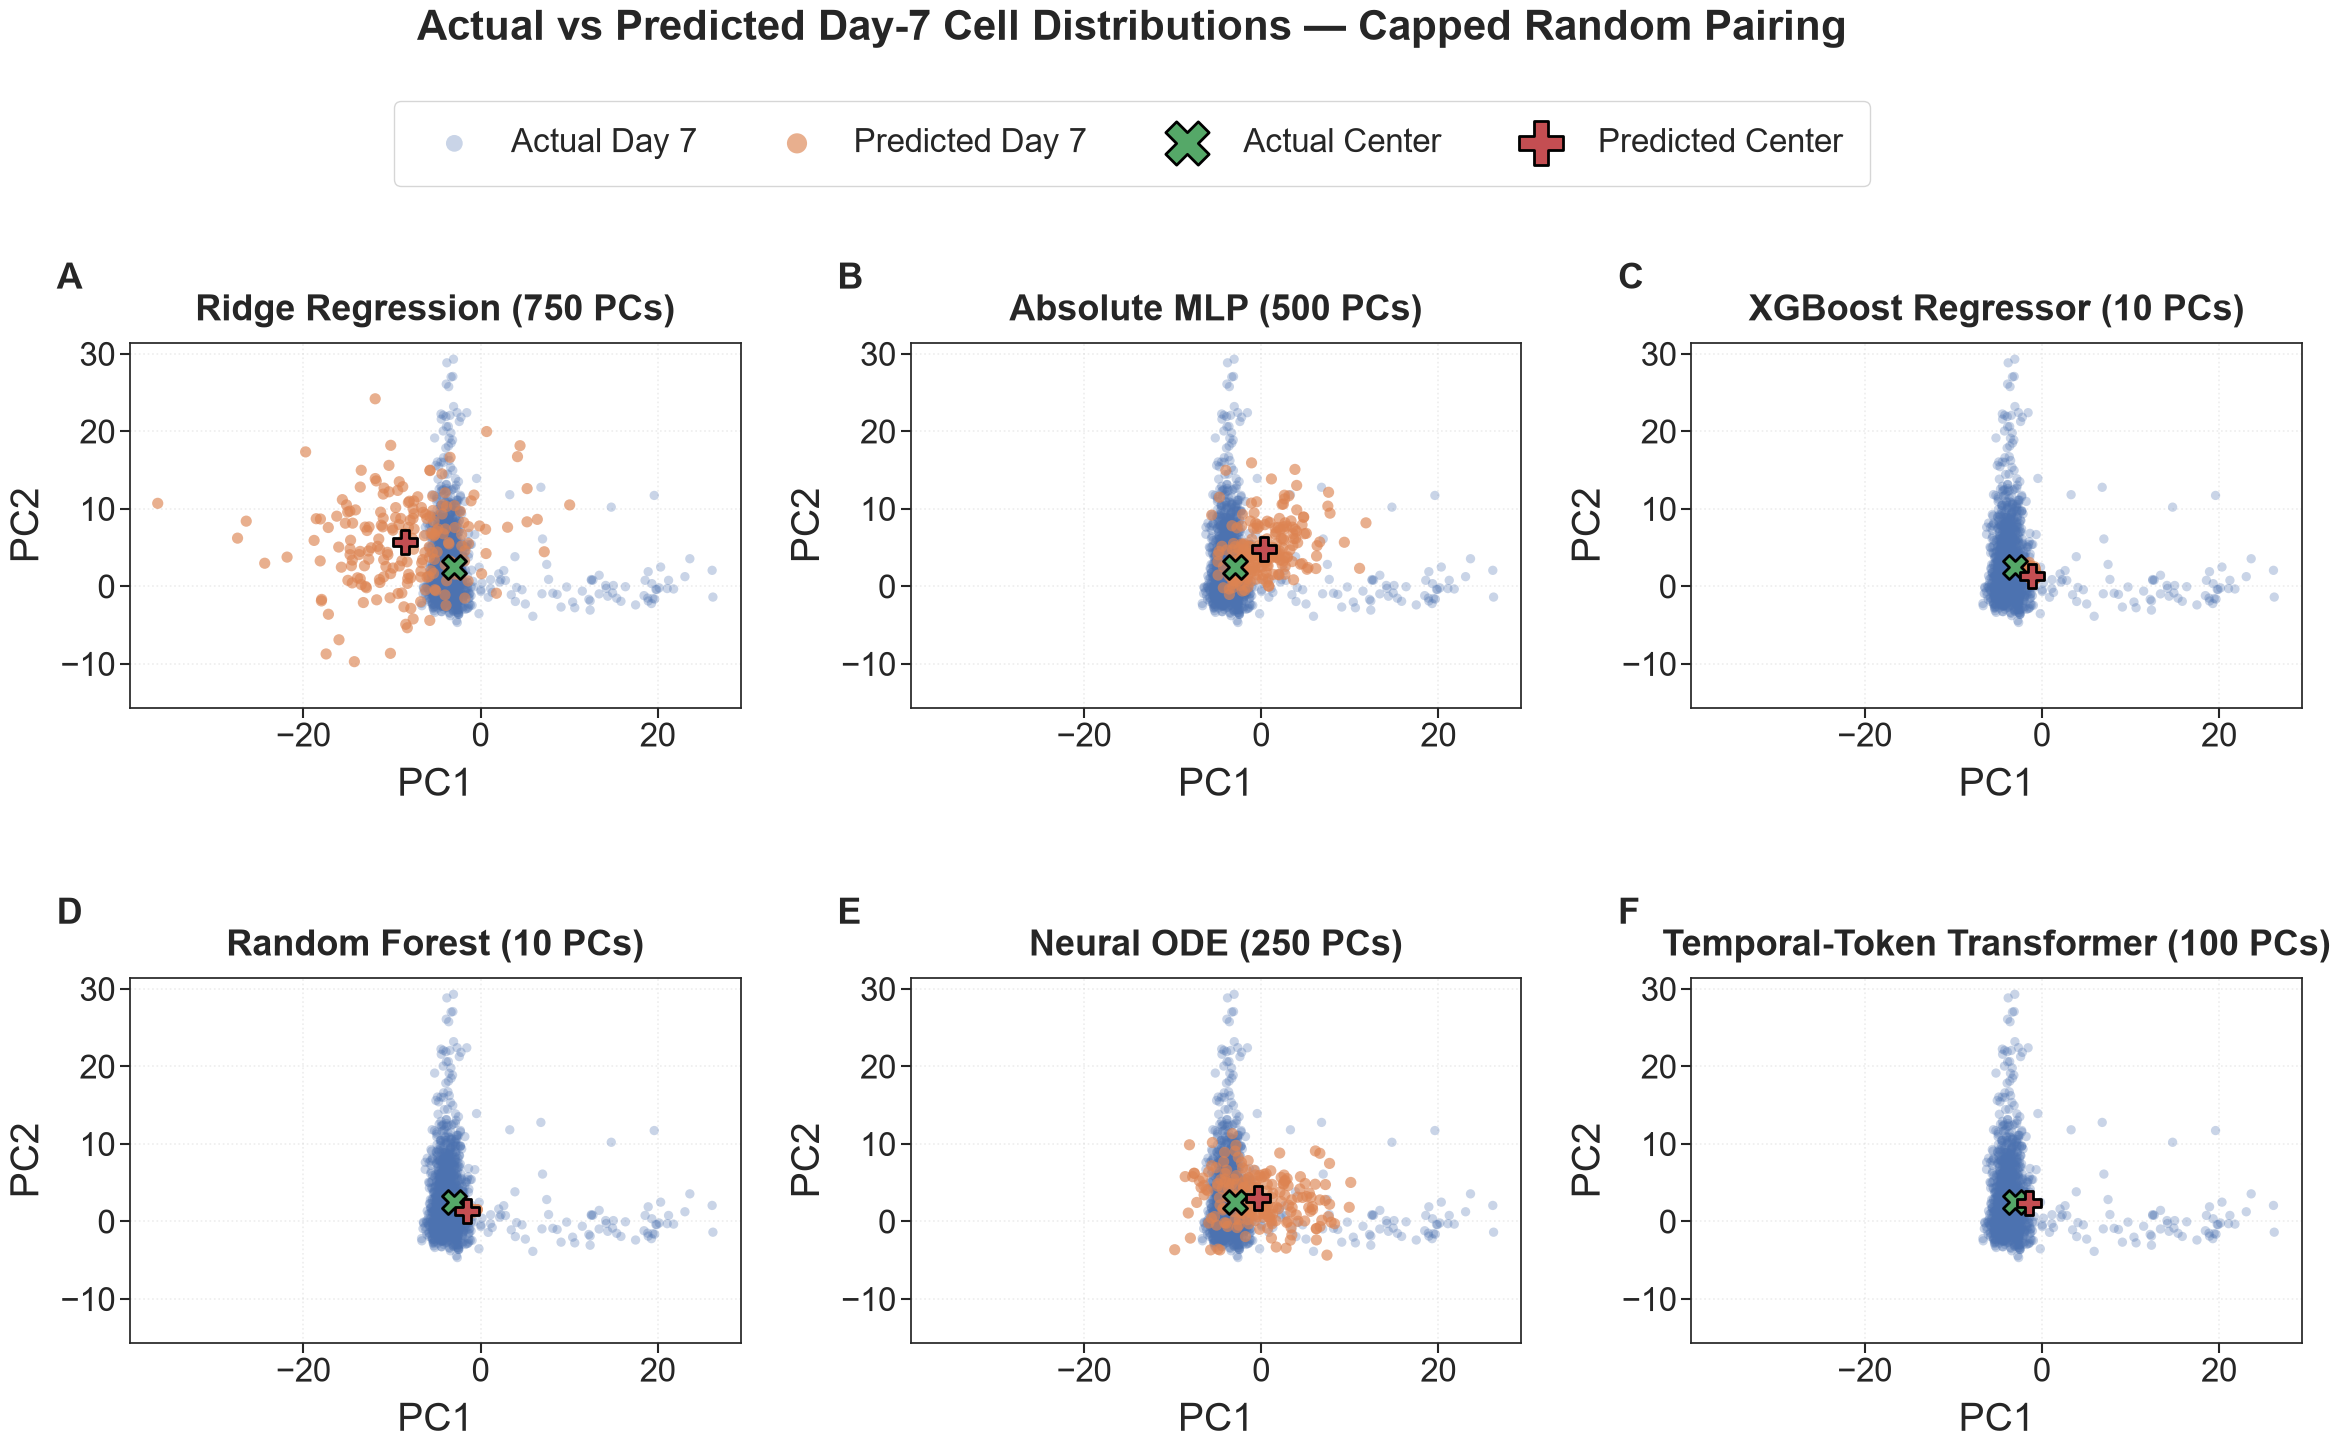

  Positive control W2 = 2.555305
  Negative control W2 = 10.193168

PCA DIMENSION 2 / 750

Training Ridge Regression at 2 PCs...
    Exact PCA-space W2 = 8.012290

Training Absolute MLP at 2 PCs...
    MLP epoch  20/120 | MSE = 26.871813
    MLP epoch  40/120 | MSE = 24.776525
    MLP epoch  60/120 | MSE = 23.791855
    MLP epoch  80/120 | MSE = 23.172644
    MLP epoch 100/120 | MSE = 23.044054
    MLP epoch 120/120 | MSE = 22.867323
    Exact PCA-space W2 = 5.994689

Training XGBoost Regressor at 2 PCs...
    Exact PCA-space W2 = 5.719044

Training Random Forest at 2 PCs...
    Exact PCA-space W2 = 5.523871

Training Neural ODE at 2 PCs...
    ODE epoch 10/60 | MSE = 54.670728
    ODE epoch 20/60 | MSE = 54.559366
    ODE epoch 30/60 | MSE = 54.489042
    ODE epoch 40/60 | MSE = 54.409514
    ODE epoch 50/60 | MSE = 54.298134
    ODE epoch 60/60 | MSE = 54.285243
    Exact PCA-space W2 = 4.868478

Training Temporal-Token Transformer at 2 PCs...
    Transformer epoch 10/30 | MSE = 23.3

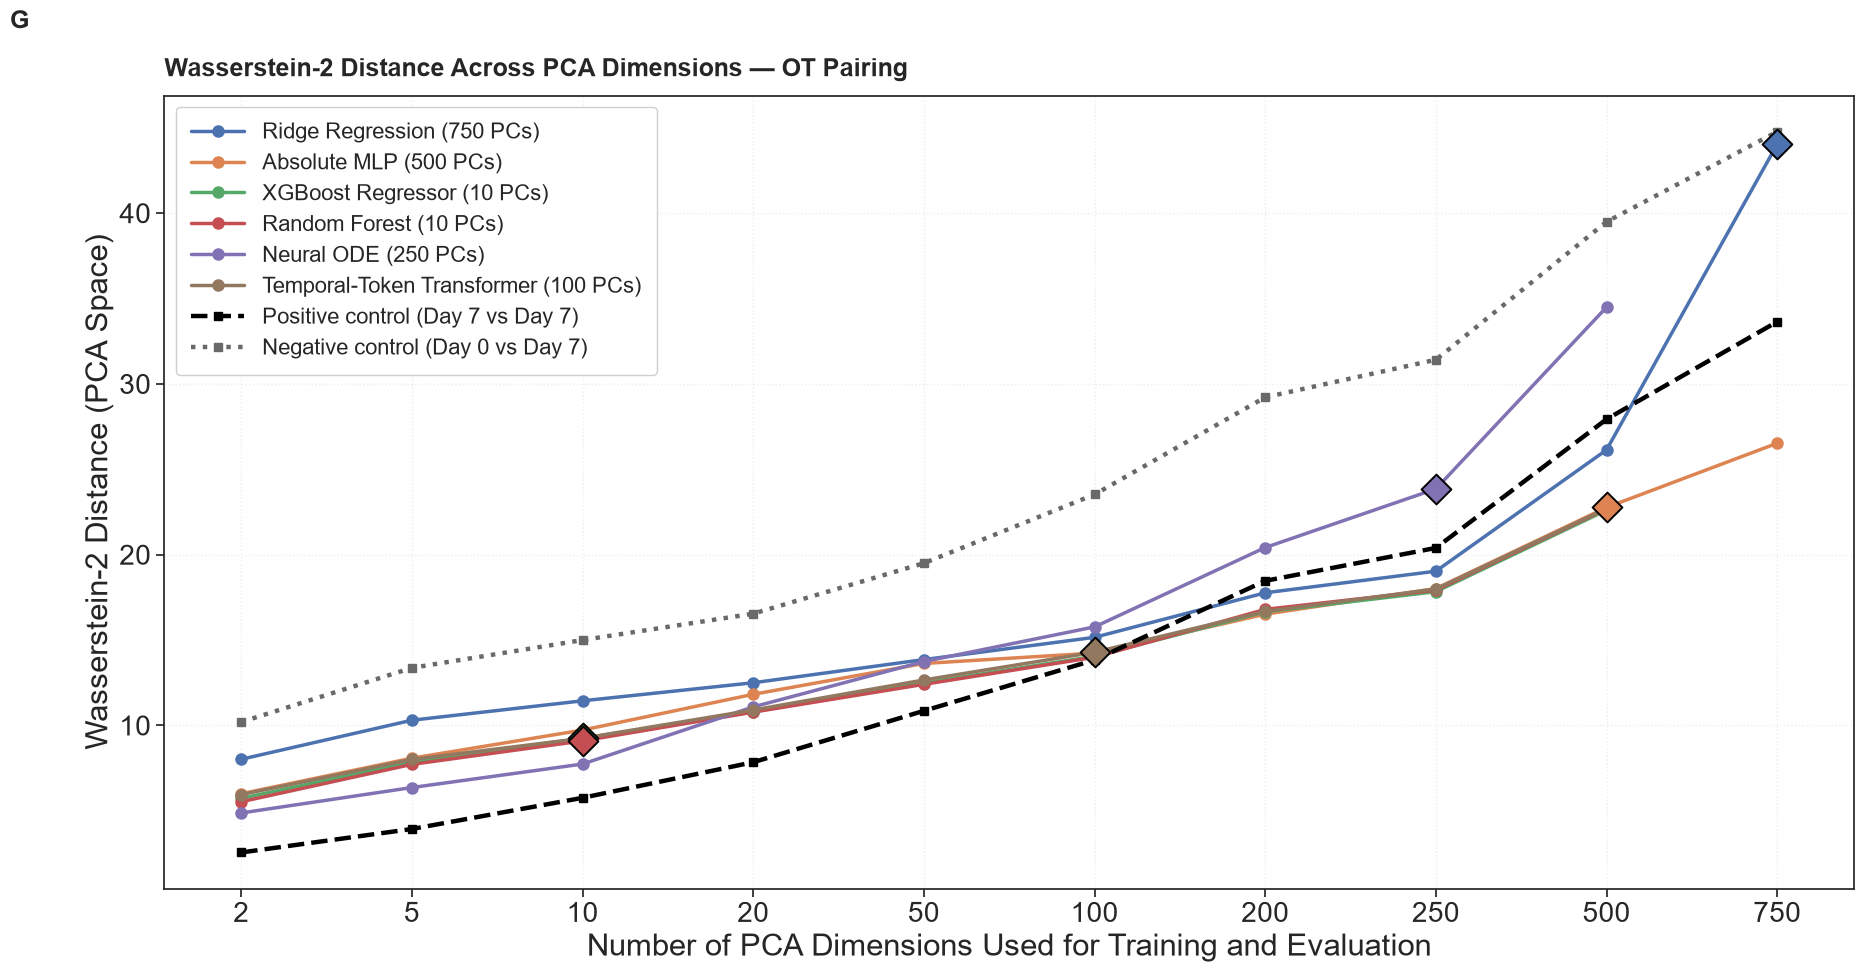


COMPLETE: 56 independently trained OT-only configurations
Figure A: Original selected-model OT PC1-PC2 distributions
Figure B: Exact PCA-space W2 against PCA dimensions
Diamond markers: Each model's original selected PCA dimension
All original architectures and hyperparameters preserved
XGBoost, Random Forest, Neural ODE, and Transformer capped at 500 PCs
No Day-7 fitting, no random-pairing sweep, no predicted-PC zero-padding
Results table: OT_PCA_Wasserstein2_Sweep.csv
Control table: OT_PCA_Wasserstein2_Controls.csv
W2 uses 201 held-out predictions versus the same 201 Day-7 reference cells


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ot
import torch
import torch.nn as nn
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

print('--- Publication Figures: OT Wasserstein-2 PCA-Dimension Sweep ---')

# =========================================================
# 1. PUBLICATION FORMATTING
# =========================================================
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'

A_MAIN_TITLE_SIZE = 30
A_PANEL_TITLE_SIZE = 26
A_AXIS_LABEL_SIZE = 28
A_TICK_SIZE = 24
A_LEGEND_SIZE = 24
A_FIGURE_LABEL_SIZE = 26
B_TITLE_SIZE = 18
B_AXIS_LABEL_SIZE = 22
B_TICK_SIZE = 20
B_LEGEND_SIZE = 16
B_FIGURE_LABEL_SIZE = 18
SAVE_DPI = 300

# =========================================================
# 2. VERIFY EXISTING PREDICTIONS AND DATA
# =========================================================
actual_day7_pca = np.asarray(X_day7_pca, dtype=np.float64)

ot_predictions = {
    'Ridge Regression': np.asarray(pred_latent_ridge_ot, dtype=np.float64),
    'Absolute MLP': np.asarray(pred_latent_mlp_ot, dtype=np.float64),
    'XGBoost Regressor': np.asarray(pred_latent_xgb_ot, dtype=np.float64),
    'Random Forest': np.asarray(pred_latent_rf_ot, dtype=np.float64),
    'Neural ODE': np.asarray(pred_latent_ode_ot, dtype=np.float64),
    'Temporal-Token Transformer': np.asarray(pred_latent_trans_ot, dtype=np.float64)
}

random_predictions = {
    'Ridge Regression': np.asarray(pred_latent_ridge_random, dtype=np.float64),
    'Absolute MLP': np.asarray(pred_latent_mlp_random, dtype=np.float64),
    'XGBoost Regressor': np.asarray(pred_latent_xgb_random, dtype=np.float64),
    'Random Forest': np.asarray(pred_latent_rf_random, dtype=np.float64),
    'Neural ODE': np.asarray(pred_latent_ode_random, dtype=np.float64),
    'Temporal-Token Transformer': np.asarray(pred_latent_trans_random, dtype=np.float64)
}

candidate_pc_dimensions = [2, 5, 10, 20, 50, 100, 200, 250, 500, 750]
# These four architectures are capped at 500 PCs in the sweep.
sweep_max_pc_by_model = {
    'XGBoost Regressor': 500,
    'Random Forest': 500,
    'Temporal-Token Transformer': 500,
    'Neural ODE': 500
}
expected_sweep_runs = sum(
    sum(pc <= sweep_max_pc_by_model.get(name, 750) for pc in candidate_pc_dimensions)
    for name in model_pca_dims
)
model_order = list(ot_predictions.keys())

assert actual_day7_pca.shape == (1407, 750)
assert max_pc_count == 750
assert X_train_ot_sources_full.shape == (4020, 750)
assert Y_train_ot_full.shape == (4020, 750)
assert dT_train.shape == (4020, 1)
assert X_control_test_latent_full.shape == (201, 750)
assert len(train_source_idx) == 804
assert len(test_source_idx) == 201
assert not np.intersect1d(train_source_idx, test_source_idx).size
assert 'Sen D7' not in set(adata_processed.obs['sample'].unique())
assert not any('D7' in transition for transition in ot_transition_info)

for model_name in model_order:
    expected_shape = (201, model_pca_dims[model_name])
    assert ot_predictions[model_name].shape == expected_shape
    assert random_predictions[model_name].shape == expected_shape
    assert np.isfinite(ot_predictions[model_name]).all()
    assert np.isfinite(random_predictions[model_name]).all()

print('Original model predictions verified; original model variables will not be modified.')

# =========================================================
# 3. COMMON PC1-PC2 AXIS LIMITS
# =========================================================
all_pc2_arrays = [actual_day7_pca[:, :2]]
all_pc2_arrays.extend(prediction[:, :2] for prediction in ot_predictions.values())
all_pc2_arrays.extend(prediction[:, :2] for prediction in random_predictions.values())
all_pc2_points = np.vstack(all_pc2_arrays)

x_min, x_max = np.min(all_pc2_points[:, 0]), np.max(all_pc2_points[:, 0])
y_min, y_max = np.min(all_pc2_points[:, 1]), np.max(all_pc2_points[:, 1])
x_padding = 0.05 * (x_max - x_min)
y_padding = 0.05 * (y_max - y_min)
x_limits = (x_min - x_padding, x_max + x_padding)
y_limits = (y_min - y_padding, y_max + y_padding)
actual_center_2d = np.mean(actual_day7_pca[:, :2], axis=0)

# =========================================================
# 4. SIX-PANEL PC1-PC2 DISTRIBUTION FIGURE
# =========================================================
def plot_distribution_figure(predictions, title, filename, figure_label=None):
    fig, axes = plt.subplots(2, 3, figsize=(24, 15))
    axes = axes.flatten()

    for panel_idx, (ax, (model_name, prediction)) in enumerate(zip(axes, predictions.items())):
        ax.text(-0.12, 1.22, chr(65 + panel_idx), transform=ax.transAxes,
            fontsize=A_FIGURE_LABEL_SIZE, fontweight='bold',
            ha='left', va='top', clip_on=False)
        predicted_center_2d = np.mean(prediction[:, :2], axis=0)
        ax.scatter(actual_day7_pca[:, 0], actual_day7_pca[:, 1], s=45, alpha=0.30, edgecolors='none', label='Actual Day 7')
        ax.scatter(prediction[:, 0], prediction[:, 1], s=65, alpha=0.65, edgecolors='none', label='Predicted Day 7')
        ax.scatter(actual_center_2d[0], actual_center_2d[1], s=300, marker='X', edgecolors='black', linewidths=2.0, label='Actual Center', zorder=5)
        ax.scatter(predicted_center_2d[0], predicted_center_2d[1], s=300, marker='P', edgecolors='black', linewidths=2.0, label='Predicted Center', zorder=5)
        ax.set_xlim(x_limits)
        ax.set_ylim(y_limits)
        ax.set_title(f'{model_name} ({model_pca_dims[model_name]} PCs)', fontsize=A_PANEL_TITLE_SIZE, fontweight='bold', pad=16)
        ax.set_xlabel('PC1', fontsize=A_AXIS_LABEL_SIZE, labelpad=10)
        ax.set_ylabel('PC2', fontsize=A_AXIS_LABEL_SIZE, labelpad=10)
        ax.tick_params(axis='both', which='major', labelsize=A_TICK_SIZE, width=1.5, length=7)
        ax.grid(True, linestyle=':', linewidth=1.2, alpha=0.35)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.935), ncol=4,
               fontsize=A_LEGEND_SIZE, markerscale=1.8, frameon=True, borderpad=0.8,
               labelspacing=0.8, handletextpad=0.7, columnspacing=2.0)
    fig.suptitle(title, fontsize=A_MAIN_TITLE_SIZE, fontweight='bold', y=0.985)

    plt.tight_layout(rect=[0.025, 0.02, 0.995, 0.89], h_pad=3.5, w_pad=3.0)
    plt.savefig(filename, dpi=SAVE_DPI, bbox_inches='tight')
    print('Saved:', filename)
    plt.show()

# =========================================================
# 5. FIGURE A AND EXISTING CAPPED-RANDOM DISTRIBUTION
# =========================================================
plot_distribution_figure(
    predictions=ot_predictions,
    title='Actual vs Predicted Day-7 Cell Distributions — OT Pairing',
    filename='Figure_A_OT_PC1_PC2_Cell_Distributions.png',
    figure_label=None
)

plot_distribution_figure(
    predictions=random_predictions,
    title='Actual vs Predicted Day-7 Cell Distributions — Capped Random Pairing',
    filename='Capped_Random_PC1_PC2_Cell_Distributions.png',
    figure_label=None
)

# =========================================================
# 6. EXACT ORIGINAL ARCHITECTURES, DIMENSION-ADAPTIVE IO
# =========================================================
class SweepAbsoluteMLP(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.GELU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, out_dim)
        )

    def forward(self, x):
        return self.net(x)


class SweepFastVelocityODE(nn.Module):
    def __init__(self, pc_count):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(pc_count + 1, 128),
            nn.GELU(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128, pc_count),
            nn.Tanh()
        )

    def forward(self, z, t_scalar):
        t_batch = torch.full((z.shape[0], 1), float(t_scalar), dtype=z.dtype, device=z.device)
        return self.net(torch.cat([z, t_batch], dim=1)) * 2.0


def integrate_sweep_ode(model, z0, dt_total):
    z = z0
    dt_sub = dt_total / 6
    for step in range(6):
        t_current = step / 6
        z = z + model(z, t_current) * dt_sub
    return z


class SweepTemporalTokenTransformer(nn.Module):
    def __init__(self, pc_count):
        super().__init__()
        self.pc_count = pc_count
        self.token_size = 5
        self.num_state_tokens = (pc_count + self.token_size - 1) // self.token_size
        self.padded_pc_count = self.num_state_tokens * self.token_size
        self.state_projection = nn.Linear(5, 32)
        self.time_projection = nn.Linear(1, 32)
        self.position_embedding = nn.Parameter(torch.zeros(1, self.num_state_tokens + 1, 32))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=32, nhead=4, dim_feedforward=128, dropout=0.1,
            activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.output_projection = nn.Linear(32, 5)

    def forward(self, x):
        pcs = x[:, :self.pc_count]
        dt = x[:, self.pc_count:self.pc_count + 1]
        if self.padded_pc_count > self.pc_count:
            pcs = nn.functional.pad(pcs, (0, self.padded_pc_count - self.pc_count), value=0.0)
        state_tokens = pcs.reshape(pcs.shape[0], self.num_state_tokens, 5)
        state_tokens = self.state_projection(state_tokens)
        time_token = self.time_projection(dt).unsqueeze(1)
        tokens = torch.cat([time_token, state_tokens], dim=1)
        encoded = self.transformer(tokens + self.position_embedding)
        predicted_tokens = self.output_projection(encoded[:, 1:, :])
        return predicted_tokens.reshape(predicted_tokens.shape[0], self.padded_pc_count)[:, :self.pc_count]

# =========================================================
# 7. ORIGINAL MODEL TRAINING PROCEDURES (OT ONLY)
# =========================================================
def train_sweep_mlp(X_train, Y_train, seed=42):
    torch.manual_seed(seed)
    X_tensor = torch.tensor(np.asarray(X_train), dtype=torch.float32)
    Y_tensor = torch.tensor(np.asarray(Y_train), dtype=torch.float32)
    model = SweepAbsoluteMLP(X_tensor.shape[1], Y_tensor.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    model.train()
    final_loss = None

    for epoch in range(120):
        optimizer.zero_grad()
        prediction = model(X_tensor)
        loss = nn.functional.mse_loss(prediction, Y_tensor)
        loss.backward()
        optimizer.step()
        final_loss = float(loss.detach().cpu())
        if (epoch + 1) % 20 == 0:
            print(f'    MLP epoch {epoch + 1:3d}/120 | MSE = {final_loss:.6f}')

    return model, final_loss


def train_sweep_ode(X_train, Y_train, seed=42):
    torch.manual_seed(seed)
    pc_count = Y_train.shape[1]
    model = SweepFastVelocityODE(pc_count)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-3)
    X_np = np.asarray(X_train, dtype=np.float32)
    Y_np = np.asarray(Y_train, dtype=np.float32)
    rng = np.random.default_rng(seed)
    n = len(X_np)
    final_loss = None

    for epoch in range(60):
        order = rng.permutation(n)
        epoch_loss = 0.0
        model.train()
        for start in range(0, n, 512):
            idx = order[start:start + 512]
            X_batch = torch.tensor(X_np[idx], dtype=torch.float32)
            Y_batch = torch.tensor(Y_np[idx], dtype=torch.float32)
            z0 = X_batch[:, :pc_count]
            dt = X_batch[:, pc_count:pc_count + 1]
            optimizer.zero_grad()
            prediction = integrate_sweep_ode(model, z0, dt)
            loss = nn.functional.mse_loss(prediction, Y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(idx)
        final_loss = epoch_loss / n
        if (epoch + 1) % 10 == 0:
            print(f'    ODE epoch {epoch + 1:2d}/60 | MSE = {final_loss:.6f}')

    return model, final_loss


def train_sweep_transformer(X_train, Y_train, seed=42):
    torch.manual_seed(seed)
    pc_count = Y_train.shape[1]
    model = SweepTemporalTokenTransformer(pc_count)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-5)
    X_np = np.asarray(X_train, dtype=np.float32)
    Y_np = np.asarray(Y_train, dtype=np.float32)
    rng = np.random.default_rng(seed)
    n = len(X_np)
    final_loss = None

    for epoch in range(30):
        model.train()
        order = rng.permutation(n)
        epoch_loss = 0.0
        for start in range(0, n, 512):
            idx = order[start:start + 512]
            X_batch = torch.tensor(X_np[idx], dtype=torch.float32)
            Y_batch = torch.tensor(Y_np[idx], dtype=torch.float32)
            optimizer.zero_grad()
            prediction = model(X_batch)
            loss = nn.functional.mse_loss(prediction, Y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(idx)
        final_loss = epoch_loss / n
        if (epoch + 1) % 10 == 0:
            print(f'    Transformer epoch {epoch + 1:2d}/30 | MSE = {final_loss:.6f}')

    return model, final_loss


def train_and_predict_sweep_model(model_name, X_train, Y_train, X_test):
    if model_name == 'Ridge Regression':
        model = Ridge(alpha=10.0)
        model.fit(X_train, Y_train)
        prediction = model.predict(X_test)

    elif model_name == 'Absolute MLP':
        model, _ = train_sweep_mlp(X_train, Y_train, seed=42)
        model.eval()
        with torch.no_grad():
            prediction = model(torch.tensor(X_test, dtype=torch.float32)).cpu().numpy()

    elif model_name == 'XGBoost Regressor':
        base_xgb = XGBRegressor(
            n_estimators=30, max_depth=3, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=42,
            n_jobs=1, tree_method='hist'
        )
        model = MultiOutputRegressor(base_xgb, n_jobs=4)
        model.fit(X_train, Y_train)
        prediction = model.predict(X_test)

    elif model_name == 'Random Forest':
        model = RandomForestRegressor(
            n_estimators=20, max_depth=4, max_features=0.5,
            random_state=42, n_jobs=2
        )
        model.fit(X_train, Y_train)
        prediction = model.predict(X_test)

    elif model_name == 'Neural ODE':
        model, _ = train_sweep_ode(X_train, Y_train, seed=42)
        model.eval()
        pc_count = Y_train.shape[1]
        X_tensor = torch.tensor(X_test, dtype=torch.float32)
        with torch.no_grad():
            prediction = integrate_sweep_ode(
                model, X_tensor[:, :pc_count], X_tensor[:, pc_count:pc_count + 1]
            ).cpu().numpy()

    elif model_name == 'Temporal-Token Transformer':
        model, _ = train_sweep_transformer(X_train, Y_train, seed=42)
        model.eval()
        with torch.no_grad():
            prediction = model(torch.tensor(X_test, dtype=torch.float32)).cpu().numpy()

    else:
        raise ValueError(f'Unknown model: {model_name}')

    return np.asarray(prediction, dtype=np.float64)

# =========================================================
# 8. INDEPENDENT 56-CONFIGURATION OT-ONLY PCA SWEEP
# =========================================================
# OT matches are fixed from Step 5 in the common 750-PC space.
# Each model is freshly fitted on its own k-dimensional inputs and targets.
# Day 7 is used only for evaluation, never for fitting or pairing.
# Exact W2 uses uniform weights and squared Euclidean transport cost.

# Fixed, nonoverlapping endpoint samples for a sample-size-matched W2 comparison.
# Preserve the existing 201 held-out Day-0 cells and the original model training.
W2_SAMPLE_SIZE = len(test_source_idx)  # 201
W2_RANDOM_SEED = 42
w2_rng = np.random.default_rng(W2_RANDOM_SEED)
assert len(actual_day7_pca) >= 2 * W2_SAMPLE_SIZE
w2_day7_permutation = w2_rng.permutation(len(actual_day7_pca))
w2_reference_indices = w2_day7_permutation[:W2_SAMPLE_SIZE]
w2_positive_indices = w2_day7_permutation[W2_SAMPLE_SIZE:2 * W2_SAMPLE_SIZE]
assert not np.intersect1d(w2_reference_indices, w2_positive_indices).size
assert X_control_test_latent_full.shape[0] == W2_SAMPLE_SIZE

# Exact (unregularized) empirical W2 in the requested PCA subspace.
def exact_w2_pca(first, second):
    first = np.asarray(first, dtype=np.float64)
    second = np.asarray(second, dtype=np.float64)
    assert first.ndim == second.ndim == 2
    assert first.shape[1] == second.shape[1]
    assert len(first) == len(second) == W2_SAMPLE_SIZE
    assert np.isfinite(first).all() and np.isfinite(second).all()
    first_weights = np.full(len(first), 1.0 / len(first))
    second_weights = np.full(len(second), 1.0 / len(second))
    squared_cost = ot.dist(first, second, metric='sqeuclidean')
    w2_sq = ot.emd2(first_weights, second_weights, squared_cost, numItermax=1000000)
    return float(np.sqrt(max(float(w2_sq), 0.0)))

w2_control_records = []
sweep_w2_records = []
sweep_ot_predictions = {}
sweep_ot_models_completed = []

for pc_count in candidate_pc_dimensions:
    X_sweep_train = np.hstack([
        np.asarray(X_train_ot_sources_full[:, :pc_count], dtype=np.float64),
        np.asarray(dT_train, dtype=np.float64)
    ])
    Y_sweep_train = np.asarray(Y_train_ot_full[:, :pc_count], dtype=np.float64)
    X_sweep_test = np.hstack([
        np.asarray(X_control_test_latent_full[:, :pc_count], dtype=np.float64),
        np.full((len(test_source_idx), 1), dT_test_value, dtype=np.float64)
    ])
    Y_sweep_actual = np.asarray(actual_day7_pca[:, :pc_count], dtype=np.float64)

    assert X_sweep_train.shape == (4020, pc_count + 1)
    assert Y_sweep_train.shape == (4020, pc_count)
    assert X_sweep_test.shape == (201, pc_count + 1)
    assert Y_sweep_actual.shape == (1407, pc_count)

    # Evaluate both baselines in the SAME pc_count-dimensional space as models.
    # The Day-7 reference subset is shared by controls and all models.
    Y_sweep_reference = Y_sweep_actual[w2_reference_indices]
    Y_sweep_positive = Y_sweep_actual[w2_positive_indices]
    X_sweep_day0 = np.asarray(X_control_test_latent_full[:, :pc_count], dtype=np.float64)
    positive_w2 = exact_w2_pca(Y_sweep_positive, Y_sweep_reference)
    negative_w2 = exact_w2_pca(X_sweep_day0, Y_sweep_reference)
    w2_control_records.extend([
        {'Control': 'Positive control (Day 7 vs Day 7)', 'PCs': pc_count, 'Wasserstein_2': positive_w2},
        {'Control': 'Negative control (Day 0 vs Day 7)', 'PCs': pc_count, 'Wasserstein_2': negative_w2},
    ])
    print(f'  Positive control W2 = {positive_w2:.6f}')
    print(f'  Negative control W2 = {negative_w2:.6f}')

    print('\n' + '=' * 80)
    print(f'PCA DIMENSION {pc_count} / 750')
    print('=' * 80)

    for model_name in model_order:
        if pc_count > sweep_max_pc_by_model.get(model_name, 750):
            print(f'\nSkipping {model_name} at {pc_count} PCs (500-PC sweep cap).')
            continue
        print(f'\nTraining {model_name} at {pc_count} PCs...')
        prediction = train_and_predict_sweep_model(
            model_name, X_sweep_train, Y_sweep_train, X_sweep_test
        )
        assert prediction.shape == (201, pc_count)
        assert np.isfinite(prediction).all()

        # Predictions remain from the ORIGINAL 201 held-out inputs.
        # Compare against the SAME 201 actual Day-7 reference cells as controls.
        wasserstein_2 = exact_w2_pca(Y_sweep_reference, prediction)

        sweep_ot_predictions[(model_name, pc_count)] = prediction
        sweep_w2_records.append({
            'Model': model_name,
            'Pairing': 'OT',
            'PCs': pc_count,
            'Model_PCA_Dim': model_pca_dims[model_name],
            'Wasserstein_2': wasserstein_2,
            'Selected_PCA_Dimension': pc_count == model_pca_dims[model_name]
        })
        sweep_ot_models_completed.append((model_name, pc_count))
        print(f'    Exact PCA-space W2 = {wasserstein_2:.6f}')

    pd.DataFrame(sweep_w2_records).to_csv('OT_PCA_Wasserstein2_Sweep.csv', index=False)
    pd.DataFrame(w2_control_records).to_csv('OT_PCA_Wasserstein2_Controls.csv', index=False)
    print(f'Checkpoint saved: {len(sweep_w2_records)} / {expected_sweep_runs} model configurations.')

# =========================================================
# 9. SAVE COMPLETE SWEEP TABLE
# =========================================================
df_ot_pca_wasserstein = pd.DataFrame(sweep_w2_records)
assert len(df_ot_pca_wasserstein) == expected_sweep_runs == 56
for model_name in model_order:
    expected_dimensions = [
        pc for pc in candidate_pc_dimensions
        if pc <= sweep_max_pc_by_model.get(model_name, 750)
    ]
    actual_dimensions = sorted(
        df_ot_pca_wasserstein.loc[
            df_ot_pca_wasserstein['Model'] == model_name, 'PCs'
        ].tolist()
    )
    assert actual_dimensions == expected_dimensions, model_name
df_ot_pca_wasserstein.to_csv('OT_PCA_Wasserstein2_Sweep.csv', index=False)
df_w2_controls = pd.DataFrame(w2_control_records)
assert len(df_w2_controls) == 2 * len(candidate_pc_dimensions)
df_w2_controls.to_csv('OT_PCA_Wasserstein2_Controls.csv', index=False)

print('\nWasserstein-2 results at originally selected dimensions:')
for model_name in model_order:
    selected_pc = model_pca_dims[model_name]
    selected_row = df_ot_pca_wasserstein.loc[
        (df_ot_pca_wasserstein['Model'] == model_name) &
        (df_ot_pca_wasserstein['PCs'] == selected_pc)
    ]
    print(f'{model_name:28s} | PCs={selected_pc:3d} | PCA-space W2={selected_row.iloc[0]["Wasserstein_2"]:.6f}')

# =========================================================
# 10. FIGURE B — EXACT WASSERSTEIN-2 VS PCA DIMENSIONS
# =========================================================
fig, ax = plt.subplots(figsize=(19, 10))
dimension_to_x = {pc: index for index, pc in enumerate(candidate_pc_dimensions)}

for model_name in model_order:
    model_data = df_ot_pca_wasserstein.loc[
        df_ot_pca_wasserstein['Model'] == model_name
    ].sort_values('PCs')
    x_positions = [dimension_to_x[pc] for pc in model_data['PCs']]
    line, = ax.plot(
        x_positions,
        model_data['Wasserstein_2'],
        marker='o', linewidth=2.5, markersize=8,
        label=f'{model_name} ({model_pca_dims[model_name]} PCs)'
    )

    selected_pc = model_pca_dims[model_name]
    selected_row = model_data.loc[model_data['PCs'] == selected_pc].iloc[0]
    ax.scatter(
        dimension_to_x[selected_pc], selected_row['Wasserstein_2'],
        s=230, marker='D', color=line.get_color(),
        edgecolors='black', linewidths=1.4, zorder=6
    )

# Control curves (both computed separately at every PCA dimension).
for control_name, color, linestyle in [
    ('Positive control (Day 7 vs Day 7)', 'black', '--'),
    ('Negative control (Day 0 vs Day 7)', 'dimgray', ':'),
]:
    control_data = df_w2_controls.loc[df_w2_controls['Control'] == control_name].sort_values('PCs')
    ax.plot([dimension_to_x[pc] for pc in control_data['PCs']],
            control_data['Wasserstein_2'], label=control_name,
            color=color, linestyle=linestyle, linewidth=3.2, marker='s', markersize=6,
            zorder=4)

ax.set_title('Wasserstein-2 Distance Across PCA Dimensions — OT Pairing',
             fontsize=B_TITLE_SIZE, fontweight='bold', loc='left', pad=14)
ax.set_xlabel('Number of PCA Dimensions Used for Training and Evaluation', fontsize=B_AXIS_LABEL_SIZE)
ax.set_ylabel('Wasserstein-2 Distance (PCA Space)', fontsize=B_AXIS_LABEL_SIZE)
ax.set_xticks(np.arange(len(candidate_pc_dimensions)))
ax.set_xticklabels(candidate_pc_dimensions, fontsize=B_TICK_SIZE)
ax.tick_params(axis='y', which='major', labelsize=B_TICK_SIZE)
ax.grid(True, linestyle=':', alpha=0.35)
ax.legend(loc='upper left', fontsize=B_LEGEND_SIZE,
          frameon=True, framealpha=0.92, facecolor='white',
          borderpad=0.7, labelspacing=0.45, handlelength=2.4)
fig.text(0.01, 0.99, 'G', fontsize=B_FIGURE_LABEL_SIZE,
         fontweight='bold', va='top', ha='left')
plt.tight_layout(rect=[0.04, 0.02, 0.99, 0.96])
plt.savefig('Figure_G_OT_PCA_Wasserstein2_Sweep.png',dpi=SAVE_DPI, bbox_inches='tight')
print('\nSaved: Figure_B_OT_PCA_Wasserstein2_Sweep.png')
plt.show()

print('\n' + '=' * 80)
print(f'COMPLETE: {expected_sweep_runs} independently trained OT-only configurations')
print('Figure A: Original selected-model OT PC1-PC2 distributions')
print('Figure B: Exact PCA-space W2 against PCA dimensions')
print('Diamond markers: Each model\'s original selected PCA dimension')
print('All original architectures and hyperparameters preserved')
print('XGBoost, Random Forest, Neural ODE, and Transformer capped at 500 PCs')
print('No Day-7 fitting, no random-pairing sweep, no predicted-PC zero-padding')
print('Results table: OT_PCA_Wasserstein2_Sweep.csv')
print('Control table: OT_PCA_Wasserstein2_Controls.csv')
print('W2 uses 201 held-out predictions versus the same 201 Day-7 reference cells')
print('=' * 80)


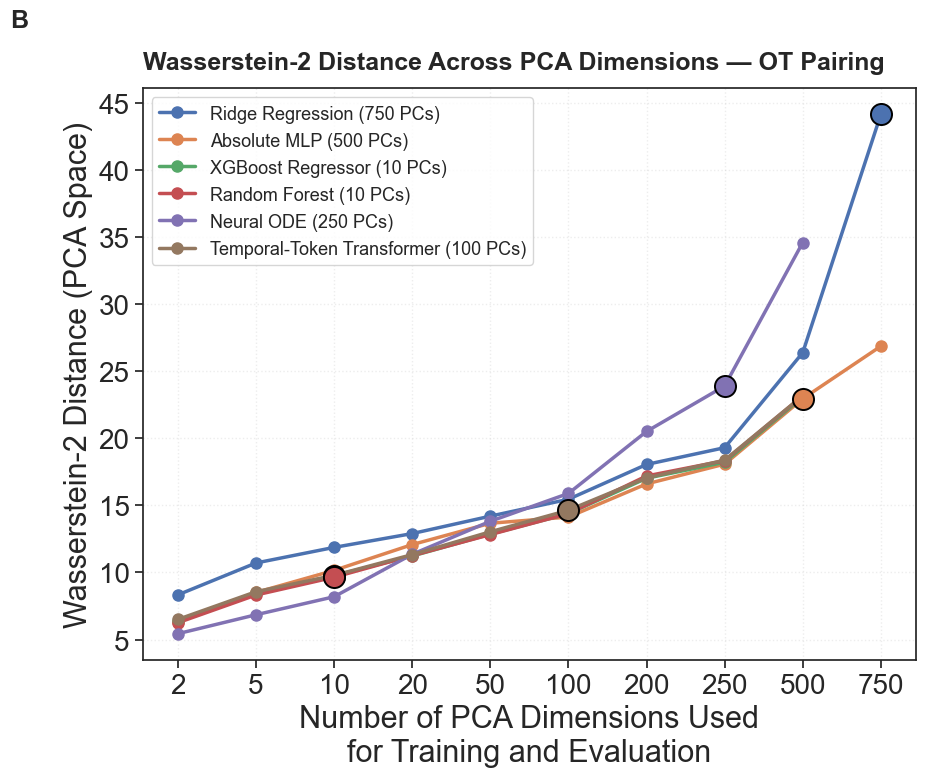

In [45]:
# =========================================================
# FIGURE B — WASSERSTEIN-2 VS PCA DIMENSIONS
# Circular markers instead of diamonds
# =========================================================

fig, ax = plt.subplots(figsize=(12, 8))

dimension_to_x = {
    pc: index for index, pc in enumerate(candidate_pc_dimensions)
}

for model_name in model_order:
    model_data = df_ot_pca_wasserstein.loc[
        df_ot_pca_wasserstein["Model"] == model_name
    ].sort_values("PCs")

    x_positions = [
        dimension_to_x[pc] for pc in model_data["PCs"]
    ]

    line, = ax.plot(
        x_positions,
        model_data["Wasserstein_2"],
        marker="o",
        linewidth=2.5,
        markersize=8,
        label=f"{model_name} ({model_pca_dims[model_name]} PCs)"
    )

    # Highlight originally selected PCA dimension with a larger dot
    selected_pc = model_pca_dims[model_name]

    selected_row = model_data.loc[
        model_data["PCs"] == selected_pc
    ].iloc[0]

    ax.scatter(
        dimension_to_x[selected_pc],
        selected_row["Wasserstein_2"],
        s=230,
        marker="o",
        color=line.get_color(),
        edgecolors="black",
        linewidths=1.4,
        zorder=6
    )

ax.set_title(
    "Wasserstein-2 Distance Across PCA Dimensions — OT Pairing",
    fontsize=B_TITLE_SIZE,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.set_xlabel(
    "Number of PCA Dimensions Used\nfor Training and Evaluation",
    fontsize=B_AXIS_LABEL_SIZE
)

ax.set_ylabel(
    "Wasserstein-2 Distance (PCA Space)",
    fontsize=B_AXIS_LABEL_SIZE
)

ax.set_xticks(np.arange(len(candidate_pc_dimensions)))
ax.set_xticklabels(candidate_pc_dimensions, fontsize=B_TICK_SIZE)
ax.tick_params(axis="y", which="major", labelsize=B_TICK_SIZE)
ax.grid(True, linestyle=":", alpha=0.35)

ax.legend(
    loc="upper left",
    fontsize=B_LEGEND_SIZE,
    frameon=True,
    borderaxespad=0.5
)

fig.text(
    0.01, 0.99, "B",
    fontsize=B_FIGURE_LABEL_SIZE,
    fontweight="bold",
    va="top",
    ha="left"
)
plt.tight_layout(rect=[0.04, 0.02, 0.78, 0.96])

plt.savefig(
    "Figure_B_OT_PCA_Wasserstein2_Sweep.png",
    dpi=SAVE_DPI,
    bbox_inches="tight"
)

plt.show()

In [1]:
# =========================================================
# FIGURE A — OT PC1-PC2 CELL DISTRIBUTIONS
# =========================================================

plot_distribution_figure(
    predictions=ot_predictions,
    title="Actual vs Predicted Day-7 Cell Distributions — OT Pairing",
    filename="Figure_A_OT_PC1_PC2_Cell_Distributions.png",
    figure_label="A"
)

NameError: name 'plot_distribution_figure' is not defined

--- Final Publication Figures: Model-Specific PCA Heterogeneity Analysis ---
Actual Day-7 PCA shape: (1407, 750)
Ridge Regression             | PCs=750 | OT=(201, 750) | Random=(201, 750)
Absolute MLP                 | PCs=500 | OT=(201, 500) | Random=(201, 500)
XGBoost Regressor            | PCs= 10 | OT=(201, 10) | Random=(201, 10)
Random Forest                | PCs= 10 | OT=(201, 10) | Random=(201, 10)
Neural ODE                   | PCs=250 | OT=(201, 250) | Random=(201, 250)
Temporal-Token Transformer   | PCs=100 | OT=(201, 100) | Random=(201, 100)
All model-specific prediction arrays verified.
Saved: Figure_A_OT_PC1_PC2_Cell_Distributions.png


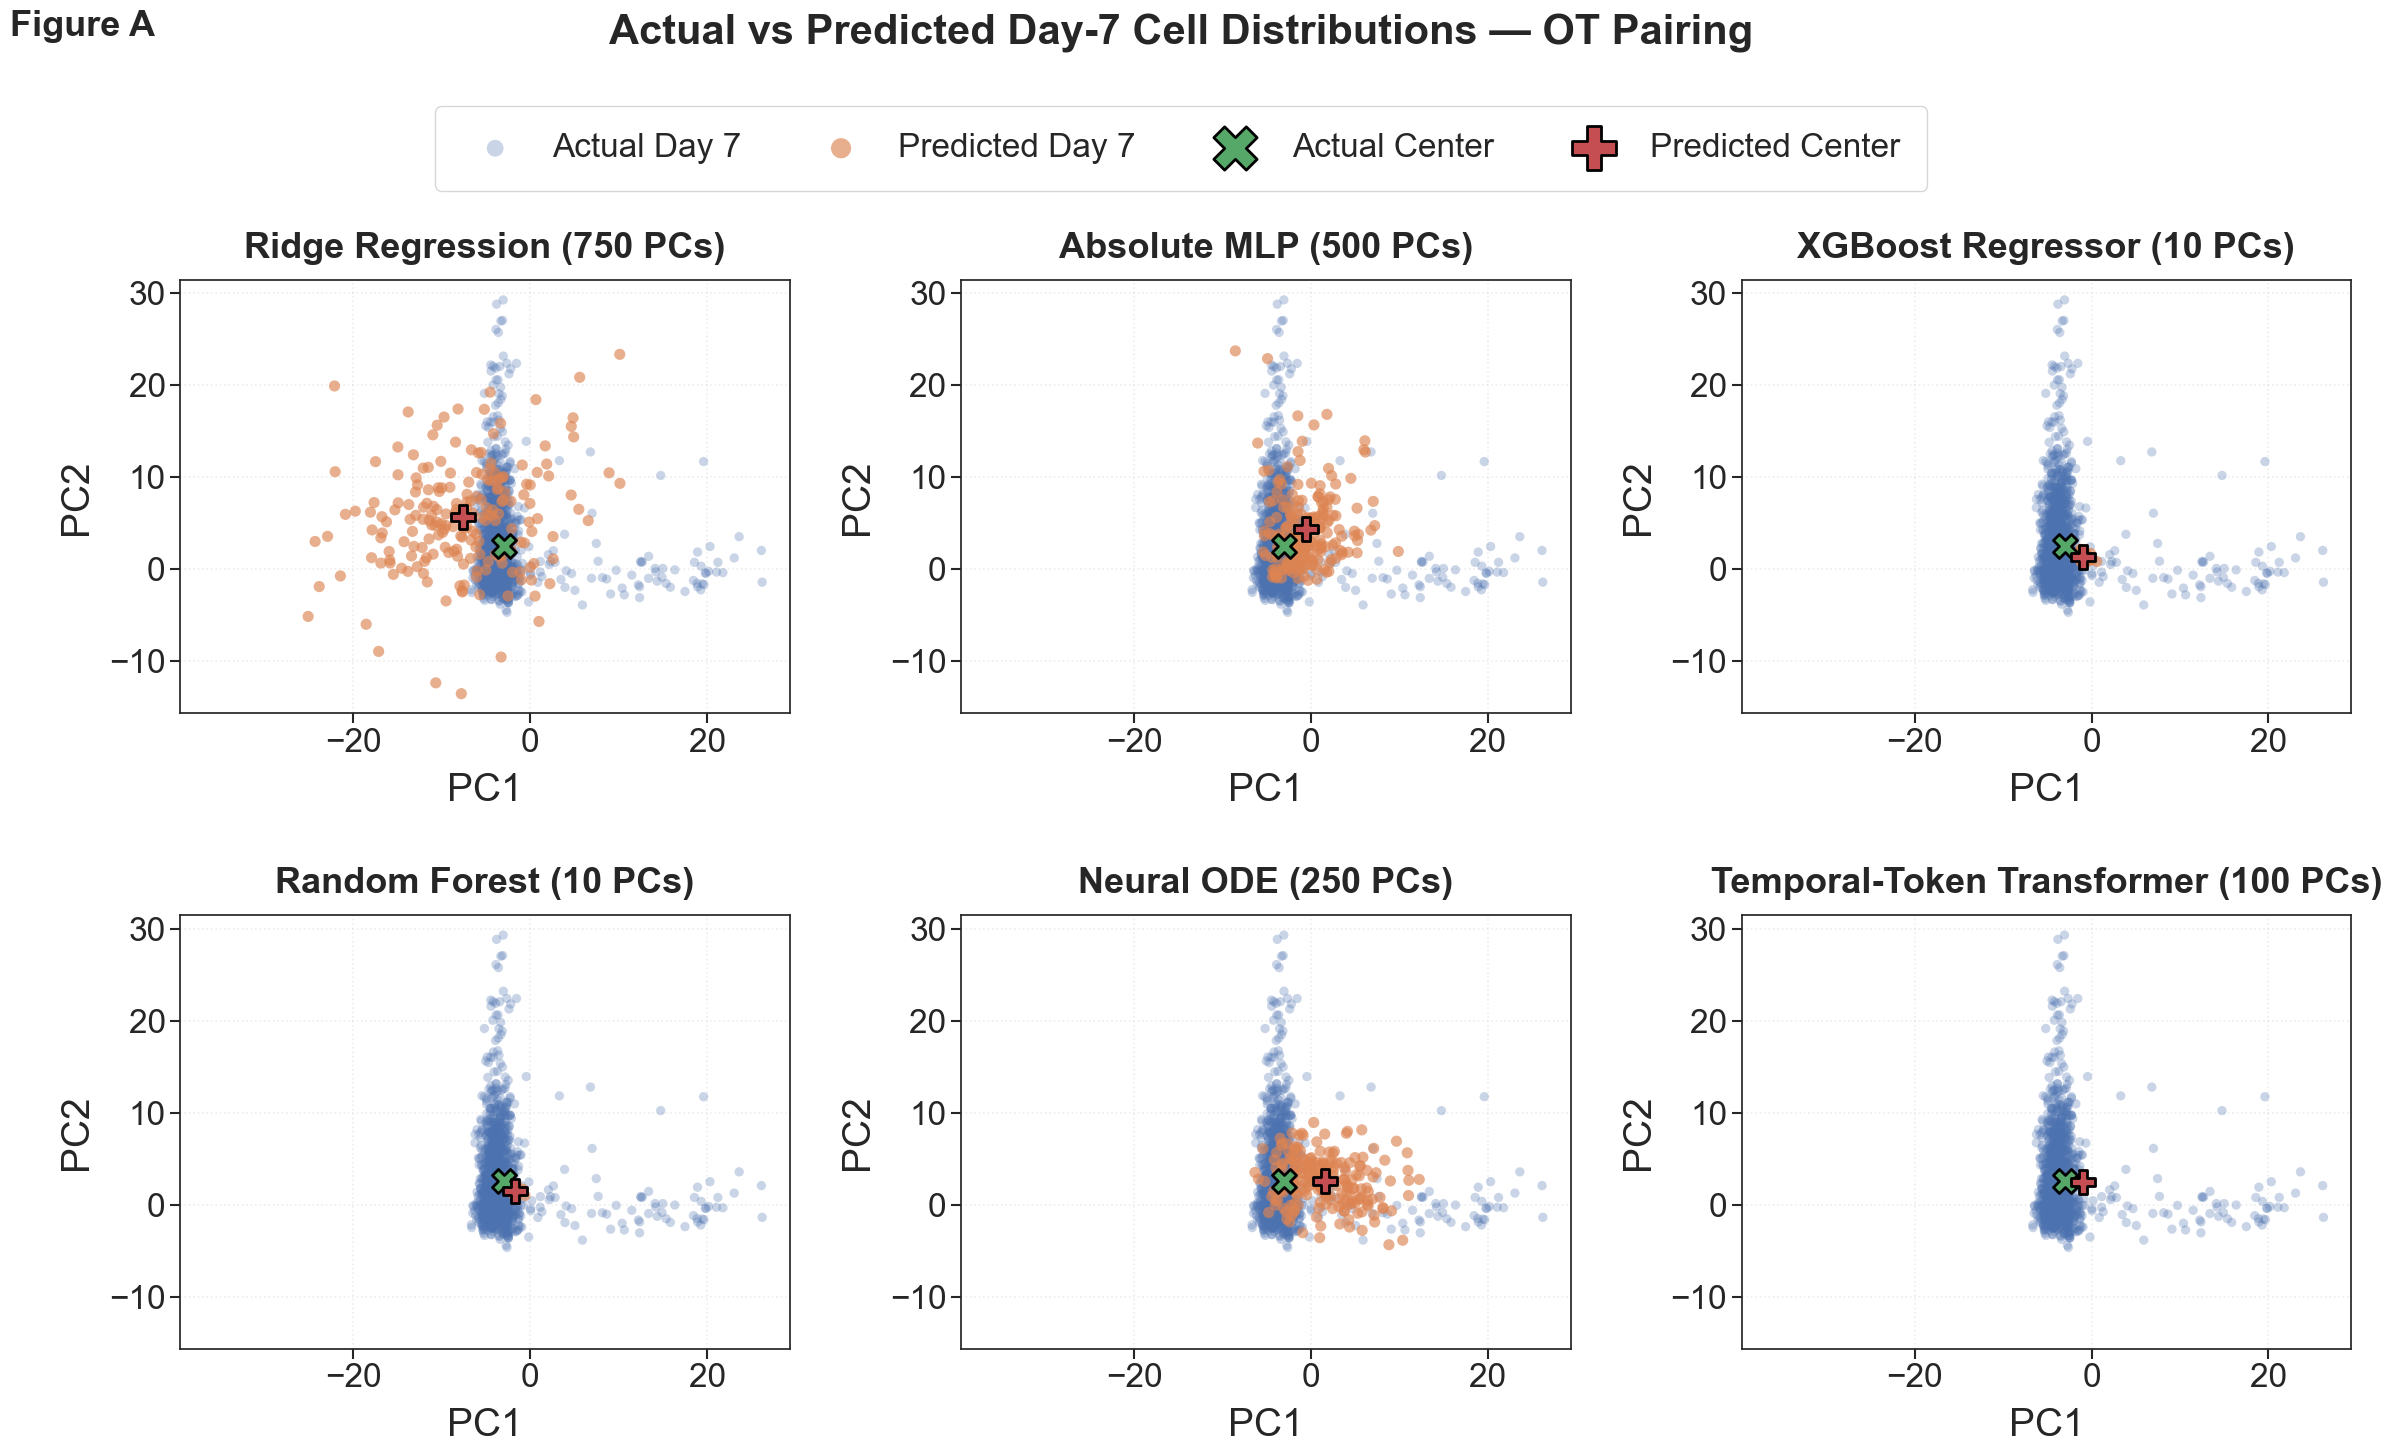

Saved: Capped_Random_PC1_PC2_Cell_Distributions.png


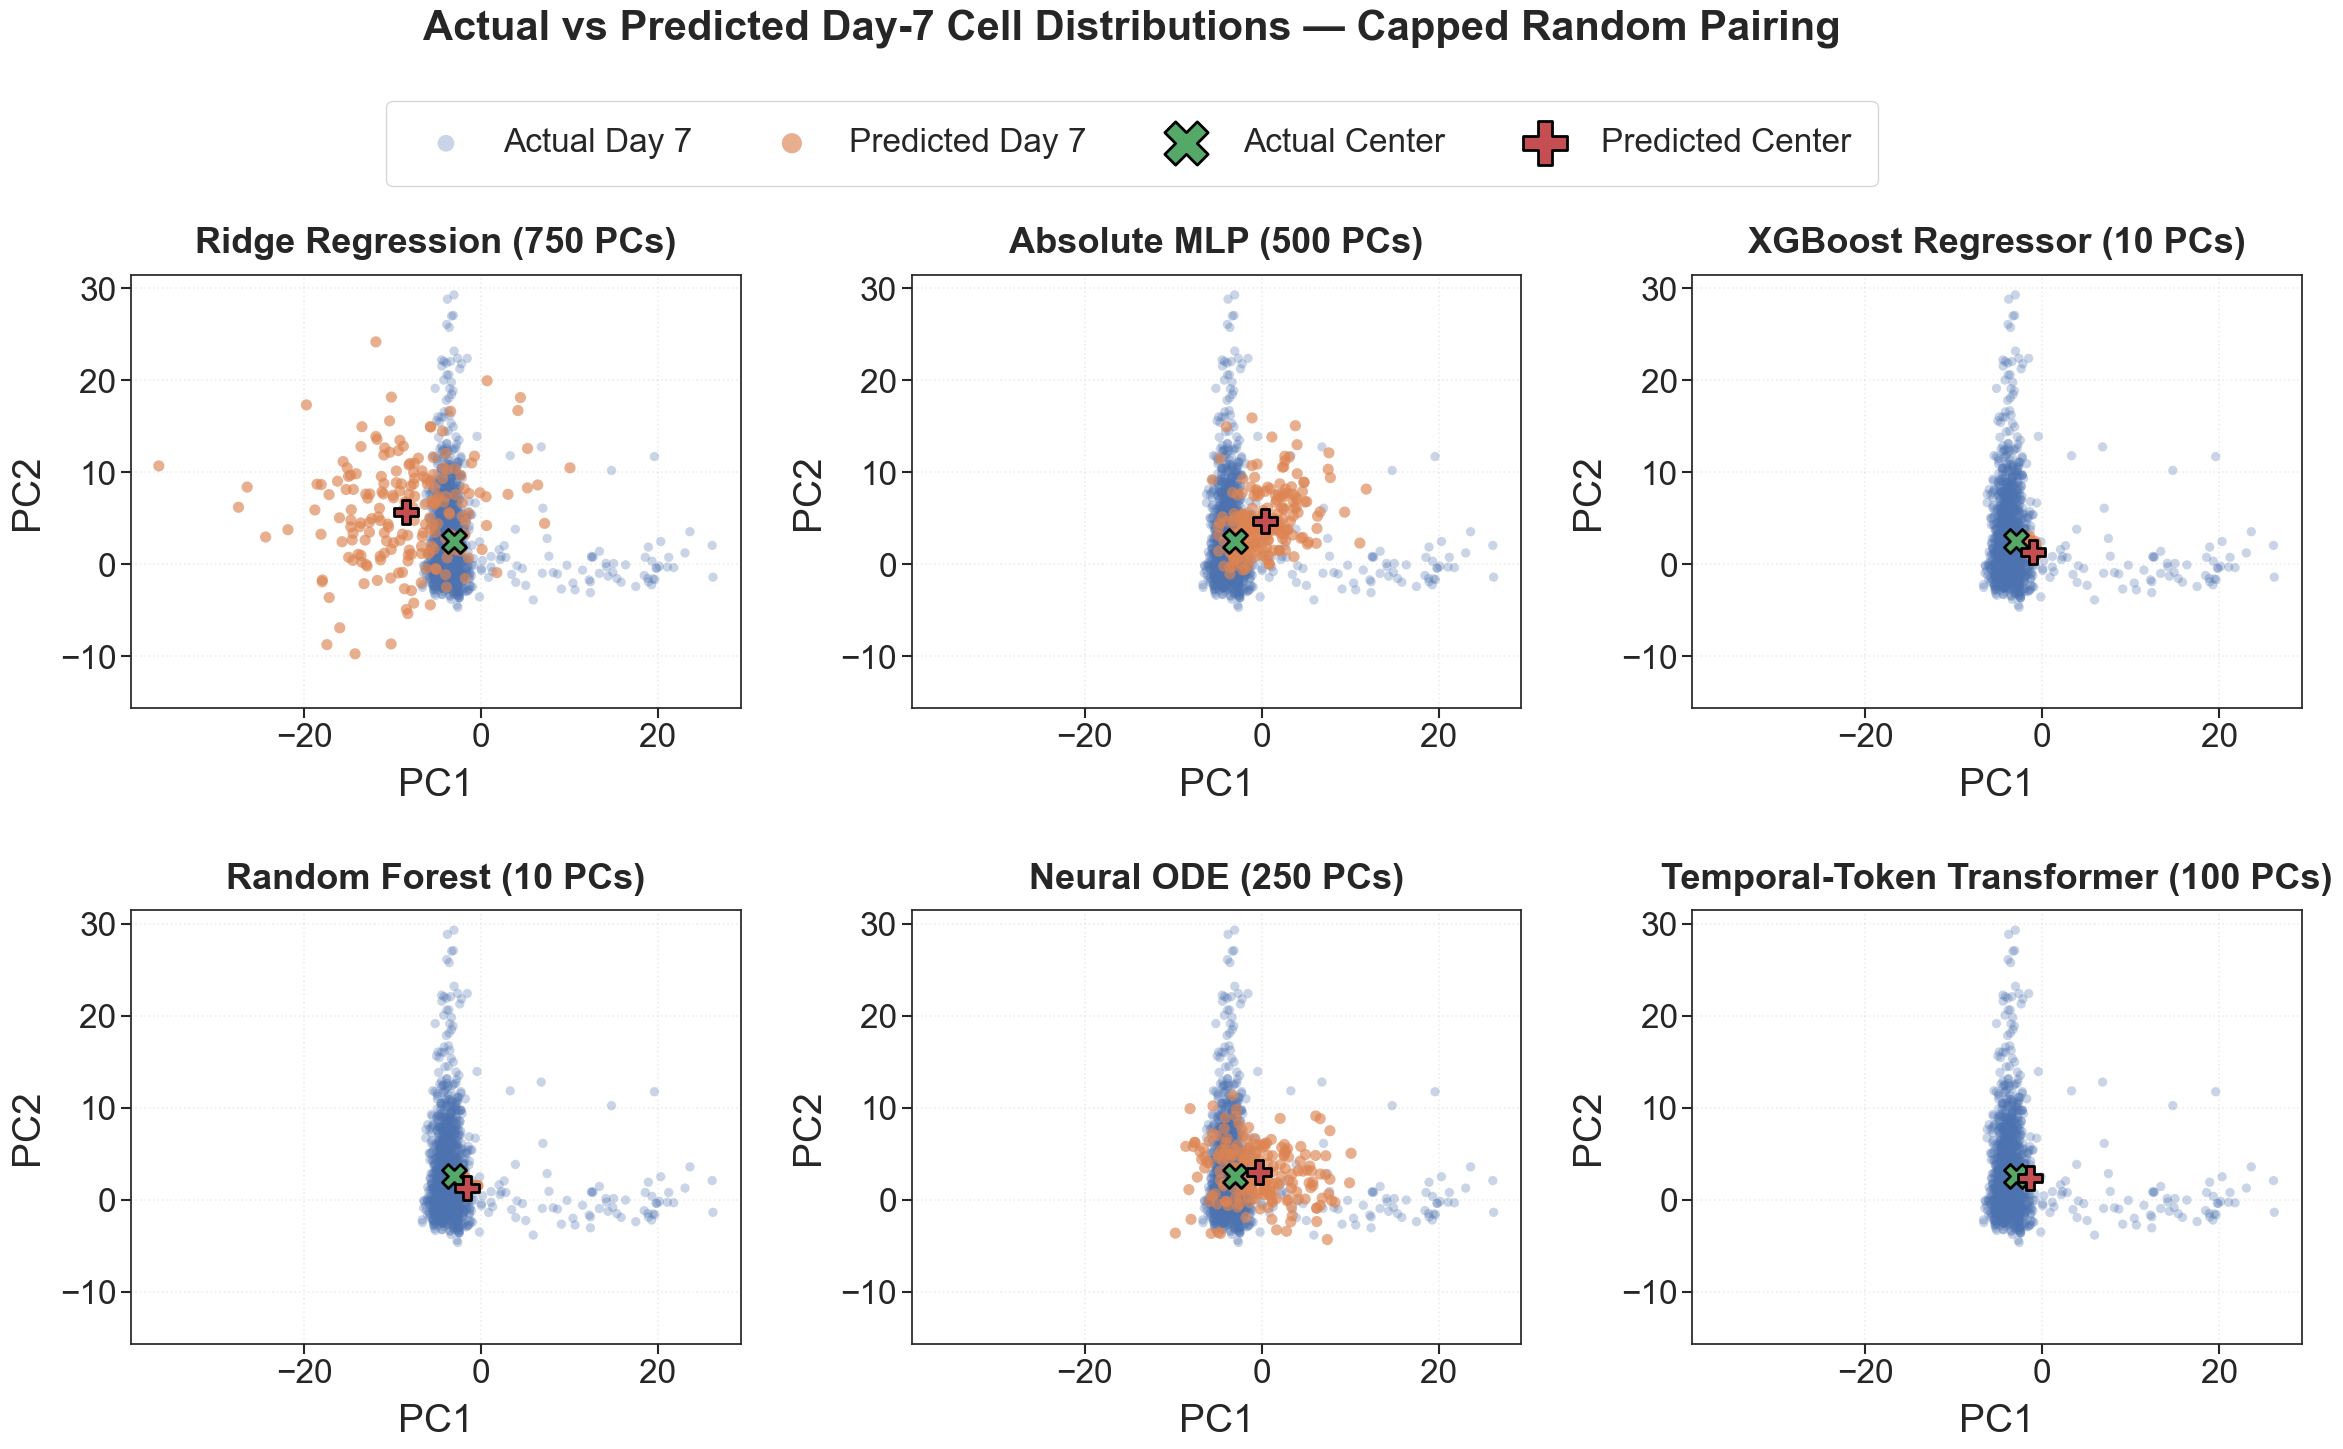


Model-specific latent variance calculations complete.
Ridge Regression             | maximum evaluated PCs = 750
Absolute MLP                 | maximum evaluated PCs = 500
XGBoost Regressor            | maximum evaluated PCs = 10
Random Forest                | maximum evaluated PCs = 10
Neural ODE                   | maximum evaluated PCs = 250
Temporal-Token Transformer   | maximum evaluated PCs = 100
Saved: Figure_B_OT_PCA_Variance_Preservation.png


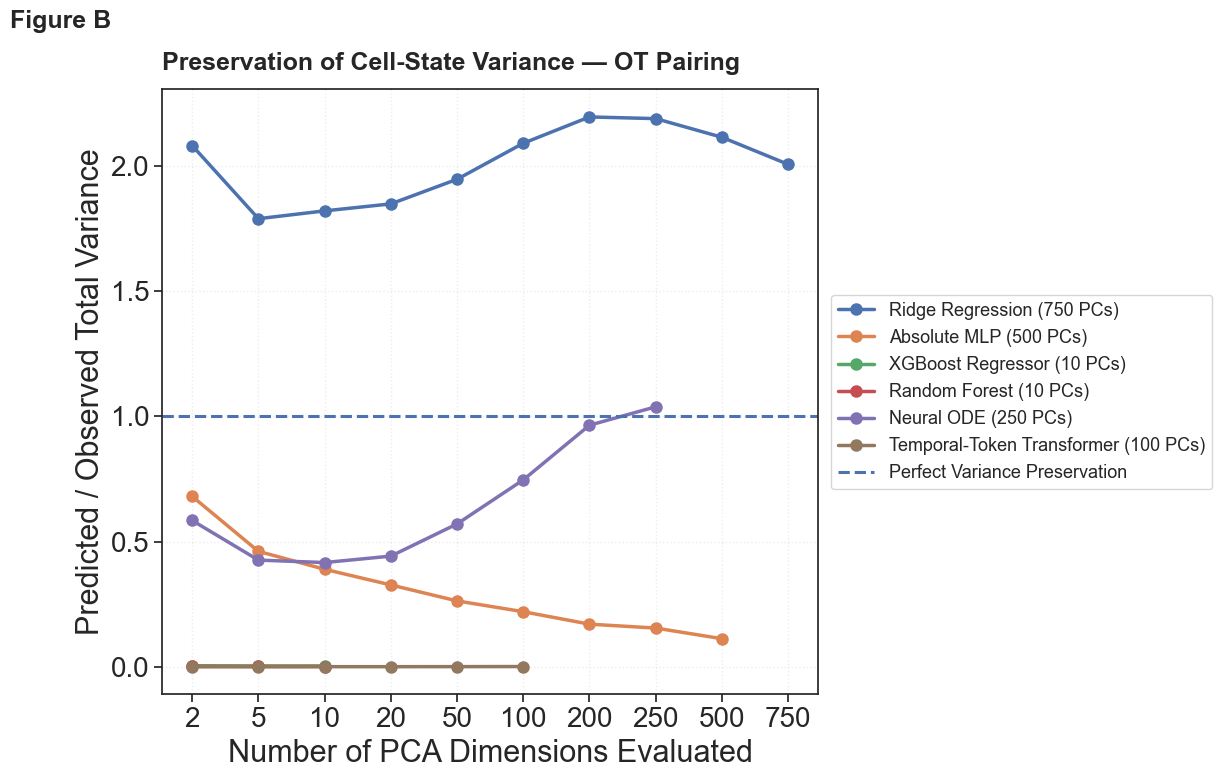

Saved: Capped_Random_PCA_Variance_Preservation.png


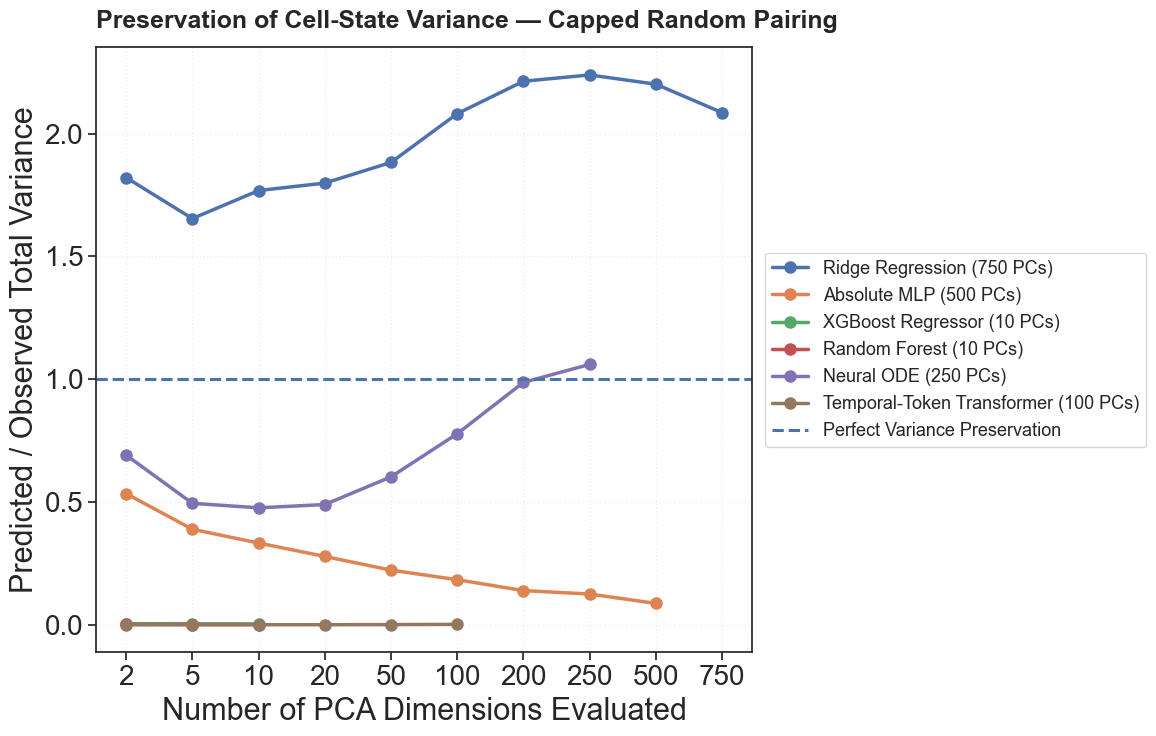


FINAL LATENT VARIANCE PRESERVATION AT EACH MODEL'S SELECTED PCA DIMENSION
Ridge Regression             | PCs=750 | OT=2.0062 | Random=2.0848
Absolute MLP                 | PCs=500 | OT=0.1121 | Random=0.0870
XGBoost Regressor            | PCs= 10 | OT=0.0033 | Random=0.0037
Random Forest                | PCs= 10 | OT=0.0011 | Random=0.0009
Neural ODE                   | PCs=250 | OT=1.0380 | Random=1.0600
Temporal-Token Transformer   | PCs=100 | OT=0.0009 | Random=0.0016

Saved: final_model_specific_latent_variance.csv

✔ Figure A = final OT PC1-PC2 qualitative distributions
✔ Figure B = final model-specific OT latent variance preservation
✔ OT figures retain Figure A and Figure B labels
✔ Capped-random versions contain no figure letters
✔ OT and random PC1-PC2 figures use identical axis limits
✔ All models use the same common PCA coordinate system
✔ Each model is evaluated only across PCs it actually predicts
✔ No zero-padded PCs are counted as predicted latent variance
✔ PCA dimensi

In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# print("--- Final Publication Figures: Model-Specific PCA Heterogeneity Analysis ---")


# # =========================================================
# # 1. PUBLICATION FORMATTING
# # =========================================================

# plt.rcParams["font.sans-serif"] = "Arial"
# plt.rcParams["font.family"] = "sans-serif"

# A_MAIN_TITLE_SIZE = 30
# A_PANEL_TITLE_SIZE = 26
# A_AXIS_LABEL_SIZE = 28
# A_TICK_SIZE = 24
# A_LEGEND_SIZE = 24
# A_FIGURE_LABEL_SIZE = 26

# B_TITLE_SIZE = 18
# B_AXIS_LABEL_SIZE = 22
# B_TICK_SIZE = 20
# B_LEGEND_SIZE = 13
# B_FIGURE_LABEL_SIZE = 18

# SAVE_DPI = 300


# # =========================================================
# # 2. VERIFY REQUIRED DATA
# # =========================================================

# actual_day7_pca = np.asarray(X_day7_pca, dtype=np.float64)

# ot_predictions = {
#     "Ridge Regression": np.asarray(pred_latent_ridge_ot, dtype=np.float64),
#     "Absolute MLP": np.asarray(pred_latent_mlp_ot, dtype=np.float64),
#     "XGBoost Regressor": np.asarray(pred_latent_xgb_ot, dtype=np.float64),
#     "Random Forest": np.asarray(pred_latent_rf_ot, dtype=np.float64),
#     "Neural ODE": np.asarray(pred_latent_ode_ot, dtype=np.float64),
#     "Temporal-Token Transformer": np.asarray(pred_latent_trans_ot, dtype=np.float64)
# }

# random_predictions = {
#     "Ridge Regression": np.asarray(pred_latent_ridge_random, dtype=np.float64),
#     "Absolute MLP": np.asarray(pred_latent_mlp_random, dtype=np.float64),
#     "XGBoost Regressor": np.asarray(pred_latent_xgb_random, dtype=np.float64),
#     "Random Forest": np.asarray(pred_latent_rf_random, dtype=np.float64),
#     "Neural ODE": np.asarray(pred_latent_ode_random, dtype=np.float64),
#     "Temporal-Token Transformer": np.asarray(pred_latent_trans_random, dtype=np.float64)
# }

# assert actual_day7_pca.shape == (1407, max_pc_count)

# for model_name, prediction in ot_predictions.items():
#     pc_count = model_pca_dims[model_name]
#     assert prediction.shape == (201, pc_count)
#     assert np.isfinite(prediction).all()

# for model_name, prediction in random_predictions.items():
#     pc_count = model_pca_dims[model_name]
#     assert prediction.shape == (201, pc_count)
#     assert np.isfinite(prediction).all()

# print("Actual Day-7 PCA shape:", actual_day7_pca.shape)

# for model_name in ot_predictions:
#     print(f"{model_name:28s} | PCs={model_pca_dims[model_name]:3d} | OT={ot_predictions[model_name].shape} | Random={random_predictions[model_name].shape}")

# print("All model-specific prediction arrays verified.")


# # =========================================================
# # 3. COMMON PC1-PC2 AXIS LIMITS
# # =========================================================

# all_pc2_arrays = [actual_day7_pca[:, :2]]

# for prediction in ot_predictions.values():
#     all_pc2_arrays.append(prediction[:, :2])

# for prediction in random_predictions.values():
#     all_pc2_arrays.append(prediction[:, :2])

# all_pc2_points = np.vstack(all_pc2_arrays)

# x_min = np.min(all_pc2_points[:, 0])
# x_max = np.max(all_pc2_points[:, 0])
# y_min = np.min(all_pc2_points[:, 1])
# y_max = np.max(all_pc2_points[:, 1])

# x_padding = 0.05 * (x_max - x_min)
# y_padding = 0.05 * (y_max - y_min)

# x_limits = (x_min - x_padding, x_max + x_padding)
# y_limits = (y_min - y_padding, y_max + y_padding)

# actual_center_2d = np.mean(actual_day7_pca[:, :2], axis=0)


# # =========================================================
# # 4. SIX-PANEL PC1-PC2 DISTRIBUTION FIGURE
# # =========================================================

# def plot_distribution_figure(predictions, title, filename, figure_label=None):
#     fig, axes = plt.subplots(2, 3, figsize=(24, 15))
#     axes = axes.flatten()

#     for ax, (model_name, prediction) in zip(axes, predictions.items()):
#         predicted_center_2d = np.mean(prediction[:, :2], axis=0)

#         ax.scatter(actual_day7_pca[:, 0], actual_day7_pca[:, 1], s=45, alpha=0.30, edgecolors="none", label="Actual Day 7")
#         ax.scatter(prediction[:, 0], prediction[:, 1], s=65, alpha=0.65, edgecolors="none", label="Predicted Day 7")

#         ax.scatter(actual_center_2d[0], actual_center_2d[1], s=300, marker="X", edgecolors="black", linewidths=2.0, label="Actual Center", zorder=5)
#         ax.scatter(predicted_center_2d[0], predicted_center_2d[1], s=300, marker="P", edgecolors="black", linewidths=2.0, label="Predicted Center", zorder=5)

#         ax.set_xlim(x_limits)
#         ax.set_ylim(y_limits)

#         ax.set_title(f"{model_name} ({model_pca_dims[model_name]} PCs)", fontsize=A_PANEL_TITLE_SIZE, fontweight="bold", pad=16)
#         ax.set_xlabel("PC1", fontsize=A_AXIS_LABEL_SIZE, labelpad=10)
#         ax.set_ylabel("PC2", fontsize=A_AXIS_LABEL_SIZE, labelpad=10)
#         ax.tick_params(axis="both", which="major", labelsize=A_TICK_SIZE, width=1.5, length=7)
#         ax.grid(True, linestyle=":", linewidth=1.2, alpha=0.35)

#     handles, labels = axes[0].get_legend_handles_labels()

#     fig.legend(
#         handles,
#         labels,
#         loc="upper center",
#         bbox_to_anchor=(0.5, 0.935),
#         ncol=4,
#         fontsize=A_LEGEND_SIZE,
#         markerscale=1.8,
#         frameon=True,
#         borderpad=0.8,
#         labelspacing=0.8,
#         handletextpad=0.7,
#         columnspacing=2.0
#     )

#     fig.suptitle(title, fontsize=A_MAIN_TITLE_SIZE, fontweight="bold", y=0.985)

#     if figure_label is not None:
#         fig.text(0.012, 0.988, figure_label, fontsize=A_FIGURE_LABEL_SIZE, fontweight="bold", va="top", ha="left")

#     plt.tight_layout(rect=[0.025, 0.02, 0.995, 0.89], h_pad=3.5, w_pad=3.0)
#     plt.savefig(filename, dpi=SAVE_DPI, bbox_inches="tight")
#     print("Saved:", filename)
#     plt.show()


# # =========================================================
# # 5. FIGURE A — OT PC1-PC2 DISTRIBUTIONS
# # =========================================================

# plot_distribution_figure(
#     predictions=ot_predictions,
#     title="Actual vs Predicted Day-7 Cell Distributions — OT Pairing",
#     filename="Figure_A_OT_PC1_PC2_Cell_Distributions.png",
#     figure_label="Figure A"
# )


# # =========================================================
# # 6. CAPPED-RANDOM PC1-PC2 DISTRIBUTIONS
# # =========================================================

# plot_distribution_figure(
#     predictions=random_predictions,
#     title="Actual vs Predicted Day-7 Cell Distributions — Capped Random Pairing",
#     filename="Capped_Random_PC1_PC2_Cell_Distributions.png",
#     figure_label=None
# )


# # =========================================================
# # 7. RECOMPUTE MODEL-SPECIFIC LATENT VARIANCE
# # =========================================================

# candidate_pc_dimensions = [2, 5, 10, 20, 50, 100, 200, 250, 500, 750]

# variance_records = []

# for pairing_name, predictions in [("OT", ot_predictions), ("Capped Random", random_predictions)]:
#     for model_name, prediction in predictions.items():
#         model_pc_count = model_pca_dims[model_name]
#         valid_dimensions = [k for k in candidate_pc_dimensions if k <= model_pc_count]

#         for k in valid_dimensions:
#             actual_total_variance = np.var(actual_day7_pca[:, :k], axis=0, ddof=1).sum()
#             predicted_total_variance = np.var(prediction[:, :k], axis=0, ddof=1).sum()
#             variance_ratio = predicted_total_variance / actual_total_variance

#             variance_records.append({
#                 "Model": model_name,
#                 "Pairing": pairing_name,
#                 "PCs": k,
#                 "Model_PCA_Dim": model_pc_count,
#                 "Observed_Total_Variance": actual_total_variance,
#                 "Predicted_Total_Variance": predicted_total_variance,
#                 "Variance_Ratio": variance_ratio
#             })

# df_latent_heterogeneity_final = pd.DataFrame(variance_records)

# print("\nModel-specific latent variance calculations complete.")

# for model_name in ot_predictions:
#     model_rows = df_latent_heterogeneity_final[
#         (df_latent_heterogeneity_final["Model"] == model_name) &
#         (df_latent_heterogeneity_final["Pairing"] == "OT")
#     ]
#     print(f"{model_name:28s} | maximum evaluated PCs = {model_rows['PCs'].max()}")


# # =========================================================
# # 8. SPLIT OT / RANDOM VARIANCE DATA
# # =========================================================

# ot_variance_data = df_latent_heterogeneity_final[df_latent_heterogeneity_final["Pairing"] == "OT"].copy()
# random_variance_data = df_latent_heterogeneity_final[df_latent_heterogeneity_final["Pairing"] == "Capped Random"].copy()


# # =========================================================
# # 9. VARIANCE-PRESERVATION FIGURE
# #
# # Legend is outside the plotting region so it cannot obscure
# # any model curves.
# # =========================================================

# def plot_variance_figure(variance_data, predictions, title, filename, figure_label=None):
#     fig, ax = plt.subplots(figsize=(16, 8))

#     plotted_dimensions = sorted(variance_data["PCs"].unique())
#     dimension_to_x = {pc: i for i, pc in enumerate(plotted_dimensions)}

#     for model_name in predictions.keys():
#         model_data = variance_data[variance_data["Model"] == model_name].sort_values("PCs")
#         x_positions = [dimension_to_x[pc] for pc in model_data["PCs"]]

#         ax.plot(
#             x_positions,
#             model_data["Variance_Ratio"],
#             marker="o",
#             linewidth=2.5,
#             markersize=8,
#             label=f"{model_name} ({model_pca_dims[model_name]} PCs)"
#         )

#     ax.axhline(1.0, linestyle="--", linewidth=2.2, label="Perfect Variance Preservation")

#     ax.set_title(title, fontsize=B_TITLE_SIZE, fontweight="bold", loc="left", pad=14)
#     ax.set_xlabel("Number of PCA Dimensions Evaluated", fontsize=B_AXIS_LABEL_SIZE)
#     ax.set_ylabel("Predicted / Observed Total Variance", fontsize=B_AXIS_LABEL_SIZE)

#     ax.set_xticks(np.arange(len(plotted_dimensions)))
#     ax.set_xticklabels(plotted_dimensions, fontsize=B_TICK_SIZE)
#     ax.tick_params(axis="y", which="major", labelsize=B_TICK_SIZE)
#     ax.grid(True, linestyle=":", alpha=0.35)

#     ax.legend(
#         loc="center left",
#         bbox_to_anchor=(1.02, 0.5),
#         fontsize=B_LEGEND_SIZE,
#         frameon=True,
#         borderaxespad=0.0
#     )

#     if figure_label is not None:
#         fig.text(0.01, 0.99, figure_label, fontsize=B_FIGURE_LABEL_SIZE, fontweight="bold", va="top", ha="left")

#     plt.tight_layout(rect=[0.04, 0.02, 0.78, 0.96])
#     plt.savefig(filename, dpi=SAVE_DPI, bbox_inches="tight")
#     print("Saved:", filename)
#     plt.show()


# # =========================================================
# # 10. FIGURE B — OT LATENT VARIANCE PRESERVATION
# # =========================================================

# plot_variance_figure(
#     variance_data=ot_variance_data,
#     predictions=ot_predictions,
#     title="Preservation of Cell-State Variance — OT Pairing",
#     filename="Figure_B_OT_PCA_Variance_Preservation.png",
#     figure_label="Figure B"
# )


# # =========================================================
# # 11. CAPPED-RANDOM LATENT VARIANCE PRESERVATION
# # =========================================================

# plot_variance_figure(
#     variance_data=random_variance_data,
#     predictions=random_predictions,
#     title="Preservation of Cell-State Variance — Capped Random Pairing",
#     filename="Capped_Random_PCA_Variance_Preservation.png",
#     figure_label=None
# )


# # =========================================================
# # 12. FINAL MODEL-ENDPOINT VARIANCE RATIOS
# # =========================================================

# print("\n" + "=" * 90)
# print("FINAL LATENT VARIANCE PRESERVATION AT EACH MODEL'S SELECTED PCA DIMENSION")
# print("=" * 90)

# for model_name in ot_predictions:
#     model_pc_count = model_pca_dims[model_name]

#     ot_row = ot_variance_data[
#         (ot_variance_data["Model"] == model_name) &
#         (ot_variance_data["PCs"] == model_pc_count)
#     ]

#     random_row = random_variance_data[
#         (random_variance_data["Model"] == model_name) &
#         (random_variance_data["PCs"] == model_pc_count)
#     ]

#     if len(ot_row) == 1 and len(random_row) == 1:
#         ot_ratio = ot_row.iloc[0]["Variance_Ratio"]
#         random_ratio = random_row.iloc[0]["Variance_Ratio"]
#         print(f"{model_name:28s} | PCs={model_pc_count:3d} | OT={ot_ratio:.4f} | Random={random_ratio:.4f}")


# # =========================================================
# # 13. SAVE FINAL LATENT VARIANCE TABLE
# # =========================================================

# df_latent_heterogeneity_final.to_csv("final_model_specific_latent_variance.csv", index=False)
# print("\nSaved: final_model_specific_latent_variance.csv")


# # =========================================================
# # 14. FINAL STATUS
# # =========================================================

# print("\n✔ Figure A = final OT PC1-PC2 qualitative distributions")
# print("✔ Figure B = final model-specific OT latent variance preservation")
# print("✔ OT figures retain Figure A and Figure B labels")
# print("✔ Capped-random versions contain no figure letters")
# print("✔ OT and random PC1-PC2 figures use identical axis limits")
# print("✔ All models use the same common PCA coordinate system")
# print("✔ Each model is evaluated only across PCs it actually predicts")
# print("✔ No zero-padded PCs are counted as predicted latent variance")
# print("✔ PCA dimensions use equally spaced x-axis positions")
# print("✔ Figure B legend moved completely outside plotting region")
# print("✔ Ridge evaluated through 750 PCs")
# print("✔ MLP evaluated through 500 PCs")
# print("✔ XGBoost evaluated through 10 PCs")
# print("✔ Random Forest evaluated through 10 PCs")
# print("✔ Neural ODE evaluated through 250 PCs")
# print("✔ Transformer evaluated through 100 PCs")
# print("✔ Six-panel figures = 24 × 15 inches")
# print("✔ Variance figures = 16 × 8 inches")
# print("✔ All figures saved at 300 DPI")

--- Higher-Dimensional PCA Heterogeneity Analysis ---
PC dimensions evaluated: [2, 5, 10, 20, 50, 100, 200, 500]

HIGHER-DIMENSIONAL PCA HETEROGENEITY RESULTS
                     Model       Pairing  PCs  True_Total_Variance  Predicted_Total_Variance  Variance_Ratio  Total_Variance_Error  True_Mean_Distance  Predicted_Mean_Distance  Mean_Distance_Error  Center_Error  Covariance_Error  Relative_Covariance_Error
          Ridge Regression            OT    2              37.8960                   16.3730          0.4321               21.5230              4.4401                   3.4632               0.9769        5.5235           18.0667                     0.6608
              Absolute MLP            OT    2              37.8960                   22.1249          0.5838               15.7711              4.4401                   4.0864               0.3537        3.0815           11.6062                     0.4245
         XGBoost Regressor            OT    2              37.8960       

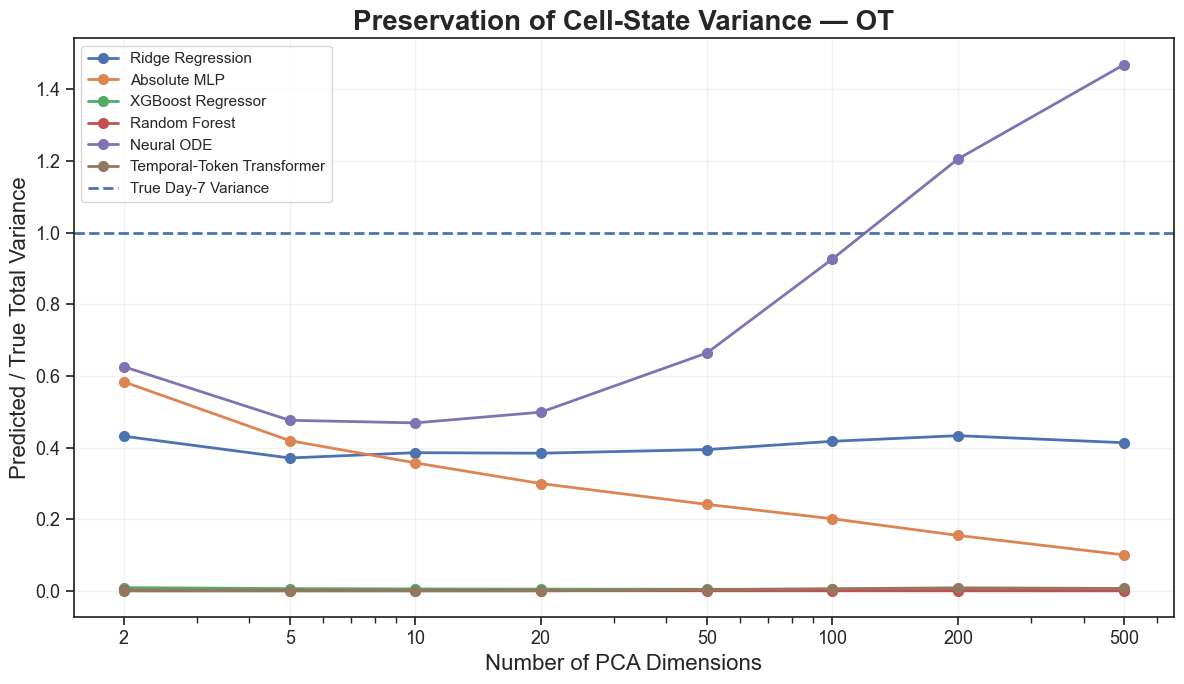

Saved: publication_latent_variance_ratio_random.png


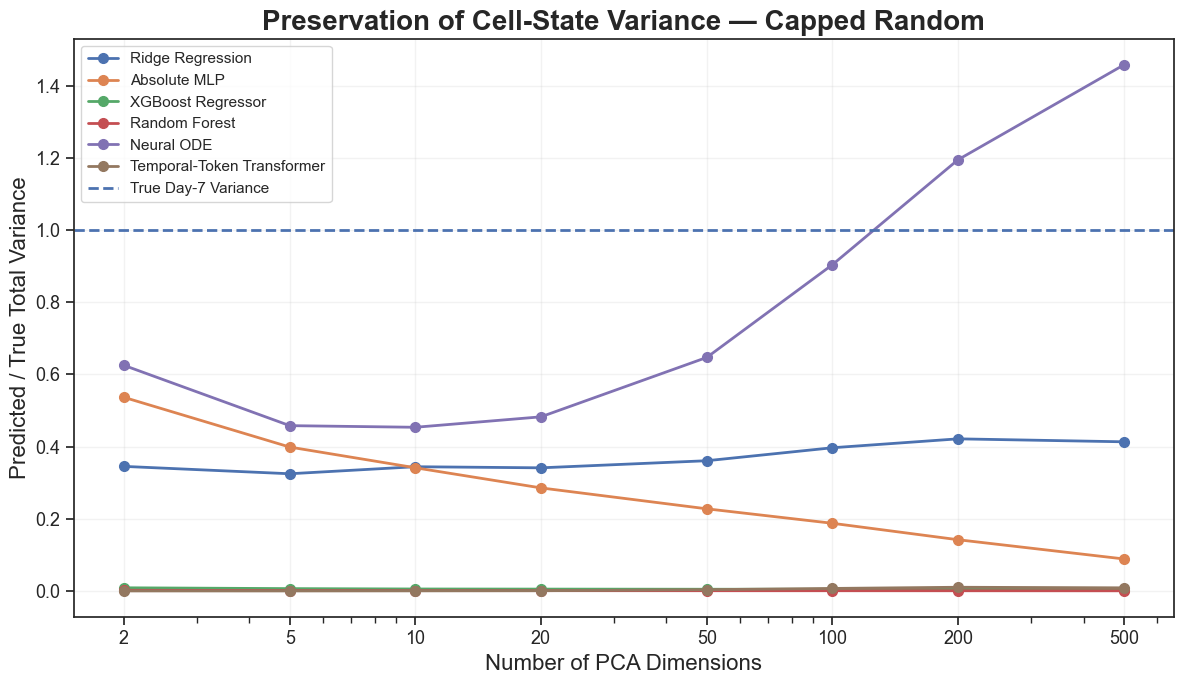

Saved: publication_latent_distance_error_ot.png


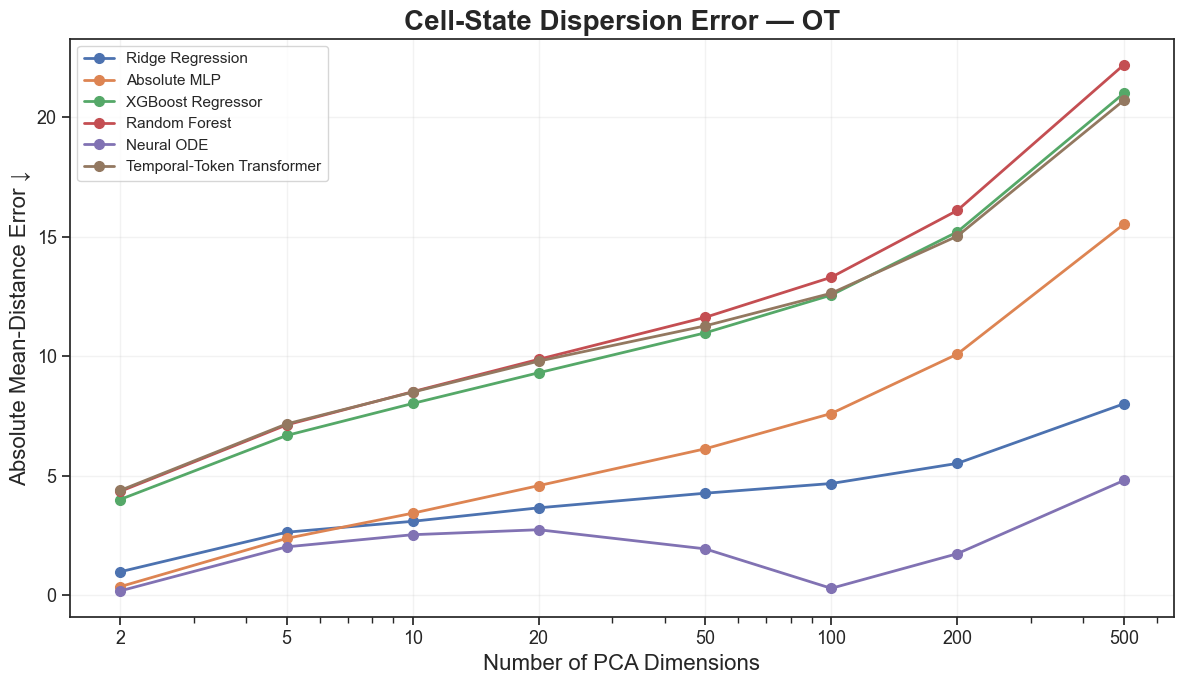

Saved: publication_latent_distance_error_random.png


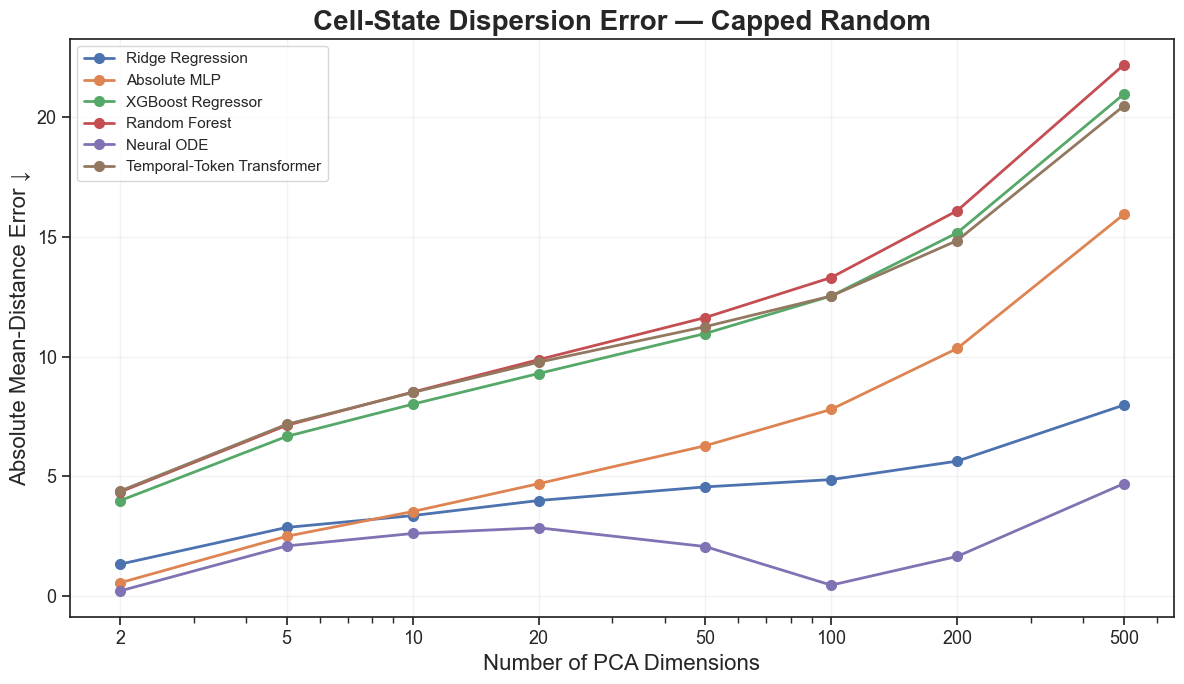


Saved: higher_dimensional_pca_heterogeneity.csv
✔ No models retrained
✔ Day 7 remains evaluation-only
✔ All distributions compared in the same training-fitted PCA space
✔ Heterogeneity evaluated from 2 through 500 PCA dimensions


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- Higher-Dimensional PCA Heterogeneity Analysis ---")

# =========================================================
# 1. SETTINGS
# =========================================================

pc_dimensions = [2, 5, 10, 20, 50, 100, 200, 500]

actual_day7_pca = np.asarray(X_day7_pca, dtype=np.float64)

ot_predictions = {
    "Ridge Regression": np.asarray(pred_latent_ridge_ot, dtype=np.float64),
    "Absolute MLP": np.asarray(pred_latent_mlp_ot, dtype=np.float64),
    "XGBoost Regressor": np.asarray(pred_latent_xgb_ot, dtype=np.float64),
    "Random Forest": np.asarray(pred_latent_rf_ot, dtype=np.float64),
    "Neural ODE": np.asarray(pred_latent_ode_ot, dtype=np.float64),
    "Temporal-Token Transformer": np.asarray(pred_latent_trans_ot, dtype=np.float64)
}

random_predictions = {
    "Ridge Regression": np.asarray(pred_latent_ridge_random, dtype=np.float64),
    "Absolute MLP": np.asarray(pred_latent_mlp_random, dtype=np.float64),
    "XGBoost Regressor": np.asarray(pred_latent_xgb_random, dtype=np.float64),
    "Random Forest": np.asarray(pred_latent_rf_random, dtype=np.float64),
    "Neural ODE": np.asarray(pred_latent_ode_random, dtype=np.float64),
    "Temporal-Token Transformer": np.asarray(pred_latent_trans_random, dtype=np.float64)
}

assert max(pc_dimensions) <= actual_day7_pca.shape[1]

for model_name in ot_predictions:
    assert ot_predictions[model_name].shape[1] >= max(pc_dimensions)
    assert random_predictions[model_name].shape[1] >= max(pc_dimensions)

print("PC dimensions evaluated:", pc_dimensions)


# =========================================================
# 2. DISTRIBUTION METRICS
# =========================================================

def latent_distribution_metrics(X, n_pcs):
    X = np.asarray(X[:, :n_pcs], dtype=np.float64)

    center = np.mean(X, axis=0)
    centered = X - center

    variance_per_pc = np.var(X, axis=0, ddof=1)
    total_variance = np.sum(variance_per_pc)

    distances = np.linalg.norm(centered, axis=1)
    mean_distance = np.mean(distances)

    covariance = np.cov(X, rowvar=False)

    return {
        "Center": center,
        "Variance_Per_PC": variance_per_pc,
        "Total_Variance": total_variance,
        "Mean_Distance": mean_distance,
        "Covariance": covariance
    }


# =========================================================
# 3. COMPARE MODELS ACROSS PCA DIMENSIONS
# =========================================================

records = []

for n_pcs in pc_dimensions:

    true_metrics = latent_distribution_metrics(
        actual_day7_pca,
        n_pcs
    )

    for pairing_name, predictions in [
        ("OT", ot_predictions),
        ("Capped Random", random_predictions)
    ]:

        for model_name, prediction in predictions.items():

            pred_metrics = latent_distribution_metrics(
                prediction,
                n_pcs
            )

            center_error = np.linalg.norm(
                pred_metrics["Center"] -
                true_metrics["Center"]
            )

            mean_distance_error = abs(
                pred_metrics["Mean_Distance"] -
                true_metrics["Mean_Distance"]
            )

            variance_ratio = (
                pred_metrics["Total_Variance"] /
                true_metrics["Total_Variance"]
            )

            total_variance_error = abs(
                pred_metrics["Total_Variance"] -
                true_metrics["Total_Variance"]
            )

            covariance_error = np.linalg.norm(
                pred_metrics["Covariance"] -
                true_metrics["Covariance"],
                ord="fro"
            )

            covariance_relative_error = (
                covariance_error /
                np.linalg.norm(
                    true_metrics["Covariance"],
                    ord="fro"
                )
            )

            records.append({
                "Model": model_name,
                "Pairing": pairing_name,
                "PCs": n_pcs,
                "True_Total_Variance": true_metrics["Total_Variance"],
                "Predicted_Total_Variance": pred_metrics["Total_Variance"],
                "Variance_Ratio": variance_ratio,
                "Total_Variance_Error": total_variance_error,
                "True_Mean_Distance": true_metrics["Mean_Distance"],
                "Predicted_Mean_Distance": pred_metrics["Mean_Distance"],
                "Mean_Distance_Error": mean_distance_error,
                "Center_Error": center_error,
                "Covariance_Error": covariance_error,
                "Relative_Covariance_Error": covariance_relative_error
            })


df_latent_heterogeneity = pd.DataFrame(records)

print("\n" + "=" * 170)
print("HIGHER-DIMENSIONAL PCA HETEROGENEITY RESULTS")
print("=" * 170)

print(
    df_latent_heterogeneity.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("=" * 170)


# =========================================================
# 4. FINAL 500-PC SUMMARY
# =========================================================

df_500 = df_latent_heterogeneity[
    df_latent_heterogeneity["PCs"] == 500
].copy()

print("\n" + "=" * 150)
print("FULL 500-PC LATENT-SPACE SUMMARY")
print("=" * 150)

print(
    df_500[
        [
            "Model",
            "Pairing",
            "Variance_Ratio",
            "Mean_Distance_Error",
            "Center_Error",
            "Relative_Covariance_Error"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("=" * 150)


# =========================================================
# 5. VARIANCE-RATIO FIGURES
#
# 1.0 = SAME TOTAL VARIANCE AS TRUE DAY 7
# <1  = TOO LITTLE VARIANCE / COLLAPSE
# >1  = TOO MUCH VARIANCE
# =========================================================

def plot_variance_ratio(pairing_name, filename):

    subset = df_latent_heterogeneity[
        df_latent_heterogeneity["Pairing"] == pairing_name
    ]

    fig, ax = plt.subplots(figsize=(12, 7))

    for model_name in ot_predictions.keys():

        model_data = subset[
            subset["Model"] == model_name
        ]

        ax.plot(
            model_data["PCs"],
            model_data["Variance_Ratio"],
            marker="o",
            linewidth=2,
            markersize=7,
            label=model_name
        )

    ax.axhline(
        1.0,
        linestyle="--",
        linewidth=2,
        label="True Day-7 Variance"
    )

    ax.set_title(
        f"Preservation of Cell-State Variance — {pairing_name}",
        fontsize=20,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Number of PCA Dimensions",
        fontsize=16
    )

    ax.set_ylabel(
        "Predicted / True Total Variance",
        fontsize=16
    )

    ax.set_xscale("log")

    ax.set_xticks(pc_dimensions)
    ax.set_xticklabels(pc_dimensions)

    ax.tick_params(
        axis="both",
        labelsize=13
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        fontsize=11,
        frameon=True
    )

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    print("Saved:", filename)

    plt.show()


# =========================================================
# 6. OT VARIANCE PRESERVATION
# =========================================================

plot_variance_ratio(
    "OT",
    "publication_latent_variance_ratio_ot.png"
)


# =========================================================
# 7. CAPPED-RANDOM VARIANCE PRESERVATION
# =========================================================

plot_variance_ratio(
    "Capped Random",
    "publication_latent_variance_ratio_random.png"
)


# =========================================================
# 8. MEAN-DISTANCE ERROR FIGURES
# =========================================================

def plot_distance_error(pairing_name, filename):

    subset = df_latent_heterogeneity[
        df_latent_heterogeneity["Pairing"] == pairing_name
    ]

    fig, ax = plt.subplots(figsize=(12, 7))

    for model_name in ot_predictions.keys():

        model_data = subset[
            subset["Model"] == model_name
        ]

        ax.plot(
            model_data["PCs"],
            model_data["Mean_Distance_Error"],
            marker="o",
            linewidth=2,
            markersize=7,
            label=model_name
        )

    ax.set_title(
        f"Cell-State Dispersion Error — {pairing_name}",
        fontsize=20,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Number of PCA Dimensions",
        fontsize=16
    )

    ax.set_ylabel(
        "Absolute Mean-Distance Error ↓",
        fontsize=16
    )

    ax.set_xscale("log")

    ax.set_xticks(pc_dimensions)
    ax.set_xticklabels(pc_dimensions)

    ax.tick_params(
        axis="both",
        labelsize=13
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        fontsize=11,
        frameon=True
    )

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    print("Saved:", filename)

    plt.show()


# =========================================================
# 9. OT DISTANCE ERROR
# =========================================================

plot_distance_error(
    "OT",
    "publication_latent_distance_error_ot.png"
)


# =========================================================
# 10. CAPPED-RANDOM DISTANCE ERROR
# =========================================================

plot_distance_error(
    "Capped Random",
    "publication_latent_distance_error_random.png"
)


# =========================================================
# 11. SAVE RESULTS
# =========================================================

df_latent_heterogeneity.to_csv(
    "higher_dimensional_pca_heterogeneity.csv",
    index=False
)

print("\nSaved: higher_dimensional_pca_heterogeneity.csv")
print("✔ No models retrained")
print("✔ Day 7 remains evaluation-only")
print("✔ All distributions compared in the same training-fitted PCA space")
print("✔ Heterogeneity evaluated from 2 through 500 PCA dimensions")

RIDGE TOP-100 DYNAMIC-GENE DIAGNOSTIC

Ridge latent prediction: (201, 500)
Ridge biological prediction: (201, 2000)
True Day-7 matrix: (1407, 2000)

Top-100 genes: 100

Top-100 Ridge performance:
Pearson r: 0.8692
Pearson r²: 0.7555
Mean absolute error: 0.2966
Median absolute error: 0.2179

10 BEST-PREDICTED TOP-100 GENES
   Gene  Training_Change_D3_D4  Observed_D7  Ridge_Predicted_D7  Absolute_Error  Signed_Error
 TM4SF1                 0.1683       0.5894              0.5883          0.0011       -0.0011
   PLAU                 0.2243       0.8499              0.8408          0.0090       -0.0090
PITPNC1                 0.1531       0.3877              0.3755          0.0122       -0.0122
     F3                 0.1834       0.5327              0.5192          0.0135       -0.0135
   FTH1                 0.2392       0.9248              0.9097          0.0151       -0.0151
 KCNMA1                 0.4572       0.9751              0.9521          0.0230       -0.0230
 COL6A1           

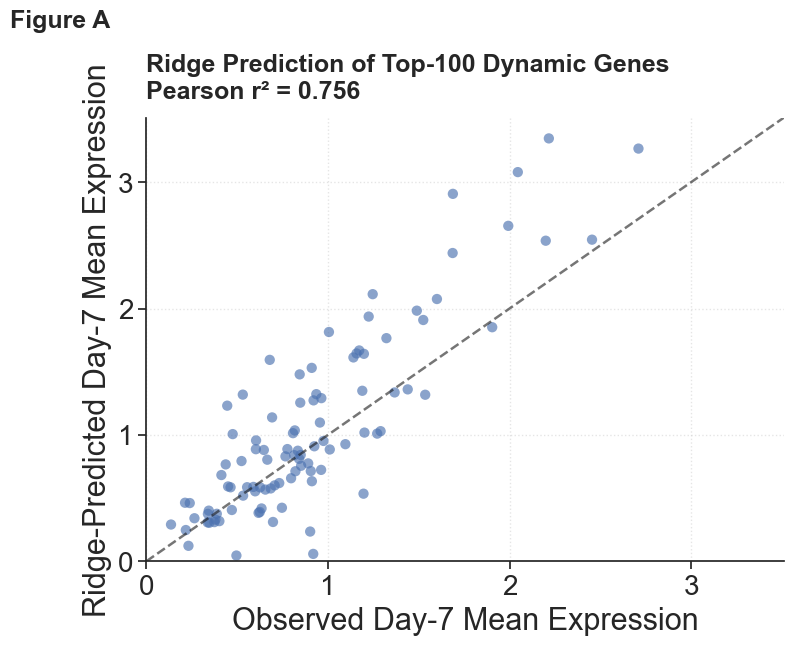

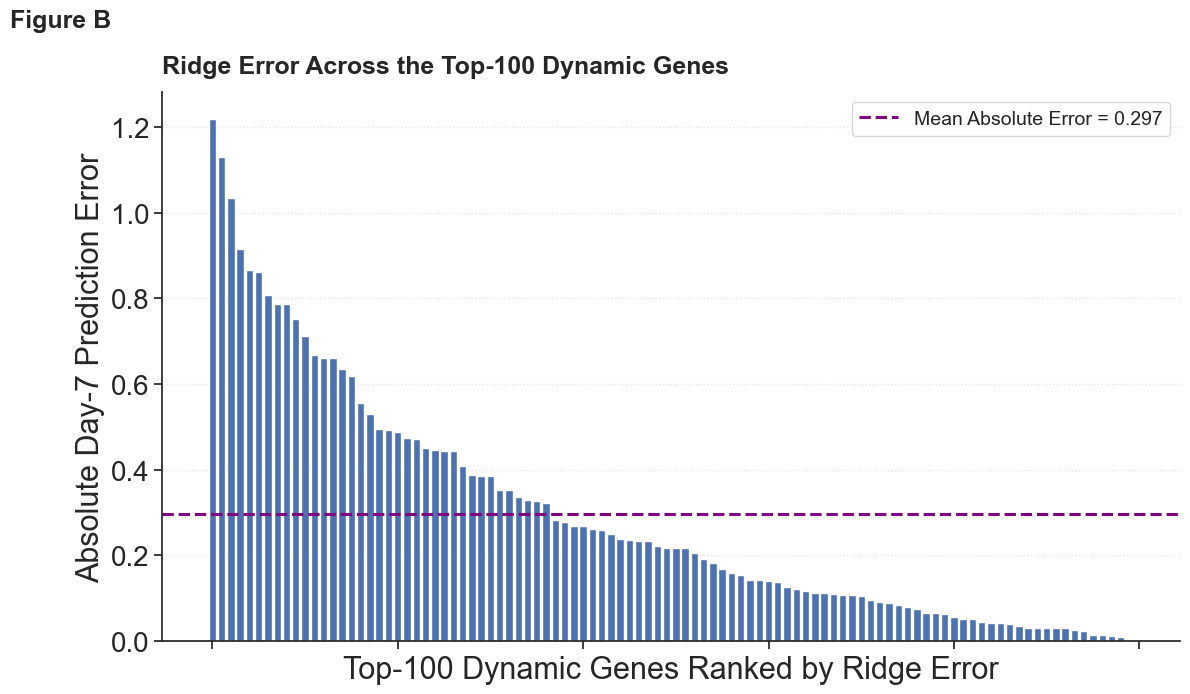

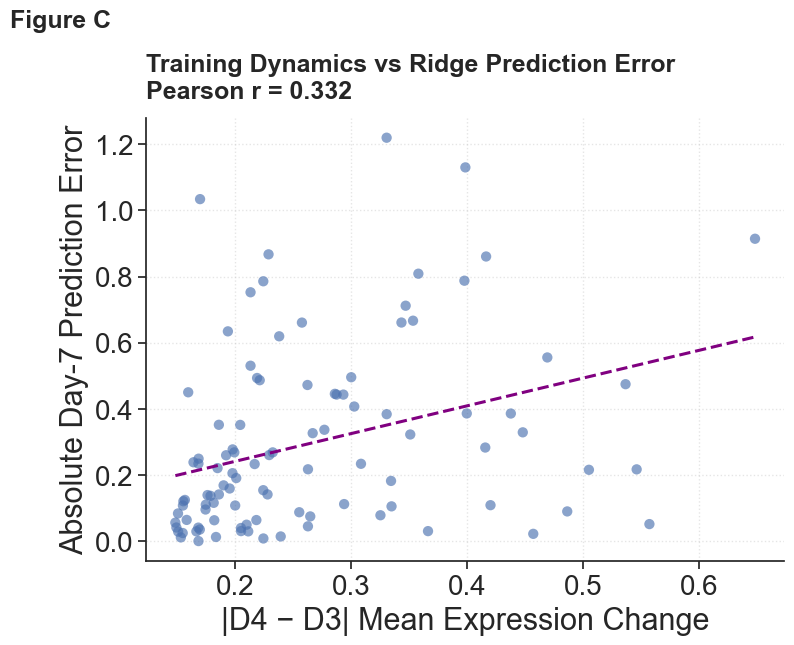

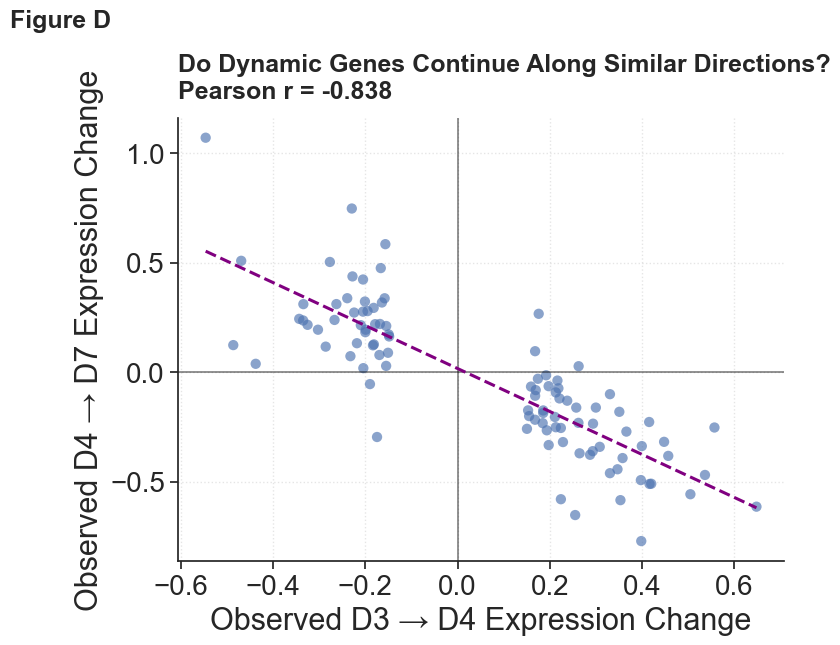


DYNAMIC-GENE SUBGROUP COMPARISON
Least-dynamic 25 genes MAE: 0.1462
Most-dynamic 25 genes MAE: 0.4279
Ridge has lower error on the LEAST dynamic quarter of the Top-100 genes.

RIDGE TOP-100 DIAGNOSTIC SUMMARY
Top-100 Pearson r: 0.8692
Top-100 Pearson r²: 0.7555

Prediction error:
Mean absolute gene error: 0.2966
Median absolute gene error: 0.2179

Relationship between training dynamics and Ridge error:
Pearson r: 0.3315
Pearson r²: 0.1099

Relationship between D3->D4 and D4->D7 changes:
Pearson r: -0.8383
Pearson r²: 0.7028
Genes continuing in same direction: 5.0%

Most vs least dynamic Top-100 genes:
Least-dynamic 25 MAE: 0.1462
Most-dynamic 25 MAE: 0.4279

Saved:
ridge_top100_observed_vs_predicted.png
ridge_top100_per_gene_error.png
ridge_training_change_vs_error.png
top100_training_vs_future_change.png
ridge_top100_gene_diagnostics.csv

✔ Ridge recreated directly from final OT training arrays
✔ Day-7 remains evaluation-only
✔ Top-100 genes remain training-selected from D3 -> D4
✔ A

In [76]:
# =========================================================
# RIDGE TOP-100 DYNAMIC-GENE DIAGNOSTIC
# Why does Ridge perform well on the Top-100 genes?
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
from sklearn.linear_model import Ridge

print("=" * 80)
print("RIDGE TOP-100 DYNAMIC-GENE DIAGNOSTIC")
print("=" * 80)

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

# =========================================================
# 1. RECREATE FINAL RIDGE OT MODEL
# =========================================================

ridge_diagnostic_model = Ridge(alpha=10.0)
ridge_diagnostic_model.fit(X_train_final, Y_train_final)

ridge_latent = ridge_diagnostic_model.predict(X_test_final)
ridge_bio = to_true_biological_gene_space(ridge_latent)

print("\nRidge latent prediction:", ridge_latent.shape)
print("Ridge biological prediction:", ridge_bio.shape)
print("True Day-7 matrix:", Y_test_true_biological.shape)

assert ridge_latent.shape == (201, optimal_pc_count)
assert ridge_bio.shape == (201, 2000)
assert Y_test_true_biological.shape == (1407, 2000)

# =========================================================
# 2. POPULATION-MEAN PROFILES
# =========================================================

true_d7_profile = np.mean(Y_test_true_biological, axis=0)
ridge_d7_profile = np.mean(ridge_bio, axis=0)

top100_idx = np.asarray(top_100_dynamic_indices)

true_top100 = true_d7_profile[top100_idx]
ridge_top100 = ridge_d7_profile[top100_idx]

top100_training_change = training_change[top100_idx]
top100_gene_names = np.asarray(hvg_gene_names)[top100_idx]

print("\nTop-100 genes:", len(top100_idx))

# =========================================================
# 3. PER-GENE RIDGE ERRORS
# =========================================================

ridge_absolute_error = np.abs(ridge_top100 - true_top100)
ridge_signed_error = ridge_top100 - true_top100

top100_r = pearsonr(true_top100, ridge_top100)[0]
top100_r2 = top100_r ** 2

top100_mae = np.mean(ridge_absolute_error)
top100_median_ae = np.median(ridge_absolute_error)

print("\nTop-100 Ridge performance:")
print("Pearson r:", round(top100_r, 4))
print("Pearson r²:", round(top100_r2, 4))
print("Mean absolute error:", round(top100_mae, 4))
print("Median absolute error:", round(top100_median_ae, 4))

# =========================================================
# 4. GENE-LEVEL TABLE
# =========================================================

ridge_gene_df = pd.DataFrame({
    "Gene": top100_gene_names,
    "Training_Change_D3_D4": top100_training_change,
    "Observed_D7": true_top100,
    "Ridge_Predicted_D7": ridge_top100,
    "Absolute_Error": ridge_absolute_error,
    "Signed_Error": ridge_signed_error
})

ridge_gene_df = ridge_gene_df.sort_values("Absolute_Error").reset_index(drop=True)

print("\n" + "=" * 80)
print("10 BEST-PREDICTED TOP-100 GENES")
print("=" * 80)

print(
    ridge_gene_df.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("10 WORST-PREDICTED TOP-100 GENES")
print("=" * 80)

print(
    ridge_gene_df.tail(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# =========================================================
# 5. FIGURE A
# OBSERVED VS RIDGE-PREDICTED TOP-100 GENES
# =========================================================

plot_min = min(np.min(true_top100), np.min(ridge_top100))
plot_max = max(np.max(true_top100), np.max(ridge_top100))

plot_range = plot_max - plot_min
plot_min = max(0, plot_min - 0.05 * plot_range)
plot_max = plot_max + 0.05 * plot_range

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(
    true_top100,
    ridge_top100,
    s=55,
    alpha=0.65,
    edgecolor="none"
)

ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    "k--",
    linewidth=1.8,
    alpha=0.6
)

ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)

ax.set_xlabel("Observed Day-7 Mean Expression", fontsize=22)
ax.set_ylabel("Ridge-Predicted Day-7 Mean Expression", fontsize=22)

ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_title(
    f"Ridge Prediction of Top-100 Dynamic Genes\nPearson r² = {top100_r2:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(True, linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure A",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "ridge_top100_observed_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 6. FIGURE B
# PER-GENE ABSOLUTE ERROR
# =========================================================

error_sorted = ridge_gene_df.sort_values("Absolute_Error", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 7))

ax.bar(
    np.arange(len(error_sorted)),
    error_sorted["Absolute_Error"]
)

ax.axhline(
    top100_mae,
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"Mean Absolute Error = {top100_mae:.3f}"
)

ax.set_xlabel("Top-100 Dynamic Genes Ranked by Ridge Error", fontsize=22)
ax.set_ylabel("Absolute Day-7 Prediction Error", fontsize=22)

ax.tick_params(axis="y", which="major", labelsize=20)
ax.tick_params(axis="x", labelbottom=False)

ax.set_title(
    "Ridge Error Across the Top-100 Dynamic Genes",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.legend(
    loc="upper right",
    fontsize=14,
    frameon=True
)

ax.grid(axis="y", linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure B",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "ridge_top100_per_gene_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 7. FIGURE C
# TRAINING DYNAMICS VS RIDGE ERROR
# =========================================================

error_change_r = pearsonr(top100_training_change, ridge_absolute_error)[0]
error_change_r2 = error_change_r ** 2

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(
    top100_training_change,
    ridge_absolute_error,
    s=55,
    alpha=0.65,
    edgecolor="none"
)

trend_coef = np.polyfit(top100_training_change, ridge_absolute_error, 1)
trend_x = np.linspace(np.min(top100_training_change), np.max(top100_training_change), 200)
trend_y = np.polyval(trend_coef, trend_x)

ax.plot(
    trend_x,
    trend_y,
    color="purple",
    linewidth=2.2,
    linestyle="--"
)

ax.set_xlabel("|D4 − D3| Mean Expression Change", fontsize=22)
ax.set_ylabel("Absolute Day-7 Prediction Error", fontsize=22)

ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_title(
    f"Training Dynamics vs Ridge Prediction Error\nPearson r = {error_change_r:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(True, linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure C",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "ridge_training_change_vs_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 8. FIGURE D
# DOES D3 -> D4 DIRECTION CONTINUE FROM D4 -> D7?
# =========================================================

d3_profile = np.mean(X_d3_bio, axis=0)
d4_profile = np.mean(X_d4_bio, axis=0)

d3_to_d4_signed_change = d4_profile[top100_idx] - d3_profile[top100_idx]
d4_to_d7_signed_change = true_top100 - d4_profile[top100_idx]

trajectory_r = pearsonr(d3_to_d4_signed_change, d4_to_d7_signed_change)[0]
trajectory_r2 = trajectory_r ** 2

same_direction = np.sign(d3_to_d4_signed_change) == np.sign(d4_to_d7_signed_change)
same_direction_fraction = np.mean(same_direction)

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(
    d3_to_d4_signed_change,
    d4_to_d7_signed_change,
    s=55,
    alpha=0.65,
    edgecolor="none"
)

ax.axhline(
    0,
    color="black",
    linewidth=1.2,
    alpha=0.5
)

ax.axvline(
    0,
    color="black",
    linewidth=1.2,
    alpha=0.5
)

trajectory_coef = np.polyfit(d3_to_d4_signed_change, d4_to_d7_signed_change, 1)
trajectory_x = np.linspace(np.min(d3_to_d4_signed_change), np.max(d3_to_d4_signed_change), 200)
trajectory_y = np.polyval(trajectory_coef, trajectory_x)

ax.plot(
    trajectory_x,
    trajectory_y,
    color="purple",
    linewidth=2.2,
    linestyle="--"
)

ax.set_xlabel("Observed D3 → D4 Expression Change", fontsize=22)
ax.set_ylabel("Observed D4 → D7 Expression Change", fontsize=22)

ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_title(
    f"Do Dynamic Genes Continue Along Similar Directions?\nPearson r = {trajectory_r:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(True, linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure D",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "top100_training_vs_future_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 9. EXTRA DIAGNOSTIC
# RIDGE ERROR FOR MOST VS LEAST DYNAMIC TOP-100 GENES
# =========================================================

dynamic_order = np.argsort(top100_training_change)

least_dynamic_25 = dynamic_order[:25]
most_dynamic_25 = dynamic_order[-25:]

least_dynamic_mae = np.mean(ridge_absolute_error[least_dynamic_25])
most_dynamic_mae = np.mean(ridge_absolute_error[most_dynamic_25])

print("\n" + "=" * 80)
print("DYNAMIC-GENE SUBGROUP COMPARISON")
print("=" * 80)

print("Least-dynamic 25 genes MAE:", round(least_dynamic_mae, 4))
print("Most-dynamic 25 genes MAE:", round(most_dynamic_mae, 4))

if most_dynamic_mae < least_dynamic_mae:
    print("Ridge has lower error on the MOST dynamic quarter of the Top-100 genes.")
else:
    print("Ridge has lower error on the LEAST dynamic quarter of the Top-100 genes.")

# =========================================================
# 10. SAVE GENE-LEVEL TABLE
# =========================================================

ridge_gene_df.to_csv(
    "ridge_top100_gene_diagnostics.csv",
    index=False
)

# =========================================================
# 11. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("RIDGE TOP-100 DIAGNOSTIC SUMMARY")
print("=" * 80)

print("Top-100 Pearson r:", round(top100_r, 4))
print("Top-100 Pearson r²:", round(top100_r2, 4))

print("\nPrediction error:")
print("Mean absolute gene error:", round(top100_mae, 4))
print("Median absolute gene error:", round(top100_median_ae, 4))

print("\nRelationship between training dynamics and Ridge error:")
print("Pearson r:", round(error_change_r, 4))
print("Pearson r²:", round(error_change_r2, 4))

print("\nRelationship between D3->D4 and D4->D7 changes:")
print("Pearson r:", round(trajectory_r, 4))
print("Pearson r²:", round(trajectory_r2, 4))
print("Genes continuing in same direction:", f"{same_direction_fraction * 100:.1f}%")

print("\nMost vs least dynamic Top-100 genes:")
print("Least-dynamic 25 MAE:", round(least_dynamic_mae, 4))
print("Most-dynamic 25 MAE:", round(most_dynamic_mae, 4))

print("\nSaved:")
print("ridge_top100_observed_vs_predicted.png")
print("ridge_top100_per_gene_error.png")
print("ridge_training_change_vs_error.png")
print("top100_training_vs_future_change.png")
print("ridge_top100_gene_diagnostics.csv")

print("\n✔ Ridge recreated directly from final OT training arrays")
print("✔ Day-7 remains evaluation-only")
print("✔ Top-100 genes remain training-selected from D3 -> D4")
print("✔ All figures saved at 300 DPI")

RIDGE TOP-100: RANK VS MAGNITUDE DIAGNOSTIC
Pearson r: 0.8692
Pearson r²: 0.7555
Spearman ρ: 0.7964
Spearman ρ²: 0.6343
MAE: 0.2966


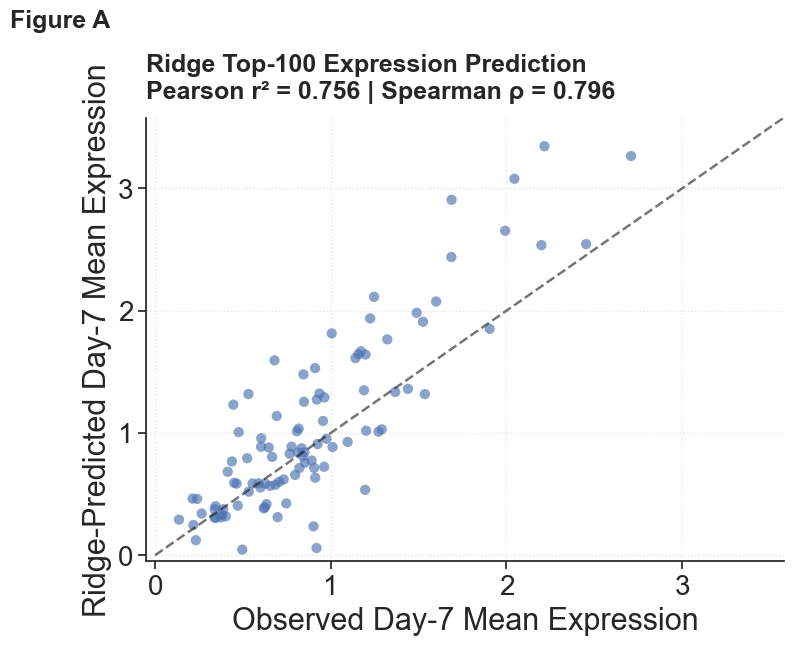

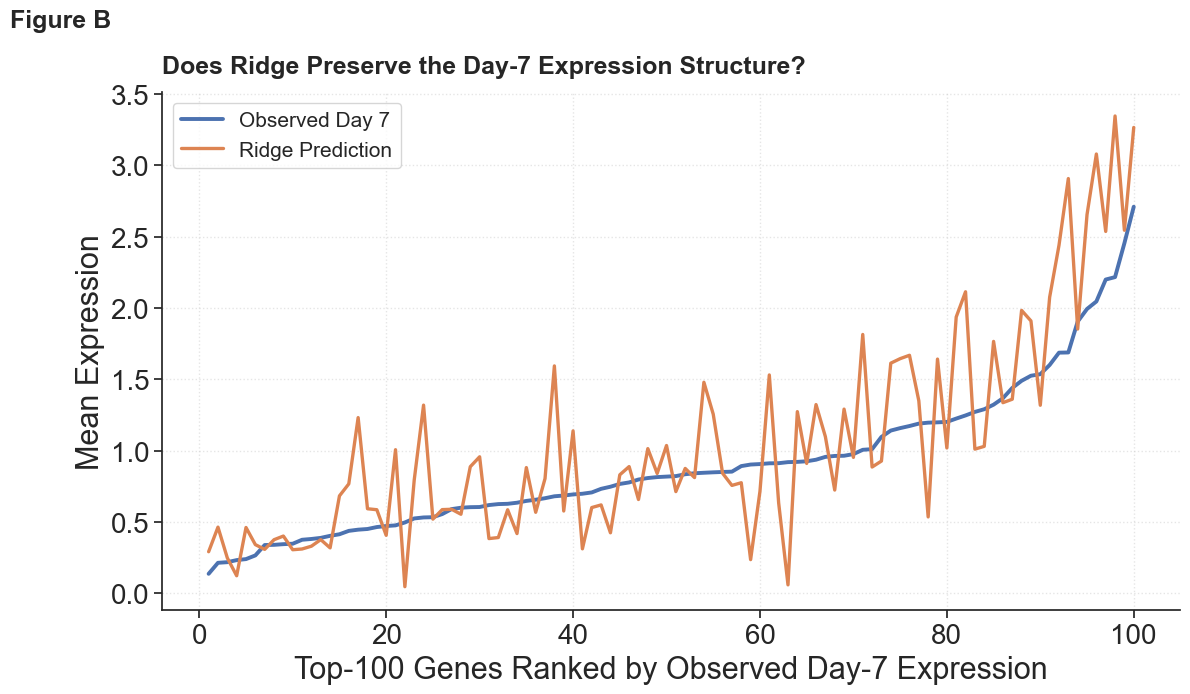

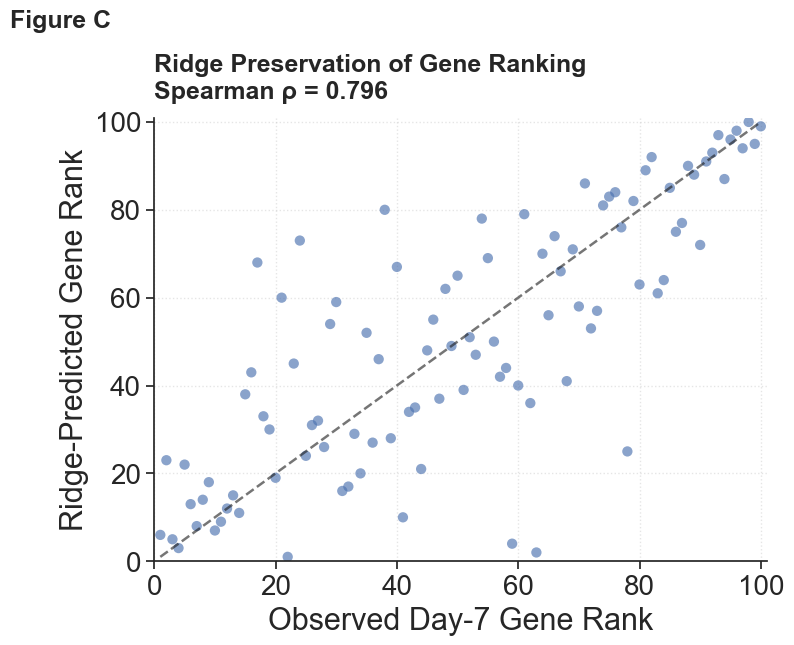

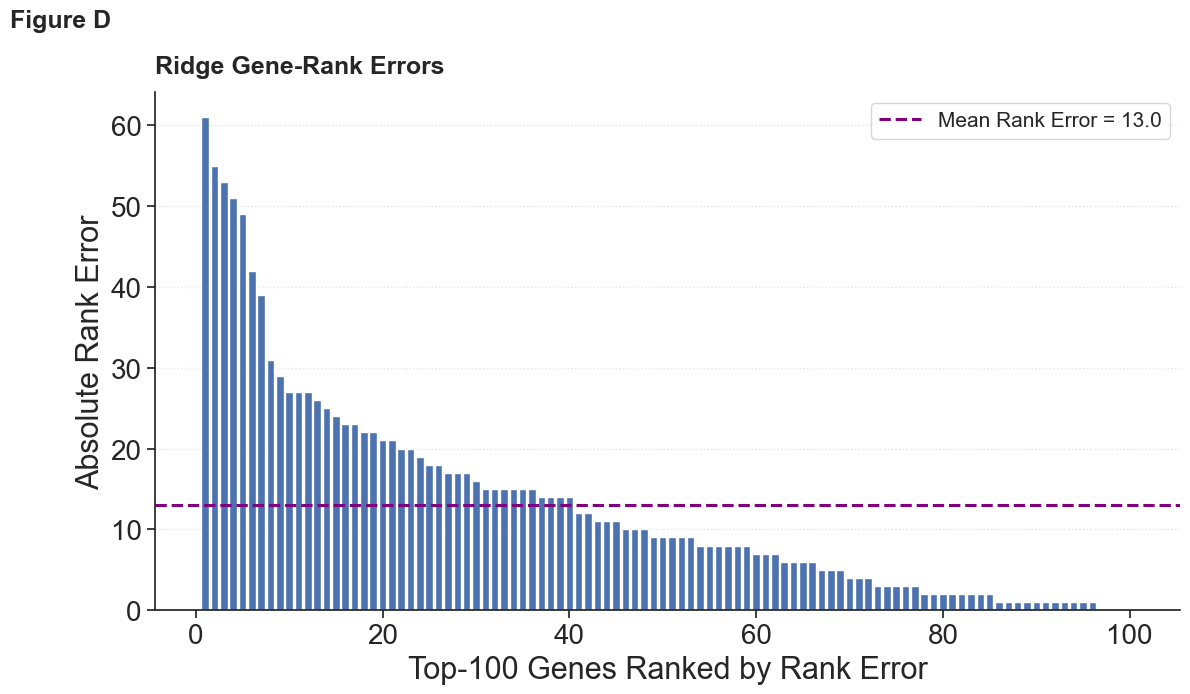


10 LARGEST RANK ERRORS
   Gene  Observed_D7  Ridge_Predicted_D7  Observed_Rank  Ridge_Rank  Absolute_Rank_Error  Absolute_Expression_Error
MIR31HG        0.919               0.058         63.000       2.000               61.000                      0.861
  VEGFC        0.902               0.235         59.000       4.000               55.000                      0.667
SLC7A11        1.196               0.535         78.000      25.000               53.000                      0.661
   EMP1        0.445               1.231         17.000      68.000               51.000                      0.786
  PCDH9        0.531               1.319         24.000      73.000               49.000                      0.788
  ANXA1        0.679               1.594         38.000      80.000               42.000                      0.914
 ITGBL1        0.475               1.006         21.000      60.000               39.000                      0.531
  TGFBI        0.697               0.311        

In [77]:
# =========================================================
# RIDGE TOP-100: RANK PRESERVATION VS ABSOLUTE ACCURACY
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error

print("=" * 80)
print("RIDGE TOP-100: RANK VS MAGNITUDE DIAGNOSTIC")
print("=" * 80)

# =========================================================
# 1. METRICS
# =========================================================

ridge_pearson_r = pearsonr(true_top100, ridge_top100)[0]
ridge_pearson_r2 = ridge_pearson_r ** 2

ridge_spearman_r = spearmanr(true_top100, ridge_top100)[0]
ridge_spearman_r2 = ridge_spearman_r ** 2

ridge_mae = mean_absolute_error(true_top100, ridge_top100)

print("Pearson r:", round(ridge_pearson_r, 4))
print("Pearson r²:", round(ridge_pearson_r2, 4))
print("Spearman ρ:", round(ridge_spearman_r, 4))
print("Spearman ρ²:", round(ridge_spearman_r2, 4))
print("MAE:", round(ridge_mae, 4))

# =========================================================
# 2. SORT GENES BY TRUE DAY-7 EXPRESSION
# =========================================================

true_order = np.argsort(true_top100)

true_sorted = true_top100[true_order]
ridge_sorted = ridge_top100[true_order]
genes_sorted = top100_gene_names[true_order]

# =========================================================
# 3. FIGURE A
# OBSERVED VS PREDICTED EXPRESSION
# =========================================================

plot_max = max(np.max(true_top100), np.max(ridge_top100)) * 1.07

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(
    true_top100,
    ridge_top100,
    s=55,
    alpha=0.65,
    edgecolor="none"
)

ax.plot(
    [0, plot_max],
    [0, plot_max],
    "k--",
    linewidth=1.8,
    alpha=0.6
)

ax.set_xlim(-0.05, plot_max)
ax.set_ylim(-0.05, plot_max)

ax.set_xlabel("Observed Day-7 Mean Expression", fontsize=22)
ax.set_ylabel("Ridge-Predicted Day-7 Mean Expression", fontsize=22)

ax.tick_params(axis="both", labelsize=20)

ax.set_title(
    f"Ridge Top-100 Expression Prediction\n"
    f"Pearson r² = {ridge_pearson_r2:.3f} | "
    f"Spearman ρ = {ridge_spearman_r:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(True, linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure A",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "ridge_top100_rank_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 4. FIGURE B
# TRUE-RANKED GENE EXPRESSION PROFILE
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

gene_rank = np.arange(1, 101)

ax.plot(
    gene_rank,
    true_sorted,
    linewidth=2.8,
    label="Observed Day 7"
)

ax.plot(
    gene_rank,
    ridge_sorted,
    linewidth=2.4,
    label="Ridge Prediction"
)

ax.set_xlabel("Top-100 Genes Ranked by Observed Day-7 Expression", fontsize=22)
ax.set_ylabel("Mean Expression", fontsize=22)

ax.tick_params(axis="both", labelsize=20)

ax.set_title(
    "Does Ridge Preserve the Day-7 Expression Structure?",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.legend(
    loc="upper left",
    fontsize=15,
    frameon=True
)

ax.grid(True, linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure B",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "ridge_top100_ranked_expression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 5. FIGURE C
# OBSERVED RANK VS PREDICTED RANK
# =========================================================

true_ranks = pd.Series(true_top100).rank(method="average").to_numpy()
ridge_ranks = pd.Series(ridge_top100).rank(method="average").to_numpy()

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(
    true_ranks,
    ridge_ranks,
    s=55,
    alpha=0.65,
    edgecolor="none"
)

ax.plot(
    [1, 100],
    [1, 100],
    "k--",
    linewidth=1.8,
    alpha=0.6
)

ax.set_xlim(0, 101)
ax.set_ylim(0, 101)

ax.set_xlabel("Observed Day-7 Gene Rank", fontsize=22)
ax.set_ylabel("Ridge-Predicted Gene Rank", fontsize=22)

ax.tick_params(axis="both", labelsize=20)

ax.set_title(
    f"Ridge Preservation of Gene Ranking\nSpearman ρ = {ridge_spearman_r:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(True, linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure C",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "ridge_top100_observed_vs_predicted_rank.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 6. FIGURE D
# RANK ERROR FOR EACH GENE
# =========================================================

rank_error = np.abs(ridge_ranks - true_ranks)
rank_error_order = np.argsort(rank_error)[::-1]

fig, ax = plt.subplots(figsize=(12, 7))

ax.bar(
    np.arange(1, 101),
    rank_error[rank_error_order]
)

ax.axhline(
    np.mean(rank_error),
    color="purple",
    linestyle="--",
    linewidth=2.2,
    label=f"Mean Rank Error = {np.mean(rank_error):.1f}"
)

ax.set_xlabel("Top-100 Genes Ranked by Rank Error", fontsize=22)
ax.set_ylabel("Absolute Rank Error", fontsize=22)

ax.tick_params(axis="both", labelsize=20)

ax.set_title(
    "Ridge Gene-Rank Errors",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.legend(
    loc="upper right",
    fontsize=15,
    frameon=True
)

ax.grid(axis="y", linestyle=":", alpha=0.5)

fig.text(
    0.01,
    0.99,
    "Figure D",
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "ridge_top100_rank_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 7. GENE-LEVEL RANK TABLE
# =========================================================

rank_df = pd.DataFrame({
    "Gene": top100_gene_names,
    "Observed_D7": true_top100,
    "Ridge_Predicted_D7": ridge_top100,
    "Observed_Rank": true_ranks,
    "Ridge_Rank": ridge_ranks,
    "Absolute_Rank_Error": rank_error,
    "Absolute_Expression_Error": np.abs(ridge_top100 - true_top100)
})

rank_df = rank_df.sort_values("Absolute_Rank_Error", ascending=False).reset_index(drop=True)

print("\n" + "=" * 80)
print("10 LARGEST RANK ERRORS")
print("=" * 80)

print(
    rank_df.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\n" + "=" * 80)
print("10 BEST-PRESERVED GENE RANKS")
print("=" * 80)

print(
    rank_df.tail(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# =========================================================
# 8. SUMMARY
# =========================================================

mean_rank_error = np.mean(rank_error)
median_rank_error = np.median(rank_error)

print("\n" + "=" * 80)
print("RIDGE RANK-PRESERVATION SUMMARY")
print("=" * 80)

print("Pearson r:", round(ridge_pearson_r, 4))
print("Pearson r²:", round(ridge_pearson_r2, 4))

print("\nRank preservation:")
print("Spearman ρ:", round(ridge_spearman_r, 4))
print("Spearman ρ²:", round(ridge_spearman_r2, 4))
print("Mean absolute rank error:", round(mean_rank_error, 2))
print("Median absolute rank error:", round(median_rank_error, 2))

print("\nMagnitude accuracy:")
print("Mean absolute expression error:", round(ridge_mae, 4))

rank_df.to_csv(
    "ridge_top100_rank_diagnostics.csv",
    index=False
)

print("\nSaved:")
print("ridge_top100_rank_scatter.png")
print("ridge_top100_ranked_expression.png")
print("ridge_top100_observed_vs_predicted_rank.png")
print("ridge_top100_rank_error.png")
print("ridge_top100_rank_diagnostics.csv")

print("\n✔ All analyses use the same training-selected Top-100 genes")
print("✔ No genes were selected using Day-7 information")
print("✔ All figures saved at 300 DPI")

TOP-100: D3/D4 STRUCTURE VS MODEL D7 PREDICTIONS

Observed training-state similarity to Day 7:
D3 -> D7 Pearson r²: 0.8827
D4 -> D7 Pearson r²: 0.6731

D3 -> D7 Spearman ρ: 0.8990
D4 -> D7 Spearman ρ: 0.7251

D3 -> D7 MAE: 0.1347
D4 -> D7 MAE: 0.2743


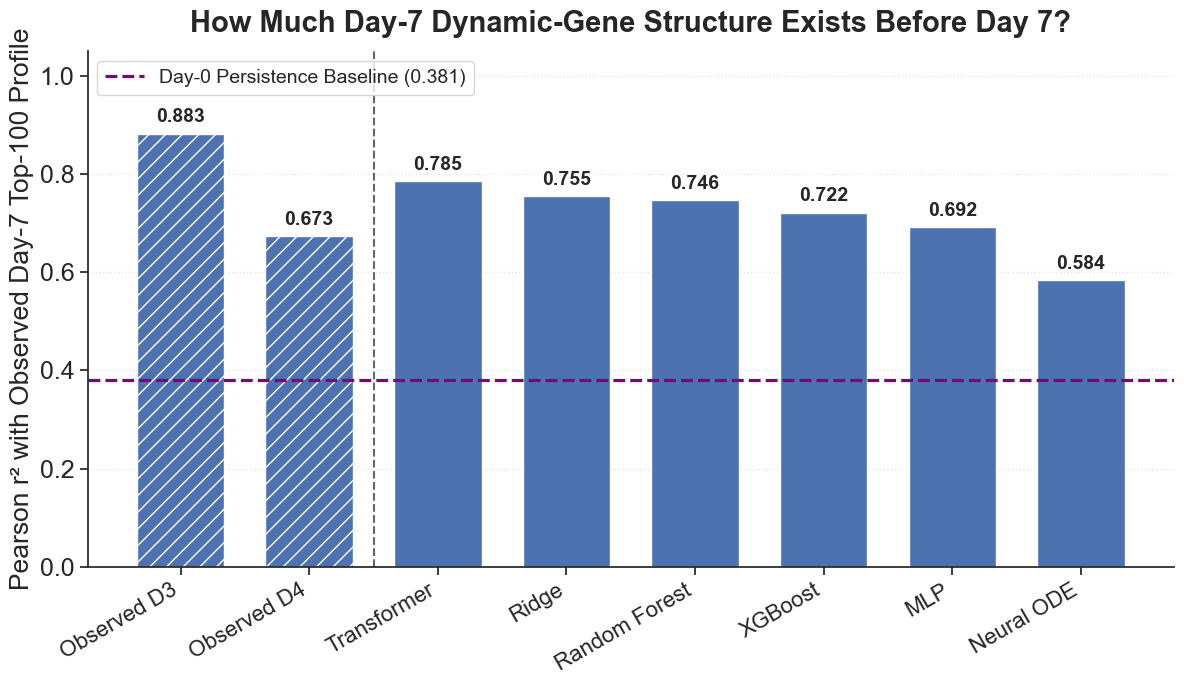

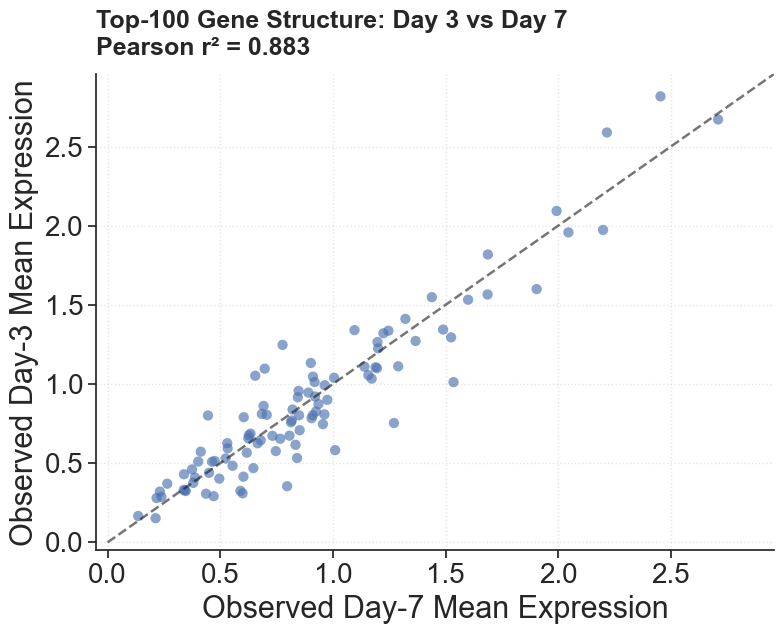

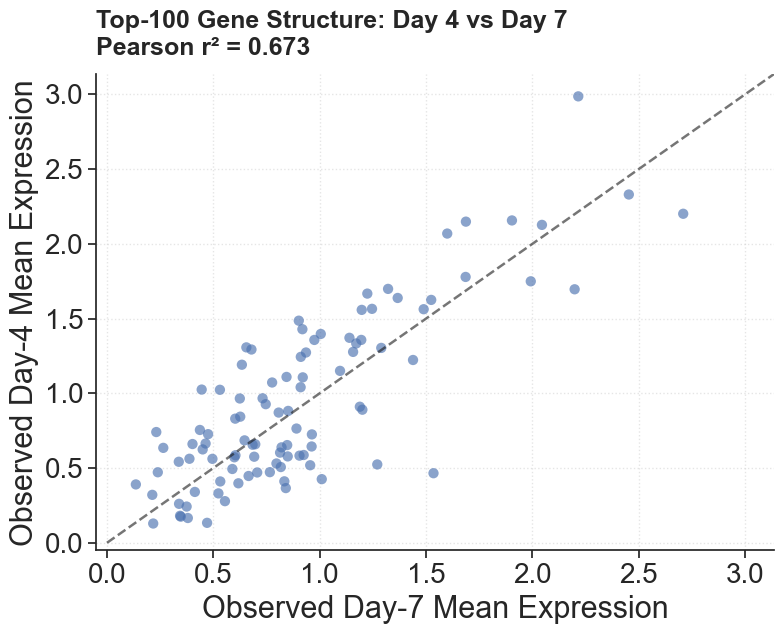


SUMMARY
D3 -> D7 Pearson r²: 0.8827
D4 -> D7 Pearson r²: 0.6731

D3 -> D7 Spearman ρ: 0.8990
D4 -> D7 Spearman ρ: 0.7251

D3 -> D7 MAE: 0.1347
D4 -> D7 MAE: 0.2743

Model Top-100 Pearson r²:
Transformer:   0.7852
Ridge:         0.7555
Random Forest: 0.7463
XGBoost:       0.7217
MLP:           0.6917
Neural ODE:    0.5840

Saved:
top100_d3_d4_vs_models.png
top100_d3_vs_d7.png
top100_d4_vs_d7.png


In [82]:
# =========================================================
# TOP-100: OBSERVED TRAINING STATES VS MODEL D7 PREDICTIONS
# Uses ONLY variables already confirmed in the notebook
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

print("=" * 80)
print("TOP-100: D3/D4 STRUCTURE VS MODEL D7 PREDICTIONS")
print("=" * 80)

# =========================================================
# 1. TOP-100 INDICES
# =========================================================

top100_idx = np.asarray(top_100_dynamic_indices)

# =========================================================
# 2. POPULATION-MEAN PROFILES
# =========================================================

d3_profile = np.mean(X_d3_bio, axis=0)[top100_idx]
d4_profile = np.mean(X_d4_bio, axis=0)[top100_idx]
d7_profile = np.mean(Y_test_true_biological, axis=0)[top100_idx]

# =========================================================
# 3. D3/D4 SIMILARITY TO D7
# =========================================================

d3_pearson_r = pearsonr(d3_profile, d7_profile)[0]
d4_pearson_r = pearsonr(d4_profile, d7_profile)[0]

d3_pearson_r2 = d3_pearson_r ** 2
d4_pearson_r2 = d4_pearson_r ** 2

d3_spearman = spearmanr(d3_profile, d7_profile)[0]
d4_spearman = spearmanr(d4_profile, d7_profile)[0]

d3_mae = np.mean(np.abs(d3_profile - d7_profile))
d4_mae = np.mean(np.abs(d4_profile - d7_profile))

print("\nObserved training-state similarity to Day 7:")
print(f"D3 -> D7 Pearson r²: {d3_pearson_r2:.4f}")
print(f"D4 -> D7 Pearson r²: {d4_pearson_r2:.4f}")

print(f"\nD3 -> D7 Spearman ρ: {d3_spearman:.4f}")
print(f"D4 -> D7 Spearman ρ: {d4_spearman:.4f}")

print(f"\nD3 -> D7 MAE: {d3_mae:.4f}")
print(f"D4 -> D7 MAE: {d4_mae:.4f}")

# =========================================================
# 4. SIX FINAL OT MODEL RESULTS
# =========================================================

model_names = [
    "Transformer",
    "Ridge",
    "Random Forest",
    "XGBoost",
    "MLP",
    "Neural ODE"
]

model_r2 = np.array([
    0.7852,
    0.7555,
    0.7463,
    0.7217,
    0.6917,
    0.5840
])

# =========================================================
# 5. COMBINE OBSERVED STATES + MODELS
# =========================================================

labels = [
    "Observed D3",
    "Observed D4",
    "Transformer",
    "Ridge",
    "Random Forest",
    "XGBoost",
    "MLP",
    "Neural ODE"
]

values = np.array([
    d3_pearson_r2,
    d4_pearson_r2,
    0.7852,
    0.7555,
    0.7463,
    0.7217,
    0.6917,
    0.5840
])

# =========================================================
# 6. MAIN COMPARISON GRAPH
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(labels))

bars = ax.bar(
    x,
    values,
    width=0.68
)

# Make observed D3/D4 visually distinct
bars[0].set_hatch("//")
bars[1].set_hatch("//")

# Divider between observed states and model predictions
ax.axvline(
    1.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    alpha=0.6
)

# Day-0 persistence baseline
ax.axhline(
    0.3811,
    color="purple",
    linestyle="--",
    linewidth=2.3,
    label="Day-0 Persistence Baseline (0.381)"
)

# Value labels
for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold"
    )

ax.set_xticks(x)

ax.set_xticklabels(
    labels,
    rotation=30,
    ha="right",
    fontsize=16
)

ax.set_ylabel(
    "Pearson r² with Observed Day-7 Top-100 Profile",
    fontsize=19
)

ax.tick_params(axis="y", labelsize=18)

ax.set_ylim(0, 1.05)

ax.set_title(
    "How Much Day-7 Dynamic-Gene Structure Exists Before Day 7?",
    fontsize=21,
    fontweight="bold",
    pad=14
)

ax.legend(
    loc="upper left",
    fontsize=14,
    frameon=True
)

ax.grid(
    axis="y",
    linestyle=":",
    alpha=0.5
)

sns.despine()
plt.tight_layout()

plt.savefig(
    "top100_d3_d4_vs_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 7. D3 VS D7 SCATTER
# =========================================================

plot_max = max(
    np.max(d3_profile),
    np.max(d7_profile)
) * 1.05

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(
    d7_profile,
    d3_profile,
    s=55,
    alpha=0.65,
    edgecolor="none"
)

ax.plot(
    [0, plot_max],
    [0, plot_max],
    "k--",
    linewidth=1.8,
    alpha=0.6
)

ax.set_xlim(-0.05, plot_max)
ax.set_ylim(-0.05, plot_max)

ax.set_xlabel(
    "Observed Day-7 Mean Expression",
    fontsize=22
)

ax.set_ylabel(
    "Observed Day-3 Mean Expression",
    fontsize=22
)

ax.tick_params(
    axis="both",
    labelsize=20
)

ax.set_title(
    f"Top-100 Gene Structure: Day 3 vs Day 7\nPearson r² = {d3_pearson_r2:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(
    True,
    linestyle=":",
    alpha=0.5
)

sns.despine()
plt.tight_layout()

plt.savefig(
    "top100_d3_vs_d7.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 8. D4 VS D7 SCATTER
# =========================================================

plot_max = max(
    np.max(d4_profile),
    np.max(d7_profile)
) * 1.05

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.scatter(
    d7_profile,
    d4_profile,
    s=55,
    alpha=0.65,
    edgecolor="none"
)

ax.plot(
    [0, plot_max],
    [0, plot_max],
    "k--",
    linewidth=1.8,
    alpha=0.6
)

ax.set_xlim(-0.05, plot_max)
ax.set_ylim(-0.05, plot_max)

ax.set_xlabel(
    "Observed Day-7 Mean Expression",
    fontsize=22
)

ax.set_ylabel(
    "Observed Day-4 Mean Expression",
    fontsize=22
)

ax.tick_params(
    axis="both",
    labelsize=20
)

ax.set_title(
    f"Top-100 Gene Structure: Day 4 vs Day 7\nPearson r² = {d4_pearson_r2:.3f}",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.grid(
    True,
    linestyle=":",
    alpha=0.5
)

sns.despine()
plt.tight_layout()

plt.savefig(
    "top100_d4_vs_d7.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# 9. SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("SUMMARY")
print("=" * 80)

print(f"D3 -> D7 Pearson r²: {d3_pearson_r2:.4f}")
print(f"D4 -> D7 Pearson r²: {d4_pearson_r2:.4f}")

print(f"\nD3 -> D7 Spearman ρ: {d3_spearman:.4f}")
print(f"D4 -> D7 Spearman ρ: {d4_spearman:.4f}")

print(f"\nD3 -> D7 MAE: {d3_mae:.4f}")
print(f"D4 -> D7 MAE: {d4_mae:.4f}")

print("\nModel Top-100 Pearson r²:")
print("Transformer:   0.7852")
print("Ridge:         0.7555")
print("Random Forest: 0.7463")
print("XGBoost:       0.7217")
print("MLP:           0.6917")
print("Neural ODE:    0.5840")

print("\nSaved:")
print("top100_d3_d4_vs_models.png")
print("top100_d3_vs_d7.png")
print("top100_d4_vs_d7.png")

In [68]:
print("\n--- Best Random-Pairing Models ---")

best_random_all = df_leaderboard.loc[
    df_leaderboard["Random_Pearson_All"].idxmax()
]

best_random_top100 = df_leaderboard.loc[
    df_leaderboard["Random_Pearson_Top100"].idxmax()
]

print(
    f"Best Random Pearson r² All HVGs: "
    f"{best_random_all['Model']} "
    f"({best_random_all['Random_Pearson_All']:.4f})"
)

print(
    f"Best Random Pearson r² Top 100: "
    f"{best_random_top100['Model']} "
    f"({best_random_top100['Random_Pearson_Top100']:.4f})"
)


--- Best Random-Pairing Models ---
Best Random Pearson r² All HVGs: Temporal-Token Transformer (0.9272)
Best Random Pearson r² Top 100: Temporal-Token Transformer (0.7842)


In [79]:
print("\n--- Random-Pairing Ranking: All HVGs ---")

print(
    df_leaderboard[
        ["Model", "Random_Pearson_All"]
    ]
    .sort_values("Random_Pearson_All", ascending=False)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\n--- Random-Pairing Ranking: Top 100 Dynamic Genes ---")

print(
    df_leaderboard[
        ["Model", "Random_Pearson_Top100"]
    ]
    .sort_values("Random_Pearson_Top100", ascending=False)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)


--- Random-Pairing Ranking: All HVGs ---
                     Model  Random_Pearson_All
Temporal-Token Transformer              0.9272
             Random Forest              0.9249
         XGBoost Regressor              0.9209
                Neural ODE              0.8971
          Ridge Regression              0.8953
              Absolute MLP              0.8919

--- Random-Pairing Ranking: Top 100 Dynamic Genes ---
                     Model  Random_Pearson_Top100
Temporal-Token Transformer                 0.7842
          Ridge Regression                 0.7612
             Random Forest                 0.7375
         XGBoost Regressor                 0.7247
                Neural ODE                 0.6754
              Absolute MLP                 0.6339


TRAINING-ONLY SIX-MODEL PCA CONFIRMATION SWEEP
Models: Ridge + MLP + XGBoost + Random Forest + Neural ODE + Transformer
Selection: Top 2 models by mean D4 validation performance
Final OT settings: reg=0.001, cap=2
XGBoost / Random Forest / Neural ODE / Transformer stop at 750 PCs
Final Day 7 remains completely untouched
PCA dimensions: [10, 25, 50, 100, 250, 500, 750, 1000]
Heavy-model dimensions: [10, 25, 50, 100, 250, 500, 750]
Fixed Sinkhorn reg: 0.001
Fixed target cap: 2

Control cells: 1005
Day 7 present: False

Outer Day-0 split:
Final-training Day-0 cells: 804
Final-test Day-0 cells: 201

PCA-sweep inner split:
Inner training Day-0 cells: 643
Inner validation Day-0 cells: 161
Final held-out Day-0 cells: 201
✓ Final Day-0 test cells excluded from sweep model training/validation
✓ Inner train / validation split is disjoint
✓ Day 7 absent

Biological matrix: (11940, 2000)
HVG count: 2000

Standardization fitting matrix: (9763, 2000)
PCA fitting matrix: (9763, 2000)
D4 validation bi

c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: divide by zero encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Sweep training inputs: (2572, 26)
Sweep training targets: (2572, 25)
Validation input: (161, 26)
Ridge:        All=0.8963 | Top100=0.6541
MLP:          All=0.9105 | Top100=0.6369
XGBoost:      All=0.9639 | Top100=0.8892
RandomForest: All=0.9624 | Top100=0.8897
NeuralODE:     All=0.8861 | Top100=0.5392
Transformer:   All=0.9570 | Top100=0.8556

PCA DIMENSION: 50
Explained variance: 0.1075


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: divide by zero encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Sweep training inputs: (2572, 51)
Sweep training targets: (2572, 50)
Validation input: (161, 51)
Ridge:        All=0.8924 | Top100=0.6458
MLP:          All=0.9151 | Top100=0.6623
XGBoost:      All=0.9630 | Top100=0.8877
RandomForest: All=0.9632 | Top100=0.8939
NeuralODE:     All=0.8989 | Top100=0.6047
Transformer:   All=0.9628 | Top100=0.8890

PCA DIMENSION: 100
Explained variance: 0.1566


...

Sweep training inputs: (2572, 501)
Sweep training targets: (2572, 500)
Validation input: (161, 501)
Ridge:        All=0.9103 | Top100=0.6791
MLP:          All=0.9406 | Top100=0.7949
XGBoost:      All=0.9621 | Top100=0.8806
RandomForest: All=0.9600 | Top100=0.8819
NeuralODE:     All=0.9054 | Top100=0.6551
Transformer:   All=0.9629 | Top100=0.8924

PCA DIMENSION: 750
Explained variance: 0.6007


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


Sweep training inputs: (2572, 751)
Sweep training targets: (2572, 750)
Validation input: (161, 751)
Ridge:        All=0.9133 | Top100=0.6860
MLP:          All=0.9277 | Top100=0.7652
XGBoost:      All=0.9593 | Top100=0.8758
RandomForest: All=0.9585 | Top100=0.8771
NeuralODE:     All=0.9005 | Top100=0.6670
Transformer:   All=0.9584 | Top100=0.8744

PCA DIMENSION: 1000
Explained variance: 0.72


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


Sweep training inputs: (2572, 1001)
Sweep training targets: (2572, 1000)
Validation input: (161, 1001)
Ridge:        All=0.9022 | Top100=0.6575
MLP:          All=0.9402 | Top100=0.8084
XGBoost: skipped at 1000 PCs
RandomForest: skipped at 1000 PCs
NeuralODE: skipped at 1000 PCs
Transformer: skipped at 1000 PCs

MODEL RANKING ACROSS COMMON PCA DIMENSIONS
1. XGBoost: mean All-HVG Pearson r² = 0.9632
2. RandomForest: mean All-HVG Pearson r² = 0.9622
3. Transformer: mean All-HVG Pearson r² = 0.9578
4. MLP: mean All-HVG Pearson r² = 0.9209
5. NeuralODE: mean All-HVG Pearson r² = 0.9028
6. Ridge: mean All-HVG Pearson r² = 0.8965

Selected top two models: ['XGBoost', 'RandomForest']

CONFIRMED PCA DIMENSION
Models used for PCA confirmation: XGBoost + RandomForest
Selected PCA dimensions: 10
Top-2 mean All-HVG Pearson r²: 0.967
Top-2 mean Top-100 Pearson r²: 0.8963

SIX-MODEL PCA CONFIRMATION SWEEP RESULTS
 PCA_Dim  Explained_Variance  Ridge_All  MLP_All  XGBoost_All  RandomForest_All  NeuralO

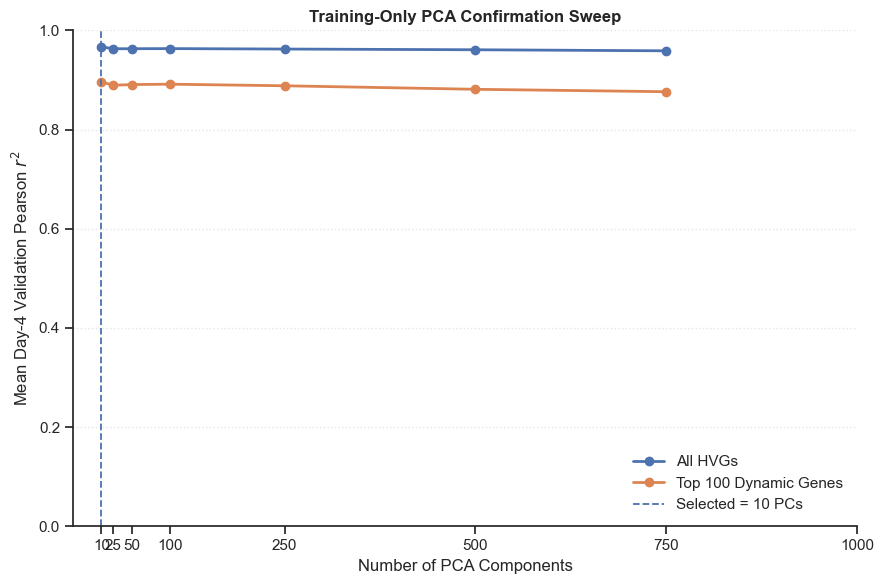

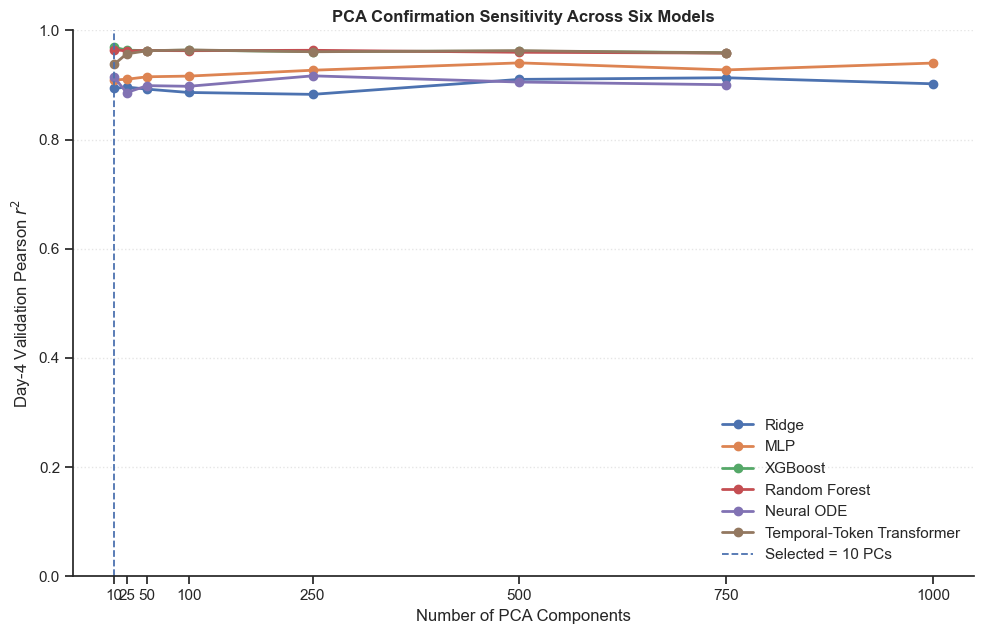

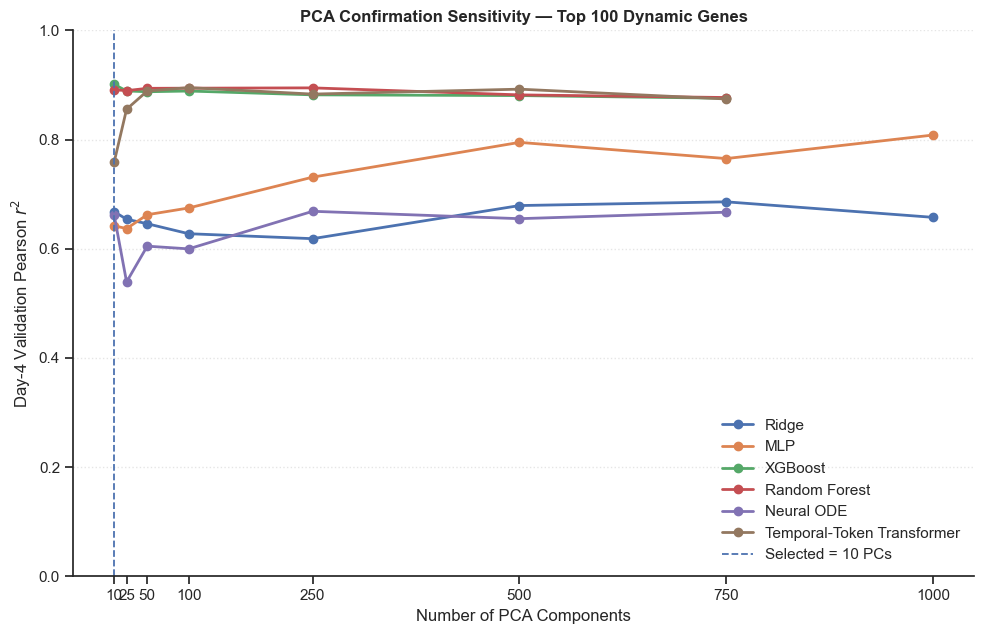

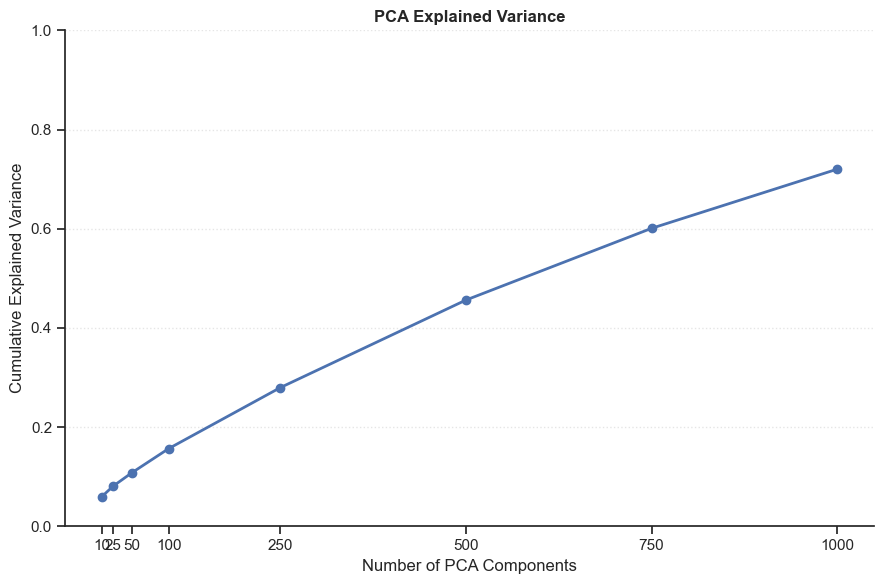


Saved:
six_model_pca_confirmation_reg0001_cap2.csv
publication_top2_pca_confirmation_reg0001_cap2.png
supplement_six_model_pca_confirmation_allHVG.png
supplement_six_model_pca_confirmation_top100.png
supplement_pca_confirmation_explained_variance.png

PCA CONFIRMATION SWEEP LEAKAGE AUDIT
D4 used in standardization fitting: False
D4 used in PCA fitting: False
D7 present in sweep cohort: False
Final Day-0 test cells used for model training: False
Final Day-0 test cells used for validation: False
Top-100 genes selected using D4: False

✔ Outer 80/20 Day-0 split created inside this cell
✔ Inner PCA-sweep train/validation split created inside this cell
✔ 643 Day-0 cells used for sweep model training
✔ 161 Day-0 cells used for D4 validation
✔ 201 final Day-0 test cells excluded from sweep model training and validation
✔ PCA dimensions tested: 10, 25, 50, 100, 250, 500, 750, 1000
✔ Ridge evaluated through 1000 PCs
✔ MLP evaluated through 1000 PCs
✔ XGBoost evaluated only through 750 PCs
✔ Ra

In [26]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ot
import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.stats import pearsonr
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

print("=" * 90)
print("TRAINING-ONLY SIX-MODEL PCA CONFIRMATION SWEEP")
print("Models: Ridge + MLP + XGBoost + Random Forest + Neural ODE + Transformer")
print("Selection: Top 2 models by mean D4 validation performance")
print("Final OT settings: reg=0.001, cap=2")
print("XGBoost / Random Forest / Neural ODE / Transformer stop at 750 PCs")
print("Final Day 7 remains completely untouched")
print("=" * 90)

# =========================================================
# 1. SETTINGS
# =========================================================

pca_dimensions = [10, 25, 50, 100, 250, 500, 750, 1000]
heavy_model_dimensions = [10, 25, 50, 100, 250, 500, 750]

sweep_training_stages = ["Sen 4hrs", "Sen D1", "Sen D2", "Sen D3"]
sweep_validation_stage = "Sen D4"

sweep_time_mapping = {
    "control": 0.0,
    "Sen 4hrs": 4 / 24,
    "Sen D1": 1.0,
    "Sen D2": 2.0,
    "Sen D3": 3.0,
    "Sen D4": 4.0
}

sweep_reg = 0.001
sweep_cap = 2
seed = 42

print("PCA dimensions:", pca_dimensions)
print("Heavy-model dimensions:", heavy_model_dimensions)
print("Fixed Sinkhorn reg:", sweep_reg)
print("Fixed target cap:", sweep_cap)

# =========================================================
# 2. VERIFY DATASET
# =========================================================

samples = adata_processed.obs["sample"].values

assert "Sen D7" not in set(samples)
assert np.sum(samples == "control") == 1005

print("\nControl cells:", np.sum(samples == "control"))
print("Day 7 present:", "Sen D7" in set(samples))

# =========================================================
# 3. CREATE OUTER 80/20 DAY-0 SPLIT
#
# 1005 total control cells
# 804 final-training controls
# 201 final-test controls
# =========================================================

all_source_idx = np.arange(np.sum(samples == "control"))

train_source_idx, test_source_idx = train_test_split(
    all_source_idx,
    test_size=0.20,
    random_state=42
)

train_source_idx = np.sort(train_source_idx)
test_source_idx = np.sort(test_source_idx)

print("\nOuter Day-0 split:")
print("Final-training Day-0 cells:", len(train_source_idx))
print("Final-test Day-0 cells:", len(test_source_idx))

assert len(train_source_idx) == 804
assert len(test_source_idx) == 201
assert len(set(train_source_idx) & set(test_source_idx)) == 0

# =========================================================
# 4. CREATE INNER PCA-SWEEP TRAIN / VALIDATION SPLIT
#
# Only the 804 outer-training cells are split here.
# =========================================================

sweep_train_source_idx, sweep_val_source_idx = train_test_split(
    train_source_idx,
    test_size=0.20,
    random_state=123
)

sweep_train_source_idx = np.sort(sweep_train_source_idx)
sweep_val_source_idx = np.sort(sweep_val_source_idx)

print("\nPCA-sweep inner split:")
print("Inner training Day-0 cells:", len(sweep_train_source_idx))
print("Inner validation Day-0 cells:", len(sweep_val_source_idx))
print("Final held-out Day-0 cells:", len(test_source_idx))

assert len(sweep_train_source_idx) == 643
assert len(sweep_val_source_idx) == 161
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0
assert len(set(sweep_train_source_idx) & set(sweep_val_source_idx)) == 0
assert len(sweep_train_source_idx) + len(sweep_val_source_idx) == len(train_source_idx)

print("✓ Final Day-0 test cells excluded from sweep model training/validation")
print("✓ Inner train / validation split is disjoint")
print("✓ Day 7 absent")

# =========================================================
# 5. BIOLOGICAL EXPRESSION MATRIX
# =========================================================

hvg_names = list(adata_processed.var_names)

X_bio_all = adata_processed.raw[:, hvg_names].X
X_bio_all = X_bio_all.toarray() if hasattr(X_bio_all, "toarray") else np.asarray(X_bio_all)
X_bio_all = np.asarray(X_bio_all, dtype=np.float64)

assert X_bio_all.shape[1] == 2000

print("\nBiological matrix:", X_bio_all.shape)
print("HVG count:", len(hvg_names))

# =========================================================
# 6. TRAINING-ONLY STANDARDIZATION
#
# D4 = validation only
# D7 = absent
# =========================================================

fit_stages = ["control", "Sen 4hrs", "Sen D1", "Sen D2", "Sen D3"]

standardization_mask = np.isin(samples, fit_stages)
X_standardization_fit = X_bio_all[standardization_mask]

sweep_mean = X_standardization_fit.mean(axis=0)
sweep_std = X_standardization_fit.std(axis=0)
sweep_std[sweep_std == 0] = 1.0

X_scaled_all = (X_bio_all - sweep_mean) / sweep_std

print("\nStandardization fitting matrix:", X_standardization_fit.shape)

# =========================================================
# 7. PCA FIT COHORT
# =========================================================

pca_fit_mask = np.isin(samples, fit_stages)
X_pca_fit = X_scaled_all[pca_fit_mask]

print("PCA fitting matrix:", X_pca_fit.shape)

# =========================================================
# 8. DAY-4 VALIDATION TRUTH
# =========================================================

d4_mask = samples == sweep_validation_stage
Y_d4_true = X_bio_all[d4_mask]
true_d4_profile = Y_d4_true.mean(axis=0)

print("D4 validation biological matrix:", Y_d4_true.shape)

# =========================================================
# 9. TOP-100 TRAINING-DYNAMIC GENES
#
# D4 is validation, so selection uses D2 -> D3 only.
# =========================================================

d2_mask = samples == "Sen D2"
d3_mask = samples == "Sen D3"

d2_mean = X_bio_all[d2_mask].mean(axis=0)
d3_mean = X_bio_all[d3_mask].mean(axis=0)

training_change = np.abs(d3_mean - d2_mean)
sweep_top100_idx = np.argsort(training_change)[-100:]

print("Top-100 genes selected using D2 -> D3 only.")

# =========================================================
# 10. PEARSON r²
# =========================================================

def sweep_pearson_r2(x, y):
    r = pearsonr(np.asarray(x), np.asarray(y))[0]
    return float(r ** 2)

# =========================================================
# 11. CAPPED OT PAIRING
# =========================================================

def sweep_capped_ot(gamma, target_cap=2):
    gamma = np.asarray(gamma, dtype=np.float64)
    n_source, n_target = gamma.shape

    if n_target * target_cap < n_source:
        raise ValueError(f"Target capacity too small: {n_target} × {target_cap} < {n_source}")

    assigned = np.full(n_source, -1, dtype=int)
    usage = np.zeros(n_target, dtype=int)

    confidence = gamma.max(axis=1)
    source_order = np.argsort(confidence)[::-1]

    for src_idx in source_order:
        target_order = np.argsort(gamma[src_idx])[::-1]

        for tgt_idx in target_order:
            if usage[tgt_idx] < target_cap:
                assigned[src_idx] = tgt_idx
                usage[tgt_idx] += 1
                break

    if np.any(assigned < 0):
        raise RuntimeError("OT pairing failed.")

    return assigned

# =========================================================
# 12. MLP
# =========================================================

class SweepMLP(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, out_dim)
        )

    def forward(self, x):
        return self.net(x)

def train_sweep_mlp(X_train, Y_train, seed=42):
    torch.manual_seed(seed)

    model = SweepMLP(X_train.shape[1], Y_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    loss_fn = nn.MSELoss()

    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    Y_tensor = torch.tensor(Y_train, dtype=torch.float32)

    model.train()

    for epoch in range(120):
        optimizer.zero_grad()
        pred = model(X_tensor)
        loss = loss_fn(pred, Y_tensor)
        loss.backward()
        optimizer.step()

    return model

# =========================================================
# 13. NEURAL ODE
# =========================================================

class SweepNeuralODE(nn.Module):
    def __init__(self, pc_dim, hidden_dim=128, integration_steps=6):
        super().__init__()

        self.pc_dim = pc_dim
        self.integration_steps = integration_steps

        self.vector_field = nn.Sequential(
            nn.Linear(pc_dim + 1, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, pc_dim)
        )

    def forward(self, x):
        state = x[:, :self.pc_dim]
        total_dt = x[:, self.pc_dim:self.pc_dim + 1]
        step_dt = total_dt / self.integration_steps

        for _ in range(self.integration_steps):
            field_input = torch.cat([state, total_dt], dim=1)
            derivative = self.vector_field(field_input)
            state = state + step_dt * derivative

        return state

def train_sweep_neural_ode(X_train, Y_train, pc_dim, seed=42):
    torch.manual_seed(seed)

    model = SweepNeuralODE(pc_dim=pc_dim, hidden_dim=128, integration_steps=6)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002, weight_decay=0.001)

    X_np = np.asarray(X_train, dtype=np.float32)
    Y_np = np.asarray(Y_train, dtype=np.float32)

    rng = np.random.default_rng(seed)
    batch_size = 512
    epochs = 60

    for epoch in range(epochs):
        model.train()
        order = rng.permutation(len(X_np))

        for start in range(0, len(X_np), batch_size):
            idx = order[start:start + batch_size]

            X_batch = torch.tensor(X_np[idx], dtype=torch.float32)
            Y_batch = torch.tensor(Y_np[idx], dtype=torch.float32)

            optimizer.zero_grad()
            pred = model(X_batch)
            loss = nn.functional.mse_loss(pred, Y_batch)
            loss.backward()
            optimizer.step()

    return model

# =========================================================
# 14. TEMPORAL-TOKEN TRANSFORMER
# =========================================================

class SweepTemporalTokenTransformer(nn.Module):
    def __init__(self, pc_dim, token_size=10, d_model=32, nhead=4, num_layers=1):
        super().__init__()

        self.pc_dim = pc_dim
        self.token_size = token_size
        self.padded_pc_dim = int(np.ceil(pc_dim / token_size) * token_size)
        self.num_state_tokens = self.padded_pc_dim // token_size

        self.state_projection = nn.Linear(token_size, d_model)
        self.time_projection = nn.Linear(1, d_model)
        self.position_embedding = nn.Parameter(torch.zeros(1, self.num_state_tokens + 1, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=128,
            dropout=0.1,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_projection = nn.Linear(d_model, token_size)

    def forward(self, x):
        pcs = x[:, :self.pc_dim]
        dt = x[:, self.pc_dim:self.pc_dim + 1]

        pad_amount = self.padded_pc_dim - self.pc_dim

        if pad_amount > 0:
            pcs = F.pad(pcs, (0, pad_amount), mode="constant", value=0.0)

        state_tokens = pcs.reshape(pcs.shape[0], self.num_state_tokens, self.token_size)
        state_tokens = self.state_projection(state_tokens)

        time_token = self.time_projection(dt).unsqueeze(1)

        tokens = torch.cat([time_token, state_tokens], dim=1)
        tokens = tokens + self.position_embedding

        encoded = self.transformer(tokens)
        encoded_states = encoded[:, 1:, :]

        predicted_tokens = self.output_projection(encoded_states)
        predicted_padded = predicted_tokens.reshape(predicted_tokens.shape[0], self.padded_pc_dim)

        return predicted_padded[:, :self.pc_dim]

def train_sweep_transformer(X_train, Y_train, pc_dim, seed=42):
    torch.manual_seed(seed)

    model = SweepTemporalTokenTransformer(pc_dim=pc_dim, token_size=10, d_model=32, nhead=4, num_layers=1)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-5)

    X_np = np.asarray(X_train, dtype=np.float32)
    Y_np = np.asarray(Y_train, dtype=np.float32)

    rng = np.random.default_rng(seed)
    batch_size = 512
    epochs = 30

    for epoch in range(epochs):
        model.train()
        order = rng.permutation(len(X_np))

        for start in range(0, len(X_np), batch_size):
            idx = order[start:start + batch_size]

            X_batch = torch.tensor(X_np[idx], dtype=torch.float32)
            Y_batch = torch.tensor(Y_np[idx], dtype=torch.float32)

            optimizer.zero_grad()
            pred = model(X_batch)
            loss = nn.functional.mse_loss(pred, Y_batch)
            loss.backward()
            optimizer.step()

    return model

# =========================================================
# 15. STORAGE
# =========================================================

sweep_records = []

# =========================================================
# 16. MAIN PCA CONFIRMATION SWEEP
# =========================================================

for pc_dim in pca_dimensions:

    print("\n" + "=" * 85)
    print(f"PCA DIMENSION: {pc_dim}")
    print("=" * 85)

    # =====================================================
    # A. FIT PCA
    # =====================================================

    pca = PCA(n_components=pc_dim, random_state=seed)
    pca.fit(X_pca_fit)

    X_pca_all = pca.transform(X_scaled_all)
    explained_variance = float(pca.explained_variance_ratio_.sum())

    print("Explained variance:", round(explained_variance, 4))

    # =====================================================
    # B. FULL DAY-0 SOURCE POPULATION
    # =====================================================

    control_mask = samples == "control"
    L0 = np.asarray(X_pca_all[control_mask], dtype=np.float64)

    assert len(L0) == 1005

    # =====================================================
    # C. BUILD OT MAPPINGS
    # =====================================================

    ot_info = {}

    for stage in sweep_training_stages:
        target_mask = samples == stage
        Lt = np.asarray(X_pca_all[target_mask], dtype=np.float64)

        M = ot.dist(L0, Lt, metric="sqeuclidean")

        if M.max() > 0:
            M /= M.max()

        a = np.ones(len(L0), dtype=np.float64) / len(L0)
        b = np.ones(len(Lt), dtype=np.float64) / len(Lt)

        gamma = ot.sinkhorn(a, b, M, reg=sweep_reg, numItermax=5000, stopThr=1e-9)
        pair_idx = sweep_capped_ot(gamma, target_cap=sweep_cap)

        ot_info[stage] = Lt[pair_idx]

        del M, gamma, Lt
        gc.collect()

    # =====================================================
    # D. BUILD INNER TRAINING ARRAYS
    # =====================================================

    X_blocks = []
    Y_blocks = []

    for stage in sweep_training_stages:
        dt = sweep_time_mapping[stage] - sweep_time_mapping["control"]

        source = L0[sweep_train_source_idx]
        target = ot_info[stage][sweep_train_source_idx]

        X_block = np.hstack([source, np.full((len(sweep_train_source_idx), 1), dt)])

        X_blocks.append(X_block)
        Y_blocks.append(target)

    X_train_sweep = np.vstack(X_blocks)
    Y_train_sweep = np.vstack(Y_blocks)

    print("Sweep training inputs:", X_train_sweep.shape)
    print("Sweep training targets:", Y_train_sweep.shape)

    # =====================================================
    # E. DIRECT HELD-OUT DAY-0 -> D4 VALIDATION
    # =====================================================

    d4_dt = sweep_time_mapping["Sen D4"] - sweep_time_mapping["control"]
    X_val = np.hstack([L0[sweep_val_source_idx], np.full((len(sweep_val_source_idx), 1), d4_dt)])

    print("Validation input:", X_val.shape)

    # =====================================================
    # F. INVERSE PCA HELPER
    # =====================================================

    def inverse_sweep(latent):
        scaled = pca.inverse_transform(latent)
        biological = scaled * sweep_std + sweep_mean
        return np.clip(biological, 0, None)

    # =====================================================
    # G. RIDGE
    # =====================================================

    ridge = Ridge(alpha=10.0)
    ridge.fit(X_train_sweep, Y_train_sweep)

    ridge_latent = ridge.predict(X_val)
    ridge_bio = inverse_sweep(ridge_latent)
    ridge_profile = ridge_bio.mean(axis=0)

    ridge_all = sweep_pearson_r2(true_d4_profile, ridge_profile)
    ridge_top = sweep_pearson_r2(true_d4_profile[sweep_top100_idx], ridge_profile[sweep_top100_idx])

    print(f"Ridge:        All={ridge_all:.4f} | Top100={ridge_top:.4f}")

    del ridge, ridge_latent, ridge_bio, ridge_profile
    gc.collect()

    # =====================================================
    # H. MLP
    # =====================================================

    mlp = train_sweep_mlp(X_train_sweep, Y_train_sweep, seed=seed)
    mlp.eval()

    with torch.no_grad():
        mlp_latent = mlp(torch.tensor(X_val, dtype=torch.float32)).cpu().numpy()

    mlp_bio = inverse_sweep(mlp_latent)
    mlp_profile = mlp_bio.mean(axis=0)

    mlp_all = sweep_pearson_r2(true_d4_profile, mlp_profile)
    mlp_top = sweep_pearson_r2(true_d4_profile[sweep_top100_idx], mlp_profile[sweep_top100_idx])

    print(f"MLP:          All={mlp_all:.4f} | Top100={mlp_top:.4f}")

    del mlp, mlp_latent, mlp_bio, mlp_profile
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # =====================================================
    # I. XGBOOST
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    xgb_all = np.nan
    xgb_top = np.nan

    if pc_dim <= 750:
        base_xgb = XGBRegressor(
            n_estimators=30,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=seed,
            n_jobs=1,
            tree_method="hist"
        )

        xgb = MultiOutputRegressor(base_xgb, n_jobs=4)
        xgb.fit(X_train_sweep, Y_train_sweep)

        xgb_latent = xgb.predict(X_val)
        xgb_bio = inverse_sweep(xgb_latent)
        xgb_profile = xgb_bio.mean(axis=0)

        xgb_all = sweep_pearson_r2(true_d4_profile, xgb_profile)
        xgb_top = sweep_pearson_r2(true_d4_profile[sweep_top100_idx], xgb_profile[sweep_top100_idx])

        print(f"XGBoost:      All={xgb_all:.4f} | Top100={xgb_top:.4f}")

        del xgb, base_xgb, xgb_latent, xgb_bio, xgb_profile
        gc.collect()

    else:
        print("XGBoost: skipped at 1000 PCs")

    # =====================================================
    # J. HEAVY MODELS DEFAULT TO NaN
    # =====================================================

    rf_all = np.nan
    rf_top = np.nan
    neural_all = np.nan
    neural_top = np.nan
    transformer_all = np.nan
    transformer_top = np.nan

    # =====================================================
    # K. RANDOM FOREST
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    if pc_dim <= 750:
        rf = RandomForestRegressor(
            n_estimators=30,
            max_depth=4,
            max_features=0.5,
            random_state=seed,
            n_jobs=-1
        )

        rf.fit(X_train_sweep, Y_train_sweep)

        rf_latent = rf.predict(X_val)
        rf_bio = inverse_sweep(rf_latent)
        rf_profile = rf_bio.mean(axis=0)

        rf_all = sweep_pearson_r2(true_d4_profile, rf_profile)
        rf_top = sweep_pearson_r2(true_d4_profile[sweep_top100_idx], rf_profile[sweep_top100_idx])

        print(f"RandomForest: All={rf_all:.4f} | Top100={rf_top:.4f}")

        del rf, rf_latent, rf_bio, rf_profile
        gc.collect()

    else:
        print("RandomForest: skipped at 1000 PCs")

    # =====================================================
    # L. NEURAL ODE
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    if pc_dim <= 750:
        neural_ode = train_sweep_neural_ode(X_train_sweep, Y_train_sweep, pc_dim=pc_dim, seed=seed)
        neural_ode.eval()

        with torch.no_grad():
            neural_latent = neural_ode(torch.tensor(X_val, dtype=torch.float32)).cpu().numpy()

        neural_bio = inverse_sweep(neural_latent)
        neural_profile = neural_bio.mean(axis=0)

        neural_all = sweep_pearson_r2(true_d4_profile, neural_profile)
        neural_top = sweep_pearson_r2(true_d4_profile[sweep_top100_idx], neural_profile[sweep_top100_idx])

        print(f"NeuralODE:     All={neural_all:.4f} | Top100={neural_top:.4f}")

        del neural_ode, neural_latent, neural_bio, neural_profile
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    else:
        print("NeuralODE: skipped at 1000 PCs")

    # =====================================================
    # M. TEMPORAL-TOKEN TRANSFORMER
    # RUN ONLY THROUGH 750 PCs
    # =====================================================

    if pc_dim <= 750:
        transformer = train_sweep_transformer(X_train_sweep, Y_train_sweep, pc_dim=pc_dim, seed=seed)
        transformer.eval()

        with torch.no_grad():
            transformer_latent = transformer(torch.tensor(X_val, dtype=torch.float32)).cpu().numpy()

        transformer_bio = inverse_sweep(transformer_latent)
        transformer_profile = transformer_bio.mean(axis=0)

        transformer_all = sweep_pearson_r2(true_d4_profile, transformer_profile)
        transformer_top = sweep_pearson_r2(true_d4_profile[sweep_top100_idx], transformer_profile[sweep_top100_idx])

        print(f"Transformer:   All={transformer_all:.4f} | Top100={transformer_top:.4f}")

        del transformer, transformer_latent, transformer_bio, transformer_profile
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    else:
        print("Transformer: skipped at 1000 PCs")

    # =====================================================
    # N. SAVE RESULT
    # =====================================================

    sweep_records.append({
        "PCA_Dim": pc_dim,
        "Explained_Variance": explained_variance,
        "Ridge_All": ridge_all,
        "MLP_All": mlp_all,
        "XGBoost_All": xgb_all,
        "RandomForest_All": rf_all,
        "NeuralODE_All": neural_all,
        "Transformer_All": transformer_all,
        "Ridge_Top100": ridge_top,
        "MLP_Top100": mlp_top,
        "XGBoost_Top100": xgb_top,
        "RandomForest_Top100": rf_top,
        "NeuralODE_Top100": neural_top,
        "Transformer_Top100": transformer_top
    })

    pd.DataFrame(sweep_records).to_csv("six_model_pca_confirmation_reg0001_cap2.csv", index=False)

    del X_pca_all, L0, ot_info, X_train_sweep, Y_train_sweep, X_val, X_blocks, Y_blocks, pca
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# =========================================================
# 17. BUILD FINAL SWEEP TABLE
# =========================================================

df_pca_confirmation = pd.DataFrame(sweep_records)

# =========================================================
# 18. RANK ALL SIX MODELS
#
# Ranking uses only the common dimensions available to
# all six models: 10 through 750 PCs.
# =========================================================

common_mask = df_pca_confirmation["PCA_Dim"] <= 750

model_mean_scores = {
    "Ridge": df_pca_confirmation.loc[common_mask, "Ridge_All"].mean(),
    "MLP": df_pca_confirmation.loc[common_mask, "MLP_All"].mean(),
    "XGBoost": df_pca_confirmation.loc[common_mask, "XGBoost_All"].mean(),
    "RandomForest": df_pca_confirmation.loc[common_mask, "RandomForest_All"].mean(),
    "NeuralODE": df_pca_confirmation.loc[common_mask, "NeuralODE_All"].mean(),
    "Transformer": df_pca_confirmation.loc[common_mask, "Transformer_All"].mean()
}

model_ranking = sorted(model_mean_scores.items(), key=lambda x: x[1], reverse=True)
top_two_models = [model_ranking[0][0], model_ranking[1][0]]

print("\n" + "=" * 80)
print("MODEL RANKING ACROSS COMMON PCA DIMENSIONS")
print("=" * 80)

for rank, (model_name, score) in enumerate(model_ranking, start=1):
    print(f"{rank}. {model_name}: mean All-HVG Pearson r² = {score:.4f}")

print("\nSelected top two models:", top_two_models)

# =========================================================
# 19. MAP MODEL NAMES TO COLUMNS
# =========================================================

all_columns = {
    "Ridge": "Ridge_All",
    "MLP": "MLP_All",
    "XGBoost": "XGBoost_All",
    "RandomForest": "RandomForest_All",
    "NeuralODE": "NeuralODE_All",
    "Transformer": "Transformer_All"
}

top_columns = {
    "Ridge": "Ridge_Top100",
    "MLP": "MLP_Top100",
    "XGBoost": "XGBoost_Top100",
    "RandomForest": "RandomForest_Top100",
    "NeuralODE": "NeuralODE_Top100",
    "Transformer": "Transformer_Top100"
}

selected_all_columns = [all_columns[model] for model in top_two_models]
selected_top_columns = [top_columns[model] for model in top_two_models]

# =========================================================
# 20. TOP-TWO MEAN PERFORMANCE
#
# A PCA dimension is valid only if BOTH selected models
# have a result at that dimension.
# =========================================================

df_pca_confirmation["Top2_Mean_All"] = df_pca_confirmation[selected_all_columns].mean(axis=1, skipna=False)
df_pca_confirmation["Top2_Mean_Top100"] = df_pca_confirmation[selected_top_columns].mean(axis=1, skipna=False)

# =========================================================
# 21. SELECT PCA DIMENSION
# =========================================================

valid_selection_rows = df_pca_confirmation.dropna(subset=["Top2_Mean_All"])
best_row = valid_selection_rows.loc[valid_selection_rows["Top2_Mean_All"].idxmax()]

selected_pca_dim = int(best_row["PCA_Dim"])

print("\n" + "=" * 75)
print("CONFIRMED PCA DIMENSION")
print("=" * 75)

print("Models used for PCA confirmation:", " + ".join(top_two_models))
print("Selected PCA dimensions:", selected_pca_dim)
print("Top-2 mean All-HVG Pearson r²:", round(best_row["Top2_Mean_All"], 4))
print("Top-2 mean Top-100 Pearson r²:", round(best_row["Top2_Mean_Top100"], 4))

# =========================================================
# 22. PRINT FULL TABLE
# =========================================================

print("\n" + "=" * 190)
print("SIX-MODEL PCA CONFIRMATION SWEEP RESULTS")
print("=" * 190)

print(df_pca_confirmation.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# =========================================================
# 23. PUBLICATION FIGURE
# TOP-TWO AVERAGED PERFORMANCE
# =========================================================

sns.set_theme(style="ticks")

fig, ax = plt.subplots(figsize=(9, 6))

valid_plot = df_pca_confirmation.dropna(subset=["Top2_Mean_All", "Top2_Mean_Top100"])

ax.plot(valid_plot["PCA_Dim"], valid_plot["Top2_Mean_All"], marker="o", linewidth=2, label="All HVGs")
ax.plot(valid_plot["PCA_Dim"], valid_plot["Top2_Mean_Top100"], marker="o", linewidth=2, label="Top 100 Dynamic Genes")
ax.axvline(selected_pca_dim, linestyle="--", linewidth=1.3, label=f"Selected = {selected_pca_dim} PCs")

ax.set_title("Training-Only PCA Confirmation Sweep", fontweight="bold")
ax.set_xlabel("Number of PCA Components")
ax.set_ylabel("Mean Day-4 Validation Pearson $r^2$")
ax.set_xticks(pca_dimensions)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()

plt.savefig("publication_top2_pca_confirmation_reg0001_cap2.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 24. SIX-MODEL ALL-HVG SENSITIVITY FIGURE
# =========================================================

fig, ax = plt.subplots(figsize=(10, 6.5))

model_plot_columns = {
    "Ridge": "Ridge_All",
    "MLP": "MLP_All",
    "XGBoost": "XGBoost_All",
    "Random Forest": "RandomForest_All",
    "Neural ODE": "NeuralODE_All",
    "Temporal-Token Transformer": "Transformer_All"
}

for model_name, column in model_plot_columns.items():
    valid = df_pca_confirmation[["PCA_Dim", column]].dropna()
    ax.plot(valid["PCA_Dim"], valid[column], marker="o", linewidth=2, label=model_name)

ax.axvline(selected_pca_dim, linestyle="--", linewidth=1.3, label=f"Selected = {selected_pca_dim} PCs")

ax.set_title("PCA Confirmation Sensitivity Across Six Models", fontweight="bold")
ax.set_xlabel("Number of PCA Components")
ax.set_ylabel("Day-4 Validation Pearson $r^2$")
ax.set_xticks(pca_dimensions)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()

plt.savefig("supplement_six_model_pca_confirmation_allHVG.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 25. SIX-MODEL TOP-100 SENSITIVITY FIGURE
# =========================================================

fig, ax = plt.subplots(figsize=(10, 6.5))

model_plot_columns_top = {
    "Ridge": "Ridge_Top100",
    "MLP": "MLP_Top100",
    "XGBoost": "XGBoost_Top100",
    "Random Forest": "RandomForest_Top100",
    "Neural ODE": "NeuralODE_Top100",
    "Temporal-Token Transformer": "Transformer_Top100"
}

for model_name, column in model_plot_columns_top.items():
    valid = df_pca_confirmation[["PCA_Dim", column]].dropna()
    ax.plot(valid["PCA_Dim"], valid[column], marker="o", linewidth=2, label=model_name)

ax.axvline(selected_pca_dim, linestyle="--", linewidth=1.3, label=f"Selected = {selected_pca_dim} PCs")

ax.set_title("PCA Confirmation Sensitivity — Top 100 Dynamic Genes", fontweight="bold")
ax.set_xlabel("Number of PCA Components")
ax.set_ylabel("Day-4 Validation Pearson $r^2$")
ax.set_xticks(pca_dimensions)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()

plt.savefig("supplement_six_model_pca_confirmation_top100.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 26. EXPLAINED VARIANCE FIGURE
# =========================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(df_pca_confirmation["PCA_Dim"], df_pca_confirmation["Explained_Variance"], marker="o", linewidth=2)

ax.set_title("PCA Explained Variance", fontweight="bold")
ax.set_xlabel("Number of PCA Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_xticks(pca_dimensions)
ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

sns.despine()
plt.tight_layout()

plt.savefig("supplement_pca_confirmation_explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 27. SAVE FINAL TABLE
# =========================================================

df_pca_confirmation.to_csv("six_model_pca_confirmation_reg0001_cap2.csv", index=False)

print("\nSaved:")
print("six_model_pca_confirmation_reg0001_cap2.csv")
print("publication_top2_pca_confirmation_reg0001_cap2.png")
print("supplement_six_model_pca_confirmation_allHVG.png")
print("supplement_six_model_pca_confirmation_top100.png")
print("supplement_pca_confirmation_explained_variance.png")

# =========================================================
# 28. FINAL LEAKAGE AUDIT
# =========================================================

print("\n" + "=" * 85)
print("PCA CONFIRMATION SWEEP LEAKAGE AUDIT")
print("=" * 85)

print("D4 used in standardization fitting:", "Sen D4" in set(samples[standardization_mask]))
print("D4 used in PCA fitting:", "Sen D4" in set(samples[pca_fit_mask]))
print("D7 present in sweep cohort:", "Sen D7" in set(samples))
print("Final Day-0 test cells used for model training:", len(set(test_source_idx) & set(sweep_train_source_idx)) > 0)
print("Final Day-0 test cells used for validation:", len(set(test_source_idx) & set(sweep_val_source_idx)) > 0)
print("Top-100 genes selected using D4:", False)

assert "Sen D4" not in set(samples[standardization_mask])
assert "Sen D4" not in set(samples[pca_fit_mask])
assert "Sen D7" not in set(samples)
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0

# =========================================================
# 29. FINAL STATUS
# =========================================================

print("\n✔ Outer 80/20 Day-0 split created inside this cell")
print("✔ Inner PCA-sweep train/validation split created inside this cell")
print("✔ 643 Day-0 cells used for sweep model training")
print("✔ 161 Day-0 cells used for D4 validation")
print("✔ 201 final Day-0 test cells excluded from sweep model training and validation")
print("✔ PCA dimensions tested: 10, 25, 50, 100, 250, 500, 750, 1000")
print("✔ Ridge evaluated through 1000 PCs")
print("✔ MLP evaluated through 1000 PCs")
print("✔ XGBoost evaluated only through 750 PCs")
print("✔ Random Forest evaluated only through 750 PCs")
print("✔ Neural ODE evaluated only through 750 PCs")
print("✔ Temporal-Token Transformer evaluated only through 750 PCs")
print("✔ XGBoost / Random Forest / Neural ODE / Transformer 1000-PC values left as NaN")
print("✔ Final OT regularization fixed at 0.001")
print("✔ Final target-use cap fixed at 2")
print("✔ Sinkhorn maximum iterations = 5000")
print("✔ Sinkhorn convergence threshold = 1e-9")
print("✔ Top-100 genes selected using D2 -> D3 only")
print("✔ D4 used only as validation truth")
print("✔ Day 7 completely absent from the sweep")

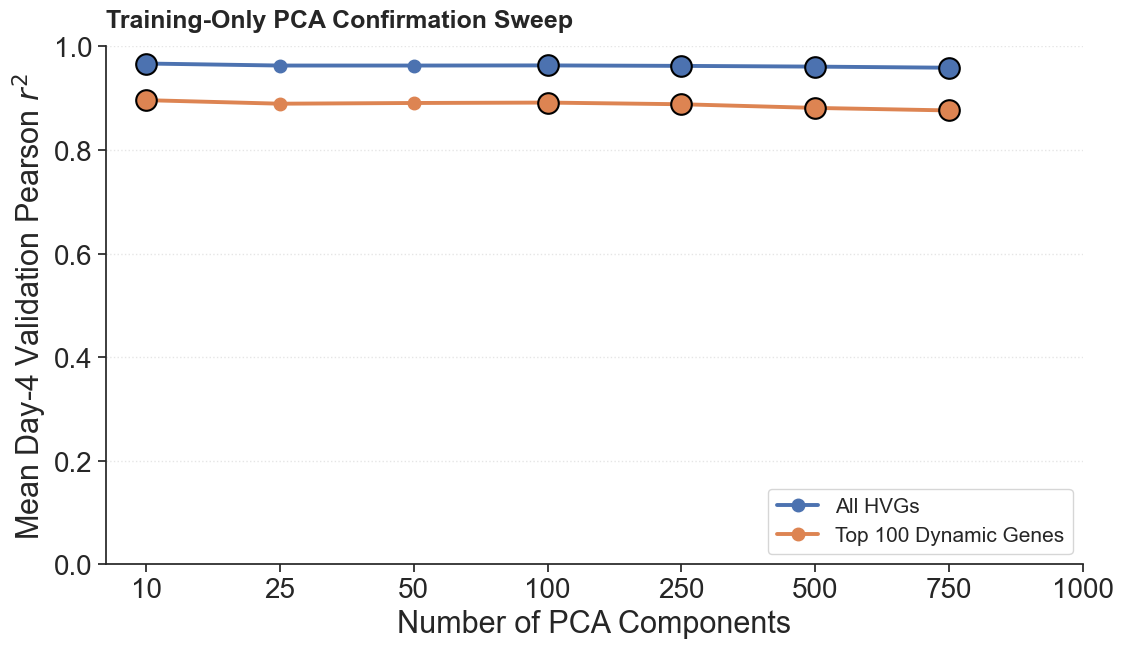

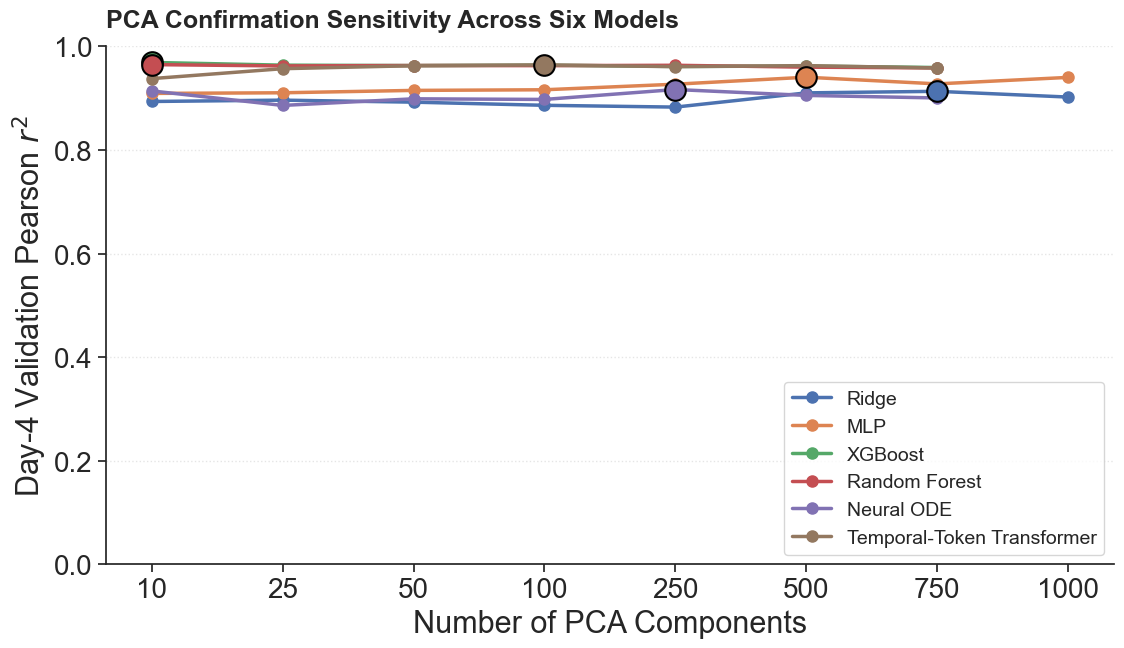

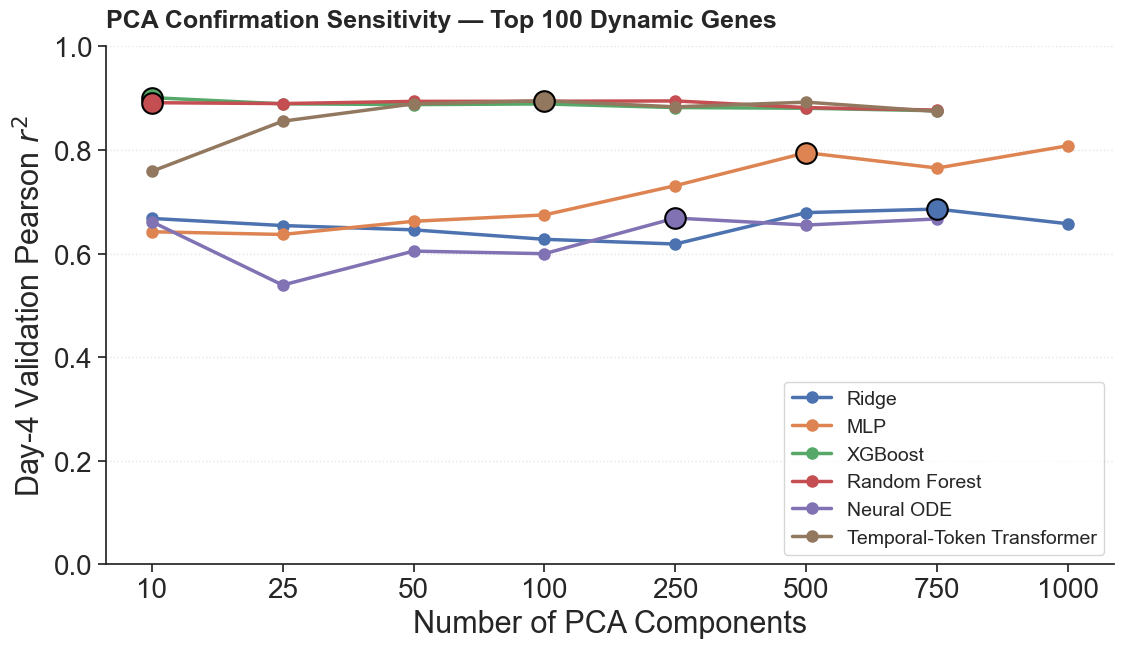

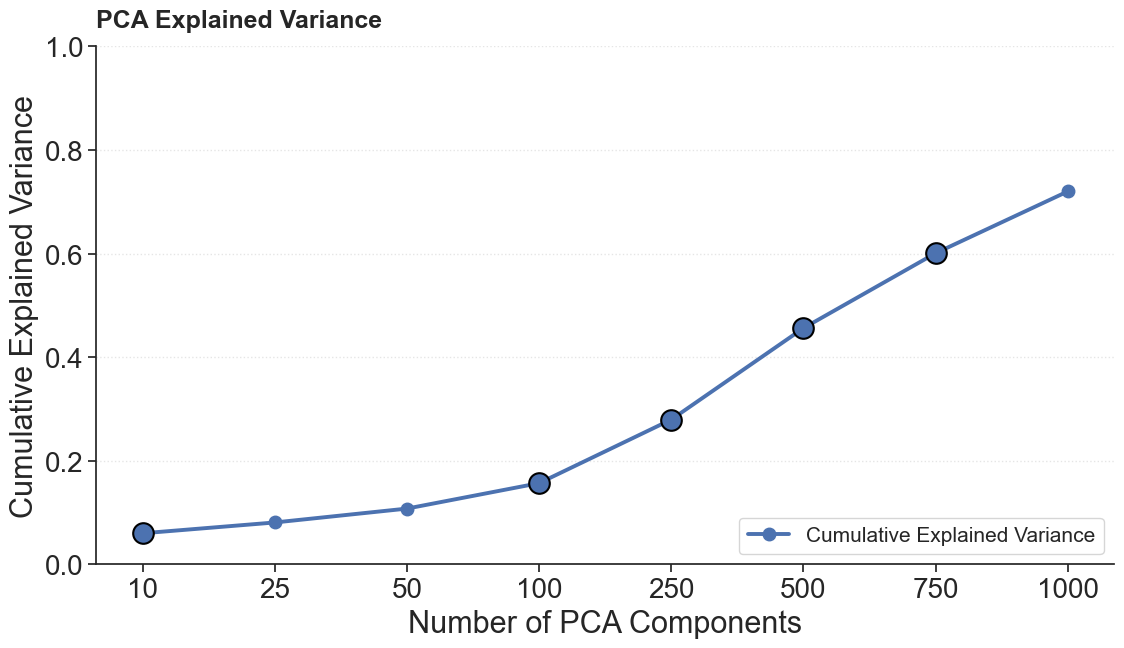

✔ Four figures regenerated from existing results
✔ Vertical dashed selection lines removed
✔ Model-specific selected PCA dimensions highlighted
✔ Larger circular markers with black outlines
✔ No retraining or recalculation
✔ Original figure dimensions and font sizes preserved


: 

In [ ]:
# =========================================================
# PUBLICATION-QUALITY PCA SWEEP FIGURES
# HIGHLIGHT MODEL-SPECIFIC SELECTED PCA DIMENSIONS
# NO VERTICAL DASHED LINES
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

# Original model-specific PCA selections
selected_model_pcs = {
    "Ridge": 750,
    "MLP": 500,
    "XGBoost": 10,
    "Random Forest": 10,
    "Neural ODE": 250,
    "Temporal-Token Transformer": 100
}

# Equally spaced PCA positions
pc_to_x = {pc: i for i, pc in enumerate(pca_dimensions)}
x_positions = np.arange(len(pca_dimensions))

# =========================================================
# HELPER: HIGHLIGHT SELECTED POINT
# =========================================================

def highlight_selected_point(ax, valid, column, selected_pc, color):
    selected_row = valid.loc[
        valid["PCA_Dim"] == selected_pc
    ]

    if selected_row.empty:
        print(
            f"Selected {selected_pc} PCs not available "
            f"for {column}; highlight skipped."
        )
        return

    ax.scatter(
        pc_to_x[selected_pc],
        selected_row[column].iloc[0],
        s=220,
        marker="o",
        color=color,
        edgecolors="black",
        linewidths=1.5,
        zorder=6
    )


# =========================================================
# FIGURE A — TOP-TWO AVERAGED PERFORMANCE
# =========================================================

valid_plot = df_pca_confirmation.dropna(
    subset=["Top2_Mean_All", "Top2_Mean_Top100"]
)

fig, ax = plt.subplots(figsize=(12, 7))

valid_x = [pc_to_x[pc] for pc in valid_plot["PCA_Dim"]]

line_all, = ax.plot(
    valid_x,
    valid_plot["Top2_Mean_All"],
    marker="o",
    markersize=9,
    linewidth=2.8,
    label="All HVGs"
)

line_top, = ax.plot(
    valid_x,
    valid_plot["Top2_Mean_Top100"],
    marker="o",
    markersize=9,
    linewidth=2.8,
    label="Top 100 Dynamic Genes"
)

# Highlight unique selected dimensions on both curves
for selected_pc in sorted(set(selected_model_pcs.values())):
    highlight_selected_point(
        ax, valid_plot, "Top2_Mean_All",
        selected_pc, line_all.get_color()
    )
    highlight_selected_point(
        ax, valid_plot, "Top2_Mean_Top100",
        selected_pc, line_top.get_color()
    )

ax.set_title(
    "Training-Only PCA Confirmation Sweep",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.set_xlabel("Number of PCA Components", fontsize=22)
ax.set_ylabel("Mean Day-4 Validation Pearson $r^2$", fontsize=22)

ax.set_xticks(x_positions)
ax.set_xticklabels(pca_dimensions)
ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(loc="lower right", fontsize=15, frameon=True)

fig.text(
    0.01, 0.99, "",
    fontsize=18, fontweight="bold",
    va="top", ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "publication_top2_pca_confirmation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# FIGURE B — SIX-MODEL ALL-HVG PCA SENSITIVITY
# =========================================================

model_plot_columns = {
    "Ridge": "Ridge_All",
    "MLP": "MLP_All",
    "XGBoost": "XGBoost_All",
    "Random Forest": "RandomForest_All",
    "Neural ODE": "NeuralODE_All",
    "Temporal-Token Transformer": "Transformer_All"
}

fig, ax = plt.subplots(figsize=(12, 7))

for model_name, column in model_plot_columns.items():

    valid = df_pca_confirmation[
        ["PCA_Dim", column]
    ].dropna().sort_values("PCA_Dim")

    valid_x = [pc_to_x[pc] for pc in valid["PCA_Dim"]]

    line, = ax.plot(
        valid_x,
        valid[column],
        marker="o",
        markersize=8,
        linewidth=2.5,
        label=model_name
    )

    highlight_selected_point(
        ax,
        valid,
        column,
        selected_model_pcs[model_name],
        line.get_color()
    )

ax.set_title(
    "PCA Confirmation Sensitivity Across Six Models",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.set_xlabel("Number of PCA Components", fontsize=22)
ax.set_ylabel("Day-4 Validation Pearson $r^2$", fontsize=22)

ax.set_xticks(x_positions)
ax.set_xticklabels(pca_dimensions)
ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(loc="lower right", fontsize=14, frameon=True)

fig.text(
    0.01, 0.99, "",
    fontsize=18, fontweight="bold",
    va="top", ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "supplement_six_model_pca_confirmation_allHVG.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# FIGURE C — SIX-MODEL TOP-100 PCA SENSITIVITY
# =========================================================

model_plot_columns_top = {
    "Ridge": "Ridge_Top100",
    "MLP": "MLP_Top100",
    "XGBoost": "XGBoost_Top100",
    "Random Forest": "RandomForest_Top100",
    "Neural ODE": "NeuralODE_Top100",
    "Temporal-Token Transformer": "Transformer_Top100"
}

fig, ax = plt.subplots(figsize=(12, 7))

for model_name, column in model_plot_columns_top.items():

    valid = df_pca_confirmation[
        ["PCA_Dim", column]
    ].dropna().sort_values("PCA_Dim")

    valid_x = [pc_to_x[pc] for pc in valid["PCA_Dim"]]

    line, = ax.plot(
        valid_x,
        valid[column],
        marker="o",
        markersize=8,
        linewidth=2.5,
        label=model_name
    )

    highlight_selected_point(
        ax,
        valid,
        column,
        selected_model_pcs[model_name],
        line.get_color()
    )

ax.set_title(
    "PCA Confirmation Sensitivity — Top 100 Dynamic Genes",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.set_xlabel("Number of PCA Components", fontsize=22)
ax.set_ylabel("Day-4 Validation Pearson $r^2$", fontsize=22)

ax.set_xticks(x_positions)
ax.set_xticklabels(pca_dimensions)
ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(loc="lower right", fontsize=14, frameon=True)

fig.text(
    0.01, 0.99, "",
    fontsize=18, fontweight="bold",
    va="top", ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "supplement_six_model_pca_confirmation_top100.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# FIGURE D — PCA EXPLAINED VARIANCE
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

variance_data = df_pca_confirmation[
    ["PCA_Dim", "Explained_Variance"]
].dropna().sort_values("PCA_Dim")

variance_x = [
    pc_to_x[pc] for pc in variance_data["PCA_Dim"]
]

line, = ax.plot(
    variance_x,
    variance_data["Explained_Variance"],
    marker="o",
    markersize=9,
    linewidth=2.8,
    label="Cumulative Explained Variance"
)

for selected_pc in sorted(set(selected_model_pcs.values())):
    highlight_selected_point(
        ax,
        variance_data,
        "Explained_Variance",
        selected_pc,
        line.get_color()
    )

ax.set_title(
    "PCA Explained Variance",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=14
)

ax.set_xlabel("Number of PCA Components", fontsize=22)
ax.set_ylabel("Cumulative Explained Variance", fontsize=22)

ax.set_xticks(x_positions)
ax.set_xticklabels(pca_dimensions)
ax.tick_params(axis="both", which="major", labelsize=20)

ax.set_ylim(0.0, 1.0)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(loc="lower right", fontsize=15, frameon=True)

fig.text(
    0.01, 0.99, "",
    fontsize=18, fontweight="bold",
    va="top", ha="left"
)

sns.despine()
plt.tight_layout(rect=[0.05, 0.0, 1.0, 0.95])

plt.savefig(
    "supplement_pca_confirmation_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✔ Four figures regenerated from existing results")
print("✔ Vertical dashed selection lines removed")
print("✔ Model-specific selected PCA dimensions highlighted")
print("✔ Larger circular markers with black outlines")
print("✔ No retraining or recalculation")
print("✔ Original figure dimensions and font sizes preserved")

In [29]:
import pandas as pd
import numpy as np

print("--- Model-Specific Optimal PCA Dimensions ---")

# =========================================================
# 1. MODEL -> SWEEP COLUMN MAPPING
# =========================================================

model_columns = {
    "Ridge Regression": ("Ridge_All", "Ridge_Top100"),
    "Absolute MLP": ("MLP_All", "MLP_Top100"),
    "XGBoost Regressor": ("XGBoost_All", "XGBoost_Top100"),
    "Random Forest": ("RandomForest_All", "RandomForest_Top100"),
    "Neural ODE": ("NeuralODE_All", "NeuralODE_Top100"),
    "Temporal-Token Transformer": ("Transformer_All", "Transformer_Top100")
}


# =========================================================
# 2. EXTRACT BEST PCA DIMENSION FOR EACH MODEL
# Primary selection metric = validation All-HVG Pearson r²
# =========================================================

optimal_pca_results = []

for model_name, (all_col, top100_col) in model_columns.items():

    valid_rows = df_pca_confirmation[
        df_pca_confirmation[all_col].notna()
    ].copy()

    best_idx = valid_rows[all_col].idxmax()
    best_row = valid_rows.loc[best_idx]

    pca_dim = int(best_row["PCA_Dim"])
    all_r2 = float(best_row[all_col])
    top100_r2 = float(best_row[top100_col])

    row_500 = valid_rows[
        valid_rows["PCA_Dim"] == 500
    ]

    if len(row_500) == 1:
        all_r2_500 = float(row_500.iloc[0][all_col])
        improvement_vs_500 = all_r2 - all_r2_500
    else:
        all_r2_500 = np.nan
        improvement_vs_500 = np.nan

    optimal_pca_results.append({
        "Model": model_name,
        "Best_PCA_Dim": pca_dim,
        "Best_All_HVG_r2": all_r2,
        "Top100_r2_at_Best_PCA": top100_r2,
        "All_HVG_r2_at_500": all_r2_500,
        "Improvement_vs_500": improvement_vs_500
    })


# =========================================================
# 3. CLEAN SUMMARY TABLE
# =========================================================

df_model_specific_pca = pd.DataFrame(optimal_pca_results)

print("\n" + "=" * 105)
print("MODEL-SPECIFIC PCA SELECTION")
print("=" * 105)

print(
    df_model_specific_pca.to_string(
        index=False,
        formatters={
            "Best_All_HVG_r2": "{:.4f}".format,
            "Top100_r2_at_Best_PCA": "{:.4f}".format,
            "All_HVG_r2_at_500": "{:.4f}".format,
            "Improvement_vs_500": "{:+.4f}".format
        }
    )
)


# =========================================================
# 4. DICTIONARY FOR FINAL BENCHMARK
# =========================================================

best_pca_by_model = {
    row["Model"]: int(row["Best_PCA_Dim"])
    for _, row in df_model_specific_pca.iterrows()
}

print("\nBest PCA dimensions for final model-specific benchmark:")

for model_name, pca_dim in best_pca_by_model.items():
    print(f"{model_name}: {pca_dim} PCs")


# =========================================================
# 5. EXPECTED VALUES FROM CURRENT SWEEP
# =========================================================

expected_best_pca = {
    "Ridge Regression": 750,
    "Absolute MLP": 500,
    "XGBoost Regressor": 10,
    "Random Forest": 10,
    "Neural ODE": 250,
    "Temporal-Token Transformer": 100
}

assert best_pca_by_model == expected_best_pca

print("\n✔ Model-specific PCA dimensions selected using Day-4 validation")
print("✔ Selection criterion = All-HVG validation Pearson r²")
print("✔ Day 7 was not used to choose PCA dimensionality")
print("✔ Ready for model-specific final benchmark")

--- Model-Specific Optimal PCA Dimensions ---

MODEL-SPECIFIC PCA SELECTION
                     Model  Best_PCA_Dim Best_All_HVG_r2 Top100_r2_at_Best_PCA All_HVG_r2_at_500 Improvement_vs_500
          Ridge Regression           750          0.9133                0.6860            0.9103            +0.0030
              Absolute MLP           500          0.9406                0.7949            0.9406            +0.0000
         XGBoost Regressor            10          0.9691                0.9012            0.9621            +0.0070
             Random Forest            10          0.9649                0.8914            0.9600            +0.0049
                Neural ODE           250          0.9168                0.6686            0.9054            +0.0114
Temporal-Token Transformer           100          0.9643                0.8952            0.9629            +0.0014

Best PCA dimensions for final model-specific benchmark:
Ridge Regression: 750 PCs
Absolute MLP: 500 PCs
XGBoost

TRAINING-ONLY MULTI-MODEL OT HYPERPARAMETER SWEEP
Models: XGBoost + MLP
Fixed PCA: 500 PCs
Validation endpoint: Day 4
Final Day 7 remains completely untouched
Fixed PCA dimensions: 500
Sinkhorn regularization values: [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0]
Target-use caps: [1, 2, 3, 5]

Outer final-training Day-0 cells: 804
Outer final-test Day-0 cells: 201

Inner training Day-0 cells: 643
Inner validation Day-0 cells: 161
Final Day-0 test cells: 201
✓ Outer final-test cells excluded
✓ Inner train/validation split created
✓ Day 7 absent

Biological expression matrix: (11940, 2000)
Standardization fitting matrix: (9763, 2000)
Explained variance at 500 PCs: 0.456
D4 truth: (2177, 2000)
Validation input: (161, 501)
Top-100 genes selected using D2 -> D3 only.

--- reg=1e-05 | cap=1 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\backend.py:1197: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9619 | MLP All=0.9283 | Mean=0.9451
XGBoost Top100=0.8790 | MLP Top100=0.7224 | Mean=0.8007

--- reg=1e-05 | cap=2 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\backend.py:1197: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9601 | MLP All=0.9209 | Mean=0.9405
XGBoost Top100=0.8674 | MLP Top100=0.6982 | Mean=0.7828

--- reg=1e-05 | cap=3 ---


...

Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9621 | MLP All=0.9406 | Mean=0.9513
XGBoost Top100=0.8806 | MLP Top100=0.7949 | Mean=0.8378

--- reg=0.001 | cap=3 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: overflow encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 316
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9621 | MLP All=0.9406 | Mean=0.9513
XGBoost Top100=0.8806 | MLP Top100=0.7949 | Mean=0.8378

--- reg=0.001 | cap=5 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: overflow encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 316
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9621 | MLP All=0.9406 | Mean=0.9513
XGBoost Top100=0.8806 | MLP Top100=0.7949 | Mean=0.8378

--- reg=0.01 | cap=1 ---
Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9596 | MLP All=0.9416 | Mean=0.9506
XGBoost Top100=0.8781 | MLP Top100=0.8063 | Mean=0.8422

--- reg=0.01 | cap=2 ---
Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9506 | MLP All=0.9270 | Mean=0.9388
XGBoost Top100=0.8587 | MLP Top100=0.7583 | Mean=0.8085

--- reg=0.01 | cap=3 ---
Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9456 | MLP All=0.9130 | Mean=0.9293
XGBoost Top100=0.8487 | MLP Top100=0.7290 | Mean=0.7889

--- reg=0.01 | cap=5 ---
Training inputs: (2572, 501)
Training targets: (2572, 500)
XGBoost All=0.9410 | MLP All=0.9021 | Mean=0.9216
XGBoost Top100=0.8418 | MLP Top100=0.7244 | Mean=0.7831

--- reg=0.1 | cap=1 ---
Training inputs: (2572, 501)
Training targets:

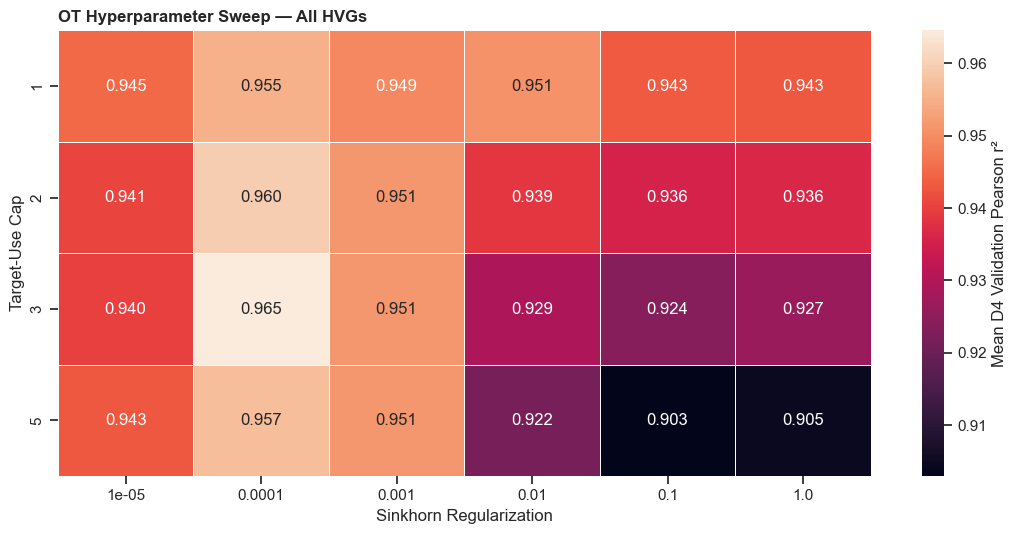

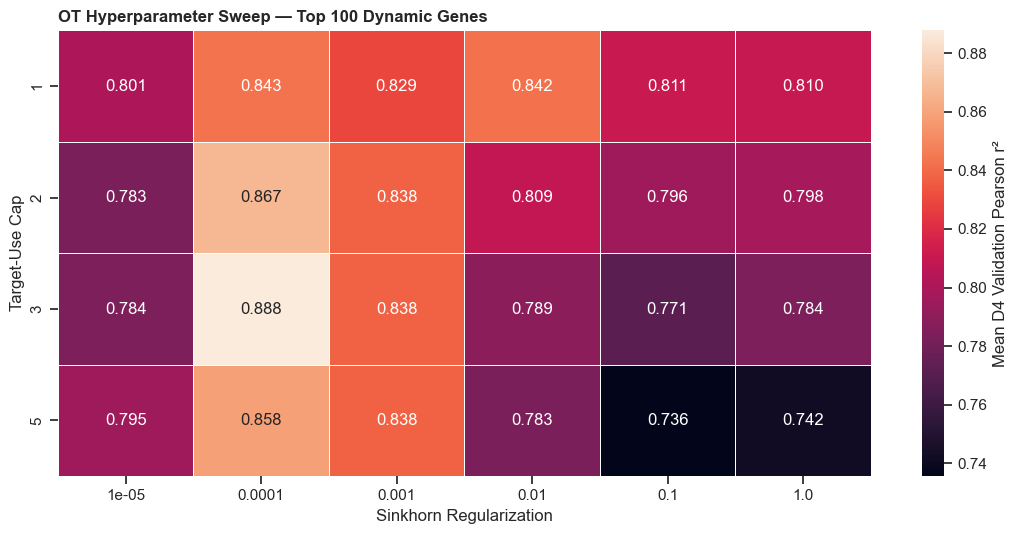

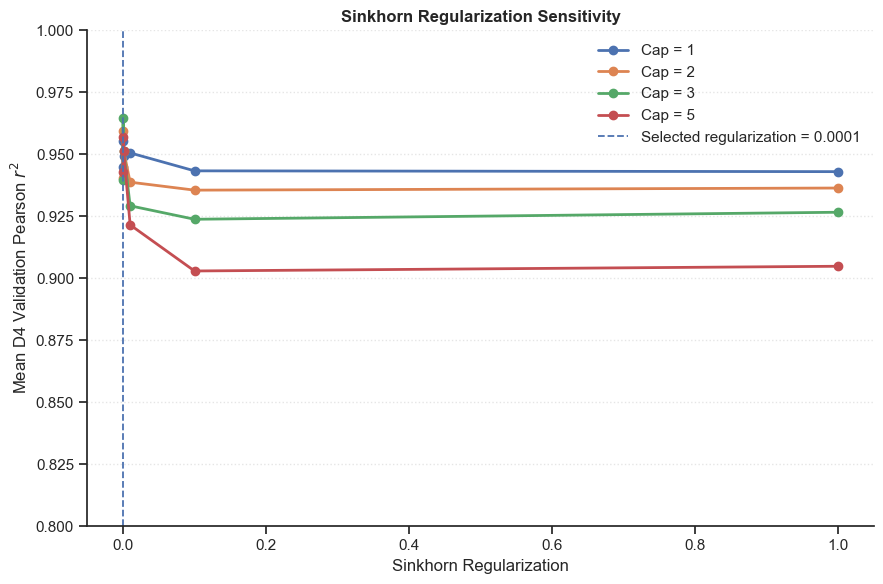


Saved:
multimodel_ot_hyperparameter_sweep_500PC.csv
publication_ot_sweep_allHVG_500PC.png
publication_ot_sweep_top100_500PC.png
publication_ot_sweep_regularization_500PC.png

OT HYPERPARAMETER SWEEP LEAKAGE AUDIT
D4 used for standardization/PCA fitting: False
D7 present in sweep cohort: False
Final Day-0 test cells used for sweep training: False
Final Day-0 test cells used for sweep validation: False

✔ Outer 80/20 Day-0 split recreated inside this block
✔ Inner training/validation split recreated inside this block
✔ PCA locked at selected 500 PCs
✔ XGBoost and MLP used for OT hyperparameter selection
✔ 10 Sinkhorn regularization values tested
✔ 4 target-use caps tested
✔ Up to 40 OT configurations evaluated
✔ Primary selection uses mean All-HVG Pearson r²
✔ Top-100 performance retained as secondary metric
✔ D4 excluded from standardization and PCA fitting
✔ D4 used only as validation truth
✔ Top-100 genes selected using D2 -> D3 only
✔ Final 201 Day-0 test cells untouched
✔ Day 7 com

In [14]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import ot

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from scipy.stats import pearsonr

print("=" * 85)
print("TRAINING-ONLY MULTI-MODEL OT HYPERPARAMETER SWEEP")
print("Models: XGBoost + MLP")
print("Fixed PCA: 500 PCs")
print("Validation endpoint: Day 4")
print("Final Day 7 remains completely untouched")
print("=" * 85)

# =========================================================
# 1. SETTINGS
# =========================================================

pc_dim = 500
reg_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
cap_values = [1, 2, 3, 5]

train_stages = ["Sen 4hrs", "Sen D1", "Sen D2", "Sen D3"]
validation_stage = "Sen D4"

time_mapping = {
    "control": 0.0,
    "Sen 4hrs": 4 / 24,
    "Sen D1": 1.0,
    "Sen D2": 2.0,
    "Sen D3": 3.0,
    "Sen D4": 4.0
}

seed = 42

print("Fixed PCA dimensions:", pc_dim)
print("Sinkhorn regularization values:", reg_values)
print("Target-use caps:", cap_values)

# =========================================================
# 2. DATASET + OUTER DAY-0 SPLIT
# =========================================================

samples = np.asarray(adata_processed.obs["sample"])
control_mask = samples == "control"

assert np.sum(control_mask) == 1005
assert "Sen D7" not in set(samples)

all_source_idx = np.arange(np.sum(control_mask))

train_source_idx, test_source_idx = train_test_split(all_source_idx, test_size=0.20, random_state=42)
train_source_idx = np.sort(train_source_idx)
test_source_idx = np.sort(test_source_idx)

assert len(train_source_idx) == 804
assert len(test_source_idx) == 201
assert len(set(train_source_idx) & set(test_source_idx)) == 0

print("\nOuter final-training Day-0 cells:", len(train_source_idx))
print("Outer final-test Day-0 cells:", len(test_source_idx))

# =========================================================
# 3. INNER TRAIN / VALIDATION SPLIT
# =========================================================

sweep_train_source_idx, sweep_val_source_idx = train_test_split(train_source_idx, test_size=0.20, random_state=123)
sweep_train_source_idx = np.sort(sweep_train_source_idx)
sweep_val_source_idx = np.sort(sweep_val_source_idx)

print("\nInner training Day-0 cells:", len(sweep_train_source_idx))
print("Inner validation Day-0 cells:", len(sweep_val_source_idx))
print("Final Day-0 test cells:", len(test_source_idx))

assert len(sweep_train_source_idx) == 643
assert len(sweep_val_source_idx) == 161
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0
assert len(set(sweep_train_source_idx) & set(sweep_val_source_idx)) == 0
assert len(sweep_train_source_idx) + len(sweep_val_source_idx) == len(train_source_idx)

print("✓ Outer final-test cells excluded")
print("✓ Inner train/validation split created")
print("✓ Day 7 absent")

# =========================================================
# 4. BIOLOGICAL EXPRESSION
# =========================================================

hvg_names = list(adata_processed.var_names)

X_bio_all = adata_processed.raw[:, hvg_names].X
X_bio_all = X_bio_all.toarray() if hasattr(X_bio_all, "toarray") else np.asarray(X_bio_all)
X_bio_all = np.asarray(X_bio_all, dtype=np.float64)

assert X_bio_all.shape[1] == 2000

print("\nBiological expression matrix:", X_bio_all.shape)

# =========================================================
# 5. TRAINING-ONLY STANDARDIZATION
# =========================================================

fit_stages = ["control", "Sen 4hrs", "Sen D1", "Sen D2", "Sen D3"]
fit_mask = np.isin(samples, fit_stages)

X_fit_bio = X_bio_all[fit_mask]

sweep_mean = X_fit_bio.mean(axis=0)
sweep_std = X_fit_bio.std(axis=0)
sweep_std[sweep_std == 0] = 1.0

X_scaled_all = (X_bio_all - sweep_mean) / sweep_std

print("Standardization fitting matrix:", X_fit_bio.shape)

# =========================================================
# 6. FIT LOCKED 500-PC PCA
# =========================================================

pca_ot_sweep = PCA(n_components=pc_dim, random_state=seed)
pca_ot_sweep.fit(X_scaled_all[fit_mask])

X_all_pca = pca_ot_sweep.transform(X_scaled_all)
explained_variance = float(pca_ot_sweep.explained_variance_ratio_.sum())

print("Explained variance at 500 PCs:", round(explained_variance, 4))

# =========================================================
# 7. DAY-0 SOURCE
# =========================================================

L0 = np.asarray(X_all_pca[control_mask], dtype=np.float64)

assert len(L0) == 1005

# =========================================================
# 8. D4 VALIDATION INPUT + TRUTH
# =========================================================

d4_mask = samples == validation_stage

Y_d4_true = X_bio_all[d4_mask]
true_profile = Y_d4_true.mean(axis=0)

d4_dt = time_mapping["Sen D4"] - time_mapping["control"]
X_val = np.hstack([L0[sweep_val_source_idx], np.full((len(sweep_val_source_idx), 1), d4_dt)])

print("D4 truth:", Y_d4_true.shape)
print("Validation input:", X_val.shape)

# =========================================================
# 9. TOP-100 TRAINING-DYNAMIC GENES
# =========================================================

d2_mask = samples == "Sen D2"
d3_mask = samples == "Sen D3"

training_change = np.abs(X_bio_all[d3_mask].mean(axis=0) - X_bio_all[d2_mask].mean(axis=0))
top100_idx = np.argsort(training_change)[-100:]

print("Top-100 genes selected using D2 -> D3 only.")

# =========================================================
# 10. PEARSON r²
# =========================================================

def hp_pearson_r2(x, y):
    r = pearsonr(np.asarray(x), np.asarray(y))[0]
    return float(r ** 2)

# =========================================================
# 11. CAPPED OT PAIRING
# =========================================================

def hp_capped_ot(gamma, cap):
    gamma = np.asarray(gamma, dtype=np.float64)
    n_source, n_target = gamma.shape

    if n_target * cap < n_source:
        raise ValueError("Target capacity too small.")

    assigned = np.full(n_source, -1, dtype=int)
    usage = np.zeros(n_target, dtype=int)
    source_order = np.argsort(gamma.max(axis=1))[::-1]

    for src_idx in source_order:
        target_order = np.argsort(gamma[src_idx])[::-1]

        for tgt_idx in target_order:
            if usage[tgt_idx] < cap:
                assigned[src_idx] = tgt_idx
                usage[tgt_idx] += 1
                break

    if np.any(assigned < 0):
        raise RuntimeError("OT pairing failed.")

    return assigned

# =========================================================
# 12. MLP
# =========================================================

class OTSweepMLP(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, out_dim)
        )

    def forward(self, x):
        return self.net(x)

def train_ot_sweep_mlp(X, Y, seed=42):
    torch.manual_seed(seed)

    model = OTSweepMLP(X.shape[1], Y.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

    X_tensor = torch.tensor(X, dtype=torch.float32)
    Y_tensor = torch.tensor(Y, dtype=torch.float32)

    model.train()

    for epoch in range(120):
        optimizer.zero_grad()
        prediction = model(X_tensor)
        loss = nn.functional.mse_loss(prediction, Y_tensor)
        loss.backward()
        optimizer.step()

    return model

# =========================================================
# 13. STORAGE
# =========================================================

ot_hp_results = []

# =========================================================
# 14. REG × CAP SWEEP
# =========================================================

for reg in reg_values:

    for cap_value in cap_values:

        print(f"\n--- reg={reg} | cap={cap_value} ---")

        X_blocks = []
        Y_blocks = []
        valid_setting = True

        # =================================================
        # BUILD OT TRAINING PAIRS
        # =================================================

        for stage in train_stages:
            target_mask = samples == stage
            Lt = np.asarray(X_all_pca[target_mask], dtype=np.float64)

            if len(Lt) * cap_value < len(L0):
                print(f"Skipping: cap={cap_value} infeasible for {stage}")
                valid_setting = False
                break

            M = ot.dist(L0, Lt, metric="sqeuclidean")
            M /= M.max() if M.max() > 0 else 1

            a = np.ones(len(L0)) / len(L0)
            b = np.ones(len(Lt)) / len(Lt)

            gamma = ot.sinkhorn(a, b, M, reg=reg, numItermax=5000, stopThr=1e-9)
            pair_idx = hp_capped_ot(gamma, cap_value)
            paired_targets = Lt[pair_idx]

            source_train = L0[sweep_train_source_idx]
            target_train = paired_targets[sweep_train_source_idx]

            dt = time_mapping[stage] - time_mapping["control"]
            X_block = np.hstack([source_train, np.full((len(sweep_train_source_idx), 1), dt)])

            X_blocks.append(X_block)
            Y_blocks.append(target_train)

            del M, gamma, Lt, pair_idx, paired_targets
            gc.collect()

        if not valid_setting:
            continue

        X_hp = np.vstack(X_blocks)
        Y_hp = np.vstack(Y_blocks)

        print("Training inputs:", X_hp.shape)
        print("Training targets:", Y_hp.shape)

        # =================================================
        # 15. XGBOOST
        # =================================================

        base_xgb = XGBRegressor(
            n_estimators=30,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=seed,
            n_jobs=1,
            tree_method="hist"
        )

        xgb_model = MultiOutputRegressor(base_xgb, n_jobs=4)
        xgb_model.fit(X_hp, Y_hp)
        pred_xgb_latent = xgb_model.predict(X_val)

        # =================================================
        # 16. MLP
        # =================================================

        mlp_model = train_ot_sweep_mlp(X_hp, Y_hp, seed=seed)
        mlp_model.eval()

        with torch.no_grad():
            pred_mlp_latent = mlp_model(torch.tensor(X_val, dtype=torch.float32)).cpu().numpy()

        # =================================================
        # 17. INVERSE PCA
        # =================================================

        pred_xgb_scaled = pca_ot_sweep.inverse_transform(pred_xgb_latent)
        pred_mlp_scaled = pca_ot_sweep.inverse_transform(pred_mlp_latent)

        pred_xgb_bio = pred_xgb_scaled * sweep_std + sweep_mean
        pred_mlp_bio = pred_mlp_scaled * sweep_std + sweep_mean

        pred_xgb_bio = np.clip(pred_xgb_bio, 0, None)
        pred_mlp_bio = np.clip(pred_mlp_bio, 0, None)

        # =================================================
        # 18. VALIDATION PROFILES
        # =================================================

        xgb_profile = pred_xgb_bio.mean(axis=0)
        mlp_profile = pred_mlp_bio.mean(axis=0)

        # =================================================
        # 19. ALL-HVG SCORES
        # =================================================

        xgb_all = hp_pearson_r2(true_profile, xgb_profile)
        mlp_all = hp_pearson_r2(true_profile, mlp_profile)
        mean_all = np.mean([xgb_all, mlp_all])

        # =================================================
        # 20. TOP-100 SCORES
        # =================================================

        xgb_top = hp_pearson_r2(true_profile[top100_idx], xgb_profile[top100_idx])
        mlp_top = hp_pearson_r2(true_profile[top100_idx], mlp_profile[top100_idx])
        mean_top = np.mean([xgb_top, mlp_top])

        # =================================================
        # 21. SAVE RESULT
        # =================================================

        ot_hp_results.append({
            "Reg": reg,
            "Target_Cap": cap_value,
            "XGBoost_All": xgb_all,
            "MLP_All": mlp_all,
            "Mean_All": mean_all,
            "XGBoost_Top100": xgb_top,
            "MLP_Top100": mlp_top,
            "Mean_Top100": mean_top
        })

        print(f"XGBoost All={xgb_all:.4f} | MLP All={mlp_all:.4f} | Mean={mean_all:.4f}")
        print(f"XGBoost Top100={xgb_top:.4f} | MLP Top100={mlp_top:.4f} | Mean={mean_top:.4f}")

        pd.DataFrame(ot_hp_results).to_csv("multimodel_ot_hyperparameter_sweep_500PC.csv", index=False)

        del X_blocks, Y_blocks, X_hp, Y_hp
        del base_xgb, xgb_model, pred_xgb_latent, pred_xgb_scaled, pred_xgb_bio, xgb_profile
        del mlp_model, pred_mlp_latent, pred_mlp_scaled, pred_mlp_bio, mlp_profile
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# =========================================================
# 22. RESULTS TABLE
# =========================================================

df_ot_hp = pd.DataFrame(ot_hp_results)

print("\n" + "=" * 120)
print("MULTI-MODEL OT HYPERPARAMETER SWEEP RESULTS")
print("=" * 120)

print(df_ot_hp.sort_values("Mean_All", ascending=False).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# =========================================================
# 23. BEST SETTING
# =========================================================

best_hp = df_ot_hp.loc[df_ot_hp["Mean_All"].idxmax()]

best_reg = float(best_hp["Reg"])
best_cap = int(best_hp["Target_Cap"])

print("\n" + "=" * 70)
print("SELECTED OT HYPERPARAMETERS")
print("=" * 70)

print("Best regularization:", best_reg)
print("Best target cap:", best_cap)
print("Mean All-HVG Pearson r²:", round(best_hp["Mean_All"], 4))
print("Mean Top-100 Pearson r²:", round(best_hp["Mean_Top100"], 4))
print("XGBoost All-HVG Pearson r²:", round(best_hp["XGBoost_All"], 4))
print("MLP All-HVG Pearson r²:", round(best_hp["MLP_All"], 4))

# =========================================================
# 24. GRAPH 1 — ALL-HVG HEATMAP
# =========================================================

sns.set_theme(style="ticks")

heat_all = df_ot_hp.pivot(index="Target_Cap", columns="Reg", values="Mean_All")

plt.figure(figsize=(11, 5.5))

sns.heatmap(
    heat_all,
    annot=True,
    fmt=".3f",
    linewidths=0.5,
    cbar_kws={"label": "Mean D4 Validation Pearson r²"}
)

plt.title("OT Hyperparameter Sweep — All HVGs", loc="left", fontweight="bold")
plt.xlabel("Sinkhorn Regularization")
plt.ylabel("Target-Use Cap")
plt.tight_layout()

plt.savefig("publication_ot_sweep_allHVG_500PC.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 25. GRAPH 2 — TOP-100 HEATMAP
# =========================================================

heat_top = df_ot_hp.pivot(index="Target_Cap", columns="Reg", values="Mean_Top100")

plt.figure(figsize=(11, 5.5))

sns.heatmap(
    heat_top,
    annot=True,
    fmt=".3f",
    linewidths=0.5,
    cbar_kws={"label": "Mean D4 Validation Pearson r²"}
)

plt.title("OT Hyperparameter Sweep — Top 100 Dynamic Genes", loc="left", fontweight="bold")
plt.xlabel("Sinkhorn Regularization")
plt.ylabel("Target-Use Cap")
plt.tight_layout()

plt.savefig("publication_ot_sweep_top100_500PC.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 26. GRAPH 3 — REGULARIZATION SENSITIVITY
# =========================================================

fig, ax = plt.subplots(figsize=(9, 6))

for cap_value in cap_values:
    sub = df_ot_hp[df_ot_hp["Target_Cap"] == cap_value].sort_values("Reg")

    if len(sub) == 0:
        continue

    ax.plot(sub["Reg"], sub["Mean_All"], marker="o", linewidth=2, label=f"Cap = {cap_value}")

ax.axvline(best_reg, linestyle="--", linewidth=1.3, label=f"Selected regularization = {best_reg:g}")

ax.set_title("Sinkhorn Regularization Sensitivity", fontweight="bold")
ax.set_xlabel("Sinkhorn Regularization")
ax.set_ylabel("Mean D4 Validation Pearson $r^2$")
ax.set_ylim(0.80, 1.00)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()

plt.savefig("publication_ot_sweep_regularization_500PC.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 27. SAVE FINAL TABLE
# =========================================================

df_ot_hp.to_csv("multimodel_ot_hyperparameter_sweep_500PC.csv", index=False)

print("\nSaved:")
print("multimodel_ot_hyperparameter_sweep_500PC.csv")
print("publication_ot_sweep_allHVG_500PC.png")
print("publication_ot_sweep_top100_500PC.png")
print("publication_ot_sweep_regularization_500PC.png")

# =========================================================
# 28. LEAKAGE AUDIT
# =========================================================

print("\n" + "=" * 80)
print("OT HYPERPARAMETER SWEEP LEAKAGE AUDIT")
print("=" * 80)

print("D4 used for standardization/PCA fitting:", "Sen D4" in set(samples[fit_mask]))
print("D7 present in sweep cohort:", "Sen D7" in set(samples))
print("Final Day-0 test cells used for sweep training:", len(set(test_source_idx) & set(sweep_train_source_idx)) > 0)
print("Final Day-0 test cells used for sweep validation:", len(set(test_source_idx) & set(sweep_val_source_idx)) > 0)

assert "Sen D4" not in set(samples[fit_mask])
assert "Sen D7" not in set(samples)
assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0

print("\n✔ Outer 80/20 Day-0 split recreated inside this block")
print("✔ Inner training/validation split recreated inside this block")
print("✔ PCA locked at selected 500 PCs")
print("✔ XGBoost and MLP used for OT hyperparameter selection")
print("✔ 10 Sinkhorn regularization values tested")
print("✔ 4 target-use caps tested")
print("✔ Up to 40 OT configurations evaluated")
print("✔ Primary selection uses mean All-HVG Pearson r²")
print("✔ Top-100 performance retained as secondary metric")
print("✔ D4 excluded from standardization and PCA fitting")
print("✔ D4 used only as validation truth")
print("✔ Top-100 genes selected using D2 -> D3 only")
print("✔ Final 201 Day-0 test cells untouched")
print("✔ Day 7 completely sealed")

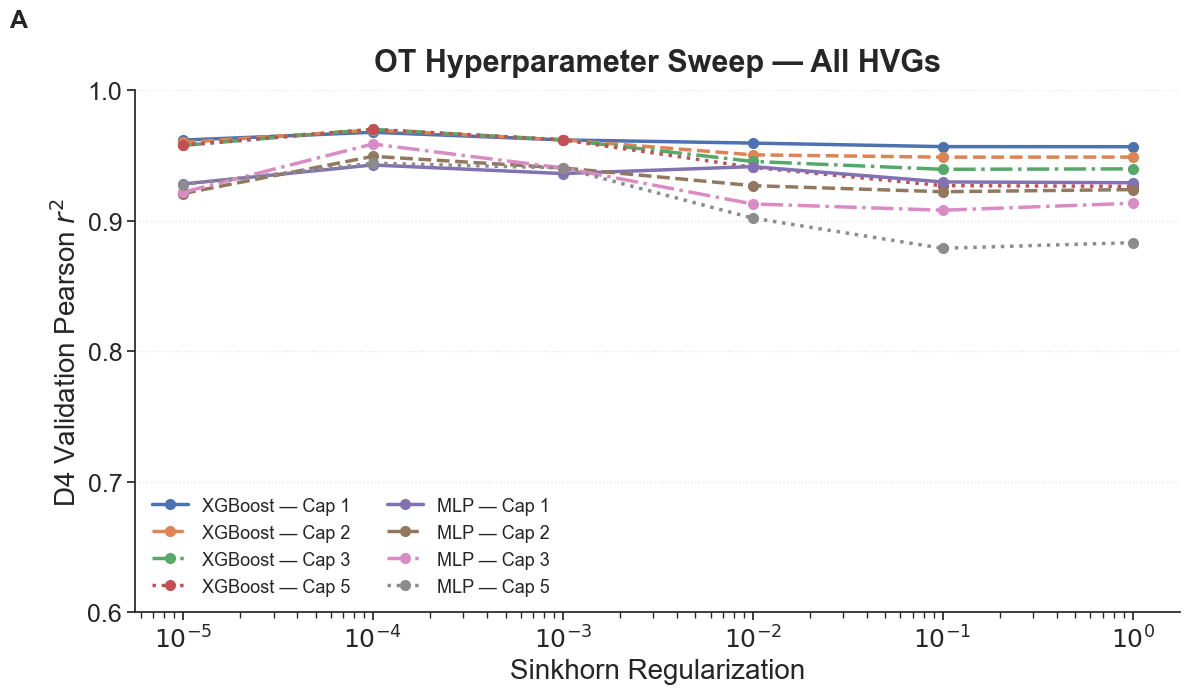

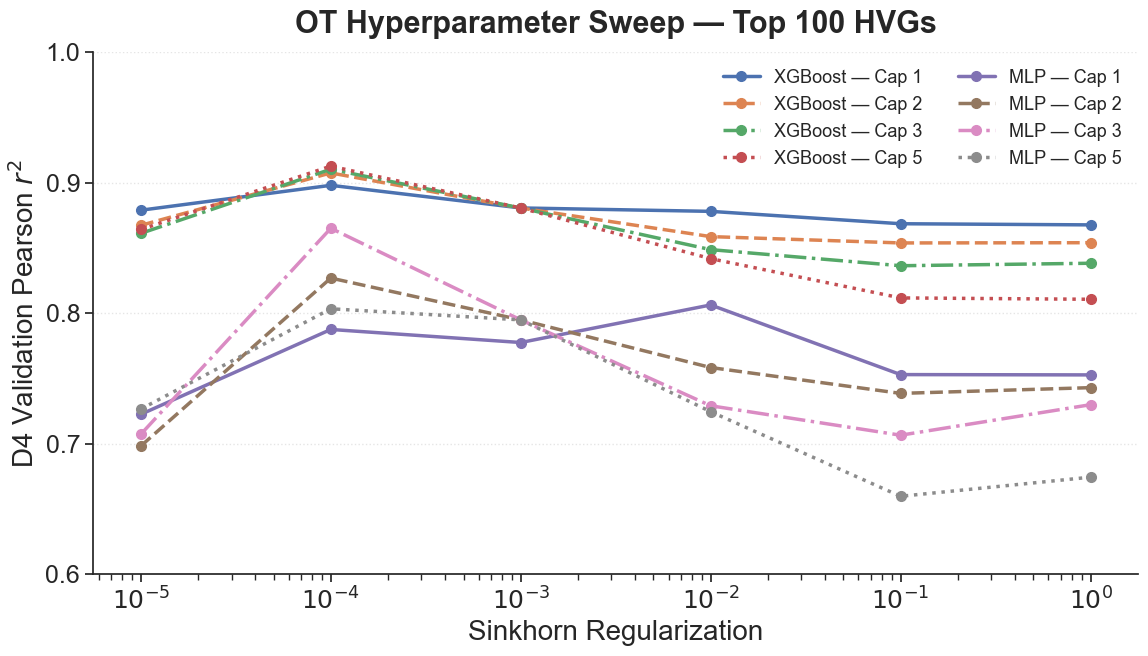

Saved:
publication_ot_sweep_allHVG_500PC.png
publication_ot_sweep_top100_500PC.png

✔ Existing results only
✔ No OT recalculation
✔ No model retraining
✔ No averaging
✔ XGBoost and MLP shown separately
✔ Caps 1, 2, 3, and 5 shown separately
✔ Sinkhorn regularization 10^-5 through 10^0
✔ Figure A = All HVGs
✔ Figure B = Top 100 dynamic genes
✔ Figure labels = 18 pt
✔ Figure titles = 22 pt
✔ Axis titles = 20 pt
✔ Axis numbers = 18 pt
✔ Legends = 13 pt
✔ Figure size = 12 × 7 inches
✔ 300 DPI


In [16]:
# =========================================================
# OT HYPERPARAMETER SWEEP — GRAPHING ONLY
# EXISTING df_ot_hp RESULTS
# NO MODEL AVERAGING
# =========================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

reg_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
cap_values = [1, 2, 3, 5]

linestyles = {1: "-", 2: "--", 3: "-.", 5: ":"}

# =========================================================
# FIGURE A — ALL HVGs
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

for model_name, column in {"XGBoost": "XGBoost_All", "MLP": "MLP_All"}.items():
    for cap_value in cap_values:
        sub = df_ot_hp[df_ot_hp["Target_Cap"] == cap_value].sort_values("Reg")
        ax.plot(sub["Reg"], sub[column], marker="o", linewidth=2.5, markersize=7, linestyle=linestyles[cap_value], label=f"{model_name} — Cap {cap_value}")

ax.set_xscale("log")

ax.set_title("OT Hyperparameter Sweep — All HVGs", fontsize=22, fontweight="bold", pad=14)
ax.set_xlabel("Sinkhorn Regularization", fontsize=20)
ax.set_ylabel("D4 Validation Pearson $r^2$", fontsize=20)

ax.set_xticks(reg_values)
ax.set_xticklabels(
    [r"$10^{-5}$", r"$10^{-4}$", r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^{0}$"],
    fontsize=18
)

ax.tick_params(axis="y", labelsize=18)

ax.set_ylim(0.6, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    frameon=False,
    ncol=2,
    fontsize=13
)

fig.text(0.01, 0.99, "A", fontsize=18, fontweight="bold", va="top", ha="left")

sns.despine()
plt.tight_layout(rect=[0.03, 0.0, 1.0, 0.96])

plt.savefig(
    "publication_ot_sweep_allHVG_500PC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# FIGURE B — TOP 100 DYNAMIC GENES
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

for model_name, column in {"XGBoost": "XGBoost_Top100", "MLP": "MLP_Top100"}.items():
    for cap_value in cap_values:
        sub = df_ot_hp[df_ot_hp["Target_Cap"] == cap_value].sort_values("Reg")
        ax.plot(sub["Reg"], sub[column], marker="o", linewidth=2.5, markersize=7, linestyle=linestyles[cap_value], label=f"{model_name} — Cap {cap_value}")

ax.set_xscale("log")

ax.set_title("OT Hyperparameter Sweep — Top 100 HVGs", fontsize=22, fontweight="bold", pad=14)
ax.set_xlabel("Sinkhorn Regularization", fontsize=20)
ax.set_ylabel("D4 Validation Pearson $r^2$", fontsize=20)

ax.set_xticks(reg_values)
ax.set_xticklabels(
    [r"$10^{-5}$", r"$10^{-4}$", r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^{0}$"],
    fontsize=18
)

ax.tick_params(axis="y", labelsize=18)

ax.set_ylim(0.6, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.legend(
    frameon=False,
    ncol=2,
    fontsize=13
)

fig.text(0.01, 0.99, "", fontsize=18, fontweight="bold", va="top", ha="left")

sns.despine()
plt.tight_layout(rect=[0.03, 0.0, 1.0, 0.96])

plt.savefig(
    "publication_ot_sweep_top100_500PC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# STATUS
# =========================================================

print("Saved:")
print("publication_ot_sweep_allHVG_500PC.png")
print("publication_ot_sweep_top100_500PC.png")

print("\n✔ Existing results only")
print("✔ No OT recalculation")
print("✔ No model retraining")
print("✔ No averaging")
print("✔ XGBoost and MLP shown separately")
print("✔ Caps 1, 2, 3, and 5 shown separately")
print("✔ Sinkhorn regularization 10^-5 through 10^0")
print("✔ Figure A = All HVGs")
print("✔ Figure B = Top 100 dynamic genes")
print("✔ Figure labels = 18 pt")
print("✔ Figure titles = 22 pt")
print("✔ Axis titles = 20 pt")
print("✔ Axis numbers = 18 pt")
print("✔ Legends = 13 pt")
print("✔ Figure size = 12 × 7 inches")
print("✔ 300 DPI")

TRAINING-ONLY MULTI-MODEL OT HYPERPARAMETER SWEEP
Models: XGBoost + MLP
Fixed PCA: 500 PCs
Validation endpoint: Day 4
Final Day 7 remains completely untouched
Fixed PCA dimensions: 500
Sinkhorn regularization values: [0.001, 0.0025, 0.005, 0.0075, 0.01, 0.015, 0.025, 0.05, 0.1, 0.2]
Target-use caps: [1, 2, 3, 5]

Inner training Day-0 cells: 643
Inner validation Day-0 cells: 161
Final Day-0 test cells: 201

Standardization fitting matrix: (9763, 2000)
Explained variance at 500 PCs: 0.456
Top-100 genes selected using D2 -> D3 only.

--- reg=0.001 | cap=1 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: overflow encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 316
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


XGBoost All=0.9620 | MLP All=0.9363 | MEAN=0.9492
XGBoost Top100=0.8807 | MLP Top100=0.7775 | MEAN=0.8291

--- reg=0.001 | cap=2 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: overflow encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 316
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


XGBoost All=0.9621 | MLP All=0.9406 | MEAN=0.9513
XGBoost Top100=0.8806 | MLP Top100=0.7949 | MEAN=0.8378

--- reg=0.001 | cap=3 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: overflow encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 316
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


XGBoost All=0.9621 | MLP All=0.9406 | MEAN=0.9513
XGBoost Top100=0.8806 | MLP Top100=0.7949 | MEAN=0.8378

--- reg=0.001 | cap=5 ---


c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:631: RuntimeWarning: overflow encountered in divide
  u = 1.0 / nx.dot(Kp, v)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 316
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
c:\Users\adars\OneDrive\Documents\RNAseqProject\venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


XGBoost All=0.9621 | MLP All=0.9406 | MEAN=0.9513
XGBoost Top100=0.8806 | MLP Top100=0.7949 | MEAN=0.8378

--- reg=0.0025 | cap=1 ---
XGBoost All=0.9601 | MLP All=0.9270 | MEAN=0.9435
XGBoost Top100=0.8755 | MLP Top100=0.7490 | MEAN=0.8123

--- reg=0.0025 | cap=2 ---
XGBoost All=0.9562 | MLP All=0.9263 | MEAN=0.9413
XGBoost Top100=0.8686 | MLP Top100=0.7566 | MEAN=0.8126

--- reg=0.0025 | cap=3 ---
XGBoost All=0.9563 | MLP All=0.9225 | MEAN=0.9394
XGBoost Top100=0.8700 | MLP Top100=0.7383 | MEAN=0.8042

--- reg=0.0025 | cap=5 ---
XGBoost All=0.9561 | MLP All=0.9189 | MEAN=0.9375
XGBoost Top100=0.8701 | MLP Top100=0.7235 | MEAN=0.7968

--- reg=0.005 | cap=1 ---
XGBoost All=0.9584 | MLP All=0.9335 | MEAN=0.9459
XGBoost Top100=0.8743 | MLP Top100=0.7803 | MEAN=0.8273

--- reg=0.005 | cap=2 ---
XGBoost All=0.9535 | MLP All=0.9253 | MEAN=0.9394
XGBoost Top100=0.8672 | MLP Top100=0.7607 | MEAN=0.8139

--- reg=0.005 | cap=3 ---
XGBoost All=0.9513 | MLP All=0.9170 | MEAN=0.9341
XGBoost Top100=

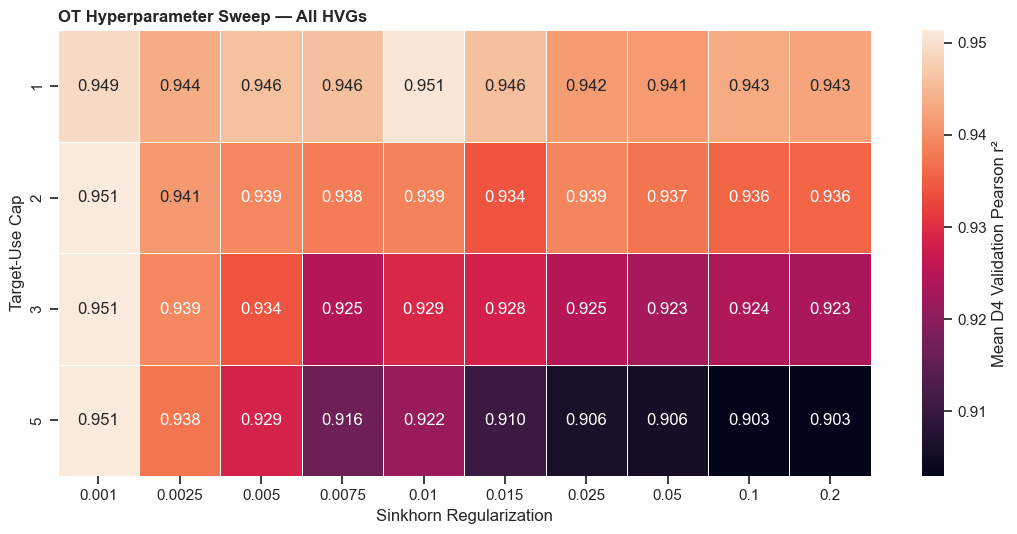

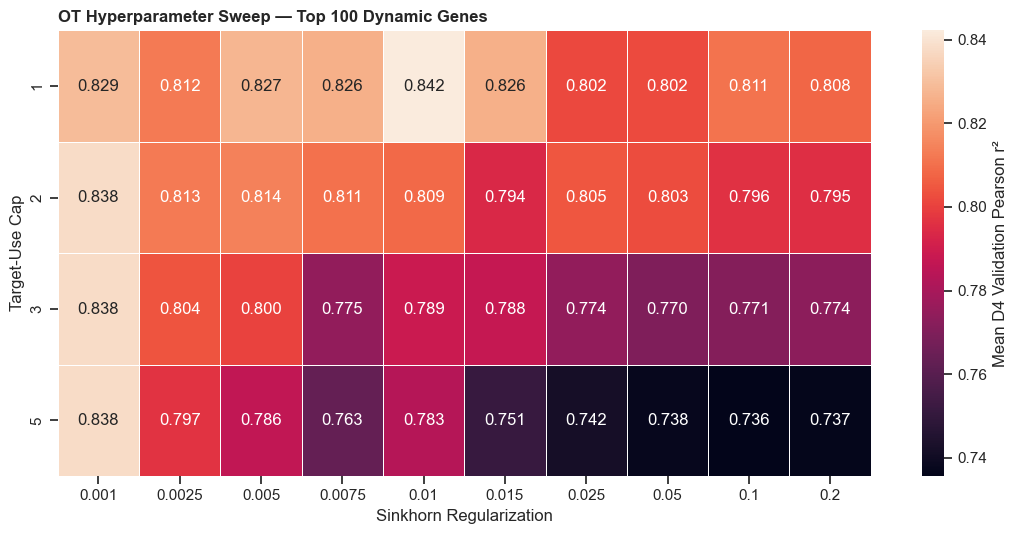

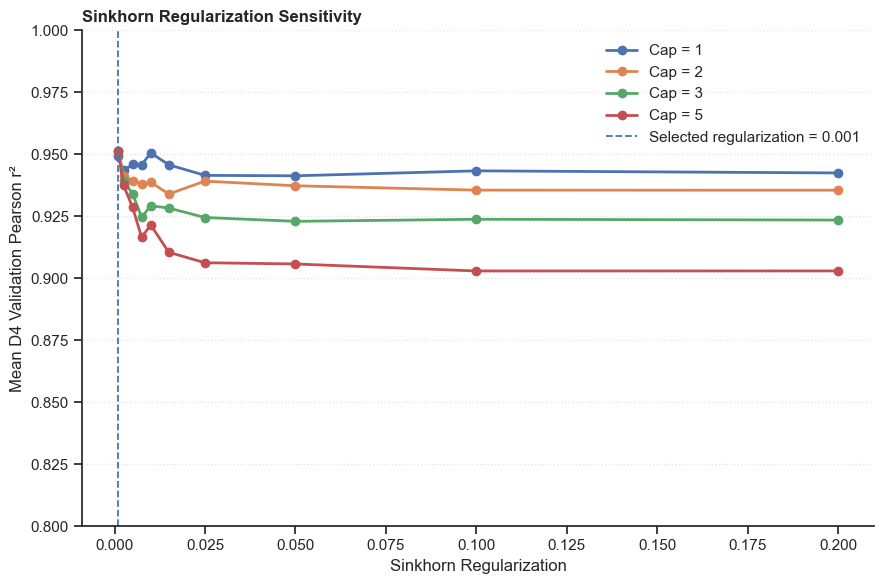

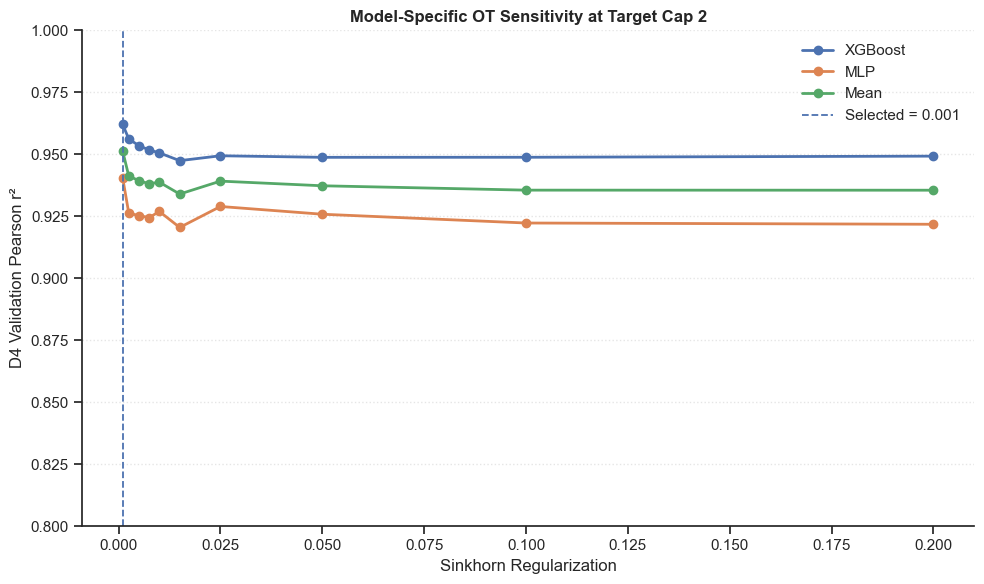


Saved:
multimodel_ot_hyperparameter_sweep.csv
publication_ot_sweep_allHVG.png
publication_ot_sweep_top100.png
publication_ot_sweep_regularization.png
supplement_ot_sweep_individual_models.png

OT HYPERPARAMETER SWEEP LEAKAGE AUDIT
D4 used for standardization/PCA fitting: False
D7 present in sweep cohort: False
Final Day-0 test cells used: False

✔ PCA locked at training-selected 500 PCs
✔ XGBoost and MLP used for OT hyperparameter selection
✔ 10 Sinkhorn regularization values tested
✔ 4 target-use caps tested
✔ 40 OT configurations evaluated
✔ Primary selection uses mean All-HVG Pearson r²
✔ Top-100 performance retained as secondary validation metric
✔ D4 excluded from standardization and PCA fitting
✔ D4 used only as validation truth
✔ Top-100 genes selected without D4
✔ Final 201 Day-0 test cells untouched
✔ Day 7 completely sealed
✔ Publication figures saved


In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# import torch
# import torch.nn as nn
# import ot

# from sklearn.decomposition import PCA
# from sklearn.multioutput import MultiOutputRegressor
# from xgboost import XGBRegressor
# from scipy.stats import pearsonr

# print("=" * 85)
# print("TRAINING-ONLY MULTI-MODEL OT HYPERPARAMETER SWEEP")
# print("Models: XGBoost + MLP")
# print("Fixed PCA: 500 PCs")
# print("Validation endpoint: Day 4")
# print("Final Day 7 remains completely untouched")
# print("=" * 85)

# # =========================================================
# # 1. SETTINGS
# # =========================================================

# pc_dim = 500

# reg_values = [
#     0.001,
#     0.0025,
#     0.005,
#     0.0075,
#     0.01,
#     0.015,
#     0.025,
#     0.05,
#     0.10,
#     0.20
# ]

# cap_values = [1, 2, 3, 5]

# train_stages = ["Sen 4hrs", "Sen D1", "Sen D2", "Sen D3"]
# validation_stage = "Sen D4"

# seed = 42

# print("Fixed PCA dimensions:", pc_dim)
# print("Sinkhorn regularization values:", reg_values)
# print("Target-use caps:", cap_values)

# # =========================================================
# # 2. VERIFY TRAINING-ONLY SPLIT
# # =========================================================

# print("\nInner training Day-0 cells:", len(sweep_train_source_idx))
# print("Inner validation Day-0 cells:", len(sweep_val_source_idx))
# print("Final Day-0 test cells:", len(test_source_idx))

# assert len(set(test_source_idx) & set(sweep_train_source_idx)) == 0
# assert len(set(test_source_idx) & set(sweep_val_source_idx)) == 0
# assert len(set(sweep_train_source_idx) & set(sweep_val_source_idx)) == 0
# assert "Sen D7" not in set(adata_processed.obs["sample"].unique())

# # =========================================================
# # 3. BIOLOGICAL EXPRESSION
# # =========================================================

# hvg_names = list(adata_processed.var_names)

# X_bio_all = adata_processed.raw[:, hvg_names].X
# X_bio_all = X_bio_all.toarray() if hasattr(X_bio_all, "toarray") else np.asarray(X_bio_all)
# X_bio_all = np.asarray(X_bio_all, dtype=np.float64)

# samples = np.asarray(adata_processed.obs["sample"])

# # =========================================================
# # 4. TRAINING-ONLY STANDARDIZATION
# # =========================================================

# fit_stages = ["control", "Sen 4hrs", "Sen D1", "Sen D2", "Sen D3"]
# fit_mask = np.isin(samples, fit_stages)

# X_fit_bio = X_bio_all[fit_mask]

# sweep_mean = X_fit_bio.mean(axis=0)
# sweep_std = X_fit_bio.std(axis=0)
# sweep_std[sweep_std == 0] = 1.0

# X_scaled_all = (X_bio_all - sweep_mean) / sweep_std

# print("\nStandardization fitting matrix:", X_fit_bio.shape)

# # =========================================================
# # 5. FIT LOCKED 500-PC PCA
# # =========================================================

# pca_ot_sweep = PCA(n_components=pc_dim, random_state=seed)
# pca_ot_sweep.fit(X_scaled_all[fit_mask])

# X_all_pca = pca_ot_sweep.transform(X_scaled_all)

# print("Explained variance at 500 PCs:", round(pca_ot_sweep.explained_variance_ratio_.sum(), 4))

# # =========================================================
# # 6. DAY-0 SOURCE
# # =========================================================

# control_mask = samples == "control"
# L0 = np.asarray(X_all_pca[control_mask], dtype=np.float64)

# assert len(L0) == 1005

# # =========================================================
# # 7. D4 VALIDATION INPUT + TRUTH
# # =========================================================

# d4_mask = samples == validation_stage

# Y_d4_true = X_bio_all[d4_mask]
# true_profile = Y_d4_true.mean(axis=0)

# d4_dt = time_mapping["Sen D4"] - time_mapping["control"]

# X_val = np.hstack([
#     L0[sweep_val_source_idx],
#     np.full((len(sweep_val_source_idx), 1), d4_dt)
# ])

# # =========================================================
# # 8. TOP-100 TRAINING-DYNAMIC GENES
# # =========================================================

# d2_mask = samples == "Sen D2"
# d3_mask = samples == "Sen D3"

# training_change = np.abs(X_bio_all[d3_mask].mean(axis=0) - X_bio_all[d2_mask].mean(axis=0))
# top100_idx = np.argsort(training_change)[-100:]

# print("Top-100 genes selected using D2 -> D3 only.")

# # =========================================================
# # 9. PEARSON r²
# # =========================================================

# def hp_pearson_r2(x, y):
#     r = pearsonr(np.asarray(x), np.asarray(y))[0]
#     return float(r ** 2)

# # =========================================================
# # 10. CAPPED OT PAIRING
# # =========================================================

# def hp_capped_ot(gamma, cap):
#     gamma = np.asarray(gamma, dtype=np.float64)

#     n_source, n_target = gamma.shape

#     if n_target * cap < n_source:
#         raise ValueError("Target capacity too small.")

#     assigned = np.full(n_source, -1, dtype=int)
#     usage = np.zeros(n_target, dtype=int)

#     source_order = np.argsort(gamma.max(axis=1))[::-1]

#     for src_idx in source_order:
#         target_order = np.argsort(gamma[src_idx])[::-1]

#         for tgt_idx in target_order:
#             if usage[tgt_idx] < cap:
#                 assigned[src_idx] = tgt_idx
#                 usage[tgt_idx] += 1
#                 break

#     if np.any(assigned < 0):
#         raise RuntimeError("OT pairing failed.")

#     return assigned

# # =========================================================
# # 11. MLP
# # =========================================================

# class OTSweepMLP(nn.Module):
#     def __init__(self, in_dim, out_dim):
#         super().__init__()

#         self.net = nn.Sequential(
#             nn.Linear(in_dim, 128),
#             nn.GELU(),
#             nn.Dropout(0.2),
#             nn.Linear(128, 128),
#             nn.GELU(),
#             nn.Dropout(0.2),
#             nn.Linear(128, out_dim)
#         )

#     def forward(self, x):
#         return self.net(x)

# # =========================================================
# # 12. TRAIN MLP
# # =========================================================

# def train_ot_sweep_mlp(X, Y, seed=42):
#     torch.manual_seed(seed)

#     model = OTSweepMLP(X.shape[1], Y.shape[1])
#     optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

#     X_tensor = torch.tensor(X, dtype=torch.float32)
#     Y_tensor = torch.tensor(Y, dtype=torch.float32)

#     model.train()

#     for epoch in range(120):
#         optimizer.zero_grad()

#         prediction = model(X_tensor)
#         loss = nn.functional.mse_loss(prediction, Y_tensor)

#         loss.backward()
#         optimizer.step()

#     return model

# # =========================================================
# # 13. STORAGE
# # =========================================================

# ot_hp_results = []

# # =========================================================
# # 14. REG × CAP SWEEP
# # =========================================================

# for reg in reg_values:

#     for cap_value in cap_values:

#         print(f"\n--- reg={reg} | cap={cap_value} ---")

#         X_blocks = []
#         Y_blocks = []
#         valid_setting = True

#         # =================================================
#         # BUILD OT TRAINING PAIRS
#         # =================================================

#         for stage in train_stages:

#             target_mask = samples == stage
#             Lt = np.asarray(X_all_pca[target_mask], dtype=np.float64)

#             if len(Lt) * cap_value < len(L0):
#                 print(f"Skipping: cap={cap_value} infeasible for {stage}")
#                 valid_setting = False
#                 break

#             M = ot.dist(L0, Lt, metric="sqeuclidean")

#             if M.max() > 0:
#                 M /= M.max()

#             a = np.ones(len(L0)) / len(L0)
#             b = np.ones(len(Lt)) / len(Lt)

#             gamma = ot.sinkhorn(
#                 a,
#                 b,
#                 M,
#                 reg=reg,
#                 numItermax=5000,
#                 stopThr=1e-9
#             )

#             pair_idx = hp_capped_ot(gamma, cap_value)
#             paired_targets = Lt[pair_idx]

#             source_train = L0[sweep_train_source_idx]
#             target_train = paired_targets[sweep_train_source_idx]

#             dt = time_mapping[stage] - time_mapping["control"]

#             X_block = np.hstack([
#                 source_train,
#                 np.full((len(sweep_train_source_idx), 1), dt)
#             ])

#             X_blocks.append(X_block)
#             Y_blocks.append(target_train)

#         if not valid_setting:
#             continue

#         X_hp = np.vstack(X_blocks)
#         Y_hp = np.vstack(Y_blocks)

#         # =================================================
#         # 15. XGBOOST
#         # =================================================

#         base_xgb = XGBRegressor(
#             n_estimators=30,
#             max_depth=3,
#             learning_rate=0.05,
#             subsample=0.8,
#             colsample_bytree=0.8,
#             random_state=seed,
#             n_jobs=1,
#             tree_method="hist"
#         )

#         xgb_model = MultiOutputRegressor(base_xgb, n_jobs=4)

#         xgb_model.fit(X_hp, Y_hp)
#         pred_xgb_latent = xgb_model.predict(X_val)

#         # =================================================
#         # 16. MLP
#         # =================================================

#         mlp_model = train_ot_sweep_mlp(X_hp, Y_hp, seed=seed)
#         mlp_model.eval()

#         with torch.no_grad():
#             pred_mlp_latent = mlp_model(
#                 torch.tensor(X_val, dtype=torch.float32)
#             ).cpu().numpy()

#         # =================================================
#         # 17. INVERSE PCA
#         # =================================================

#         pred_xgb_scaled = pca_ot_sweep.inverse_transform(pred_xgb_latent)
#         pred_mlp_scaled = pca_ot_sweep.inverse_transform(pred_mlp_latent)

#         pred_xgb_bio = pred_xgb_scaled * sweep_std + sweep_mean
#         pred_mlp_bio = pred_mlp_scaled * sweep_std + sweep_mean

#         pred_xgb_bio = np.clip(pred_xgb_bio, 0, None)
#         pred_mlp_bio = np.clip(pred_mlp_bio, 0, None)

#         # =================================================
#         # 18. VALIDATION PROFILES
#         # =================================================

#         xgb_profile = pred_xgb_bio.mean(axis=0)
#         mlp_profile = pred_mlp_bio.mean(axis=0)

#         # =================================================
#         # 19. ALL-HVG SCORES
#         # =================================================

#         xgb_all = hp_pearson_r2(true_profile, xgb_profile)
#         mlp_all = hp_pearson_r2(true_profile, mlp_profile)

#         mean_all = np.mean([xgb_all, mlp_all])

#         # =================================================
#         # 20. TOP-100 SCORES
#         # =================================================

#         xgb_top = hp_pearson_r2(
#             true_profile[top100_idx],
#             xgb_profile[top100_idx]
#         )

#         mlp_top = hp_pearson_r2(
#             true_profile[top100_idx],
#             mlp_profile[top100_idx]
#         )

#         mean_top = np.mean([xgb_top, mlp_top])

#         # =================================================
#         # 21. SAVE RESULT
#         # =================================================

#         ot_hp_results.append({
#             "Reg": reg,
#             "Target_Cap": cap_value,
#             "XGBoost_All": xgb_all,
#             "MLP_All": mlp_all,
#             "Mean_All": mean_all,
#             "XGBoost_Top100": xgb_top,
#             "MLP_Top100": mlp_top,
#             "Mean_Top100": mean_top
#         })

#         print(
#             f"XGBoost All={xgb_all:.4f} | "
#             f"MLP All={mlp_all:.4f} | "
#             f"MEAN={mean_all:.4f}"
#         )

#         print(
#             f"XGBoost Top100={xgb_top:.4f} | "
#             f"MLP Top100={mlp_top:.4f} | "
#             f"MEAN={mean_top:.4f}"
#         )

#         pd.DataFrame(ot_hp_results).to_csv(
#             "multimodel_ot_hyperparameter_sweep.csv",
#             index=False
#         )

# # =========================================================
# # 22. RESULTS TABLE
# # =========================================================

# df_ot_hp = pd.DataFrame(ot_hp_results)

# print("\n" + "=" * 120)
# print("MULTI-MODEL OT HYPERPARAMETER SWEEP RESULTS")
# print("=" * 120)

# print(
#     df_ot_hp.sort_values(
#         "Mean_All",
#         ascending=False
#     ).to_string(
#         index=False,
#         float_format=lambda x: f"{x:.4f}"
#     )
# )

# # =========================================================
# # 23. BEST SETTING
# # =========================================================

# best_hp = df_ot_hp.loc[df_ot_hp["Mean_All"].idxmax()]

# best_reg = float(best_hp["Reg"])
# best_cap = int(best_hp["Target_Cap"])

# print("\n" + "=" * 70)
# print("SELECTED OT HYPERPARAMETERS")
# print("=" * 70)

# print("Best regularization:", best_reg)
# print("Best target cap:", best_cap)
# print("Mean All-HVG Pearson r²:", round(best_hp["Mean_All"], 4))
# print("Mean Top-100 Pearson r²:", round(best_hp["Mean_Top100"], 4))
# print("XGBoost All-HVG Pearson r²:", round(best_hp["XGBoost_All"], 4))
# print("MLP All-HVG Pearson r²:", round(best_hp["MLP_All"], 4))

# # =========================================================
# # 24. PUBLICATION FIGURE A
# # MEAN ALL-HVG PERFORMANCE
# # =========================================================

# sns.set_theme(style="ticks")

# heat_all = df_ot_hp.pivot(
#     index="Target_Cap",
#     columns="Reg",
#     values="Mean_All"
# )

# plt.figure(figsize=(11, 5.5))

# sns.heatmap(
#     heat_all,
#     annot=True,
#     fmt=".3f",
#     linewidths=0.5,
#     cbar_kws={"label": "Mean D4 Validation Pearson r²"}
# )

# plt.title(
#     "OT Hyperparameter Sweep — All HVGs",
#     loc="left",
#     fontweight="bold"
# )

# plt.xlabel("Sinkhorn Regularization")
# plt.ylabel("Target-Use Cap")

# plt.tight_layout()

# plt.savefig(
#     "publication_ot_sweep_allHVG.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

# # =========================================================
# # 25. PUBLICATION FIGURE B
# # MEAN TOP-100 PERFORMANCE
# # =========================================================

# heat_top = df_ot_hp.pivot(
#     index="Target_Cap",
#     columns="Reg",
#     values="Mean_Top100"
# )

# plt.figure(figsize=(11, 5.5))

# sns.heatmap(
#     heat_top,
#     annot=True,
#     fmt=".3f",
#     linewidths=0.5,
#     cbar_kws={"label": "Mean D4 Validation Pearson r²"}
# )

# plt.title(
#     "OT Hyperparameter Sweep — Top 100 Dynamic Genes",
#     loc="left",
#     fontweight="bold"
# )

# plt.xlabel("Sinkhorn Regularization")
# plt.ylabel("Target-Use Cap")

# plt.tight_layout()

# plt.savefig(
#     "publication_ot_sweep_top100.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

# # =========================================================
# # 26. PUBLICATION FIGURE C
# # REGULARIZATION SENSITIVITY
# # =========================================================

# plt.figure(figsize=(9, 6))

# for cap_value in cap_values:

#     sub = df_ot_hp[
#         df_ot_hp["Target_Cap"] == cap_value
#     ].sort_values("Reg")

#     if len(sub) == 0:
#         continue

#     plt.plot(
#         sub["Reg"],
#         sub["Mean_All"],
#         marker="o",
#         linewidth=2,
#         label=f"Cap = {cap_value}"
#     )

# plt.axvline(
#     best_reg,
#     linestyle="--",
#     linewidth=1.3,
#     label=f"Selected regularization = {best_reg:g}"
# )

# plt.title(
#     "Sinkhorn Regularization Sensitivity",
#     loc="left",
#     fontweight="bold"
# )

# plt.xlabel("Sinkhorn Regularization")
# plt.ylabel("Mean D4 Validation Pearson r²")

# plt.ylim(0.80, 1.00)
# plt.grid(axis="y", linestyle=":", alpha=0.5)
# plt.legend(frameon=False)

# sns.despine()
# plt.tight_layout()

# plt.savefig(
#     "publication_ot_sweep_regularization.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

# # =========================================================
# # 27. SUPPLEMENTARY MODEL-SPECIFIC FIGURE
# # =========================================================

# best_cap_subset = df_ot_hp[
#     df_ot_hp["Target_Cap"] == best_cap
# ].sort_values("Reg")

# fig, ax = plt.subplots(figsize=(10, 6))

# ax.plot(
#     best_cap_subset["Reg"],
#     best_cap_subset["XGBoost_All"],
#     marker="o",
#     linewidth=2,
#     label="XGBoost"
# )

# ax.plot(
#     best_cap_subset["Reg"],
#     best_cap_subset["MLP_All"],
#     marker="o",
#     linewidth=2,
#     label="MLP"
# )

# ax.plot(
#     best_cap_subset["Reg"],
#     best_cap_subset["Mean_All"],
#     marker="o",
#     linewidth=2,
#     label="Mean"
# )

# ax.axvline(
#     best_reg,
#     linestyle="--",
#     linewidth=1.3,
#     label=f"Selected = {best_reg:g}"
# )

# ax.set_title(
#     f"Model-Specific OT Sensitivity at Target Cap {best_cap}",
#     fontweight="bold"
# )

# ax.set_xlabel("Sinkhorn Regularization")
# ax.set_ylabel("D4 Validation Pearson r²")
# ax.set_ylim(0.80, 1.00)

# ax.grid(axis="y", linestyle=":", alpha=0.5)
# ax.legend(frameon=False)

# sns.despine()
# plt.tight_layout()

# plt.savefig(
#     "supplement_ot_sweep_individual_models.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

# # =========================================================
# # 28. SAVE FINAL TABLE
# # =========================================================

# df_ot_hp.to_csv(
#     "multimodel_ot_hyperparameter_sweep.csv",
#     index=False
# )

# print("\nSaved:")
# print("multimodel_ot_hyperparameter_sweep.csv")
# print("publication_ot_sweep_allHVG.png")
# print("publication_ot_sweep_top100.png")
# print("publication_ot_sweep_regularization.png")
# print("supplement_ot_sweep_individual_models.png")

# # =========================================================
# # 29. LEAKAGE AUDIT
# # =========================================================

# print("\n" + "=" * 80)
# print("OT HYPERPARAMETER SWEEP LEAKAGE AUDIT")
# print("=" * 80)

# print(
#     "D4 used for standardization/PCA fitting:",
#     "Sen D4" in set(samples[fit_mask])
# )

# print(
#     "D7 present in sweep cohort:",
#     "Sen D7" in set(samples)
# )

# print(
#     "Final Day-0 test cells used:",
#     len(
#         set(test_source_idx).intersection(
#             set(sweep_train_source_idx) | set(sweep_val_source_idx)
#         )
#     ) > 0
# )

# assert "Sen D4" not in set(samples[fit_mask])
# assert "Sen D7" not in set(samples)

# assert len(
#     set(test_source_idx).intersection(
#         set(sweep_train_source_idx) | set(sweep_val_source_idx)
#     )
# ) == 0

# print("\n✔ PCA locked at training-selected 500 PCs")
# print("✔ XGBoost and MLP used for OT hyperparameter selection")
# print("✔ 10 Sinkhorn regularization values tested")
# print("✔ 4 target-use caps tested")
# print("✔ 40 OT configurations evaluated")
# print("✔ Primary selection uses mean All-HVG Pearson r²")
# print("✔ Top-100 performance retained as secondary validation metric")
# print("✔ D4 excluded from standardization and PCA fitting")
# print("✔ D4 used only as validation truth")
# print("✔ Top-100 genes selected without D4")
# print("✔ Final 201 Day-0 test cells untouched")
# print("✔ Day 7 completely sealed")
# print("✔ Publication figures saved")

In [ ]:
# optimal_pc_count = 500
# sinkhorn_reg = 0.001
# target_cap = 3